In [ ]:

# ============================================
# CELL 1: KIỂM TRA MÔI TRƯỜNG VÀ GPU
# ============================================

import sys
import os

print("Python version:", sys.version)
print("Working directory:", os.getcwd())

# Kiểm tra GPU
try:
    import torch

    print("\nPyTorch version:", torch.__version__)
    print("CUDA available:", torch.cuda.is_available())

    if torch.cuda.is_available():
        print("GPU name:", torch.cuda.get_device_name(0))
        print("CUDA version:", torch.version.cuda)

        gpu_memory = torch.cuda.get_device_properties(0).total_memory
        print("GPU memory:", round(gpu_memory / (1024**3), 2), "GB")
    else:
        print("\nWARNING: GPU is not available.")
        print("Please enable GPU in Runtime settings.")

except ImportError:
    print("PyTorch is not installed in this environment.")


Python version: 3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]
Working directory: /content

PyTorch version: 2.11.0+cu130
CUDA available: True
GPU name: Tesla T4
CUDA version: 13.0
GPU memory: 14.56 GB


In [ ]:

# ============================================
# CELL 2: KẾT NỐI GOOGLE DRIVE
# ============================================

from google.colab import drive

drive.mount('/content/drive')

print("Google Drive connected successfully!")


Mounted at /content/drive
Google Drive connected successfully!


In [ ]:

# ============================================
# CELL 3: KHAI BÁO CẤU TRÚC DỰ ÁN
# ============================================

from pathlib import Path

# Thư mục dự án trên Google Drive
PROJECT_DIR = Path(
    "/content/drive/MyDrive/YOLO11_seg_expanded"
)

# Nơi lưu các file ZIP gốc
RAW_DIR = PROJECT_DIR / "raw_zips"

# Nơi lưu dataset sau khi chuẩn hóa
DATASET_DIR = PROJECT_DIR / "dataset"

# Nơi lưu kết quả huấn luyện
RESULTS_DIR = PROJECT_DIR / "results"

# Tạo các thư mục cần thiết
PROJECT_DIR.mkdir(parents=True, exist_ok=True)
RAW_DIR.mkdir(parents=True, exist_ok=True)
DATASET_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

print("Project directory:", PROJECT_DIR)
print("Raw ZIP directory:", RAW_DIR)
print("Dataset directory:", DATASET_DIR)
print("Results directory:", RESULTS_DIR)


Project directory: /content/drive/MyDrive/YOLO11_seg_expanded
Raw ZIP directory: /content/drive/MyDrive/YOLO11_seg_expanded/raw_zips
Dataset directory: /content/drive/MyDrive/YOLO11_seg_expanded/dataset
Results directory: /content/drive/MyDrive/YOLO11_seg_expanded/results


In [ ]:

# ============================================
# CELL 4: KIỂM TRA CÁC FILE ZIP
# ============================================

from pathlib import Path

# Các file ZIP hiện đang nằm trực tiếp trong /content
RAW_DIR = Path("/content")

ZIP_NAMES = [
    "job54.zip",
    "job62.zip",
    "job67.zip",
    "job68.zip"
]

missing_files = []

print("KIỂM TRA DATASET ZIP")
print("=" * 60)

for zip_name in ZIP_NAMES:

    zip_path = RAW_DIR / zip_name

    if zip_path.exists() and zip_path.is_file():

        size_mb = zip_path.stat().st_size / (1024**2)

        print(f"[OK] {zip_name}")
        print(f"     Size: {size_mb:.2f} MB")

    else:
        print(f"[MISSING] {zip_name}")
        missing_files.append(zip_name)

print("=" * 60)

if len(missing_files) == 0:
    print("All ZIP files are available.")
else:
    print("Missing files:", missing_files)
    print("Please check the uploaded files in /content.")


KIỂM TRA DATASET ZIP
[OK] job54.zip
     Size: 110.10 MB
[OK] job62.zip
     Size: 114.56 MB
[OK] job67.zip
     Size: 109.75 MB
[OK] job68.zip
     Size: 91.41 MB
All ZIP files are available.


In [ ]:

# ============================================
# CELL 5: KIỂM TRA CẤU TRÚC CÁC ZIP
# ============================================

import zipfile
from pathlib import Path
from collections import Counter

IMAGE_EXTENSIONS = {
    ".jpg", ".jpeg", ".png", ".bmp", ".webp"
}

for zip_name in ZIP_NAMES:

    zip_path = RAW_DIR / zip_name

    if not zip_path.exists():
        print(f"\nSKIP: {zip_name} does not exist.")
        continue

    print("\n" + "=" * 75)
    print("ARCHIVE:", zip_name)
    print("=" * 75)

    with zipfile.ZipFile(zip_path, "r") as z:

        files = [
            name for name in z.namelist()
            if not name.endswith("/")
        ]

        image_files = [
            name for name in files
            if Path(name).suffix.lower() in IMAGE_EXTENSIONS
        ]

        label_files = [
            name for name in files
            if Path(name).suffix.lower() == ".txt"
            and "label" in name.lower().replace("\\", "/").split("/")
        ]

        yaml_files = [
            name for name in files
            if Path(name).suffix.lower() in {".yaml", ".yml"}
        ]

        other_txt_files = [
            name for name in files
            if Path(name).suffix.lower() == ".txt"
            and name not in label_files
        ]

        print("Total files:", len(files))
        print("Images:", len(image_files))
        print("TXT files in label folders:", len(label_files))
        print("YAML files:", len(yaml_files))
        print("Other TXT files:", len(other_txt_files))

        print("\n--- YAML CONTENT ---")

        if yaml_files:

            for yaml_name in yaml_files:

                print("\nFile:", yaml_name)

                content = z.read(yaml_name).decode(
                    "utf-8-sig",
                    errors="replace"
                )

                print(content[:4000])

        else:
            print("No YAML file found.")

        print("\n--- SPLIT FILES ---")

        split_files = [
            name for name in other_txt_files
            if Path(name).name.lower() in {
                "train.txt", "val.txt", "test.txt"
            }
        ]

        if split_files:

            for split_name in split_files:
                print("\nFile:", split_name)

                content = z.read(split_name).decode(
                    "utf-8-sig",
                    errors="replace"
                )

                print(content[:1200])

        else:
            print("No standard train/val/test TXT file found.")

        print("\n--- SAMPLE LABEL FILES ---")

        for label_name in label_files[:2]:

            print("\nFile:", label_name)

            content = z.read(label_name).decode(
                "utf-8-sig",
                errors="replace"
            )

            print(content[:1000])

        print("\n--- SAMPLE IMAGE PATHS ---")

        for image_name in image_files[:5]:
            print(image_name)



ARCHIVE: job54.zip
Total files: 596
Images: 297
TXT files in label folders: 0
YAML files: 1
Other TXT files: 298

--- YAML CONTENT ---

File: data.yaml
names:
  0: hat
  1: gloves
  2: mask
  3: pants
  4: shoes
  5: long-sleeved shirt
path: .
train: train.txt


--- SPLIT FILES ---

File: train.txt
data/images/train/batch_004/BaoAnh__screen_on_off_20260908_113356__008810.jpg
data/images/train/batch_004/BaoAnh__screen_on_off_20260908_113356__008820.jpg
data/images/train/batch_004/BaoAnh__screen_on_off_20260908_113356__008830.jpg
data/images/train/batch_004/BaoAnh__screen_on_off_20260908_113356__008840.jpg
data/images/train/batch_004/BaoAnh__screen_on_off_20260908_113356__008850.jpg
data/images/train/batch_004/BaoAnh__screen_on_off_20260908_113356__008860.jpg
data/images/train/batch_004/BaoAnh__screen_on_off_20260908_113356__008870.jpg
data/images/train/batch_004/BaoAnh__screen_on_off_20260908_113356__008880.jpg
data/images/train/batch_004/BaoAnh__screen_on_off_20260908_113356__008890.j

In [ ]:

# ============================================================
# CELL 6: KIỂM TRA CHÍNH XÁC ẢNH VÀ ANNOTATION
# ============================================================

import zipfile
from pathlib import PurePosixPath
from collections import Counter

IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

for zip_name in ZIP_NAMES:

    zip_path = RAW_DIR / zip_name

    if not zip_path.exists():
        print(f"\nSKIP: {zip_name}")
        continue

    print("\n" + "=" * 80)
    print(f"DATASET: {zip_name}")
    print("=" * 80)

    with zipfile.ZipFile(zip_path, "r") as z:

        # Chuẩn hóa danh sách đường dẫn trong ZIP
        members = [
            name.replace("\\", "/").lstrip("./")
            for name in z.namelist()
            if not name.endswith("/")
        ]

        member_set = set(members)

        # ----------------------------------------------------
        # 1. TÌM ẢNH
        # ----------------------------------------------------

        image_files = [
            p for p in members
            if PurePosixPath(p).suffix.lower() in IMAGE_EXTENSIONS
        ]

        # ----------------------------------------------------
        # 2. TÌM FILE TXT ANNOTATION
        # Loại trừ train.txt, val.txt, test.txt
        # ----------------------------------------------------

        split_names = {"train.txt", "val.txt", "test.txt"}

        label_files = [
            p for p in members
            if PurePosixPath(p).suffix.lower() == ".txt"
            and PurePosixPath(p).name.lower() not in split_names
        ]

        print("\n[1] FILE COUNTS")
        print("Images:", len(image_files))
        print("Candidate annotation TXT:", len(label_files))

        # ----------------------------------------------------
        # 3. KIỂM TRA CÁC THƯ MỤC CHỨA ANNOTATION
        # ----------------------------------------------------

        print("\n[2] ANNOTATION DIRECTORIES")

        label_dirs = Counter(
            str(PurePosixPath(p).parent)
            for p in label_files
        )

        for folder, count in label_dirs.most_common(10):
            print(f"{folder}: {count} files")

        # ----------------------------------------------------
        # 4. IN RA 5 FILE ANNOTATION MẪU
        # ----------------------------------------------------

        print("\n[3] SAMPLE ANNOTATION FILES")

        for label_path in label_files[:5]:
            print(label_path)

        # ----------------------------------------------------
        # 5. ĐỌC NỘI DUNG LABEL MẪU
        # ----------------------------------------------------

        if label_files:

            print("\n[4] SAMPLE ANNOTATION CONTENT")

            sample_label = label_files[0]

            content = z.read(sample_label).decode(
                "utf-8-sig",
                errors="replace"
            )

            print("File:", sample_label)
            print(content[:1000])

        # ----------------------------------------------------
        # 6. KIỂM TRA GHÉP CẶP ẢNH - LABEL
        # ----------------------------------------------------

        print("\n[5] IMAGE-LABEL PAIRING")

        label_set = set(label_files)

        matched = 0
        missing = []

        for image_path in image_files:

            parts = list(PurePosixPath(image_path).parts)

            if "images" not in parts:
                missing.append(image_path)
                continue

            # Thay thư mục images thành labels
            image_index = parts.index("images")
            parts[image_index] = "labels"

            expected_label = str(
                PurePosixPath(*parts).with_suffix(".txt")
            )

            if expected_label in label_set:
                matched += 1
            else:
                missing.append(image_path)

        print("Matched image-label pairs:", matched)
        print("Images without matching label:", len(missing))

        if missing:
            print("\nFirst missing examples:")
            for p in missing[:5]:
                print(p)

        # ----------------------------------------------------
        # 7. KIỂM TRA ĐƯỜNG DẪN TRAIN.TXT
        # ----------------------------------------------------

        print("\n[6] TRAIN.TXT PATH VALIDATION")

        train_files = [
            p for p in members
            if PurePosixPath(p).name.lower() == "train.txt"
        ]

        if train_files:

            train_path = train_files[0]

            train_content = z.read(train_path).decode(
                "utf-8-sig",
                errors="replace"
            )

            train_entries = [
                line.strip().replace("\\", "/").lstrip("./")
                for line in train_content.splitlines()
                if line.strip()
            ]

            exact_matches = sum(
                p in member_set for p in train_entries
            )

            matches_without_data = sum(
                p.removeprefix("data/") in member_set
                for p in train_entries
            )

            print("Train entries:", len(train_entries))
            print("Exact path matches:", exact_matches)
            print("Matches after removing data/ prefix:",
                  matches_without_data)

            print("\nFirst train entries:")
            for p in train_entries[:3]:
                print(p)

        else:
            print("No train.txt found.")

        print("\n" + "-" * 80)



DATASET: job54.zip

[1] FILE COUNTS
Images: 297
Candidate annotation TXT: 297

[2] ANNOTATION DIRECTORIES
labels/train/batch_004: 297 files

[3] SAMPLE ANNOTATION FILES
labels/train/batch_004/NhatTan__layout_20260908_142002__000920.txt
labels/train/batch_004/NhatTan__layout_20260908_142002__001230.txt
labels/train/batch_004/NhatTan__layout_20260908_142002__000740.txt
labels/train/batch_004/BaoAnh__screen_on_off_outdoor_pm_20260908_131056__000220.txt
labels/train/batch_004/NhatTan__layout_20260908_142209__001250.txt

[4] SAMPLE ANNOTATION CONTENT
File: labels/train/batch_004/NhatTan__layout_20260908_142002__000920.txt
0 0.190250 0.416528 0.191380 0.414954 0.192589 0.414815 0.194365 0.414815 0.195656 0.414528 0.197109 0.414380 0.198401 0.414241 0.199687 0.414241 0.201141 0.414093 0.202677 0.414093 0.204125 0.414093 0.205500 0.414093 0.206792 0.414093 0.207917 0.414954 0.209453 0.415815 0.210661 0.416676 0.212031 0.417963 0.212922 0.420546 0.212760 0.422981 0.212677 0.425139 0.212276 0.4

In [ ]:

# ============================================================
# CELL 7: SAO LƯU DATASET ZIP VAO GOOGLE DRIVE
# ============================================================

import shutil
from pathlib import Path

# Nơi chứa ZIP hiện tại
SOURCE_DIR = Path("/content")

# Nơi lưu ZIP lâu dài trên Google Drive
RAW_DRIVE_DIR = PROJECT_DIR / "raw_zips"
RAW_DRIVE_DIR.mkdir(parents=True, exist_ok=True)

print("BACKING UP DATASET FILES")
print("=" * 60)

for zip_name in ZIP_NAMES:

    source = SOURCE_DIR / zip_name
    destination = RAW_DRIVE_DIR / zip_name

    if not source.exists():
        print(f"[MISSING] {zip_name}")
        continue

    # Kiểm tra nếu file đã tồn tại và cùng kích thước
    if destination.exists():

        if destination.stat().st_size == source.stat().st_size:
            print(f"[ALREADY EXISTS] {zip_name}")
            continue

    shutil.copy2(source, destination)

    print(
        f"[COPIED] {zip_name} | "
        f"{destination.stat().st_size / (1024**2):.2f} MB"
    )

print("=" * 60)
print("BACKUP DIRECTORY:", RAW_DRIVE_DIR)


BACKING UP DATASET FILES
[COPIED] job54.zip | 110.10 MB
[COPIED] job62.zip | 114.56 MB
[COPIED] job67.zip | 109.75 MB
[COPIED] job68.zip | 91.41 MB
BACKUP DIRECTORY: /content/drive/MyDrive/YOLO11_seg_expanded/raw_zips


In [ ]:

# ============================================================
# CELL 8: ANNOTATION AUDIT + DUPLICATE IMAGE CHECK
# ============================================================

import zipfile
import hashlib
from pathlib import PurePosixPath
from collections import Counter, defaultdict

CLASS_NAMES = {
    0: "hat",
    1: "gloves",
    2: "mask",
    3: "pants",
    4: "shoes",
    5: "long-sleeved shirt"
}

IMAGE_EXTENSIONS = {
    ".jpg", ".jpeg", ".png", ".bmp", ".webp"
}

global_image_hashes = {}

total_images = 0
total_instances = 0
all_class_counts = Counter()

all_empty_labels = 0
all_invalid_lines = 0
all_out_of_range = 0

duplicate_images = []

# Lưu ví dụ lỗi để kiểm tra
invalid_examples = []

for zip_name in ZIP_NAMES:

    zip_path = RAW_DRIVE_DIR / zip_name

    if not zip_path.exists():
        print("MISSING:", zip_name)
        continue

    print("\n" + "=" * 70)
    print("AUDITING:", zip_name)
    print("=" * 70)

    class_counts = Counter()
    image_count = 0
    instance_count = 0

    empty_labels = 0
    invalid_lines = 0
    out_of_range = 0

    with zipfile.ZipFile(zip_path, "r") as z:

        members = [
            p.replace("\\", "/").lstrip("./")
            for p in z.namelist()
            if not p.endswith("/")
        ]

        member_set = set(members)

        image_files = [
            p for p in members
            if PurePosixPath(p).suffix.lower() in IMAGE_EXTENSIONS
        ]

        for image_path in image_files:

            image_count += 1
            total_images += 1

            # ----------------------------------------
            # A. EXACT DUPLICATE CHECK
            # ----------------------------------------

            image_bytes = z.read(image_path)

            image_hash = hashlib.sha256(
                image_bytes
            ).hexdigest()

            if image_hash in global_image_hashes:

                duplicate_images.append({
                    "hash": image_hash,
                    "current": f"{zip_name}:{image_path}",
                    "previous": global_image_hashes[image_hash]
                })

            else:

                global_image_hashes[image_hash] = (
                    f"{zip_name}:{image_path}"
                )

            # ----------------------------------------
            # B. FIND CORRESPONDING LABEL
            # ----------------------------------------

            parts = list(
                PurePosixPath(image_path).parts
            )

            if "images" not in parts:
                continue

            image_index = parts.index("images")
            parts[image_index] = "labels"

            label_path = str(
                PurePosixPath(*parts).with_suffix(".txt")
            )

            if label_path not in member_set:
                continue

            label_content = z.read(
                label_path
            ).decode(
                "utf-8-sig",
                errors="replace"
            )

            lines = [
                line.strip()
                for line in label_content.splitlines()
                if line.strip()
            ]

            if not lines:
                empty_labels += 1
                all_empty_labels += 1
                continue

            # ----------------------------------------
            # C. VALIDATE YOLO SEGMENTATION POLYGONS
            # ----------------------------------------

            for line_number, line in enumerate(lines, start=1):

                fields = line.split()

                try:

                    # Class ID
                    class_id = int(fields[0])

                    if class_id not in CLASS_NAMES:
                        raise ValueError("Invalid class ID")

                    # Coordinates
                    coords = [
                        float(x) for x in fields[1:]
                    ]

                    # At least 3 points = 6 coordinates
                    if len(coords) < 6:
                        raise ValueError("Too few polygon coordinates")

                    # Must be x,y pairs
                    if len(coords) % 2 != 0:
                        raise ValueError("Odd number of coordinates")

                    # Coordinates must be normalized
                    if not all(
                        0.0 <= x <= 1.0
                        for x in coords
                    ):
                        out_of_range += 1
                        all_out_of_range += 1

                        if len(invalid_examples) < 10:
                            invalid_examples.append(
                                (zip_name, label_path,
                                 line_number, "Coordinate outside [0,1]")
                            )

                    class_counts[class_id] += 1
                    all_class_counts[class_id] += 1

                    instance_count += 1
                    total_instances += 1

                except Exception as e:

                    invalid_lines += 1
                    all_invalid_lines += 1

                    if len(invalid_examples) < 10:
                        invalid_examples.append(
                            (zip_name, label_path,
                             line_number, str(e))
                        )

    # ----------------------------------------
    # D. PRINT RESULTS PER ZIP
    # ----------------------------------------

    print("Images:", image_count)
    print("Valid instances:", instance_count)
    print("Empty labels:", empty_labels)
    print("Invalid annotation lines:", invalid_lines)
    print("Coordinates outside [0,1]:", out_of_range)

    print("\nCLASS DISTRIBUTION:")

    for class_id, class_name in CLASS_NAMES.items():

        print(
            f"{class_id} - {class_name}: "
            f"{class_counts[class_id]}"
        )

# ============================================================
# FINAL SUMMARY
# ============================================================

print("\n" + "=" * 70)
print("FINAL DATASET AUDIT")
print("=" * 70)

print("Total images:", total_images)
print("Total instances:", total_instances)

print("Empty labels:", all_empty_labels)
print("Invalid annotation lines:", all_invalid_lines)
print("Out-of-range polygons:", all_out_of_range)

print("\nGLOBAL CLASS DISTRIBUTION:")

for class_id, class_name in CLASS_NAMES.items():

    print(
        f"{class_id} - {class_name}: "
        f"{all_class_counts[class_id]}"
    )

print("\nEXACT DUPLICATE IMAGES:", len(duplicate_images))

for item in duplicate_images[:10]:

    print("\nPrevious:", item["previous"])
    print("Current :", item["current"])

print("\nINVALID EXAMPLES:")

for item in invalid_examples:
    print(item)

print("\nAUDIT COMPLETED.")



AUDITING: job54.zip
Images: 297
Valid instances: 4472
Empty labels: 0
Invalid annotation lines: 0
Coordinates outside [0,1]: 0

CLASS DISTRIBUTION:
0 - hat: 1512
1 - gloves: 400
2 - mask: 425
3 - pants: 485
4 - shoes: 280
5 - long-sleeved shirt: 1370

AUDITING: job62.zip
Images: 298
Valid instances: 3418
Empty labels: 0
Invalid annotation lines: 0
Coordinates outside [0,1]: 0

CLASS DISTRIBUTION:
0 - hat: 917
1 - gloves: 470
2 - mask: 451
3 - pants: 381
4 - shoes: 239
5 - long-sleeved shirt: 960

AUDITING: job67.zip
Images: 299
Valid instances: 6143
Empty labels: 0
Invalid annotation lines: 0
Coordinates outside [0,1]: 0

CLASS DISTRIBUTION:
0 - hat: 2096
1 - gloves: 671
2 - mask: 497
3 - pants: 629
4 - shoes: 398
5 - long-sleeved shirt: 1852

AUDITING: job68.zip
Images: 298
Valid instances: 2960
Empty labels: 0
Invalid annotation lines: 0
Coordinates outside [0,1]: 0

CLASS DISTRIBUTION:
0 - hat: 657
1 - gloves: 114
2 - mask: 258
3 - pants: 635
4 - shoes: 511
5 - long-sleeved shirt: 

In [ ]:

# ============================================================
# CELL 9: KIỂM TRA CHECKPOINT CŨ
# ============================================================

MODEL_DIR = PROJECT_DIR / "models"
MODEL_DIR.mkdir(parents=True, exist_ok=True)

CHECKPOINT_NAMES = [
    "baseline_best.pt",
    "finetune_best.pt",
    "finetune_last.pt"
]

print("AVAILABLE CHECKPOINTS")
print("=" * 65)

for name in CHECKPOINT_NAMES:

    path = MODEL_DIR / name

    if path.exists():

        size_mb = path.stat().st_size / (1024**2)

        print(f"[OK] {name}")
        print(f"     Size: {size_mb:.2f} MB")

    else:

        print(f"[MISSING] {name}")

print("=" * 65)
print("MODEL DIRECTORY:", MODEL_DIR)


AVAILABLE CHECKPOINTS
[OK] baseline_best.pt
     Size: 19.55 MB
[OK] finetune_best.pt
     Size: 19.59 MB
[OK] finetune_last.pt
     Size: 19.59 MB
MODEL DIRECTORY: /content/drive/MyDrive/YOLO11_seg_expanded/models


In [ ]:

# ============================================================
# CELL 10: KIỂM TRA THONG TIN CHECKPOINT
# ============================================================

!pip -q install ultralytics

import torch
from ultralytics import YOLO

for name in CHECKPOINT_NAMES:

    path = MODEL_DIR / name

    if not path.exists():
        continue

    print("\n" + "=" * 70)
    print("CHECKPOINT:", name)
    print("=" * 70)

    try:

        model = YOLO(str(path))

        print("Task:", model.task)
        print("Model type:", type(model.model).__name__)

        print("\nClass names:")

        print(model.names)

        print("\nCheckpoint loaded successfully.")

    except Exception as e:

        print("Could not load:", e)


Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.

CHECKPOINT: baseline_best.pt
Task: segment
Model type: SegmentationModel

Class names:
{0: 'hat', 1: 'gloves', 2: 'mask', 3: 'pants', 4: 'shoes', 5: 'long-sleeved shirt'}

Checkpoint loaded successfully.

CHECKPOINT: finetune_best.pt
Task: segment
Model type: SegmentationModel

Class names:
{0: 'hat', 1: 'gloves', 2: 'mask', 3: 'pants', 4: 'shoes', 5: 'long-sleeved shirt'}

Checkpoint loaded successfully.

CHECKPOINT: finetune_last.pt
Task: segment
Model type: SegmentationModel

Class names:
{0: 'hat', 1: 'gloves', 2: 'mask', 3: 'pants', 4: 'shoes', 5: 'long-sleeved shirt'}

Checkpoint loaded successfully.


In [ ]:

# ============================================================
# CELL 11: AUTO FIND AND VERIFY PREVIOUS DATASET
# ============================================================

from pathlib import Path
import os

MYDRIVE = Path("/content/drive/MyDrive")

print("=" * 75)
print("GOOGLE DRIVE PATH DIAGNOSTICS")
print("=" * 75)

# 1. Check Google Drive
print("MyDrive exists:", MYDRIVE.exists())

if not MYDRIVE.exists():
    raise RuntimeError(
        "Google Drive is not mounted. "
        "Please run drive.mount('/content/drive') first."
    )

# 2. Check expected project path
print("\nPROJECT_DIR:", PROJECT_DIR)
print("PROJECT_DIR exists:", PROJECT_DIR.exists())

expected_path = (
    PROJECT_DIR / "previous_dataset" / "dataset"
)

print("\nExpected dataset path:")
print(expected_path)
print("Exists:", expected_path.exists())

# 3. Search for dataset folders containing images and labels
candidates = []

for current, dirs, files in os.walk(MYDRIVE):

    current_path = Path(current)

    # Limit directory depth to avoid unnecessary scanning
    depth = len(current_path.relative_to(MYDRIVE).parts)

    if depth >= 6:
        dirs[:] = []
        continue

    dirs[:] = [
        d for d in dirs
        if not d.startswith(".")
    ]

    if current_path.name.lower() == "dataset":

        if (
            (current_path / "images").is_dir()
            and
            (current_path / "labels").is_dir()
        ):
            candidates.append(current_path)

# 4. Print discovered folders
print("\n" + "=" * 75)
print("DISCOVERED DATASET FOLDERS")
print("=" * 75)

for index, path in enumerate(candidates, start=1):
    print(f"[{index}] {path}")

# 5. Select the correct dataset path
if expected_path.exists():

    PREVIOUS_DATASET_DIR = expected_path

elif len(candidates) == 1:

    PREVIOUS_DATASET_DIR = candidates[0]

elif len(candidates) > 1:

    print("\nMultiple dataset folders were found.")
    print("Please send me the paths above.")

    PREVIOUS_DATASET_DIR = None

else:

    print("\nNo matching dataset folder was found.")
    PREVIOUS_DATASET_DIR = None

# 6. Verify dataset if found
if PREVIOUS_DATASET_DIR is not None:

    print("\n" + "=" * 75)
    print("VERIFYING SELECTED DATASET")
    print("=" * 75)

    print("Selected path:", PREVIOUS_DATASET_DIR)

    required_paths = [
        PREVIOUS_DATASET_DIR / "images" / "train",
        PREVIOUS_DATASET_DIR / "images" / "val",
        PREVIOUS_DATASET_DIR / "labels" / "train",
        PREVIOUS_DATASET_DIR / "labels" / "val",
        PREVIOUS_DATASET_DIR / "data.yaml"
    ]

    for path in required_paths:

        status = "[OK]" if path.exists() else "[MISSING]"

        print(status, path)

    # Count images and labels
    IMAGE_EXTENSIONS = {
        ".jpg", ".jpeg", ".png", ".bmp", ".webp"
    }

    for split in ["train", "val"]:

        image_dir = (
            PREVIOUS_DATASET_DIR / "images" / split
        )

        label_dir = (
            PREVIOUS_DATASET_DIR / "labels" / split
        )

        print(f"\n{split.upper()}")

        if image_dir.exists():

            images = [
                p for p in image_dir.rglob("*")
                if p.is_file()
                and p.suffix.lower() in IMAGE_EXTENSIONS
            ]

            print("Images:", len(images))

        else:
            print("Images directory missing.")

        if label_dir.exists():

            labels = [
                p for p in label_dir.rglob("*.txt")
                if p.is_file()
            ]

            print("Labels:", len(labels))

        else:
            print("Labels directory missing.")

    # Read YAML
    yaml_path = PREVIOUS_DATASET_DIR / "data.yaml"

    if yaml_path.exists():

        print("\nDATA.YAML CONTENT")
        print("=" * 50)

        print(
            yaml_path.read_text(
                encoding="utf-8-sig"
            )
        )

print("\nCELL 11 COMPLETED.")


GOOGLE DRIVE PATH DIAGNOSTICS
MyDrive exists: True

PROJECT_DIR: /content/drive/MyDrive/YOLO11_seg_expanded
PROJECT_DIR exists: True

Expected dataset path:
/content/drive/MyDrive/YOLO11_seg_expanded/previous_dataset/dataset
Exists: False

DISCOVERED DATASET FOLDERS
[1] /content/drive/MyDrive/YOLO11_seg_expanded/models/previous_dataset/dataset

VERIFYING SELECTED DATASET
Selected path: /content/drive/MyDrive/YOLO11_seg_expanded/models/previous_dataset/dataset
[OK] /content/drive/MyDrive/YOLO11_seg_expanded/models/previous_dataset/dataset/images/train
[OK] /content/drive/MyDrive/YOLO11_seg_expanded/models/previous_dataset/dataset/images/val
[OK] /content/drive/MyDrive/YOLO11_seg_expanded/models/previous_dataset/dataset/labels/train
[OK] /content/drive/MyDrive/YOLO11_seg_expanded/models/previous_dataset/dataset/labels/val
[OK] /content/drive/MyDrive/YOLO11_seg_expanded/models/previous_dataset/dataset/data.yaml

TRAIN
Images: 476
Labels: 476

VAL
Images: 119
Labels: 119

DATA.YAML CONTENT

In [ ]:

# ============================================================
# CELL 12: AUDIT NEW DATA + EXACT DUPLICATE CHECK
# ============================================================

import zipfile
import hashlib
import math

from pathlib import Path, PurePosixPath
from collections import Counter, defaultdict

# ------------------------------------------------------------
# 1. CONFIGURATION
# ------------------------------------------------------------

CLASS_NAMES = {
    0: "hat",
    1: "gloves",
    2: "mask",
    3: "pants",
    4: "shoes",
    5: "long-sleeved shirt"
}

IMAGE_EXTENSIONS = {
    ".jpg", ".jpeg", ".png", ".bmp", ".webp"
}

NEW_ZIP_NAMES = [
    "job67.zip",
    "job68.zip"
]

# ZIP files may be in Drive or /content
ZIP_SEARCH_DIRS = [
    PROJECT_DIR / "raw_zips",
    Path("/content")
]

# Previous prepared dataset
assert PREVIOUS_DATASET_DIR.exists(), (
    "Previous dataset directory does not exist."
)

# ------------------------------------------------------------
# 2. HELPER FUNCTIONS
# ------------------------------------------------------------

def sha256_data(data):
    return hashlib.sha256(data).hexdigest()


def sha256_file(path):

    h = hashlib.sha256()

    with open(path, "rb") as f:

        for chunk in iter(lambda: f.read(1024 * 1024), b""):
            h.update(chunk)

    return h.hexdigest()


def normalize_zip_path(path):

    path = path.replace("\\", "/")

    while path.startswith("./"):
        path = path[2:]

    return path


def parse_yolo_segmentation(text):

    counts = Counter()

    malformed_lines = 0
    out_of_range_lines = 0
    empty = False

    lines = [
        line.strip()
        for line in text.splitlines()
        if line.strip()
    ]

    if not lines:
        return counts, 1, 0, 0

    for line in lines:

        try:

            fields = line.split()

            if len(fields) < 7:
                raise ValueError("Too few polygon coordinates")

            class_id = int(fields[0])

            if class_id not in CLASS_NAMES:
                raise ValueError("Unknown class ID")

            coords = [float(x) for x in fields[1:]]

            if len(coords) < 6 or len(coords) % 2 != 0:
                raise ValueError("Invalid polygon coordinate count")

            if not all(math.isfinite(x) for x in coords):
                raise ValueError("Non-finite coordinate")

            counts[class_id] += 1

            if not all(0.0 <= x <= 1.0 for x in coords):
                out_of_range_lines += 1

        except Exception:
            malformed_lines += 1

    return counts, 0, malformed_lines, out_of_range_lines


# ------------------------------------------------------------
# 3. HASH ALL PREVIOUS DATASET IMAGES
# ------------------------------------------------------------

print("=" * 75)
print("STEP 1: INDEX PREVIOUS DATASET")
print("=" * 75)

old_image_dirs = [
    PREVIOUS_DATASET_DIR / "images" / "train",
    PREVIOUS_DATASET_DIR / "images" / "val"
]

old_hash_map = defaultdict(list)

old_image_count = 0

for image_dir in old_image_dirs:

    if not image_dir.exists():
        raise FileNotFoundError(image_dir)

    images = [
        p for p in image_dir.rglob("*")
        if p.is_file()
        and p.suffix.lower() in IMAGE_EXTENSIONS
    ]

    for image_path in images:

        image_hash = sha256_file(image_path)

        old_hash_map[image_hash].append(str(image_path))

        old_image_count += 1

print("Previous dataset images:", old_image_count)
print("Unique SHA-256 hashes:", len(old_hash_map))

old_internal_duplicates = sum(
    len(paths) - 1
    for paths in old_hash_map.values()
    if len(paths) > 1
)

print("Duplicates inside previous dataset:", old_internal_duplicates)


# ------------------------------------------------------------
# 4. AUDIT NEW ZIP FILES
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("STEP 2: AUDIT JOB67 AND JOB68")
print("=" * 75)

global_class_counts = Counter()

new_hash_map = defaultdict(list)

total_new_images = 0
total_new_labels = 0

total_missing_labels = 0
total_empty_labels = 0
total_malformed_lines = 0
total_out_of_range_lines = 0

overlap_with_old = []
duplicate_between_new = []

per_job_results = {}

for zip_name in NEW_ZIP_NAMES:

    zip_path = next(
        (
            folder / zip_name
            for folder in ZIP_SEARCH_DIRS
            if (folder / zip_name).exists()
        ),
        None
    )

    if zip_path is None:
        raise FileNotFoundError(
            f"Cannot find {zip_name}. "
            "Check /content and Google Drive/raw_zips."
        )

    print("\n" + "-" * 70)
    print("PROCESSING:", zip_name)
    print("ZIP PATH:", zip_path)
    print("-" * 70)

    job_classes = Counter()

    job_images = 0
    job_labels = 0
    job_missing = 0
    job_empty = 0
    job_malformed = 0
    job_out_of_range = 0

    with zipfile.ZipFile(zip_path, "r") as z:

        original_members = [
            name for name in z.namelist()
            if not name.endswith("/")
        ]

        member_map = {
            normalize_zip_path(name): name
            for name in original_members
        }

        normalized_members = list(member_map.keys())

        image_paths = [
            p for p in normalized_members
            if PurePosixPath(p).suffix.lower()
            in IMAGE_EXTENSIONS
        ]

        label_paths = {
            p for p in normalized_members
            if (
                PurePosixPath(p).suffix.lower() == ".txt"
                and "labels" in PurePosixPath(p).parts
            )
        }

        print("Images:", len(image_paths))
        print("Label TXT files:", len(label_paths))

        for image_path in image_paths:

            job_images += 1
            total_new_images += 1

            # ----------------------------------------
            # A. CHECK EXACT DUPLICATES
            # ----------------------------------------

            image_bytes = z.read(
                member_map[image_path]
            )

            image_hash = sha256_data(image_bytes)

            current_identity = (
                zip_name + "::" + image_path
            )

            if image_hash in old_hash_map:

                overlap_with_old.append({
                    "current": current_identity,
                    "previous": old_hash_map[image_hash][0],
                    "hash": image_hash
                })

            if image_hash in new_hash_map:

                duplicate_between_new.append({
                    "current": current_identity,
                    "previous": new_hash_map[image_hash][0],
                    "hash": image_hash
                })

            new_hash_map[image_hash].append(
                current_identity
            )

            # ----------------------------------------
            # B. FIND CORRESPONDING LABEL
            # ----------------------------------------

            parts = list(
                PurePosixPath(image_path).parts
            )

            if "images" not in parts:

                job_missing += 1
                total_missing_labels += 1
                continue

            image_index = parts.index("images")
            parts[image_index] = "labels"

            expected_label = str(
                PurePosixPath(*parts).with_suffix(".txt")
            )

            if expected_label not in label_paths:

                job_missing += 1
                total_missing_labels += 1
                continue

            # ----------------------------------------
            # C. READ AND VALIDATE LABEL
            # ----------------------------------------

            raw_label = z.read(
                member_map[expected_label]
            ).decode(
                "utf-8-sig",
                errors="replace"
            )

            job_labels += 1
            total_new_labels += 1

            (
                counts,
                empty_count,
                malformed_count,
                range_count
            ) = parse_yolo_segmentation(raw_label)

            job_classes.update(counts)
            global_class_counts.update(counts)

            job_empty += empty_count
            total_empty_labels += empty_count

            job_malformed += malformed_count
            total_malformed_lines += malformed_count

            job_out_of_range += range_count
            total_out_of_range_lines += range_count

    # ----------------------------------------
    # D. PRINT JOB SUMMARY
    # ----------------------------------------

    per_job_results[zip_name] = {
        "images": job_images,
        "labels": job_labels,
        "missing": job_missing
    }

    print("\nJOB SUMMARY")
    print("Images:", job_images)
    print("Matched labels:", job_labels)
    print("Missing labels:", job_missing)
    print("Empty labels:", job_empty)
    print("Malformed lines:", job_malformed)
    print("Out-of-range polygon lines:", job_out_of_range)

    print("\nINSTANCE COUNTS")

    for class_id, class_name in CLASS_NAMES.items():

        print(
            f"{class_id} - {class_name}: "
            f"{job_classes[class_id]}"
        )


# ------------------------------------------------------------
# 5. FINAL SUMMARY
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("FINAL AUDIT REPORT")
print("=" * 75)

print("Previous dataset images:", old_image_count)
print("New images:", total_new_images)
print("New matched labels:", total_new_labels)

print("\nANNOTATION QUALITY")
print("Missing labels:", total_missing_labels)
print("Empty labels:", total_empty_labels)
print("Malformed annotation lines:", total_malformed_lines)
print("Out-of-range polygon lines:", total_out_of_range_lines)

print("\nDUPLICATE ANALYSIS")
print("Duplicates inside previous dataset:", old_internal_duplicates)
print("New images matching old dataset:", len(overlap_with_old))
print("Duplicates between job67 and job68:", len(duplicate_between_new))

print("\nNEW DATASET INSTANCE DISTRIBUTION")

for class_id, class_name in CLASS_NAMES.items():

    print(
        f"{class_id} - {class_name}: "
        f"{global_class_counts[class_id]}"
    )

print("\nDUPLICATE EXAMPLES")

for item in (overlap_with_old + duplicate_between_new)[:10]:

    print("\nCurrent :", item["current"])
    print("Previous:", item["previous"])

print("\nAUDIT COMPLETED.")


STEP 1: INDEX PREVIOUS DATASET
Previous dataset images: 595
Unique SHA-256 hashes: 595
Duplicates inside previous dataset: 0

STEP 2: AUDIT JOB67 AND JOB68

----------------------------------------------------------------------
PROCESSING: job67.zip
ZIP PATH: /content/drive/MyDrive/YOLO11_seg_expanded/raw_zips/job67.zip
----------------------------------------------------------------------
Images: 299
Label TXT files: 299

JOB SUMMARY
Images: 299
Matched labels: 299
Missing labels: 0
Empty labels: 0
Malformed lines: 0
Out-of-range polygon lines: 0

INSTANCE COUNTS
0 - hat: 2096
1 - gloves: 671
2 - mask: 497
3 - pants: 629
4 - shoes: 398
5 - long-sleeved shirt: 1852

----------------------------------------------------------------------
PROCESSING: job68.zip
ZIP PATH: /content/drive/MyDrive/YOLO11_seg_expanded/raw_zips/job68.zip
----------------------------------------------------------------------
Images: 298
Label TXT files: 298

JOB SUMMARY
Images: 298
Matched labels: 298
Missing lab

In [ ]:

# ============================================================
# CELL 13: VERIFY OLD DATASET + ANALYZE VIDEO SESSIONS
# ============================================================

import zipfile
import hashlib
import re

from pathlib import Path, PurePosixPath
from collections import defaultdict, Counter

IMAGE_EXTENSIONS = {
    ".jpg", ".jpeg", ".png", ".bmp", ".webp"
}

OLD_DATASET = PREVIOUS_DATASET_DIR

ZIP_DIR = PROJECT_DIR / "raw_zips"

# ------------------------------------------------------------
# 1. SHA256 HELPER
# ------------------------------------------------------------

def calculate_sha256(data):

    return hashlib.sha256(data).hexdigest()


def session_id_from_filename(filename):

    stem = Path(filename).stem

    # Remove final frame number, e.g. __000920
    match = re.match(r"^(.*)__\d+$", stem)

    if match:
        return match.group(1)

    return stem


# ------------------------------------------------------------
# 2. INDEX OLD DATASET
# ------------------------------------------------------------

print("=" * 75)
print("A. VERIFY OLD DATASET AGAINST JOB54 + JOB62")
print("=" * 75)

old_hashes = set()

old_session_groups = {
    "train": Counter(),
    "val": Counter()
}

for split in ["train", "val"]:

    image_dir = OLD_DATASET / "images" / split

    images = [
        p for p in image_dir.rglob("*")
        if p.is_file()
        and p.suffix.lower() in IMAGE_EXTENSIONS
    ]

    for image in images:

        with open(image, "rb") as f:
            image_hash = calculate_sha256(f.read())

        old_hashes.add(image_hash)

        session_id = session_id_from_filename(image.name)

        old_session_groups[split][session_id] += 1

print("Old unique image hashes:", len(old_hashes))


# ------------------------------------------------------------
# 3. COMPARE ORIGINAL JOB54 + JOB62
# ------------------------------------------------------------

original_hashes = set()

for zip_name in ["job54.zip", "job62.zip"]:

    zip_path = ZIP_DIR / zip_name

    if not zip_path.exists():
        raise FileNotFoundError(zip_path)

    print("\nReading:", zip_name)

    with zipfile.ZipFile(zip_path, "r") as z:

        image_paths = [
            p for p in z.namelist()
            if not p.endswith("/")
            and PurePosixPath(p).suffix.lower()
            in IMAGE_EXTENSIONS
        ]

        for image_path in image_paths:

            image_hash = calculate_sha256(
                z.read(image_path)
            )

            original_hashes.add(image_hash)

    print("Unique hashes accumulated:", len(original_hashes))


old_only = old_hashes - original_hashes
original_only = original_hashes - old_hashes
common = old_hashes & original_hashes

print("\nORIGINAL DATASET COMPARISON")
print("Unique images in old prepared dataset:", len(old_hashes))
print("Unique images in job54 + job62:", len(original_hashes))
print("Images matched exactly:", len(common))
print("Old dataset images not found in original ZIPs:", len(old_only))
print("ZIP images not found in old dataset:", len(original_only))


# ------------------------------------------------------------
# 4. CHECK OLD TRAIN / VAL SESSION SEPARATION
# ------------------------------------------------------------

train_sessions = set(old_session_groups["train"])
val_sessions = set(old_session_groups["val"])

session_overlap = train_sessions & val_sessions

print("\nOLD DATASET SESSION ANALYSIS")
print("Train sessions:", len(train_sessions))
print("Validation sessions:", len(val_sessions))
print("Sessions shared between train and val:", len(session_overlap))

print("\nTRAIN SESSION COUNTS")

for session, count in old_session_groups["train"].most_common():
    print(f"{session}: {count} images")

print("\nVALIDATION SESSION COUNTS")

for session, count in old_session_groups["val"].most_common():
    print(f"{session}: {count} images")


# ------------------------------------------------------------
# 5. ANALYZE NEW JOB67 + JOB68 SESSIONS
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("B. NEW DATA VIDEO SESSION ANALYSIS")
print("=" * 75)

new_sessions = {
    "job67.zip": Counter(),
    "job68.zip": Counter()
}

combined_new_sessions = Counter()

for zip_name in ["job67.zip", "job68.zip"]:

    zip_path = ZIP_DIR / zip_name

    with zipfile.ZipFile(zip_path, "r") as z:

        image_paths = [
            p for p in z.namelist()
            if not p.endswith("/")
            and PurePosixPath(p).suffix.lower()
            in IMAGE_EXTENSIONS
        ]

        for image_path in image_paths:

            session_id = session_id_from_filename(
                PurePosixPath(image_path).name
            )

            new_sessions[zip_name][session_id] += 1
            combined_new_sessions[session_id] += 1


for zip_name, counts in new_sessions.items():

    print("\n", zip_name)
    print("Number of video sessions:", len(counts))

    for session, count in counts.most_common():
        print(f"{session}: {count} images")


# ------------------------------------------------------------
# 6. DETECT SESSIONS SHARED BETWEEN NEW ZIP FILES
# ------------------------------------------------------------

sessions_67 = set(new_sessions["job67.zip"])
sessions_68 = set(new_sessions["job68.zip"])

shared_new_sessions = sessions_67 & sessions_68

print("\nSESSIONS SHARED BETWEEN JOB67 AND JOB68:")
print("Count:", len(shared_new_sessions))

for session in sorted(shared_new_sessions):
    print(session)


# ------------------------------------------------------------
# 7. CHECK NEW SESSION OVERLAP WITH OLD DATASET
# ------------------------------------------------------------

old_all_sessions = train_sessions | val_sessions

new_all_sessions = set(combined_new_sessions)

old_new_session_overlap = (
    old_all_sessions & new_all_sessions
)

print("\nOLD - NEW SESSION OVERLAP")
print("Shared session IDs:", len(old_new_session_overlap))

for session in sorted(old_new_session_overlap):
    print(session)

print("\nCELL 13 COMPLETED.")


A. VERIFY OLD DATASET AGAINST JOB54 + JOB62
Old unique image hashes: 595

Reading: job54.zip
Unique hashes accumulated: 297

Reading: job62.zip
Unique hashes accumulated: 595

ORIGINAL DATASET COMPARISON
Unique images in old prepared dataset: 595
Unique images in job54 + job62: 595
Images matched exactly: 595
Old dataset images not found in original ZIPs: 0
ZIP images not found in old dataset: 0

OLD DATASET SESSION ANALYSIS
Train sessions: 7
Validation sessions: 3
Sessions shared between train and val: 0

TRAIN SESSION COUNTS
QuocHung__screen_on_off_outdoor_pm_20260908_130831: 171 images
NhatTan__layout_20260908_142209: 90 images
QuocHung__screen_on_off_outdoor_pm_20260908_130802: 63 images
NhatTan__crowd_20260908_143116: 45 images
BaoAnh__screen_on_off_outdoor_pm_20260908_130620: 43 images
QuocHung__phone_20260908_133350: 38 images
BaoAnh__screen_on_off_outdoor_pm_20260908_131056: 26 images

VALIDATION SESSION COUNTS
NhatTan__layout_20260908_142002: 82 images
QuocHung__screen_on_off_

In [ ]:

# ============================================================
# CELL 14: CLASS DISTRIBUTION BY VIDEO SESSION
# ============================================================

import zipfile
import pandas as pd

from pathlib import Path, PurePosixPath
from collections import defaultdict, Counter

# ------------------------------------------------------------
# 1. CONFIGURATION
# ------------------------------------------------------------

CLASS_NAMES = {
    0: "hat",
    1: "gloves",
    2: "mask",
    3: "pants",
    4: "shoes",
    5: "long_sleeved_shirt"
}

NEW_ZIPS = ["job67.zip", "job68.zip"]

ZIP_DIR = PROJECT_DIR / "raw_zips"

IMAGE_EXTENSIONS = {
    ".jpg", ".jpeg", ".png", ".bmp", ".webp"
}


# ------------------------------------------------------------
# 2. SESSION NAME FUNCTION
# ------------------------------------------------------------

def get_session_name(filename):

    stem = Path(filename).stem

    import re

    match = re.match(r"^(.*)__\d+$", stem)

    if match:
        return match.group(1)

    return stem


# ------------------------------------------------------------
# 3. COLLECT STATISTICS
# ------------------------------------------------------------

stats = defaultdict(
    lambda: {
        "jobs": set(),
        "images": 0,
        "instances": Counter(),
        "images_with_class": Counter()
    }
)

total_images_checked = 0

for zip_name in NEW_ZIPS:

    zip_path = ZIP_DIR / zip_name

    if not zip_path.exists():
        raise FileNotFoundError(zip_path)

    print("Analyzing:", zip_name)

    with zipfile.ZipFile(zip_path, "r") as z:

        members = [
            p.replace("\\", "/").lstrip("./")
            for p in z.namelist()
            if not p.endswith("/")
        ]

        member_set = set(members)

        for image_path in members:

            if Path(image_path).suffix.lower() not in IMAGE_EXTENSIONS:
                continue

            filename = PurePosixPath(image_path).name

            session = get_session_name(filename)

            # Identify the corresponding annotation
            parts = list(PurePosixPath(image_path).parts)

            if "images" not in parts:
                continue

            image_idx = parts.index("images")
            parts[image_idx] = "labels"

            label_path = str(
                PurePosixPath(*parts).with_suffix(".txt")
            )

            if label_path not in member_set:
                continue

            label_content = z.read(label_path).decode(
                "utf-8-sig",
                errors="replace"
            )

            image_class_counts = Counter()

            for line in label_content.splitlines():

                line = line.strip()

                if not line:
                    continue

                fields = line.split()

                try:
                    class_id = int(fields[0])

                    if class_id in CLASS_NAMES:
                        image_class_counts[class_id] += 1

                except (ValueError, IndexError):
                    continue

            record = stats[session]

            record["jobs"].add(zip_name)
            record["images"] += 1

            record["instances"].update(image_class_counts)

            for class_id in image_class_counts:
                record["images_with_class"][class_id] += 1

            total_images_checked += 1


# ------------------------------------------------------------
# 4. CREATE DATAFRAME
# ------------------------------------------------------------

rows = []

for session, record in stats.items():

    row = {
        "Session": session,
        "Job": ", ".join(sorted(record["jobs"])),
        "Images": record["images"]
    }

    for class_id, class_name in CLASS_NAMES.items():

        row[f"{class_name}_instances"] = (
            record["instances"][class_id]
        )

        row[f"{class_name}_images"] = (
            record["images_with_class"][class_id]
        )

    row["Total_instances"] = sum(
        record["instances"].values()
    )

    rows.append(row)


df_sessions = pd.DataFrame(rows)

df_sessions = df_sessions.sort_values(
    "Images",
    ascending=False
).reset_index(drop=True)


# ------------------------------------------------------------
# 5. DISPLAY RESULTS
# ------------------------------------------------------------

print("\n" + "=" * 85)
print("SESSION OVERVIEW")
print("=" * 85)

print("Total unique sessions:", len(df_sessions))
print("Total images checked:", total_images_checked)
print("Total instances:", df_sessions["Total_instances"].sum())

display(
    df_sessions[
        ["Session", "Job", "Images", "Total_instances"]
    ]
)


print("\n" + "=" * 85)
print("INSTANCE DISTRIBUTION BY SESSION")
print("=" * 85)

instance_columns = [
    f"{name}_instances"
    for name in CLASS_NAMES.values()
]

display(
    df_sessions[
        ["Session", "Images"] + instance_columns
    ]
)


print("\n" + "=" * 85)
print("NUMBER OF IMAGES CONTAINING EACH CLASS")
print("=" * 85)

image_columns = [
    f"{name}_images"
    for name in CLASS_NAMES.values()
]

display(
    df_sessions[
        ["Session", "Images"] + image_columns
    ]
)


# ------------------------------------------------------------
# 6. GLOBAL DISTRIBUTION CHECK
# ------------------------------------------------------------

print("\nGLOBAL CLASS DISTRIBUTION")

for class_id, class_name in CLASS_NAMES.items():

    total_instances = df_sessions[
        f"{class_name}_instances"
    ].sum()

    total_images_with_class = df_sessions[
        f"{class_name}_images"
    ].sum()

    print(
        f"{class_name}: "
        f"{total_instances} instances | "
        f"{total_images_with_class} images"
    )

print("\nCELL 14 COMPLETED.")


Analyzing: job67.zip
Analyzing: job68.zip

SESSION OVERVIEW
Total unique sessions: 9
Total images checked: 597
Total instances: 9103


,Session,Job,Images,Total_instances
0,VHung__pccc_outdoor_20260908_115555,"job67.zip, job68.zip",169,1998
1,VHung__phone_20260908_133049,job68.zip,102,913
2,TanThanh__screen_on_off_outdoor_pm_20260908_13...,job67.zip,98,820
3,VHung__crowd_20260908_131854,job67.zip,90,4163
4,VHung__phone_20260908_133257,job68.zip,67,372
5,VHung__crowd_20260908_143140,job67.zip,47,695
6,VHung__layout_20260908_142144,job67.zip,20,123
7,VHung__screen_on_off_outdoor_pm_20260908_130732,job68.zip,3,14
8,VHung__screen_on_off_outdoor_pm_20260908_131613,job68.zip,1,5



INSTANCE DISTRIBUTION BY SESSION


,Session,Images,hat_instances,gloves_instances,mask_instances,pants_instances,shoes_instances,long_sleeved_shirt_instances
0,VHung__pccc_outdoor_20260908_115555,169,396,99,111,443,430,519
1,VHung__phone_20260908_133049,102,246,37,103,155,129,243
2,TanThanh__screen_on_off_outdoor_pm_20260908_13...,98,241,129,93,80,34,243
3,VHung__crowd_20260908_131854,90,1535,458,310,369,259,1232
4,VHung__phone_20260908_133257,67,88,0,63,88,37,96
5,VHung__crowd_20260908_143140,47,218,19,52,125,19,262
6,VHung__layout_20260908_142144,20,25,40,20,0,0,38
7,VHung__screen_on_off_outdoor_pm_20260908_130732,3,3,2,3,3,0,3
8,VHung__screen_on_off_outdoor_pm_20260908_131613,1,1,1,0,1,1,1



NUMBER OF IMAGES CONTAINING EACH CLASS


,Session,Images,hat_images,gloves_images,mask_images,pants_images,shoes_images,long_sleeved_shirt_images
0,VHung__pccc_outdoor_20260908_115555,169,169,55,93,159,134,168
1,VHung__phone_20260908_133049,102,102,20,74,92,54,102
2,TanThanh__screen_on_off_outdoor_pm_20260908_13...,98,94,69,74,60,21,98
3,VHung__crowd_20260908_131854,90,90,90,88,83,62,90
4,VHung__phone_20260908_133257,67,67,0,62,66,23,67
5,VHung__crowd_20260908_143140,47,47,14,42,44,11,47
6,VHung__layout_20260908_142144,20,20,20,20,0,0,20
7,VHung__screen_on_off_outdoor_pm_20260908_130732,3,3,2,3,3,0,3
8,VHung__screen_on_off_outdoor_pm_20260908_131613,1,1,1,0,1,1,1



GLOBAL CLASS DISTRIBUTION
hat: 2753 instances | 593 images
gloves: 785 instances | 271 images
mask: 755 instances | 456 images
pants: 1264 instances | 508 images
shoes: 909 instances | 306 images
long_sleeved_shirt: 2637 instances | 596 images

CELL 14 COMPLETED.


In [ ]:

# ============================================================
# CELL 15: BUILD EXPANDED YOLO11-SEG DATASET
#
# OLD DATA:
#   476 train + 119 val
#
# NEW DATA:
#   job67 + job68 = 597 images
#
# NEW VALIDATION SESSIONS:
#   VHung__phone_20260908_133049
#   VHung__crowd_20260908_143140
#
# EXPECTED FINAL:
#   924 train
#   268 val
# ============================================================

import os
import re
import csv
import shutil
import zipfile
import math

from pathlib import Path, PurePosixPath
from collections import Counter

# ------------------------------------------------------------
# 1. CONFIGURATION
# ------------------------------------------------------------

OLD_DATASET = PREVIOUS_DATASET_DIR

ZIP_DIR = PROJECT_DIR / "raw_zips"

DATASET_BUILD_DIR = Path(
    "/content/yolo11_seg_expanded_dataset_v1"
)

NEW_ZIPS = [
    "job67.zip",
    "job68.zip"
]

NEW_VAL_SESSIONS = {
    "VHung__phone_20260908_133049",
    "VHung__crowd_20260908_143140"
}

CLASS_NAMES = {
    0: "hat",
    1: "gloves",
    2: "mask",
    3: "pants",
    4: "shoes",
    5: "long-sleeved shirt"
}

IMAGE_EXTENSIONS = {
    ".jpg", ".jpeg", ".png", ".bmp", ".webp"
}

# ------------------------------------------------------------
# 2. CHECK SOURCE DATA
# ------------------------------------------------------------

assert OLD_DATASET.exists(), (
    "Previous dataset not found."
)

for split in ["train", "val"]:

    assert (
        OLD_DATASET / "images" / split
    ).exists()

    assert (
        OLD_DATASET / "labels" / split
    ).exists()

for zip_name in NEW_ZIPS:

    assert (
        ZIP_DIR / zip_name
    ).exists(), f"Missing {zip_name}"

print("All source data are available.")

# ------------------------------------------------------------
# 3. HELPER FUNCTIONS
# ------------------------------------------------------------

def get_session_name(filename):

    stem = Path(filename).stem

    match = re.match(r"^(.*)__\d+$", stem)

    if match:
        return match.group(1)

    return stem


def normalize_zip_path(path):

    path = path.replace("\\", "/")

    while path.startswith("./"):
        path = path[2:]

    return path


# ------------------------------------------------------------
# 4. REBUILD OUTPUT DIRECTORY
# ------------------------------------------------------------

if DATASET_BUILD_DIR.exists():

    print("\nRemoving previous generated working directory:")
    print(DATASET_BUILD_DIR)

    shutil.rmtree(DATASET_BUILD_DIR)

for split in ["train", "val"]:

    (DATASET_BUILD_DIR / "images" / split).mkdir(
        parents=True, exist_ok=True
    )

    (DATASET_BUILD_DIR / "labels" / split).mkdir(
        parents=True, exist_ok=True
    )

print("\nOutput directory created:")
print(DATASET_BUILD_DIR)

# ------------------------------------------------------------
# 5. COPY OLD PREPARED DATASET
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("STEP 1: COPY OLD PREPARED DATASET")
print("=" * 75)

old_counts = Counter()

manifest = []

for split in ["train", "val"]:

    source_images = OLD_DATASET / "images" / split
    source_labels = OLD_DATASET / "labels" / split

    image_files = [
        p for p in source_images.rglob("*")
        if p.is_file()
        and p.suffix.lower() in IMAGE_EXTENSIONS
    ]

    copied = 0

    for image_path in image_files:

        relative_path = image_path.relative_to(
            source_images
        )

        label_relative = relative_path.with_suffix(".txt")

        label_path = source_labels / label_relative

        if not label_path.exists():

            raise FileNotFoundError(
                f"Missing old annotation: {label_path}"
            )

        # Preserve old folder structure
        output_relative = (
            Path("old") / relative_path
        )

        destination_image = (
            DATASET_BUILD_DIR
            / "images"
            / split
            / output_relative
        )

        destination_label = (
            DATASET_BUILD_DIR
            / "labels"
            / split
            / output_relative.with_suffix(".txt")
        )

        destination_image.parent.mkdir(
            parents=True, exist_ok=True
        )

        destination_label.parent.mkdir(
            parents=True, exist_ok=True
        )

        shutil.copy2(
            image_path,
            destination_image
        )

        shutil.copy2(
            label_path,
            destination_label
        )

        copied += 1

        manifest.append({
            "split": split,
            "source": "old_prepared_dataset",
            "session": get_session_name(image_path.name),
            "image": str(output_relative),
            "label": str(output_relative.with_suffix(".txt"))
        })

    old_counts[split] = copied

    print(f"{split.upper()}: {copied} images copied")

# ------------------------------------------------------------
# 6. EXTRACT AND SPLIT NEW JOB67 + JOB68
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("STEP 2: ADD JOB67 AND JOB68")
print("=" * 75)

new_counts = Counter()

for zip_name in NEW_ZIPS:

    zip_path = ZIP_DIR / zip_name

    job_name = Path(zip_name).stem

    print("\nProcessing:", zip_name)

    with zipfile.ZipFile(zip_path, "r") as z:

        original_members = [
            name for name in z.namelist()
            if not name.endswith("/")
        ]

        member_map = {
            normalize_zip_path(name): name
            for name in original_members
        }

        members = list(member_map.keys())

        image_paths = [
            p for p in members
            if PurePosixPath(p).suffix.lower()
            in IMAGE_EXTENSIONS
        ]

        copied_train = 0
        copied_val = 0

        for image_path in image_paths:

            parts = list(
                PurePosixPath(image_path).parts
            )

            if "images" not in parts:
                continue

            image_index = parts.index("images")

            # Remove "images" and optional "train"
            relative_parts = parts[image_index + 1:]

            if relative_parts and relative_parts[0] == "train":
                relative_parts = relative_parts[1:]

            if not relative_parts:
                raise ValueError(
                    f"Invalid image path: {image_path}"
                )

            filename = PurePosixPath(image_path).name

            session = get_session_name(filename)

            # Assign entire session to one split
            if session in NEW_VAL_SESSIONS:
                split = "val"
            else:
                split = "train"

            # Find corresponding annotation
            label_parts = list(parts)

            label_parts[image_index] = "labels"

            label_path = str(
                PurePosixPath(*label_parts).with_suffix(".txt")
            )

            label_path = normalize_zip_path(label_path)

            if label_path not in member_map:

                raise FileNotFoundError(
                    f"Missing annotation for {image_path}"
                )

            # Preserve archive subfolders
            output_relative = (
                Path("new")
                / job_name
                / Path(*relative_parts)
            )

            destination_image = (
                DATASET_BUILD_DIR
                / "images"
                / split
                / output_relative
            )

            destination_label = (
                DATASET_BUILD_DIR
                / "labels"
                / split
                / output_relative.with_suffix(".txt")
            )

            destination_image.parent.mkdir(
                parents=True, exist_ok=True
            )

            destination_label.parent.mkdir(
                parents=True, exist_ok=True
            )

            # Extract image
            with z.open(member_map[image_path]) as src:

                with open(destination_image, "wb") as dst:
                    shutil.copyfileobj(src, dst)

            # Extract label
            with z.open(member_map[label_path]) as src:

                with open(destination_label, "wb") as dst:
                    shutil.copyfileobj(src, dst)

            new_counts[split] += 1

            if split == "train":
                copied_train += 1
            else:
                copied_val += 1

            manifest.append({
                "split": split,
                "source": zip_name,
                "session": session,
                "image": str(output_relative),
                "label": str(output_relative.with_suffix(".txt"))
            })

        print("Train:", copied_train)
        print("Validation:", copied_val)

# ------------------------------------------------------------
# 7. CREATE NEW DATA.YAML
# ------------------------------------------------------------

yaml_path = DATASET_BUILD_DIR / "data.yaml"

yaml_content = f"""path: {DATASET_BUILD_DIR}
train: images/train
val: images/val

names:
  0: hat
  1: gloves
  2: mask
  3: pants
  4: shoes
  5: "long-sleeved shirt"
"""

yaml_path.write_text(
    yaml_content,
    encoding="utf-8"
)

print("\nCreated:", yaml_path)

# ------------------------------------------------------------
# 8. SAVE SPLIT MANIFEST
# ------------------------------------------------------------

manifest_path = DATASET_BUILD_DIR / "split_manifest.csv"

with open(
    manifest_path,
    "w",
    newline="",
    encoding="utf-8-sig"
) as f:

    writer = csv.DictWriter(
        f,
        fieldnames=[
            "split",
            "source",
            "session",
            "image",
            "label"
        ]
    )

    writer.writeheader()
    writer.writerows(manifest)

print("Created:", manifest_path)

# ------------------------------------------------------------
# 9. VERIFY FINAL IMAGE-LABEL PAIRS
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("STEP 3: VERIFY FINAL DATASET")
print("=" * 75)

final_counts = {}

for split in ["train", "val"]:

    image_root = (
        DATASET_BUILD_DIR / "images" / split
    )

    label_root = (
        DATASET_BUILD_DIR / "labels" / split
    )

    images = [
        p for p in image_root.rglob("*")
        if p.is_file()
        and p.suffix.lower() in IMAGE_EXTENSIONS
    ]

    labels = list(
        label_root.rglob("*.txt")
    )

    missing = []

    for image_path in images:

        relative = image_path.relative_to(image_root)

        expected_label = (
            label_root / relative.with_suffix(".txt")
        )

        if not expected_label.exists():
            missing.append(str(relative))

    extra_labels = []

    image_relatives = {
        p.relative_to(image_root).with_suffix(".txt")
        for p in images
    }

    for label_path in labels:

        relative = label_path.relative_to(label_root)

        if relative not in image_relatives:
            extra_labels.append(str(relative))

    final_counts[split] = len(images)

    print(f"\n{split.upper()}")
    print("Images:", len(images))
    print("Labels:", len(labels))
    print("Missing labels:", len(missing))
    print("Extra labels:", len(extra_labels))

    if missing:
        print("Examples:", missing[:5])

    if extra_labels:
        print("Extra examples:", extra_labels[:5])

    assert len(missing) == 0, (
        f"Missing labels in {split}"
    )

    assert len(extra_labels) == 0, (
        f"Extra labels in {split}"
    )

    assert len(images) == len(labels), (
        f"Image-label count mismatch in {split}"
    )

# ------------------------------------------------------------
# 10. FINAL COUNTS AND ASSERTIONS
# ------------------------------------------------------------

total_images = (
    final_counts["train"] +
    final_counts["val"]
)

print("\n" + "=" * 75)
print("FINAL DATASET SUMMARY")
print("=" * 75)

print("Old train:", old_counts["train"])
print("Old validation:", old_counts["val"])

print("New train:", new_counts["train"])
print("New validation:", new_counts["val"])

print("FINAL TRAIN:", final_counts["train"])
print("FINAL VALIDATION:", final_counts["val"])
print("TOTAL:", total_images)

print("\nDATA.YAML:")
print(yaml_content)

assert final_counts["train"] == 924, (
    "Unexpected train count. Expected 924."
)

assert final_counts["val"] == 268, (
    "Unexpected validation count. Expected 268."
)

assert total_images == 1192, (
    "Unexpected total image count."
)

print("\nSUCCESS: EXPANDED DATASET CREATED AND VERIFIED.")


All source data are available.

Output directory created:
/content/yolo11_seg_expanded_dataset_v1

STEP 1: COPY OLD PREPARED DATASET
TRAIN: 476 images copied
VAL: 119 images copied

STEP 2: ADD JOB67 AND JOB68

Processing: job67.zip
Train: 252
Validation: 47

Processing: job68.zip
Train: 196
Validation: 102

Created: /content/yolo11_seg_expanded_dataset_v1/data.yaml
Created: /content/yolo11_seg_expanded_dataset_v1/split_manifest.csv

STEP 3: VERIFY FINAL DATASET

TRAIN
Images: 924
Labels: 924
Missing labels: 0
Extra labels: 0

VAL
Images: 268
Labels: 268
Missing labels: 0
Extra labels: 0

FINAL DATASET SUMMARY
Old train: 476
Old validation: 119
New train: 448
New validation: 149
FINAL TRAIN: 924
FINAL VALIDATION: 268
TOTAL: 1192

DATA.YAML:
path: /content/yolo11_seg_expanded_dataset_v1
train: images/train
val: images/val

names:
  0: hat
  1: gloves
  2: mask
  3: pants
  4: shoes
  5: "long-sleeved shirt"


SUCCESS: EXPANDED DATASET CREATED AND VERIFIED.


In [ ]:

# ============================================================
# CELL 16: BACKUP EXPANDED DATASET TO GOOGLE DRIVE
# ============================================================

import shutil
from pathlib import Path

DATASET_DRIVE_DIR = (
    PROJECT_DIR / "prepared_dataset_v1"
)

assert DATASET_BUILD_DIR.exists(), (
    "Local expanded dataset not found."
)

# ------------------------------------------------------------
# 1. COPY DATASET TO GOOGLE DRIVE
# ------------------------------------------------------------

if not DATASET_DRIVE_DIR.exists():

    print("Copying expanded dataset to Google Drive...")

    shutil.copytree(
        DATASET_BUILD_DIR,
        DATASET_DRIVE_DIR
    )

    print("Dataset copied successfully.")

else:

    print("Backup folder already exists.")
    print("Will verify it without overwriting.")

# ------------------------------------------------------------
# 2. WRITE DRIVE-SPECIFIC DATA YAML
# ------------------------------------------------------------

drive_yaml = f"""path: {DATASET_DRIVE_DIR}
train: images/train
val: images/val

names:
  0: hat
  1: gloves
  2: mask
  3: pants
  4: shoes
  5: "long-sleeved shirt"
"""

(DATASET_DRIVE_DIR / "data.yaml").write_text(
    drive_yaml,
    encoding="utf-8"
)

# ------------------------------------------------------------
# 3. VERIFY BACKUP
# ------------------------------------------------------------

IMAGE_EXTENSIONS = {
    ".jpg", ".jpeg", ".png", ".bmp", ".webp"
}

for split in ["train", "val"]:

    image_dir = DATASET_DRIVE_DIR / "images" / split
    label_dir = DATASET_DRIVE_DIR / "labels" / split

    images = [
        p for p in image_dir.rglob("*")
        if p.is_file()
        and p.suffix.lower() in IMAGE_EXTENSIONS
    ]

    labels = list(label_dir.rglob("*.txt"))

    print(f"\n{split.upper()}")
    print("Images:", len(images))
    print("Labels:", len(labels))

    assert len(images) == len(labels)

    expected = 924 if split == "train" else 268

    assert len(images) == expected

# ------------------------------------------------------------
# 4. VERIFY IMPORTANT FILES
# ------------------------------------------------------------

assert (DATASET_DRIVE_DIR / "data.yaml").exists()

assert (
    DATASET_DRIVE_DIR / "split_manifest.csv"
).exists()

print("\n" + "=" * 65)
print("DATASET BACKUP VERIFIED")
print("=" * 65)

print("Backup path:", DATASET_DRIVE_DIR)
print("YAML path:", DATASET_DRIVE_DIR / "data.yaml")
print("Manifest path:", DATASET_DRIVE_DIR / "split_manifest.csv")


Copying expanded dataset to Google Drive...
Dataset copied successfully.

TRAIN
Images: 924
Labels: 924

VAL
Images: 268
Labels: 268

DATASET BACKUP VERIFIED
Backup path: /content/drive/MyDrive/YOLO11_seg_expanded/prepared_dataset_v1
YAML path: /content/drive/MyDrive/YOLO11_seg_expanded/prepared_dataset_v1/data.yaml
Manifest path: /content/drive/MyDrive/YOLO11_seg_expanded/prepared_dataset_v1/split_manifest.csv


In [ ]:

# ============================================================
# CELL 17: VERIFY FINETUNE CHECKPOINT
# ============================================================

from pathlib import Path
import torch

try:
    import ultralytics
    from ultralytics import YOLO

except ImportError:
    %pip install -q ultralytics

    import ultralytics
    from ultralytics import YOLO

MODEL_DIR = PROJECT_DIR / "models"

CHECKPOINT_PATH = (
    MODEL_DIR / "finetune_best.pt"
)

# Expected class mapping
EXPECTED_NAMES = {
    0: "hat",
    1: "gloves",
    2: "mask",
    3: "pants",
    4: "shoes",
    5: "long-sleeved shirt"
}

print("=" * 70)
print("CHECKPOINT VERIFICATION")
print("=" * 70)

# 1. Check file
assert CHECKPOINT_PATH.exists(), (
    f"Checkpoint not found: {CHECKPOINT_PATH}"
)

print("Checkpoint:", CHECKPOINT_PATH)

size_mb = (
    CHECKPOINT_PATH.stat().st_size / (1024 ** 2)
)

print("File size:", round(size_mb, 2), "MB")

print("Ultralytics version:", ultralytics.__version__)
print("PyTorch version:", torch.__version__)

# 2. Load checkpoint using Ultralytics
model = YOLO(str(CHECKPOINT_PATH))

# 3. Check task
print("\nMODEL TASK:", model.task)

assert model.task == "segment", (
    "This checkpoint is not an Instance Segmentation model."
)

# 4. Check class mapping
actual_names = {
    int(k): str(v)
    for k, v in model.names.items()
}

print("\nMODEL CLASS MAPPING")

for class_id, class_name in actual_names.items():
    print(class_id, ":", class_name)

assert actual_names == EXPECTED_NAMES, (
    "Checkpoint class mapping does not match the dataset."
)

# 5. Check model architecture metadata
model_yaml = getattr(model.model, "yaml", {})

if isinstance(model_yaml, dict):

    print("\nMODEL YAML INFORMATION")

    for key in ["scale", "yaml_file", "task"]:
        if key in model_yaml:
            print(f"{key}: {model_yaml[key]}")

print("\n" + "=" * 70)
print("CHECKPOINT VERIFIED SUCCESSFULLY")
print("=" * 70)

print("Task: Instance Segmentation")
print("Classes: 6")
print("Checkpoint ready for a new fine-tuning run.")


CHECKPOINT VERIFICATION
Checkpoint: /content/drive/MyDrive/YOLO11_seg_expanded/models/finetune_best.pt
File size: 19.59 MB
Ultralytics version: 8.4.193
PyTorch version: 2.11.0+cu130

MODEL TASK: segment

MODEL CLASS MAPPING
0 : hat
1 : gloves
2 : mask
3 : pants
4 : shoes
5 : long-sleeved shirt

MODEL YAML INFORMATION
scale: s
yaml_file: yolo11s-seg.yaml

CHECKPOINT VERIFIED SUCCESSFULLY
Task: Instance Segmentation
Classes: 6
Checkpoint ready for a new fine-tuning run.


In [ ]:

# ============================================================
# CELL 18: CREATE OLD AND NEW VALIDATION CONFIGURATIONS
# ============================================================

from pathlib import Path
import pandas as pd

# ------------------------------------------------------------
# 1. PATHS
# ------------------------------------------------------------

DATA_ROOT = DATASET_BUILD_DIR

OLD_VAL_IMAGES = DATA_ROOT / "images" / "val" / "old"
OLD_VAL_LABELS = DATA_ROOT / "labels" / "val" / "old"

NEW_VAL_IMAGES = DATA_ROOT / "images" / "val" / "new"
NEW_VAL_LABELS = DATA_ROOT / "labels" / "val" / "new"

OLD_VAL_YAML = DATA_ROOT / "old_validation.yaml"
NEW_VAL_YAML = DATA_ROOT / "new_validation.yaml"

IMAGE_EXTENSIONS = {
    ".jpg", ".jpeg", ".png", ".bmp", ".webp"
}

# ------------------------------------------------------------
# 2. FIND VALIDATION IMAGES
# ------------------------------------------------------------

old_images = sorted([
    p for p in OLD_VAL_IMAGES.rglob("*")
    if p.is_file()
    and p.suffix.lower() in IMAGE_EXTENSIONS
])

new_images = sorted([
    p for p in NEW_VAL_IMAGES.rglob("*")
    if p.is_file()
    and p.suffix.lower() in IMAGE_EXTENSIONS
])

print("=" * 70)
print("VALIDATION IMAGE CHECK")
print("=" * 70)

print("Old validation:", len(old_images))
print("New validation:", len(new_images))

assert len(old_images) == 119
assert len(new_images) == 149

# ------------------------------------------------------------
# 3. VERIFY IMAGE-LABEL PAIRS
# ------------------------------------------------------------

def verify_pairs(images, image_root, label_root):

    missing = []

    for image_path in images:

        relative = image_path.relative_to(image_root)

        expected_label = (
            label_root / relative.with_suffix(".txt")
        )

        if not expected_label.exists():
            missing.append(str(relative))

    return missing


old_missing = verify_pairs(
    old_images,
    OLD_VAL_IMAGES,
    OLD_VAL_LABELS
)

new_missing = verify_pairs(
    new_images,
    NEW_VAL_IMAGES,
    NEW_VAL_LABELS
)

print("\nOld missing labels:", len(old_missing))
print("New missing labels:", len(new_missing))

assert not old_missing
assert not new_missing

# ------------------------------------------------------------
# 4. CREATE VALIDATION YAML FILES
# ------------------------------------------------------------

yaml_template = """path: "{root}"
train: images/train
val: "{val_path}"

names:
  0: hat
  1: gloves
  2: mask
  3: pants
  4: shoes
  5: "long-sleeved shirt"
"""

old_yaml_content = yaml_template.format(
    root=str(DATA_ROOT),
    val_path="images/val/old"
)

new_yaml_content = yaml_template.format(
    root=str(DATA_ROOT),
    val_path="images/val/new"
)

OLD_VAL_YAML.write_text(
    old_yaml_content,
    encoding="utf-8"
)

NEW_VAL_YAML.write_text(
    new_yaml_content,
    encoding="utf-8"
)

# ------------------------------------------------------------
# 5. DISPLAY SESSION INFORMATION
# ------------------------------------------------------------

manifest_path = DATA_ROOT / "split_manifest.csv"

manifest = pd.read_csv(manifest_path)

new_val_sessions = (
    manifest[
        (manifest["split"] == "val")
        & (manifest["source"].isin(["job67.zip", "job68.zip"]))
    ]["session"]
    .value_counts()
)

print("\nNEW VALIDATION SESSIONS")

print(new_val_sessions)

# ------------------------------------------------------------
# 6. DISPLAY CONFIGURATIONS
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("OLD VALIDATION YAML")
print("=" * 70)

print(OLD_VAL_YAML.read_text(encoding="utf-8"))

print("\n" + "=" * 70)
print("NEW VALIDATION YAML")
print("=" * 70)

print(NEW_VAL_YAML.read_text(encoding="utf-8"))

print("\nSUCCESS: BOTH VALIDATION CONFIGURATIONS CREATED.")


VALIDATION IMAGE CHECK
Old validation: 119
New validation: 149

Old missing labels: 0
New missing labels: 0

NEW VALIDATION SESSIONS
session
VHung__phone_20260908_133049    102
VHung__crowd_20260908_143140     47
Name: count, dtype: int64

OLD VALIDATION YAML
path: "/content/yolo11_seg_expanded_dataset_v1"
train: images/train
val: "images/val/old"

names:
  0: hat
  1: gloves
  2: mask
  3: pants
  4: shoes
  5: "long-sleeved shirt"


NEW VALIDATION YAML
path: "/content/yolo11_seg_expanded_dataset_v1"
train: images/train
val: "images/val/new"

names:
  0: hat
  1: gloves
  2: mask
  3: pants
  4: shoes
  5: "long-sleeved shirt"


SUCCESS: BOTH VALIDATION CONFIGURATIONS CREATED.


In [ ]:

# ============================================================
# CELL 19: BASELINE EVALUATION BEFORE FINE-TUNING
# ============================================================

import torch
import pandas as pd
import json
import shutil

from pathlib import Path
from ultralytics import YOLO

# ------------------------------------------------------------
# 1. CONFIGURATION
# ------------------------------------------------------------

CHECKPOINT = PROJECT_DIR / "models" / "finetune_best.pt"

RESULT_DIR = Path(
    "/content/yolo11_seg_expanded_baseline_eval"
)

DRIVE_RESULT_DIR = (
    PROJECT_DIR / "baseline_evaluation_v1"
)

RESULT_DIR.mkdir(parents=True, exist_ok=True)

assert CHECKPOINT.exists()
assert OLD_VAL_YAML.exists()
assert NEW_VAL_YAML.exists()
assert torch.cuda.is_available()

print("GPU:", torch.cuda.get_device_name(0))

# ------------------------------------------------------------
# 2. LOAD MODEL
# ------------------------------------------------------------

model = YOLO(str(CHECKPOINT))

print("Task:", model.task)
print("Classes:", model.names)

assert model.task == "segment"

# ------------------------------------------------------------
# 3. VALIDATION SETTINGS
# ------------------------------------------------------------

VAL_ARGS = {
    "imgsz": 960,
    "batch": 4,
    "device": 0,
    "workers": 2,
    "conf": 0.001,
    "iou": 0.7,
    "max_det": 300,
    "plots": True,
    "verbose": True
}

# ------------------------------------------------------------
# 4. EVALUATION FUNCTION
# ------------------------------------------------------------

def evaluate_dataset(yaml_path, dataset_name, image_count):

    print("\n" + "=" * 75)
    print("EVALUATING:", dataset_name)
    print("=" * 75)

    metrics = model.val(
        data=str(yaml_path),
        project=str(RESULT_DIR),
        name=dataset_name,
        exist_ok=True,
        **VAL_ARGS
    )

    seg = metrics.seg

    result = {
        "dataset": dataset_name,
        "images": image_count,
        "precision": float(seg.mp),
        "recall": float(seg.mr),
        "mAP50": float(seg.map50),
        "mAP75": float(seg.map75),
        "mAP50-95": float(seg.map)
    }

    # Per-class mask mAP50-95
    result["per_class_mAP50_95"] = {}

    for class_id, class_name in model.names.items():

        class_id = int(class_id)

        if class_id < len(seg.maps):

            result["per_class_mAP50_95"][str(class_name)] = (
                float(seg.maps[class_id])
            )

    print("\nMASK METRICS")

    for key, value in result.items():

        if key != "per_class_mAP50_95":
            print(f"{key}: {value}")

    print("\nPER-CLASS MASK mAP50-95")

    for name, value in result["per_class_mAP50_95"].items():
        print(f"{name}: {value:.4f}")

    return result


# ------------------------------------------------------------
# 5. OLD VALIDATION
# ------------------------------------------------------------

old_result = evaluate_dataset(
    OLD_VAL_YAML,
    "old_validation_baseline",
    119
)

# ------------------------------------------------------------
# 6. NEW VALIDATION
# ------------------------------------------------------------

new_result = evaluate_dataset(
    NEW_VAL_YAML,
    "new_validation_baseline",
    149
)

# ------------------------------------------------------------
# 7. SAVE RESULTS
# ------------------------------------------------------------

results = {
    "checkpoint": str(CHECKPOINT),
    "architecture": "YOLO11s-seg",
    "imgsz": 960,
    "old_validation": old_result,
    "new_validation": new_result
}

json_path = RESULT_DIR / "baseline_metrics.json"

with open(json_path, "w", encoding="utf-8") as f:

    json.dump(
        results,
        f,
        indent=4,
        ensure_ascii=False
    )

comparison = pd.DataFrame([
    {
        "Dataset": "Old validation",
        "Images": 119,
        "Precision": old_result["precision"],
        "Recall": old_result["recall"],
        "Mask mAP50": old_result["mAP50"],
        "Mask mAP75": old_result["mAP75"],
        "Mask mAP50-95": old_result["mAP50-95"]
    },
    {
        "Dataset": "New validation",
        "Images": 149,
        "Precision": new_result["precision"],
        "Recall": new_result["recall"],
        "Mask mAP50": new_result["mAP50"],
        "Mask mAP75": new_result["mAP75"],
        "Mask mAP50-95": new_result["mAP50-95"]
    }
])

print("\n" + "=" * 85)
print("BASELINE COMPARISON")
print("=" * 85)

display(comparison)

comparison.to_csv(
    RESULT_DIR / "baseline_comparison.csv",
    index=False
)

# ------------------------------------------------------------
# 8. BACKUP TO GOOGLE DRIVE
# ------------------------------------------------------------

DRIVE_RESULT_DIR.mkdir(
    parents=True,
    exist_ok=True
)

shutil.copytree(
    RESULT_DIR,
    DRIVE_RESULT_DIR,
    dirs_exist_ok=True
)

print("\nBASELINE EVALUATION COMPLETED.")
print("Results:", RESULT_DIR)
print("Drive backup:", DRIVE_RESULT_DIR)


GPU: Tesla T4
Task: segment
Classes: {0: 'hat', 1: 'gloves', 2: 'mask', 3: 'pants', 4: 'shoes', 5: 'long-sleeved shirt'}

EVALUATING: old_validation_baseline
Ultralytics 8.4.193 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11s-seg summary (fused): 113 layers, 10,069,138 parameters, 0 gradients, 32.9 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2941.4±665.0 MB/s, size: 393.9 KB)
val: Scanning /content/yolo11_seg_expanded_dataset_v1/labels/val/old.cache... 119 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 119/119 31.2Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Mask(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 30/30 4.7it/s 6.4s
                   all        119       1434      0.807      0.624      0.681      0.438      0.804      0.634      0.686      0.403
                   hat        117        365      0.875      0.748      0.833      0.592      0.868      0.751      0.828  

,Dataset,Images,Precision,Recall,Mask mAP50,Mask mAP75,Mask mAP50-95
0,Old validation,119,0.804070,0.634455,0.685722,0.391674,0.402547
1,New validation,149,0.848032,0.595205,0.643212,0.408626,0.403328



BASELINE EVALUATION COMPLETED.
Results: /content/yolo11_seg_expanded_baseline_eval
Drive backup: /content/drive/MyDrive/YOLO11_seg_expanded/baseline_evaluation_v1


In [ ]:

# ============================================================
# CELL 20: RESEARCH - REPEAT FACTOR SAMPLING ANALYSIS
#
# Goal:
#   Analyze class imbalance in the 924-image training set.
#   Calculate LVIS-style Repeat Factor Sampling weights.
#
# No model training in this cell.
# No dataset files are modified.
# ============================================================

import math
import json
import pandas as pd
import numpy as np

from pathlib import Path
from collections import Counter

# ------------------------------------------------------------
# 1. CONFIGURATION
# ------------------------------------------------------------

DATA_ROOT = DATASET_BUILD_DIR

TRAIN_IMAGE_DIR = DATA_ROOT / "images" / "train"
TRAIN_LABEL_DIR = DATA_ROOT / "labels" / "train"

CLASS_NAMES = {
    0: "hat",
    1: "gloves",
    2: "mask",
    3: "pants",
    4: "shoes",
    5: "long-sleeved shirt"
}

# Candidate RFS thresholds.
# We will choose the final threshold after analyzing the results.
RFS_THRESHOLDS = [
    0.30,
    0.40,
    0.45,
    0.50,
    0.60,
    0.70
]

IMAGE_EXTENSIONS = {
    ".jpg", ".jpeg", ".png", ".bmp", ".webp"
}

assert TRAIN_IMAGE_DIR.exists()
assert TRAIN_LABEL_DIR.exists()

# ------------------------------------------------------------
# 2. FIND ALL TRAINING IMAGES
# ------------------------------------------------------------

train_images = sorted([
    p for p in TRAIN_IMAGE_DIR.rglob("*")
    if p.is_file()
    and p.suffix.lower() in IMAGE_EXTENSIONS
])

N = len(train_images)

assert N == 924, (
    f"Expected 924 training images, found {N}"
)

print("=" * 80)
print("RFS RESEARCH: TRAINING DATASET ANALYSIS")
print("=" * 80)

print("Total training images:", N)

# ------------------------------------------------------------
# 3. COUNT CLASS IMAGE FREQUENCY AND INSTANCE FREQUENCY
# ------------------------------------------------------------

class_image_counts = Counter()
class_instance_counts = Counter()

image_class_presence = {}

image_instance_counts = {}

missing_labels = []
malformed_lines = []

for image_path in train_images:

    relative_path = image_path.relative_to(
        TRAIN_IMAGE_DIR
    )

    label_path = (
        TRAIN_LABEL_DIR /
        relative_path.with_suffix(".txt")
    )

    if not label_path.exists():

        missing_labels.append(str(relative_path))
        continue

    text = label_path.read_text(
        encoding="utf-8-sig"
    )

    present_classes = set()
    instance_counts = Counter()

    for line_number, line in enumerate(
        text.splitlines(), start=1
    ):

        line = line.strip()

        if not line:
            continue

        fields = line.split()

        try:

            class_id = int(fields[0])

            if class_id not in CLASS_NAMES:
                raise ValueError(
                    f"Unknown class ID: {class_id}"
                )

            present_classes.add(class_id)
            instance_counts[class_id] += 1

        except Exception as e:

            malformed_lines.append({
                "image": str(relative_path),
                "line": line_number,
                "error": str(e)
            })

    image_class_presence[str(relative_path)] = (
        present_classes
    )

    image_instance_counts[str(relative_path)] = (
        instance_counts
    )

    for class_id in present_classes:
        class_image_counts[class_id] += 1

    class_instance_counts.update(instance_counts)

# ------------------------------------------------------------
# 4. CHECK DATA INTEGRITY
# ------------------------------------------------------------

print("\n" + "=" * 80)
print("DATA INTEGRITY")
print("=" * 80)

print("Images without labels:", len(missing_labels))
print("Malformed annotation lines:", len(malformed_lines))

if missing_labels:
    print("Missing examples:", missing_labels[:5])

if malformed_lines:
    print("Malformed examples:", malformed_lines[:5])

assert len(missing_labels) == 0
assert len(malformed_lines) == 0

# ------------------------------------------------------------
# 5. CALCULATE IMAGE-LEVEL CLASS FREQUENCY
# ------------------------------------------------------------

class_frequencies = {}

class_rows = []

for class_id, class_name in CLASS_NAMES.items():

    image_count = class_image_counts[class_id]

    instance_count = class_instance_counts[class_id]

    frequency = image_count / N

    class_frequencies[class_id] = frequency

    class_rows.append({
        "Class ID": class_id,
        "Class": class_name,
        "Images containing class": image_count,
        "Image frequency": frequency,
        "Image frequency (%)": frequency * 100,
        "Total instances": instance_count,
        "Instances / image containing class": (
            instance_count / image_count
            if image_count > 0 else 0
        )
    })

class_df = pd.DataFrame(class_rows)

print("\n" + "=" * 80)
print("CLASS DISTRIBUTION")
print("=" * 80)

display(
    class_df.style.format({
        "Image frequency": "{:.4f}",
        "Image frequency (%)": "{:.2f}%",
        "Instances / image containing class": "{:.2f}"
    })
)

# ------------------------------------------------------------
# 6. CALCULATE REPEAT FACTORS
#
# LVIS-style formula:
#
# r(c) = max(1, sqrt(t / f(c)))
#
# r(I) = max(r(c)) for all classes in image I
# ------------------------------------------------------------

threshold_results = []

repeat_factor_tables = {}

for threshold in RFS_THRESHOLDS:

    category_repeat = {}

    for class_id in CLASS_NAMES:

        frequency = class_frequencies[class_id]

        if frequency <= 0:
            repeat_factor = 1.0
        else:
            repeat_factor = max(
                1.0,
                math.sqrt(threshold / frequency)
            )

        category_repeat[class_id] = repeat_factor

    image_repeat_factors = {}

    for image_key, present_classes in image_class_presence.items():

        if not present_classes:

            image_repeat_factors[image_key] = 1.0

        else:

            image_repeat_factors[image_key] = max(
                category_repeat[c]
                for c in present_classes
            )

    factors = np.array(
        list(image_repeat_factors.values()),
        dtype=np.float64
    )

    # Expected relative sampling distribution.
    probabilities = factors / factors.sum()

    # Expected number of image draws per epoch will remain N
    # when using WeightedRandomSampler(num_samples=N).
    expected_draws = N * probabilities

    expected_unique_images = np.sum(
        1.0 - np.power(1.0 - probabilities, N)
    )

    threshold_results.append({

        "Threshold": threshold,

        "Expected mean weight": factors.mean(),

        "Images with weight > 1": int(
            np.sum(factors > 1.0)
        ),

        "Maximum image weight": factors.max(),

        "Expected unique images sampled": (
            expected_unique_images
        ),

        "Total draws per epoch": N

    })

    repeat_factor_tables[threshold] = {
        "category_repeat": category_repeat,
        "image_repeat_factors": image_repeat_factors
    }

# ------------------------------------------------------------
# 7. DISPLAY THRESHOLD COMPARISON
# ------------------------------------------------------------

threshold_df = pd.DataFrame(threshold_results)

print("\n" + "=" * 80)
print("RFS THRESHOLD COMPARISON")
print("=" * 80)

display(
    threshold_df.style.format({
        "Threshold": "{:.2f}",
        "Expected mean weight": "{:.4f}",
        "Maximum image weight": "{:.4f}",
        "Expected unique images sampled": "{:.1f}"
    })
)

# ------------------------------------------------------------
# 8. DISPLAY CLASS REPEAT FACTORS
# ------------------------------------------------------------

category_factor_rows = []

for threshold in RFS_THRESHOLDS:

    factors = repeat_factor_tables[
        threshold
    ]["category_repeat"]

    for class_id, class_name in CLASS_NAMES.items():

        category_factor_rows.append({
            "Threshold": threshold,
            "Class": class_name,
            "Image frequency": class_frequencies[class_id],
            "Class repeat factor": factors[class_id]
        })

category_factor_df = pd.DataFrame(
    category_factor_rows
)

print("\n" + "=" * 80)
print("CLASS REPEAT FACTORS")
print("=" * 80)

display(
    category_factor_df.pivot(
        index="Class",
        columns="Threshold",
        values="Class repeat factor"
    ).style.format("{:.3f}")
)

# ------------------------------------------------------------
# 9. EXPECTED SAMPLING PROBABILITY CHANGE
# ------------------------------------------------------------

sampling_examples = []

for threshold in RFS_THRESHOLDS:

    factors = repeat_factor_tables[
        threshold
    ]["image_repeat_factors"]

    factor_values = np.array(
        list(factors.values())
    )

    total_weight = factor_values.sum()

    # Average expected sample probability ratio
    # for each image relative to uniform sampling.
    relative_weights = (
        factor_values * N / total_weight
    )

    sampling_examples.append({

        "Threshold": threshold,

        "Min relative sampling probability": (
            relative_weights.min()
        ),

        "Mean relative sampling probability": (
            relative_weights.mean()
        ),

        "Max relative sampling probability": (
            relative_weights.max()
        )

    })

sampling_df = pd.DataFrame(sampling_examples)

print("\n" + "=" * 80)
print("RELATIVE IMAGE SAMPLING PROBABILITY")
print("=" * 80)

display(
    sampling_df.style.format({
        "Threshold": "{:.2f}",
        "Min relative sampling probability": "{:.3f}x",
        "Mean relative sampling probability": "{:.3f}x",
        "Max relative sampling probability": "{:.3f}x"
    })
)

# ------------------------------------------------------------
# 10. SAVE RESEARCH ANALYSIS
# ------------------------------------------------------------

RFS_ANALYSIS_DIR = (
    PROJECT_DIR / "experiments" / "rfs_v1"
)

RFS_ANALYSIS_DIR.mkdir(
    parents=True,
    exist_ok=True
)

class_df.to_csv(
    RFS_ANALYSIS_DIR / "class_frequency.csv",
    index=False
)

threshold_df.to_csv(
    RFS_ANALYSIS_DIR / "threshold_comparison.csv",
    index=False
)

category_factor_df.to_csv(
    RFS_ANALYSIS_DIR / "class_repeat_factors.csv",
    index=False
)

analysis_summary = {

    "method": "LVIS-style Repeat Factor Sampling",

    "dataset": str(DATASET_BUILD_DIR),

    "training_images": N,

    "class_image_counts": {
        CLASS_NAMES[k]: int(class_image_counts[k])
        for k in CLASS_NAMES
    },

    "class_instance_counts": {
        CLASS_NAMES[k]: int(class_instance_counts[k])
        for k in CLASS_NAMES
    },

    "class_image_frequencies": {
        CLASS_NAMES[k]: float(class_frequencies[k])
        for k in CLASS_NAMES
    },

    "candidate_thresholds": RFS_THRESHOLDS

}

with open(
    RFS_ANALYSIS_DIR / "rfs_analysis.json",
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        analysis_summary,
        f,
        indent=4,
        ensure_ascii=False
    )

print("\n" + "=" * 80)
print("RFS ANALYSIS COMPLETED")
print("=" * 80)

print("Research outputs:", RFS_ANALYSIS_DIR)
print("Training images analyzed:", N)
print("Model training:", "NOT STARTED")


RFS RESEARCH: TRAINING DATASET ANALYSIS
Total training images: 924

DATA INTEGRITY
Images without labels: 0
Malformed annotation lines: 0

CLASS DISTRIBUTION


,Class ID,Class,Images containing class,Image frequency,Image frequency (%),Total instances,Instances / image containing class
0,0,hat,918,0.9935,99.35%,4353,4.74
1,1,gloves,520,0.5628,56.28%,1417,2.73
2,2,mask,705,0.7630,76.30%,1292,1.83
3,3,pants,759,0.8214,82.14%,1684,2.22
4,4,shoes,465,0.5032,50.32%,1154,2.48
5,5,long-sleeved shirt,921,0.9968,99.68%,4050,4.40



RFS THRESHOLD COMPARISON


,Threshold,Expected mean weight,Images with weight > 1,Maximum image weight,Expected unique images sampled,Total draws per epoch
0,0.30,1.0000,0,1.0000,584.3,924
1,0.40,1.0000,0,1.0000,584.3,924
2,0.45,1.0000,0,1.0000,584.3,924
3,0.50,1.0000,0,1.0000,584.3,924
4,0.60,1.0560,743,1.0919,584.0,924
5,0.70,1.1250,743,1.1794,583.6,924



CLASS REPEAT FACTORS


Threshold,0.300000,0.400000,0.450000,0.500000,0.600000,0.700000
Class,,,,,,
gloves,1.000,1.000,1.000,1.000,1.033,1.115
hat,1.000,1.000,1.000,1.000,1.000,1.000
long-sleeved shirt,1.000,1.000,1.000,1.000,1.000,1.000
mask,1.000,1.000,1.000,1.000,1.000,1.000
pants,1.000,1.000,1.000,1.000,1.000,1.000
shoes,1.000,1.000,1.000,1.000,1.092,1.179



RELATIVE IMAGE SAMPLING PROBABILITY


,Threshold,Min relative sampling probability,Mean relative sampling probability,Max relative sampling probability
0,0.30,1.000x,1.000x,1.000x
1,0.40,1.000x,1.000x,1.000x
2,0.45,1.000x,1.000x,1.000x
3,0.50,1.000x,1.000x,1.000x
4,0.60,0.947x,1.000x,1.034x
5,0.70,0.889x,1.000x,1.048x



RFS ANALYSIS COMPLETED
Research outputs: /content/drive/MyDrive/YOLO11_seg_expanded/experiments/rfs_v1
Training images analyzed: 924
Model training: NOT STARTED


In [ ]:

# ============================================================
# CELL 21: CANONICAL RFS SENSITIVITY ANALYSIS
#
# Based on Detectron2 / LVIS RepeatFactorTrainingSampler
#
# Formula:
#   r(c) = max(1, sqrt(t / f(c)))
#   r(I) = max(r(c) for c in image I)
#
# Epoch sampling:
#   stochastic rounding
#   floor(r(I)) + Bernoulli(frac(r(I)))
#
# No model training.
# ============================================================

import math
import numpy as np
import pandas as pd
import json

from pathlib import Path
from collections import Counter

# ------------------------------------------------------------
# 1. CONFIGURATION
# ------------------------------------------------------------

DATA_ROOT = DATASET_BUILD_DIR

TRAIN_IMAGE_DIR = DATA_ROOT / "images" / "train"
TRAIN_LABEL_DIR = DATA_ROOT / "labels" / "train"

CLASS_NAMES = {
    0: "hat",
    1: "gloves",
    2: "mask",
    3: "pants",
    4: "shoes",
    5: "long-sleeved shirt"
}

# Threshold sensitivity experiment
THRESHOLDS = [0.6, 0.7, 0.8, 0.9, 1.0]

IMAGE_EXTENSIONS = {
    ".jpg", ".jpeg", ".png", ".bmp", ".webp"
}

# Monte Carlo simulations of stochastic rounding
N_SIMULATIONS = 500

RANDOM_SEED = 42

# ------------------------------------------------------------
# 2. READ IMAGE-LEVEL ANNOTATIONS
# ------------------------------------------------------------

train_images = sorted([
    p for p in TRAIN_IMAGE_DIR.rglob("*")
    if p.is_file()
    and p.suffix.lower() in IMAGE_EXTENSIONS
])

assert len(train_images) == 924

image_records = []

class_image_counts = Counter()
class_instance_counts = Counter()

for image_path in train_images:

    relative = image_path.relative_to(
        TRAIN_IMAGE_DIR
    )

    label_path = (
        TRAIN_LABEL_DIR /
        relative.with_suffix(".txt")
    )

    assert label_path.exists(), (
        f"Missing annotation: {label_path}"
    )

    present_classes = set()
    instance_counts = Counter()

    for line in label_path.read_text(
        encoding="utf-8-sig"
    ).splitlines():

        line = line.strip()

        if not line:
            continue

        fields = line.split()

        class_id = int(fields[0])

        assert class_id in CLASS_NAMES

        present_classes.add(class_id)

        instance_counts[class_id] += 1

    for class_id in present_classes:
        class_image_counts[class_id] += 1

    class_instance_counts.update(instance_counts)

    image_records.append({
        "image": str(relative),
        "classes": present_classes,
        "instances": instance_counts
    })

N = len(image_records)

class_frequencies = {
    c: class_image_counts[c] / N
    for c in CLASS_NAMES
}

print("=" * 75)
print("CANONICAL RFS ANALYSIS")
print("=" * 75)

print("Training images:", N)

# ------------------------------------------------------------
# 3. BASELINE DISTRIBUTION
# ------------------------------------------------------------

print("\nBASELINE CLASS FREQUENCIES")

baseline_rows = []

for class_id, class_name in CLASS_NAMES.items():

    baseline_rows.append({
        "Class": class_name,
        "Image frequency": class_frequencies[class_id],
        "Images containing class": class_image_counts[class_id],
        "Original instances": class_instance_counts[class_id]
    })

baseline_df = pd.DataFrame(baseline_rows)

display(
    baseline_df.style.format({
        "Image frequency": "{:.4f}"
    })
)

# ------------------------------------------------------------
# 4. CALCULATE CATEGORY REPEAT FACTORS
# ------------------------------------------------------------

summary_rows = []
class_exposure_rows = []
simulation_results = {}

for threshold in THRESHOLDS:

    # Category-level repeat factors
    category_repeat = {}

    for class_id in CLASS_NAMES:

        frequency = class_frequencies[class_id]

        category_repeat[class_id] = max(
            1.0,
            math.sqrt(threshold / frequency)
        )

    # Image-level repeat factors
    image_repeat = []

    for record in image_records:

        if record["classes"]:

            factor = max(
                category_repeat[c]
                for c in record["classes"]
            )

        else:

            factor = 1.0

        image_repeat.append(factor)

    repeat_array = np.asarray(
        image_repeat,
        dtype=np.float64
    )

    # Expected epoch length under stochastic rounding
    expected_epoch_size = repeat_array.sum()

    expected_extra_images = (
        expected_epoch_size - N
    )

    epoch_increase_pct = (
        expected_extra_images / N * 100
    )

    # --------------------------------------------------------
    # Stochastic rounding simulation
    # --------------------------------------------------------

    integer_part = np.floor(repeat_array)

    fractional_part = repeat_array - integer_part

    rng = np.random.default_rng(
        RANDOM_SEED
    )

    simulated_epoch_sizes = []

    for _ in range(N_SIMULATIONS):

        rounded = (
            integer_part
            + (
                rng.random(N) < fractional_part
            ).astype(np.float64)
        )

        simulated_epoch_sizes.append(
            int(rounded.sum())
        )

    simulation_results[threshold] = (
        simulated_epoch_sizes
    )

    # --------------------------------------------------------
    # Expected exposure per class
    # --------------------------------------------------------

    for class_id, class_name in CLASS_NAMES.items():

        original_images = class_image_counts[class_id]

        original_instances = class_instance_counts[class_id]

        expected_images = 0.0
        expected_instances = 0.0

        for idx, record in enumerate(image_records):

            if class_id in record["classes"]:

                factor = repeat_array[idx]

                expected_images += factor

                expected_instances += (
                    factor *
                    record["instances"][class_id]
                )

        image_gain = (
            expected_images / original_images
            if original_images else 1.0
        )

        instance_gain = (
            expected_instances / original_instances
            if original_instances else 1.0
        )

        class_exposure_rows.append({

            "Threshold": threshold,

            "Class": class_name,

            "Original images": original_images,

            "Expected image exposures": expected_images,

            "Image exposure gain (%)": (
                image_gain - 1
            ) * 100,

            "Original instances": original_instances,

            "Expected instance exposures": expected_instances,

            "Instance exposure gain (%)": (
                instance_gain - 1
            ) * 100

        })

    # --------------------------------------------------------
    # Threshold summary
    # --------------------------------------------------------

    summary_rows.append({

        "Threshold": threshold,

        "Expected images per epoch": expected_epoch_size,

        "Additional images per epoch": expected_extra_images,

        "Epoch increase (%)": epoch_increase_pct,

        "Images eligible for extra repetition": int(
            np.sum(fractional_part > 0)
        ),

        "Maximum repeat factor": repeat_array.max(),

        "Simulation mean epoch size": np.mean(
            simulated_epoch_sizes
        ),

        "Simulation 5th percentile": np.percentile(
            simulated_epoch_sizes, 5
        ),

        "Simulation 95th percentile": np.percentile(
            simulated_epoch_sizes, 95
        )

    })

    print(
        f"Threshold {threshold:.2f}: "
        f"expected epoch size = {expected_epoch_size:.1f}"
    )

# ------------------------------------------------------------
# 5. DISPLAY THRESHOLD SUMMARY
# ------------------------------------------------------------

summary_df = pd.DataFrame(summary_rows)

print("\n" + "=" * 75)
print("RFS EPOCH SIZE COMPARISON")
print("=" * 75)

display(
    summary_df.style.format({
        "Threshold": "{:.2f}",
        "Expected images per epoch": "{:.1f}",
        "Additional images per epoch": "{:.1f}",
        "Epoch increase (%)": "{:.2f}%",
        "Maximum repeat factor": "{:.3f}",
        "Simulation mean epoch size": "{:.1f}",
        "Simulation 5th percentile": "{:.0f}",
        "Simulation 95th percentile": "{:.0f}"
    })
)

# ------------------------------------------------------------
# 6. DISPLAY PER-CLASS EXPOSURE
# ------------------------------------------------------------

exposure_df = pd.DataFrame(
    class_exposure_rows
)

print("\n" + "=" * 75)
print("EXPECTED CLASS EXPOSURE AFTER RFS")
print("=" * 75)

for threshold in THRESHOLDS:

    print(f"\nTHRESHOLD = {threshold:.2f}")

    current = exposure_df[
        exposure_df["Threshold"] == threshold
    ]

    display(
        current[
            [
                "Class",
                "Image exposure gain (%)",
                "Instance exposure gain (%)"
            ]
        ].style.format({
            "Image exposure gain (%)": "{:.2f}%",
            "Instance exposure gain (%)": "{:.2f}%"
        })
    )

# ------------------------------------------------------------
# 7. SAVE ANALYSIS
# ------------------------------------------------------------

RFS_ANALYSIS_DIR = (
    PROJECT_DIR / "experiments" / "rfs_v1"
)

RFS_ANALYSIS_DIR.mkdir(
    parents=True,
    exist_ok=True
)

summary_df.to_csv(
    RFS_ANALYSIS_DIR / "canonical_rfs_epoch_analysis.csv",
    index=False
)

exposure_df.to_csv(
    RFS_ANALYSIS_DIR / "canonical_rfs_class_exposure.csv",
    index=False
)

with open(
    RFS_ANALYSIS_DIR / "canonical_rfs_simulations.json",
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        {
            str(k): v
            for k, v in simulation_results.items()
        },
        f,
        indent=4
    )

print("\n" + "=" * 75)
print("CANONICAL RFS ANALYSIS SAVED")
print("=" * 75)

print("Output:", RFS_ANALYSIS_DIR)
print("Training was NOT started.")


CANONICAL RFS ANALYSIS
Training images: 924

BASELINE CLASS FREQUENCIES


,Class,Image frequency,Images containing class,Original instances
0,hat,0.9935,918,4353
1,gloves,0.5628,520,1417
2,mask,0.7630,705,1292
3,pants,0.8214,759,1684
4,shoes,0.5032,465,1154
5,long-sleeved shirt,0.9968,921,4050


Threshold 0.60: expected epoch size = 975.8
Threshold 0.70: expected epoch size = 1039.5
Threshold 0.80: expected epoch size = 1101.9
Threshold 0.90: expected epoch size = 1167.6
Threshold 1.00: expected epoch size = 1230.2

RFS EPOCH SIZE COMPARISON


,Threshold,Expected images per epoch,Additional images per epoch,Epoch increase (%),Images eligible for extra repetition,Maximum repeat factor,Simulation mean epoch size,Simulation 5th percentile,Simulation 95th percentile
0,0.60,975.8,51.8,5.60%,743,1.092,975.8,965,987
1,0.70,1039.5,115.5,12.50%,743,1.179,1039.5,1022,1055
2,0.80,1101.9,177.9,19.26%,876,1.261,1102.0,1083,1121
3,0.90,1167.6,243.6,26.36%,913,1.337,1168.0,1146,1189
4,1.00,1230.2,306.2,33.14%,924,1.410,1230.6,1207,1253



EXPECTED CLASS EXPOSURE AFTER RFS

THRESHOLD = 0.60


,Class,Image exposure gain (%),Instance exposure gain (%)
0,hat,5.63%,6.66%
1,gloves,6.02%,6.27%
2,mask,5.46%,5.92%
3,pants,6.25%,7.34%
4,shoes,9.19%,9.19%
5,long-sleeved shirt,5.62%,6.52%


... (5 outputs left out)

,Class,Image exposure gain (%),Instance exposure gain (%)
18,hat,26.42%,29.37%
19,gloves,29.84%,30.15%
20,mask,26.55%,28.04%
21,pants,27.23%,29.86%
22,shoes,33.73%,33.73%
23,long-sleeved shirt,26.43%,29.12%



THRESHOLD = 1.00


,Class,Image exposure gain (%),Instance exposure gain (%)
24,hat,33.20%,36.35%
25,gloves,36.87%,37.20%
26,mask,33.39%,34.96%
27,pants,34.11%,36.89%
28,shoes,40.96%,40.96%
29,long-sleeved shirt,33.21%,36.08%



CANONICAL RFS ANALYSIS SAVED
Output: /content/drive/MyDrive/YOLO11_seg_expanded/experiments/rfs_v1
Training was NOT started.


In [ ]:

# ============================================================
# CELL 22: INSTANCE-AWARE REPEAT FACTOR SAMPLING (IRFS)
#
# Research reference:
# Instance-Aware Repeat Factor Sampling for Long-Tailed
# Object Detection (Yaman et al., 2023)
#
# Adaptation:
# YOLO11 Instance Segmentation polygon annotations.
#
# No model training.
# No source dataset modification.
# ============================================================

import math
import json
import numpy as np
import pandas as pd

from pathlib import Path
from collections import Counter

# ------------------------------------------------------------
# 1. CONFIGURATION
# ------------------------------------------------------------

DATA_ROOT = DATASET_BUILD_DIR

TRAIN_IMAGE_DIR = DATA_ROOT / "images" / "train"
TRAIN_LABEL_DIR = DATA_ROOT / "labels" / "train"

CLASS_NAMES = {
    0: "hat",
    1: "gloves",
    2: "mask",
    3: "pants",
    4: "shoes",
    5: "long-sleeved shirt"
}

# Candidate thresholds for IRFS
IRFS_THRESHOLDS = [
    0.20,
    0.25,
    0.30,
    0.35,
    0.40
]

# RFS reference from previous experiment
RFS_REFERENCE_THRESHOLD = 0.80

N_SIMULATIONS = 500
RANDOM_SEED = 42

IMAGE_EXTENSIONS = {
    ".jpg", ".jpeg", ".png", ".bmp", ".webp"
}

# ------------------------------------------------------------
# 2. LOAD TRAINING IMAGES AND ANNOTATIONS
# ------------------------------------------------------------

train_images = sorted([
    p for p in TRAIN_IMAGE_DIR.rglob("*")
    if p.is_file()
    and p.suffix.lower() in IMAGE_EXTENSIONS
])

assert len(train_images) == 924

image_records = []

class_image_counts = Counter()
class_instance_counts = Counter()

for image_path in train_images:

    relative = image_path.relative_to(
        TRAIN_IMAGE_DIR
    )

    label_path = (
        TRAIN_LABEL_DIR /
        relative.with_suffix(".txt")
    )

    if not label_path.exists():
        raise FileNotFoundError(label_path)

    present_classes = set()
    instance_counts = Counter()

    for line_number, line in enumerate(
        label_path.read_text(
            encoding="utf-8-sig"
        ).splitlines(),
        start=1
    ):

        line = line.strip()

        if not line:
            continue

        fields = line.split()

        if len(fields) < 7:
            raise ValueError(
                f"Malformed polygon: {label_path}, "
                f"line {line_number}"
            )

        class_id = int(fields[0])

        if class_id not in CLASS_NAMES:
            raise ValueError(
                f"Unknown class ID {class_id}"
            )

        # One YOLO segmentation row = one instance
        present_classes.add(class_id)
        instance_counts[class_id] += 1

    for class_id in present_classes:
        class_image_counts[class_id] += 1

    class_instance_counts.update(instance_counts)

    image_records.append({
        "image": str(relative),
        "classes": present_classes,
        "instances": instance_counts
    })

N = len(image_records)

TOTAL_INSTANCES = sum(
    class_instance_counts.values()
)

print("=" * 75)
print("IRFS DATASET STATISTICS")
print("=" * 75)

print("Images:", N)
print("Total annotated instances:", TOTAL_INSTANCES)

# ------------------------------------------------------------
# 3. COMPUTE TWO DIFFERENT CLASS FREQUENCIES
# ------------------------------------------------------------

class_statistics = {}

statistics_rows = []

for class_id, class_name in CLASS_NAMES.items():

    f_image = (
        class_image_counts[class_id] / N
    )

    f_instance = (
        class_instance_counts[class_id]
        / TOTAL_INSTANCES
    )

    geometric_frequency = math.sqrt(
        f_image * f_instance
    )

    class_statistics[class_id] = {
        "f_image": f_image,
        "f_instance": f_instance,
        "geometric_frequency": geometric_frequency
    }

    statistics_rows.append({

        "Class": class_name,

        "Images containing class": (
            class_image_counts[class_id]
        ),

        "Total instances": (
            class_instance_counts[class_id]
        ),

        "Image frequency": f_image,

        "Instance frequency": f_instance,

        "Geometric frequency": geometric_frequency

    })

frequency_df = pd.DataFrame(statistics_rows)

print("\n" + "=" * 75)
print("IMAGE FREQUENCY VS INSTANCE FREQUENCY")
print("=" * 75)

display(
    frequency_df.style.format({
        "Image frequency": "{:.4f}",
        "Instance frequency": "{:.4f}",
        "Geometric frequency": "{:.4f}"
    })
)

# ------------------------------------------------------------
# 4. HELPER: COMPUTE CLASS AND IMAGE REPEAT FACTORS
# ------------------------------------------------------------

def compute_repeat_factors(threshold, method):

    category_factors = {}

    for class_id in CLASS_NAMES:

        f_image = (
            class_statistics[class_id]["f_image"]
        )

        f_instance = (
            class_statistics[class_id]["f_instance"]
        )

        if method == "RFS":

            effective_frequency = f_image

        elif method == "IRFS":

            effective_frequency = math.sqrt(
                f_image * f_instance
            )

        else:

            raise ValueError("Unknown sampling method.")

        category_factors[class_id] = max(
            1.0,
            math.sqrt(
                threshold / effective_frequency
            )
        )

    image_factors = []

    for record in image_records:

        if record["classes"]:

            factor = max(
                category_factors[c]
                for c in record["classes"]
            )

        else:

            factor = 1.0

        image_factors.append(factor)

    return category_factors, np.asarray(
        image_factors,
        dtype=np.float64
    )


# ------------------------------------------------------------
# 5. ANALYZE CANONICAL RFS REFERENCE
# ------------------------------------------------------------

rfs_category, rfs_image = compute_repeat_factors(
    RFS_REFERENCE_THRESHOLD,
    "RFS"
)

rfs_expected_epoch = rfs_image.sum()

rfs_reference = {

    "method": "RFS",

    "threshold": RFS_REFERENCE_THRESHOLD,

    "expected_epoch_size": float(
        rfs_expected_epoch
    ),

    "epoch_increase_pct": float(
        (rfs_expected_epoch / N - 1) * 100
    )
}

print("\nRFS REFERENCE")
print(rfs_reference)

# ------------------------------------------------------------
# 6. ANALYZE IRFS THRESHOLDS
# ------------------------------------------------------------

rng = np.random.default_rng(RANDOM_SEED)

irfs_summary_rows = []
irfs_exposure_rows = []
irfs_category_rows = []

for threshold in IRFS_THRESHOLDS:

    category_factors, image_factors = (
        compute_repeat_factors(
            threshold,
            "IRFS"
        )
    )

    expected_epoch = image_factors.sum()

    expected_extra = expected_epoch - N

    # Stochastic rounding simulation
    integer_part = np.floor(image_factors)

    fractional_part = (
        image_factors - integer_part
    )

    simulated_sizes = []

    for _ in range(N_SIMULATIONS):

        rounded = (
            integer_part
            + (
                rng.random(N) < fractional_part
            ).astype(np.float64)
        )

        simulated_sizes.append(
            int(rounded.sum())
        )

    # Repeat factors at category level
    for class_id, class_name in CLASS_NAMES.items():

        irfs_category_rows.append({

            "Threshold": threshold,

            "Class": class_name,

            "IRFS repeat factor": (
                category_factors[class_id]
            ),

            "RFS repeat factor at t=0.80": (
                rfs_category[class_id]
            )

        })

    # Expected exposure of each class
    for class_id, class_name in CLASS_NAMES.items():

        original_images = (
            class_image_counts[class_id]
        )

        original_instances = (
            class_instance_counts[class_id]
        )

        expected_images = 0.0
        expected_instances = 0.0

        for idx, record in enumerate(image_records):

            if class_id not in record["classes"]:
                continue

            factor = image_factors[idx]

            expected_images += factor

            expected_instances += (
                factor *
                record["instances"][class_id]
            )

        image_gain = (
            expected_images / original_images - 1
        ) * 100

        instance_gain = (
            expected_instances / original_instances - 1
        ) * 100

        irfs_exposure_rows.append({

            "Threshold": threshold,

            "Class": class_name,

            "Image exposure gain (%)": image_gain,

            "Instance exposure gain (%)": instance_gain

        })

    irfs_summary_rows.append({

        "Threshold": threshold,

        "Expected images per epoch": expected_epoch,

        "Additional images": expected_extra,

        "Epoch increase (%)": (
            expected_epoch / N - 1
        ) * 100,

        "Eligible images": int(
            np.sum(image_factors > 1)
        ),

        "Maximum repeat factor": (
            image_factors.max()
        ),

        "Simulation mean": np.mean(
            simulated_sizes
        ),

        "Simulation 5th percentile": np.percentile(
            simulated_sizes, 5
        ),

        "Simulation 95th percentile": np.percentile(
            simulated_sizes, 95
        )

    })

# ------------------------------------------------------------
# 7. DISPLAY EPOCH SIZE
# ------------------------------------------------------------

irfs_summary_df = pd.DataFrame(
    irfs_summary_rows
)

print("\n" + "=" * 75)
print("IRFS EPOCH SIZE ANALYSIS")
print("=" * 75)

display(
    irfs_summary_df.style.format({
        "Threshold": "{:.2f}",
        "Expected images per epoch": "{:.1f}",
        "Additional images": "{:.1f}",
        "Epoch increase (%)": "{:.2f}%",
        "Maximum repeat factor": "{:.3f}",
        "Simulation mean": "{:.1f}",
        "Simulation 5th percentile": "{:.0f}",
        "Simulation 95th percentile": "{:.0f}"
    })
)

# ------------------------------------------------------------
# 8. DISPLAY CLASS EXPOSURE
# ------------------------------------------------------------

irfs_exposure_df = pd.DataFrame(
    irfs_exposure_rows
)

print("\n" + "=" * 75)
print("IRFS EXPECTED CLASS EXPOSURE")
print("=" * 75)

for threshold in IRFS_THRESHOLDS:

    print(f"\nTHRESHOLD = {threshold:.2f}")

    current = irfs_exposure_df[
        irfs_exposure_df["Threshold"] == threshold
    ]

    display(
        current.style.format({
            "Image exposure gain (%)": "{:.2f}%",
            "Instance exposure gain (%)": "{:.2f}%"
        })
    )

# ------------------------------------------------------------
# 9. COMPARE CLASS-LEVEL REPEAT FACTORS
# ------------------------------------------------------------

category_df = pd.DataFrame(
    irfs_category_rows
)

print("\n" + "=" * 75)
print("RFS VS IRFS CATEGORY REPEAT FACTORS")
print("=" * 75)

display(
    category_df.pivot(
        index="Class",
        columns="Threshold",
        values="IRFS repeat factor"
    ).style.format("{:.3f}")
)

# ------------------------------------------------------------
# 10. SAVE EXPERIMENTAL ANALYSIS
# ------------------------------------------------------------

IRFS_DIR = (
    PROJECT_DIR / "experiments" / "irfs_v1"
)

IRFS_DIR.mkdir(
    parents=True,
    exist_ok=True
)

frequency_df.to_csv(
    IRFS_DIR / "class_frequency_comparison.csv",
    index=False
)

irfs_summary_df.to_csv(
    IRFS_DIR / "irfs_epoch_analysis.csv",
    index=False
)

irfs_exposure_df.to_csv(
    IRFS_DIR / "irfs_class_exposure.csv",
    index=False
)

category_df.to_csv(
    IRFS_DIR / "rfs_vs_irfs_repeat_factors.csv",
    index=False
)

analysis = {

    "method": "Instance-Aware Repeat Factor Sampling",

    "reference": (
        "Yaman et al., 2023, arXiv:2305.08069"
    ),

    "dataset_images": N,

    "total_instances": TOTAL_INSTANCES,

    "thresholds": IRFS_THRESHOLDS,

    "rfs_reference": rfs_reference

}

with open(
    IRFS_DIR / "irfs_analysis.json",
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        analysis,
        f,
        indent=4,
        ensure_ascii=False
    )

print("\n" + "=" * 75)
print("IRFS ANALYSIS COMPLETED")
print("=" * 75)

print("Output directory:", IRFS_DIR)
print("Training started: NO")


IRFS DATASET STATISTICS
Images: 924
Total annotated instances: 13950

IMAGE FREQUENCY VS INSTANCE FREQUENCY


,Class,Images containing class,Total instances,Image frequency,Instance frequency,Geometric frequency
0,hat,918,4353,0.9935,0.3120,0.5568
1,gloves,520,1417,0.5628,0.1016,0.2391
2,mask,705,1292,0.7630,0.0926,0.2658
3,pants,759,1684,0.8214,0.1207,0.3149
4,shoes,465,1154,0.5032,0.0827,0.2040
5,long-sleeved shirt,921,4050,0.9968,0.2903,0.5379



RFS REFERENCE
{'method': 'RFS', 'threshold': 0.8, 'expected_epoch_size': 1101.9256033944207, 'epoch_increase_pct': 19.256017683378857}

IRFS EPOCH SIZE ANALYSIS


,Threshold,Expected images per epoch,Additional images,Epoch increase (%),Eligible images,Maximum repeat factor,Simulation mean,Simulation 5th percentile,Simulation 95th percentile
0,0.20,924.0,0.0,0.00%,0,1.000,924.0,924,924
1,0.25,980.0,56.0,6.06%,743,1.107,979.5,968,991
2,0.30,1064.5,140.5,15.21%,876,1.213,1064.4,1048,1081
3,0.35,1148.0,224.0,24.24%,913,1.310,1148.2,1127,1168
4,0.40,1226.5,302.5,32.74%,913,1.400,1226.0,1204,1247



IRFS EXPECTED CLASS EXPOSURE

THRESHOLD = 0.20


,Threshold,Class,Image exposure gain (%),Instance exposure gain (%)
0,0.200000,hat,0.00%,0.00%
1,0.200000,gloves,0.00%,0.00%
2,0.200000,mask,0.00%,0.00%
3,0.200000,pants,0.00%,0.00%
4,0.200000,shoes,0.00%,0.00%
5,0.200000,long-sleeved shirt,0.00%,0.00%


... (7 outputs left out)

,Threshold,Class,Image exposure gain (%),Instance exposure gain (%)
24,0.400000,hat,32.79%,35.15%
25,0.400000,gloves,34.31%,34.77%
26,0.400000,mask,33.16%,34.03%
27,0.400000,pants,34.08%,36.35%
28,0.400000,shoes,40.02%,40.02%
29,0.400000,long-sleeved shirt,32.80%,34.88%



RFS VS IRFS CATEGORY REPEAT FACTORS


Threshold,0.200000,0.250000,0.300000,0.350000,0.400000
Class,,,,,
gloves,1.000,1.023,1.120,1.210,1.293
hat,1.000,1.000,1.000,1.000,1.000
long-sleeved shirt,1.000,1.000,1.000,1.000,1.000
mask,1.000,1.000,1.062,1.147,1.227
pants,1.000,1.000,1.000,1.054,1.127
shoes,1.000,1.107,1.213,1.310,1.400



IRFS ANALYSIS COMPLETED
Output directory: /content/drive/MyDrive/YOLO11_seg_expanded/experiments/irfs_v1
Training started: NO


In [ ]:

# ============================================================
# CELL 23: INSPECT ULTRALYTICS INTERNAL DATALOADER API
#
# Verify exact installed APIs before implementing IRFS.
# No training.
# ============================================================

import inspect
import ultralytics
import torch

from ultralytics import YOLO

from ultralytics.models.yolo.segment import SegmentationTrainer
from ultralytics.models.yolo.detect import DetectionTrainer

from ultralytics.engine.trainer import BaseTrainer

import ultralytics.data.build as data_build

# ------------------------------------------------------------
# 1. VERSION CHECK
# ------------------------------------------------------------

print("=" * 80)
print("ULTRALYTICS INTERNAL API INSPECTION")
print("=" * 80)

print("Ultralytics version:", ultralytics.__version__)
print("PyTorch version:", torch.__version__)

assert ultralytics.__version__ == "8.4.193", (
    "Unexpected Ultralytics version. "
    "Please check the installed package."
)

# ------------------------------------------------------------
# 2. SEGMENTATION TRAINER INHERITANCE
# ------------------------------------------------------------

print("\n" + "=" * 80)
print("A. SEGMENTATION TRAINER")
print("=" * 80)

print("SegmentationTrainer MRO:")

for cls in SegmentationTrainer.__mro__:
    print("  ", cls.__module__, cls.__name__)

print(
    "\nget_dataloader defined directly in SegmentationTrainer:",
    "get_dataloader" in SegmentationTrainer.__dict__
)

print(
    "get_dataloader implementation:",
    SegmentationTrainer.get_dataloader.__module__
)

print("\nSignature:")
print(
    inspect.signature(
        SegmentationTrainer.get_dataloader
    )
)

print("\nSource:")
print(
    inspect.getsource(
        SegmentationTrainer.get_dataloader
    )
)

# ------------------------------------------------------------
# 3. INFINITE DATALOADER AND BUILD FUNCTION
# ------------------------------------------------------------

print("\n" + "=" * 80)
print("B. ULTRALYTICS DATA LOADER")
print("=" * 80)

print("build_dataloader signature:")

print(
    inspect.signature(
        data_build.build_dataloader
    )
)

print("\nbuild_dataloader source:")

print(
    inspect.getsource(
        data_build.build_dataloader
    )
)

InfiniteDataLoader = getattr(
    data_build,
    "InfiniteDataLoader",
    None
)

print("\nInfiniteDataLoader available:", (
    InfiniteDataLoader is not None
))

if InfiniteDataLoader is not None:

    print("\nInfiniteDataLoader signature:")
    print(
        inspect.signature(InfiniteDataLoader)
    )

    print("\nInfiniteDataLoader source:")
    print(
        inspect.getsource(InfiniteDataLoader)
    )

# ------------------------------------------------------------
# 4. TRAINER TRAINING PIPELINE
# ------------------------------------------------------------

print("\n" + "=" * 80)
print("C. BASE TRAINER PIPELINE")
print("=" * 80)

print(
    "BaseTrainer._build_train_pipeline signature:"
)

print(
    inspect.signature(
        BaseTrainer._build_train_pipeline
    )
)

print("\nPipeline source:")

print(
    inspect.getsource(
        BaseTrainer._build_train_pipeline
    )
)

# ------------------------------------------------------------
# 5. YOLO TRAIN API
# ------------------------------------------------------------

print("\n" + "=" * 80)
print("D. YOLO TRAIN API")
print("=" * 80)

print("YOLO.train signature:")

print(
    inspect.signature(YOLO.train)
)

print("\nYOLO.train source (first 100 lines):")

train_source = inspect.getsource(
    YOLO.train
).splitlines()

print(
    "\n".join(train_source[:100])
)

# ------------------------------------------------------------
# 6. DATASET BUILDER API
# ------------------------------------------------------------

print("\n" + "=" * 80)
print("E. DATASET BUILDER")
print("=" * 80)

print(
    "DetectionTrainer.build_dataset signature:"
)

print(
    inspect.signature(
        DetectionTrainer.build_dataset
    )
)

print("\nBuild dataset source:")

print(
    inspect.getsource(
        DetectionTrainer.build_dataset
    )
)

print("\n" + "=" * 80)
print("API INSPECTION COMPLETED")
print("Training started: NO")
print("=" * 80)


ULTRALYTICS INTERNAL API INSPECTION
Ultralytics version: 8.4.193
PyTorch version: 2.11.0+cu130

A. SEGMENTATION TRAINER
SegmentationTrainer MRO:
   ultralytics.models.yolo.segment.train SegmentationTrainer
   ultralytics.models.yolo.detect.train DetectionTrainer
   ultralytics.engine.trainer BaseTrainer
   builtins object

get_dataloader defined directly in SegmentationTrainer: False
get_dataloader implementation: ultralytics.models.yolo.detect.train

Signature:
(self, dataset_path: 'str', batch_size: 'int' = 16, rank: 'int' = 0, mode: 'str' = 'train')

Source:
    def get_dataloader(self, dataset_path: str, batch_size: int = 16, rank: int = 0, mode: str = "train"):
        """Construct and return dataloader for the specified mode.

        Args:
            dataset_path (str): Path to the dataset.
            batch_size (int): Number of images per batch.
            rank (int): Process rank for distributed training.
            mode (str): 'train' for training dataloader, 'val' for va

In [ ]:

# ============================================================
# CELL 24: IMPLEMENT AND TEST UNIFORM / RFS / IRFS SAMPLERS
#
# Research:
#   RFS  : image frequency
#   IRFS : image + instance frequency
#
# Implementation adaptation:
#   Fixed-length systematic rounding for Ultralytics
#   InfiniteDataLoader compatibility.
#
# NO MODEL TRAINING.
# ============================================================

import math
import torch
import numpy as np
import pandas as pd

from pathlib import Path
from collections import Counter

from torch.utils.data import Sampler, TensorDataset
from ultralytics.data.build import InfiniteDataLoader

# ------------------------------------------------------------
# 1. CONFIGURATION
# ------------------------------------------------------------

TRAIN_IMAGE_DIR = DATASET_BUILD_DIR / "images" / "train"
TRAIN_LABEL_DIR = DATASET_BUILD_DIR / "labels" / "train"

CLASS_NAMES = {
    0: "hat",
    1: "gloves",
    2: "mask",
    3: "pants",
    4: "shoes",
    5: "long-sleeved shirt"
}

BATCH_SIZE = 4
SEED = 42

RFS_THRESHOLD = 0.80
IRFS_THRESHOLD = 0.30

IMAGE_EXTENSIONS = {
    ".jpg", ".jpeg", ".png", ".bmp", ".webp"
}

# ------------------------------------------------------------
# 2. REBUILD CLASS STATISTICS FROM TRAINING LABELS
# ------------------------------------------------------------

train_images = sorted([
    p for p in TRAIN_IMAGE_DIR.rglob("*")
    if p.is_file()
    and p.suffix.lower() in IMAGE_EXTENSIONS
])

assert len(train_images) == 924

records = []

class_image_counts = Counter()
class_instance_counts = Counter()

for image_path in train_images:

    relative = image_path.relative_to(
        TRAIN_IMAGE_DIR
    )

    label_path = (
        TRAIN_LABEL_DIR /
        relative.with_suffix(".txt")
    )

    assert label_path.exists()

    instances = Counter()

    for line in label_path.read_text(
        encoding="utf-8-sig"
    ).splitlines():

        line = line.strip()

        if not line:
            continue

        class_id = int(line.split()[0])

        if class_id not in CLASS_NAMES:
            raise ValueError(
                f"Invalid class ID: {class_id}"
            )

        instances[class_id] += 1

    present = set(instances.keys())

    for c in present:
        class_image_counts[c] += 1

    class_instance_counts.update(instances)

    records.append({
        "image": str(relative),
        "classes": present,
        "instances": instances
    })

N = len(records)

TOTAL_INSTANCES = sum(
    class_instance_counts.values()
)

assert N == 924
assert TOTAL_INSTANCES == 13950

# ------------------------------------------------------------
# 3. COMPUTE REPEAT FACTORS
# ------------------------------------------------------------

def calculate_repeat_factors(method, threshold=None):

    category_repeat = {}

    for class_id in CLASS_NAMES:

        image_frequency = (
            class_image_counts[class_id] / N
        )

        if method == "uniform":

            effective_frequency = 1.0

        elif method == "RFS":

            effective_frequency = image_frequency

        elif method == "IRFS":

            instance_frequency = (
                class_instance_counts[class_id]
                / TOTAL_INSTANCES
            )

            effective_frequency = math.sqrt(
                image_frequency * instance_frequency
            )

        else:

            raise ValueError(
                f"Unknown method: {method}"
            )

        if method == "uniform":

            category_repeat[class_id] = 1.0

        else:

            category_repeat[class_id] = max(
                1.0,
                math.sqrt(
                    threshold / effective_frequency
                )
            )

    image_repeat = []

    for record in records:

        if not record["classes"]:

            image_repeat.append(1.0)

        else:

            image_repeat.append(
                max(
                    category_repeat[c]
                    for c in record["classes"]
                )
            )

    return (
        category_repeat,
        torch.tensor(image_repeat, dtype=torch.float64)
    )


# ------------------------------------------------------------
# 4. FIXED-LENGTH SYSTEMATIC REPEAT SAMPLER
# ------------------------------------------------------------

class FixedLengthRepeatSampler(Sampler):

    """
    Fixed-length repeat-factor sampler.

    Every image is included at least floor(r_i) times.

    Fractional repeat factors are converted into a fixed
    number of extra image selections using systematic PPS.

    The number of extra selections is rounded to a nearby
    integer compatible with the training batch size.

    This is a fixed-size adaptation for Ultralytics
    InfiniteDataLoader, not an exact reproduction of
    Detectron2's independent Bernoulli stochastic rounding.
    """

    def __init__(
        self,
        repeat_factors,
        batch_size=4,
        seed=42
    ):

        self.repeat_factors = torch.as_tensor(
            repeat_factors,
            dtype=torch.float64
        )

        self.batch_size = int(batch_size)
        self.seed = int(seed)
        self.epoch = 0

        if torch.any(self.repeat_factors < 1.0):
            raise ValueError(
                "Repeat factors must be >= 1."
            )

        self.integer_repeats = torch.floor(
            self.repeat_factors
        ).to(torch.long)

        self.fractional_repeats = (
            self.repeat_factors
            - self.integer_repeats
        )

        self.base_samples = int(
            self.integer_repeats.sum().item()
        )

        self.expected_extra = float(
            self.fractional_repeats.sum().item()
        )

        # Choose an integer close to expected extra count.
        # Avoid an incomplete final batch of exactly one.
        center = int(
            math.floor(self.expected_extra + 0.5)
        )

        candidates = range(
            max(0, center - self.batch_size),
            center + self.batch_size + 1
        )

        valid_candidates = [
            k for k in candidates
            if k <= int(
                torch.count_nonzero(
                    self.fractional_repeats
                ).item()
            )
            and (self.base_samples + k)
            % self.batch_size != 1
        ]

        if not valid_candidates:
            raise RuntimeError(
                "Cannot construct a batch-compatible sampler."
            )

        self.num_extra = min(
            valid_candidates,
            key=lambda k: (
                abs(k - self.expected_extra),
                k
            )
        )

        self.total_samples = (
            self.base_samples + self.num_extra
        )

        # Systematic selection requires an interval
        # spacing greater than the maximum fractional weight.
        if self.num_extra > 0:

            step = (
                self.expected_extra / self.num_extra
            )

            maximum_fraction = float(
                self.fractional_repeats.max().item()
            )

            if maximum_fraction >= step:

                raise RuntimeError(
                    "Systematic PPS conditions are not "
                    "satisfied. Reduce threshold or use "
                    "a more general sampling algorithm."
                )

        assert (
            self.total_samples % self.batch_size != 1
        )

    def __len__(self):

        return self.total_samples

    def __iter__(self):

        generator = torch.Generator()

        generator.manual_seed(
            self.seed + self.epoch
        )

        self.epoch += 1

        # Base occurrences
        indices = torch.repeat_interleave(
            torch.arange(len(self.repeat_factors)),
            self.integer_repeats
        )

        # Extra occurrences
        if self.num_extra > 0:

            weights = self.fractional_repeats

            cumulative = torch.cumsum(weights, dim=0)

            total_weight = float(
                cumulative[-1].item()
            )

            step = total_weight / self.num_extra

            offset = (
                torch.rand(
                    (),
                    generator=generator,
                    dtype=torch.float64
                ).item() * step
            )

            points = (
                offset
                + torch.arange(
                    self.num_extra,
                    dtype=torch.float64
                ) * step
            )

            extra_indices = torch.searchsorted(
                cumulative,
                points,
                right=True
            )

            # Each selected image receives at most one
            # extra occurrence under the verified condition.
            if extra_indices.unique().numel() != self.num_extra:

                raise RuntimeError(
                    "Duplicate extra selections detected."
                )

            indices = torch.cat([
                indices,
                extra_indices
            ])

        assert len(indices) == self.total_samples

        # Shuffle the complete epoch
        permutation = torch.randperm(
            len(indices),
            generator=generator
        )

        indices = indices[permutation]

        yield from indices.tolist()


# ------------------------------------------------------------
# 5. BUILD THREE SAMPLING METHODS
# ------------------------------------------------------------

METHODS = {

    "uniform": {
        "method": "uniform",
        "threshold": None
    },

    "RFS_t080": {
        "method": "RFS",
        "threshold": RFS_THRESHOLD
    },

    "IRFS_t030": {
        "method": "IRFS",
        "threshold": IRFS_THRESHOLD
    }

}

samplers = {}
repeat_factor_summary = []

print("=" * 75)
print("SAMPLER INITIALIZATION")
print("=" * 75)

for name, config in METHODS.items():

    category_repeat, image_repeat = (
        calculate_repeat_factors(
            config["method"],
            config["threshold"]
        )
    )

    sampler = FixedLengthRepeatSampler(
        image_repeat,
        batch_size=BATCH_SIZE,
        seed=SEED
    )

    samplers[name] = sampler

    repeat_factor_summary.append({

        "Method": name,

        "Expected epoch samples": (
            float(image_repeat.sum().item())
        ),

        "Actual fixed epoch samples": (
            sampler.total_samples
        ),

        "Additional samples": (
            sampler.total_samples - N
        ),

        "Epoch increase (%)": (
            (sampler.total_samples / N - 1) * 100
        ),

        "Maximum repeat factor": (
            float(image_repeat.max().item())
        )

    })

    print(
        f"{name}: "
        f"expected={image_repeat.sum().item():.2f}, "
        f"actual={sampler.total_samples}, "
        f"extra={sampler.num_extra}"
    )

summary_df = pd.DataFrame(
    repeat_factor_summary
)

print("\nSAMPLER COMPARISON")

display(summary_df)

# ------------------------------------------------------------
# 6. TEST INFINITE DATALOADER COMPATIBILITY
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("INFINITE DATALOADER SMOKE TEST")
print("=" * 75)

dummy_dataset = TensorDataset(
    torch.arange(N, dtype=torch.long)
)

sampler_test_results = []

for name, sampler in samplers.items():

    print("\nTesting:", name)

    loader = InfiniteDataLoader(
        dataset=dummy_dataset,
        batch_size=BATCH_SIZE,
        sampler=sampler,
        shuffle=False,
        num_workers=0,
        drop_last=False
    )

    epoch_sizes = []
    unique_counts = []
    minimum_repeats = []
    maximum_repeats = []

    for epoch in range(3):

        sampled_indices = []

        for (batch_indices,) in loader:

            sampled_indices.extend(
                batch_indices.tolist()
            )

        counts = Counter(sampled_indices)

        epoch_sizes.append(len(sampled_indices))

        unique_counts.append(len(counts))

        minimum_repeats.append(
            min(counts.values())
        )

        maximum_repeats.append(
            max(counts.values())
        )

        # Every source image must appear at least once
        assert len(counts) == N

        assert min(counts.values()) >= 1

        # Fixed length across epochs
        assert len(sampled_indices) == sampler.total_samples

        print(
            f"Epoch {epoch + 1}: "
            f"samples={len(sampled_indices)}, "
            f"unique={len(counts)}, "
            f"min_repeat={min(counts.values())}, "
            f"max_repeat={max(counts.values())}"
        )

    sampler_test_results.append({

        "Method": name,

        "Loader batches": len(loader),

        "Epoch 1 samples": epoch_sizes[0],

        "Epoch 2 samples": epoch_sizes[1],

        "Epoch 3 samples": epoch_sizes[2],

        "Unique images each epoch": min(unique_counts),

        "Minimum repeats": min(minimum_repeats),

        "Maximum repeats": max(maximum_repeats)

    })

    # Close workers and release iterator
    loader.close()

test_df = pd.DataFrame(
    sampler_test_results
)

print("\n" + "=" * 75)
print("SMOKE TEST RESULTS")
print("=" * 75)

display(test_df)

# ------------------------------------------------------------
# 7. SAVE SAMPLER CONFIGURATION
# ------------------------------------------------------------

import json

IRFS_DIR = (
    PROJECT_DIR / "experiments" / "irfs_v1"
)

IRFS_DIR.mkdir(
    parents=True,
    exist_ok=True
)

summary_df.to_csv(
    IRFS_DIR / "sampler_comparison.csv",
    index=False
)

test_df.to_csv(
    IRFS_DIR / "sampler_smoke_test.csv",
    index=False
)

print("\n" + "=" * 75)
print("CELL 24 COMPLETED")
print("=" * 75)

print("All sampler tests passed.")
print("Training started: NO")
print("Results saved to:", IRFS_DIR)


SAMPLER INITIALIZATION
uniform: expected=924.00, actual=924, extra=0
RFS_t080: expected=1101.93, actual=1102, extra=178
IRFS_t030: expected=1064.54, actual=1064, extra=140

SAMPLER COMPARISON


,Method,Expected epoch samples,Actual fixed epoch samples,Additional samples,Epoch increase (%),Maximum repeat factor
0,uniform,924.000000,924,0,0.000000,1.000000
1,RFS_t080,1101.925603,1102,178,19.264069,1.260824
2,IRFS_t030,1064.539370,1064,140,15.151515,1.212572



INFINITE DATALOADER SMOKE TEST

Testing: uniform
Epoch 1: samples=924, unique=924, min_repeat=1, max_repeat=1
Epoch 2: samples=924, unique=924, min_repeat=1, max_repeat=1
Epoch 3: samples=924, unique=924, min_repeat=1, max_repeat=1

Testing: RFS_t080
Epoch 1: samples=1102, unique=924, min_repeat=1, max_repeat=2
Epoch 2: samples=1102, unique=924, min_repeat=1, max_repeat=2
Epoch 3: samples=1102, unique=924, min_repeat=1, max_repeat=2

Testing: IRFS_t030
Epoch 1: samples=1064, unique=924, min_repeat=1, max_repeat=2
Epoch 2: samples=1064, unique=924, min_repeat=1, max_repeat=2
Epoch 3: samples=1064, unique=924, min_repeat=1, max_repeat=2

SMOKE TEST RESULTS


,Method,Loader batches,Epoch 1 samples,Epoch 2 samples,Epoch 3 samples,Unique images each epoch,Minimum repeats,Maximum repeats
0,uniform,231,924,924,924,924,1,1
1,RFS_t080,276,1102,1102,1102,924,1,2
2,IRFS_t030,266,1064,1064,1064,924,1,2



CELL 24 COMPLETED
All sampler tests passed.
Training started: NO
Results saved to: /content/drive/MyDrive/YOLO11_seg_expanded/experiments/irfs_v1


In [ ]:

# ============================================================
# CELL 25: CUSTOM IRFS SEGMENTATION TRAINER
#
# Model: YOLO11s-seg
# Dataset: 924 train / 268 validation
# Sampling: Instance-Aware Repeat Factor Sampling
# Threshold: 0.30
#
# Only the training dataloader is modified.
# Validation remains Ultralytics default.
# ============================================================

import os
import math
import json
import torch
import numpy as np

from pathlib import Path
from collections import Counter

from torch.utils.data import Sampler

from ultralytics.models.yolo.segment import SegmentationTrainer

from ultralytics.data.build import (
    InfiniteDataLoader,
    seed_worker
)

from ultralytics.utils.torch_utils import (
    torch_distributed_zero_first,
    get_torch_device_backend
)


# ------------------------------------------------------------
# 1. RESEARCH CONFIGURATION
# ------------------------------------------------------------

IRFS_THRESHOLD = 0.30

IRFS_DATASET_ROOT = DATASET_BUILD_DIR

IRFS_TRAIN_IMAGE_DIR = (
    IRFS_DATASET_ROOT / "images" / "train"
)

IRFS_TRAIN_LABEL_DIR = (
    IRFS_DATASET_ROOT / "labels" / "train"
)

IRFS_CLASS_NAMES = {
    0: "hat",
    1: "gloves",
    2: "mask",
    3: "pants",
    4: "shoes",
    5: "long-sleeved shirt"
}

IRFS_NUM_CLASSES = len(IRFS_CLASS_NAMES)


# ------------------------------------------------------------
# 2. FIXED-LENGTH SYSTEMATIC REPEAT SAMPLER
# ------------------------------------------------------------

class FixedLengthRepeatSampler(Sampler):

    """
    Fixed-length repeat-factor sampler.

    Each training image appears at least once per epoch.

    Additional image selections are made according to
    fractional repeat-factor weights using systematic PPS.

    This is a fixed-length adaptation for compatibility
    with Ultralytics InfiniteDataLoader.

    It is not an exact reproduction of independent
    Bernoulli stochastic rounding.
    """

    def __init__(
        self,
        repeat_factors,
        batch_size=4,
        seed=42
    ):

        self.repeat_factors = torch.as_tensor(
            repeat_factors,
            dtype=torch.float64
        )

        self.batch_size = int(batch_size)
        self.seed = int(seed)
        self.epoch = 0

        if len(self.repeat_factors) == 0:
            raise ValueError("Empty repeat-factor array.")

        if torch.any(self.repeat_factors < 1.0):
            raise ValueError("Repeat factors must be >= 1.")

        self.integer_repeats = torch.floor(
            self.repeat_factors
        ).long()

        self.fractional_repeats = (
            self.repeat_factors
            - self.integer_repeats
        )

        self.base_samples = int(
            self.integer_repeats.sum().item()
        )

        self.expected_extra = float(
            self.fractional_repeats.sum().item()
        )

        center = int(
            math.floor(self.expected_extra + 0.5)
        )

        candidates = range(
            max(0, center - self.batch_size),
            center + self.batch_size + 1
        )

        valid_candidates = [

            k for k in candidates

            if k <= int(
                torch.count_nonzero(
                    self.fractional_repeats
                ).item()
            )

            and (
                self.base_samples + k
            ) % self.batch_size != 1

        ]

        if not valid_candidates:

            raise RuntimeError(
                "Cannot determine a batch-compatible sample count."
            )

        self.num_extra = min(
            valid_candidates,
            key=lambda k: (
                abs(k - self.expected_extra),
                k
            )
        )

        self.total_samples = (
            self.base_samples + self.num_extra
        )

        if self.num_extra > 0:

            step = (
                self.expected_extra / self.num_extra
            )

            maximum_fraction = float(
                self.fractional_repeats.max().item()
            )

            if maximum_fraction >= step:

                raise RuntimeError(
                    "Systematic PPS uniqueness condition failed."
                )

    def __len__(self):

        return self.total_samples

    def __iter__(self):

        generator = torch.Generator()

        generator.manual_seed(
            self.seed + self.epoch
        )

        self.epoch += 1

        # Every image appears at least floor(r_i) times
        indices = torch.repeat_interleave(
            torch.arange(len(self.repeat_factors)),
            self.integer_repeats
        )

        # Additional systematic PPS selections
        if self.num_extra > 0:

            weights = self.fractional_repeats

            cumulative = torch.cumsum(
                weights,
                dim=0
            )

            total_weight = float(
                cumulative[-1].item()
            )

            step = total_weight / self.num_extra

            offset = (
                torch.rand(
                    (),
                    generator=generator,
                    dtype=torch.float64
                ).item() * step
            )

            points = (
                offset
                + torch.arange(
                    self.num_extra,
                    dtype=torch.float64
                ) * step
            )

            extra_indices = torch.searchsorted(
                cumulative,
                points,
                right=True
            )

            if (
                extra_indices.unique().numel()
                != self.num_extra
            ):

                raise RuntimeError(
                    "Duplicate extra selections detected."
                )

            indices = torch.cat([
                indices,
                extra_indices
            ])

        if len(indices) != self.total_samples:

            raise RuntimeError(
                "Unexpected sampler output length."
            )

        # Shuffle all occurrences
        permutation = torch.randperm(
            len(indices),
            generator=generator
        )

        indices = indices[permutation]

        yield from indices.tolist()


# ------------------------------------------------------------
# 3. COMPUTE IRFS REPEAT FACTORS FROM YOLO DATASET
# ------------------------------------------------------------

def calculate_irfs_for_dataset(dataset, threshold=0.30):

    image_count = len(dataset.im_files)

    if image_count == 0:
        raise ValueError("YOLO dataset is empty.")

    class_image_counts = Counter()
    class_instance_counts = Counter()

    image_records = []

    train_root = IRFS_TRAIN_IMAGE_DIR.resolve()
    label_root = IRFS_TRAIN_LABEL_DIR.resolve()

    # Map each image using its actual path in the
    # Ultralytics dataset, not an assumed ordering.
    for image_file in dataset.im_files:

        image_path = Path(image_file).resolve()

        try:

            relative_path = image_path.relative_to(
                train_root
            )

        except ValueError as e:

            raise ValueError(
                f"Image is outside the expected train root: "
                f"{image_path}"
            ) from e

        label_path = (
            label_root / relative_path.with_suffix(".txt")
        )

        if not label_path.exists():

            raise FileNotFoundError(
                f"Missing annotation: {label_path}"
            )

        instances = Counter()

        for line_number, line in enumerate(
            label_path.read_text(
                encoding="utf-8-sig"
            ).splitlines(),
            start=1
        ):

            line = line.strip()

            if not line:
                continue

            fields = line.split()

            if len(fields) < 7:
                raise ValueError(
                    f"Malformed segmentation label: "
                    f"{label_path}, line {line_number}"
                )

            class_id = int(fields[0])

            if class_id not in IRFS_CLASS_NAMES:
                raise ValueError(
                    f"Unknown class ID {class_id}"
                )

            # One YOLO polygon row = one instance
            instances[class_id] += 1

        present_classes = set(instances.keys())

        class_image_counts.update(
            present_classes
        )

        class_instance_counts.update(instances)

        image_records.append({
            "image": str(image_path),
            "relative": str(relative_path),
            "classes": present_classes,
            "instances": instances
        })

    total_instances = sum(
        class_instance_counts.values()
    )

    if total_instances == 0:
        raise ValueError("No instances found in dataset.")

    # ----------------------------------------------
    # Image-level and instance-level frequencies
    # ----------------------------------------------

    class_statistics = {}

    category_repeat_factors = {}

    for class_id in IRFS_CLASS_NAMES:

        f_image = (
            class_image_counts[class_id]
            / image_count
        )

        f_instance = (
            class_instance_counts[class_id]
            / total_instances
        )

        geometric_frequency = math.sqrt(
            f_image * f_instance
        )

        repeat_factor = max(
            1.0,
            math.sqrt(
                threshold / geometric_frequency
            )
        )

        class_statistics[class_id] = {

            "name": IRFS_CLASS_NAMES[class_id],

            "image_frequency": f_image,

            "instance_frequency": f_instance,

            "geometric_frequency": geometric_frequency,

            "repeat_factor": repeat_factor

        }

        category_repeat_factors[class_id] = (
            repeat_factor
        )

    # ----------------------------------------------
    # Image-level repeat factors
    # ----------------------------------------------

    image_repeat_factors = []

    for record in image_records:

        if record["classes"]:

            factor = max(
                category_repeat_factors[c]
                for c in record["classes"]
            )

        else:

            factor = 1.0

        image_repeat_factors.append(factor)

    repeat_tensor = torch.tensor(
        image_repeat_factors,
        dtype=torch.float64
    )

    statistics = {

        "method": "IRFS",

        "threshold": threshold,

        "images": image_count,

        "instances": total_instances,

        "expected_epoch_samples": float(
            repeat_tensor.sum().item()
        ),

        "class_statistics": {

            IRFS_CLASS_NAMES[k]: v

            for k, v in class_statistics.items()

        }

    }

    return repeat_tensor, statistics


# ------------------------------------------------------------
# 4. CUSTOM SEGMENTATION TRAINER
# ------------------------------------------------------------

class IRFSSegmentationTrainer(SegmentationTrainer):

    """
    YOLO11-seg trainer with Instance-Aware Repeat
    Factor Sampling.

    The original Ultralytics validation dataloader
    and segmentation training pipeline are preserved.
    """

    def get_dataloader(
        self,
        dataset_path,
        batch_size=16,
        rank=0,
        mode="train"
    ):

        assert mode in {"train", "val"}

        # Validation uses the original Ultralytics loader.
        if mode == "val":

            print(
                "[IRFS] Using default Ultralytics "
                "validation dataloader."
            )

            return super().get_dataloader(
                dataset_path,
                batch_size=batch_size,
                rank=rank,
                mode=mode
            )

        # This experiment is configured for single GPU.
        if getattr(self, "world_size", 1) > 1:

            raise NotImplementedError(
                "This IRFS implementation is currently "
                "configured for single-GPU Colab training."
            )

        # ------------------------------------------
        # Build the real YOLO segmentation dataset
        # ------------------------------------------

        with torch_distributed_zero_first(rank):

            dataset = self.build_dataset(
                dataset_path,
                mode,
                batch_size
            )

        if len(dataset) != 924:

            raise ValueError(
                f"Expected 924 training images, "
                f"found {len(dataset)}."
            )

        # ------------------------------------------
        # Compute IRFS weights aligned with im_files
        # ------------------------------------------

        repeat_factors, statistics = (
            calculate_irfs_for_dataset(
                dataset,
                threshold=IRFS_THRESHOLD
            )
        )

        sampler = FixedLengthRepeatSampler(
            repeat_factors,
            batch_size=batch_size,
            seed=self.args.seed
        )

        # ------------------------------------------
        # DataLoader settings
        # ------------------------------------------

        batch = min(
            batch_size,
            len(dataset)
        )

        samples = len(sampler)

        drop_last = (
            self.args.compile and mode == "train"
        )

        batches = (
            samples // batch
            if drop_last
            else math.ceil(samples / batch)
        )

        device_type = getattr(
            self.device,
            "type",
            str(self.device).split(":")[0]
        )

        nd = (
            get_torch_device_backend(
                self.device
            ).device_count()
            if device_type not in {"cpu", "mps"}
            else 0
        )

        cpu_count = max(
            os.cpu_count() or 1,
            1
        )

        workers = self.args.workers

        num_workers = min(
            cpu_count // max(nd, 1),
            workers,
            0 if batches <= 1 else batches
        )

        generator = torch.Generator()

        generator.manual_seed(
            torch.initial_seed() % (1 << 64)
        )

        pin_memory = nd > 0

        # ------------------------------------------
        # Save sampler statistics
        # ------------------------------------------

        statistics.update({

            "batch_size": batch,

            "actual_epoch_samples": (
                sampler.total_samples
            ),

            "additional_samples": (
                sampler.num_extra
            ),

            "number_of_batches": batches,

            "maximum_image_repeat_factor": float(
                repeat_factors.max().item()
            ),

            "minimum_image_repeat_factor": float(
                repeat_factors.min().item()
            ),

            "unique_source_images": len(dataset)

        })

        if hasattr(self, "save_dir"):

            statistics_path = (
                self.save_dir / "irfs_sampler_statistics.json"
            )

            with open(
                statistics_path,
                "w",
                encoding="utf-8"
            ) as f:

                json.dump(
                    statistics,
                    f,
                    indent=4,
                    ensure_ascii=False
                )

        print("\n" + "=" * 75)
        print("IRFS TRAINING DATALOADER CREATED")
        print("=" * 75)

        print("Method: IRFS")
        print("Threshold:", IRFS_THRESHOLD)
        print("Source images:", len(dataset))
        print(
            "Expected epoch samples:",
            round(statistics["expected_epoch_samples"], 2)
        )
        print("Actual samples:", sampler.total_samples)
        print("Extra samples:", sampler.num_extra)
        print("Batch size:", batch)
        print("Batches per epoch:", batches)
        print("Workers:", num_workers)

        # ------------------------------------------
        # Create actual Ultralytics InfiniteDataLoader
        # ------------------------------------------

        loader = InfiniteDataLoader(

            dataset=dataset,

            batch_size=batch,

            shuffle=False,

            sampler=sampler,

            num_workers=num_workers,

            prefetch_factor=(
                4 if num_workers > 0 else None
            ),

            pin_memory=pin_memory,

            collate_fn=getattr(
                dataset,
                "collate_fn",
                None
            ),

            worker_init_fn=seed_worker,

            generator=generator,

            drop_last=drop_last

        )

        # Keep references for post-training inspection
        self.irfs_sampler = sampler
        self.irfs_statistics = statistics

        return loader


print("=" * 75)
print("CUSTOM IRFS TRAINER DEFINED")
print("=" * 75)

print("Trainer:", IRFSSegmentationTrainer.__name__)
print("Parent:", IRFSSegmentationTrainer.__bases__[0].__name__)
print("Sampling method: IRFS")
print("Threshold:", IRFS_THRESHOLD)

print("\nNo model training has started.")


CUSTOM IRFS TRAINER DEFINED
Trainer: IRFSSegmentationTrainer
Parent: SegmentationTrainer
Sampling method: IRFS
Threshold: 0.3

No model training has started.


In [ ]:

# ============================================================
# CELL 26: ONE-EPOCH IRFS INTEGRATION TEST
#
# Purpose:
#   Verify custom sampler inside real YOLO11-seg training.
#
# This one-epoch run is an implementation test,
# NOT the final RFS vs IRFS experiment.
# ============================================================

import torch
from pathlib import Path
from ultralytics import YOLO

# ------------------------------------------------------------
# 1. CONFIGURATION
# ------------------------------------------------------------

CHECKPOINT_PATH = (
    PROJECT_DIR / "models" / "finetune_best.pt"
)

DATA_YAML = (
    DATASET_BUILD_DIR / "data.yaml"
)

TRAINING_PROJECT = (
    PROJECT_DIR / "training_runs"
)

RUN_NAME = "irfs_integration_smoke_t030"

RUN_DIR = TRAINING_PROJECT / RUN_NAME

assert torch.cuda.is_available()
assert CHECKPOINT_PATH.exists()
assert DATA_YAML.exists()

assert not RUN_DIR.exists(), (
    "Smoke-test directory already exists. "
    "Choose a different RUN_NAME."
)

print("GPU:", torch.cuda.get_device_name(0))
print("Checkpoint:", CHECKPOINT_PATH)
print("Dataset:", DATA_YAML)

# ------------------------------------------------------------
# 2. LOAD THE ORIGINAL CHECKPOINT
# ------------------------------------------------------------

model = YOLO(str(CHECKPOINT_PATH))

assert model.task == "segment"

print("Model task:", model.task)
print("Class mapping:", model.names)

# ------------------------------------------------------------
# 3. ONE-EPOCH TEST
# ------------------------------------------------------------

SMOKE_ARGS = {

    "data": str(DATA_YAML),

    "epochs": 1,

    "imgsz": 960,

    "batch": 4,

    "device": 0,

    "workers": 2,

    "optimizer": "AdamW",

    "lr0": 0.0005,

    "lrf": 0.01,

    "weight_decay": 0.0005,

    "warmup_epochs": 0.0,

    "mask_ratio": 4,

    "overlap_mask": True,

    "copy_paste": 0.0,

    "mixup": 0.0,

    "amp": True,

    "cache": False,

    "seed": 42,

    "deterministic": True,

    "save": True,

    "save_period": 1,

    "plots": False,

    "val": True,

    "patience": 1,

    "project": str(TRAINING_PROJECT),

    "name": RUN_NAME,

    "exist_ok": False,

    "resume": False,

    "verbose": True

}

print("\n" + "=" * 75)
print("STARTING ONE-EPOCH IRFS INTEGRATION TEST")
print("=" * 75)

try:

    results = model.train(
        trainer=IRFSSegmentationTrainer,
        **SMOKE_ARGS
    )

except Exception as e:

    print("\nIRFS INTEGRATION TEST FAILED.")

    print("Error type:", type(e).__name__)
    print("Error:", str(e))

    raise

# ------------------------------------------------------------
# 4. VERIFY THE ACTUAL TRAINING LOADER
# ------------------------------------------------------------

trainer = model.trainer

train_loader = trainer.train_loader

actual_sampler = train_loader.sampler

print("\n" + "=" * 75)
print("ACTUAL YOLO TRAIN LOADER VERIFICATION")
print("=" * 75)

print("Trainer type:", type(trainer).__name__)

print("Sampler type:", type(actual_sampler).__name__)

print("Sampler length:", len(actual_sampler))

print("Loader batches per epoch:", len(train_loader))

print(
    "Sampler epoch:",
    getattr(actual_sampler, "epoch", "Unknown")
)

assert isinstance(
    actual_sampler,
    FixedLengthRepeatSampler
)

assert len(actual_sampler) == 1064

assert len(train_loader.dataset) == 924

assert trainer.model is not None

# ------------------------------------------------------------
# 5. VERIFY CHECKPOINT OUTPUT
# ------------------------------------------------------------

BEST_CHECKPOINT = RUN_DIR / "weights" / "best.pt"

LAST_CHECKPOINT = RUN_DIR / "weights" / "last.pt"

print("\nCHECKPOINT OUTPUTS")

for checkpoint in [
    BEST_CHECKPOINT,
    LAST_CHECKPOINT
]:

    if checkpoint.exists():

        size_mb = (
            checkpoint.stat().st_size / (1024 ** 2)
        )

        print(
            "[OK]",
            checkpoint.name,
            round(size_mb, 2),
            "MB"
        )

    else:

        print("[MISSING]", checkpoint)

# ------------------------------------------------------------
# 6. FINAL RESULT
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("IRFS INTEGRATION TEST COMPLETED")
print("=" * 75)

print("Sampler: IRFS t=0.30")
print("Training epochs: 1")
print("Training run:", RUN_DIR)

print("This run is an implementation test.")
print("It is not the final comparison experiment.")


GPU: Tesla T4
Checkpoint: /content/drive/MyDrive/YOLO11_seg_expanded/models/finetune_best.pt
Dataset: /content/yolo11_seg_expanded_dataset_v1/data.yaml
Model task: segment
Class mapping: {0: 'hat', 1: 'gloves', 2: 'mask', 3: 'pants', 4: 'shoes', 5: 'long-sleeved shirt'}

STARTING ONE-EPOCH IRFS INTEGRATION TEST
Ultralytics 8.4.193 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=4, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/yolo11_seg_expanded_dataset_v1/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=1, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=

In [ ]:

# ============================================================
# CELL 27: DUPLICATE LABEL AUDIT
#
# Goals:
# 1. Inspect installed Ultralytics duplicate-removal logic.
# 2. Find exact duplicate polygon rows in source TXT files.
# 3. Compare raw annotation counts with cached YOLO labels.
#
# Read-only audit. No source TXT files are modified.
# ============================================================

import inspect
import numpy as np
import pandas as pd

from pathlib import Path
from collections import Counter, defaultdict

from ultralytics.data import utils as ultralytics_data_utils

# ------------------------------------------------------------
# 1. INSPECT THE INSTALLED DUPLICATE REMOVAL FUNCTION
# ------------------------------------------------------------

print("=" * 80)
print("A. INSTALLED ULTRALYTICS DUPLICATE REMOVAL LOGIC")
print("=" * 80)

verify_source = inspect.getsource(
    ultralytics_data_utils.verify_image_label
)

source_lines = verify_source.splitlines()

for i, line in enumerate(source_lines):

    if any(
        keyword in line.lower()
        for keyword in [
            "np.unique",
            "duplicate",
            "lb = lb",
            "segments ="
        ]
    ):

        start = max(0, i - 2)
        end = min(len(source_lines), i + 3)

        print("\n".join(source_lines[start:end]))
        print("-" * 50)


# ------------------------------------------------------------
# 2. CONFIGURATION
# ------------------------------------------------------------

DATA_ROOT = DATASET_BUILD_DIR

CLASS_NAMES = {
    0: "hat",
    1: "gloves",
    2: "mask",
    3: "pants",
    4: "shoes",
    5: "long-sleeved shirt"
}

SPLITS = ["train", "val"]


# ------------------------------------------------------------
# 3. AUDIT RAW TXT FILES
# ------------------------------------------------------------

all_duplicate_records = []

raw_class_counts = {
    split: Counter()
    for split in SPLITS
}

raw_total_rows = {
    split: 0
    for split in SPLITS
}

for split in SPLITS:

    print("\n" + "=" * 80)
    print("RAW ANNOTATION AUDIT:", split.upper())
    print("=" * 80)

    label_root = DATA_ROOT / "labels" / split

    label_files = sorted(
        label_root.rglob("*.txt")
    )

    duplicate_file_count = 0
    duplicate_row_count = 0

    for label_path in label_files:

        lines = [
            line.strip()
            for line in label_path.read_text(
                encoding="utf-8-sig"
            ).splitlines()
            if line.strip()
        ]

        seen = {}
        file_duplicates = []

        for line_number, line in enumerate(lines, start=1):

            fields = line.split()

            class_id = int(fields[0])

            # Canonicalize whitespace and numeric formatting.
            # Thus, 0.5000 and 0.5 are treated as the same value.
            coords = tuple(
                float(v) for v in fields[1:]
            )

            key = (class_id, coords)

            raw_class_counts[split][class_id] += 1
            raw_total_rows[split] += 1

            if key in seen:

                file_duplicates.append({

                    "split": split,

                    "file": str(
                        label_path.relative_to(label_root)
                    ),

                    "class_id": class_id,

                    "class_name": CLASS_NAMES[class_id],

                    "first_line": seen[key],

                    "duplicate_line": line_number,

                    "duplicate_type": "Exact numeric polygon row"

                })

            else:

                seen[key] = line_number

        if file_duplicates:

            duplicate_file_count += 1

            duplicate_row_count += len(file_duplicates)

            all_duplicate_records.extend(
                file_duplicates
            )

    print("TXT files:", len(label_files))
    print("Files containing exact duplicate rows:", duplicate_file_count)
    print("Duplicate rows:", duplicate_row_count)


# ------------------------------------------------------------
# 4. DISPLAY DUPLICATE DETAILS
# ------------------------------------------------------------

duplicate_df = pd.DataFrame(
    all_duplicate_records
)

print("\n" + "=" * 80)
print("DUPLICATE ANNOTATION DETAILS")
print("=" * 80)

if len(duplicate_df):

    display(duplicate_df)

else:

    print("No exact numeric duplicate polygon rows found.")


# ------------------------------------------------------------
# 5. READ THE REAL YOLO DATASET FROM THE SMOKE TEST
# ------------------------------------------------------------

print("\n" + "=" * 80)
print("B. ACTUAL YOLO CACHED DATASET")
print("=" * 80)

if "model" not in globals():

    raise RuntimeError(
        "The model object from Cell 26 is not available. "
        "Run the smoke test again before this cell."
    )

trainer = model.trainer

train_dataset = trainer.train_loader.dataset

print("Dataset type:", type(train_dataset).__name__)
print("Number of dataset images:", len(train_dataset))
print("Number of cached label records:", len(train_dataset.labels))

if not train_dataset.labels:

    raise RuntimeError("YOLO cached labels are empty.")

print("\nFirst cached label keys:")

print(
    list(train_dataset.labels[0].keys())
)

# ------------------------------------------------------------
# 6. COUNT ACTUAL CACHED INSTANCES
# ------------------------------------------------------------

cached_class_counts = Counter()
cached_total_instances = 0

for label in train_dataset.labels:

    cls_array = np.asarray(
        label["cls"]
    ).reshape(-1)

    for class_id in cls_array:

        class_id = int(class_id)

        cached_class_counts[class_id] += 1

        cached_total_instances += 1

print("\nCached total instances:", cached_total_instances)

print("\nCached class distribution:")

for class_id, class_name in CLASS_NAMES.items():

    print(
        f"{class_name}: "
        f"{cached_class_counts[class_id]}"
    )


# ------------------------------------------------------------
# 7. RAW VS CACHED COMPARISON
# ------------------------------------------------------------

comparison_rows = []

for class_id, class_name in CLASS_NAMES.items():

    raw_count = raw_class_counts["train"][class_id]

    cached_count = cached_class_counts[class_id]

    comparison_rows.append({

        "Class": class_name,

        "Raw TXT instances": raw_count,

        "YOLO cached instances": cached_count,

        "Difference": raw_count - cached_count

    })

comparison_df = pd.DataFrame(comparison_rows)

print("\n" + "=" * 80)
print("RAW TXT VS YOLO CACHED INSTANCES")
print("=" * 80)

display(comparison_df)

print("\nRaw total instances:", raw_total_rows["train"])

print("YOLO cached total:", cached_total_instances)

print(
    "Total instance difference:",
    raw_total_rows["train"] - cached_total_instances
)


# ------------------------------------------------------------
# 8. CHECK DATASET IMAGE ORDER
# ------------------------------------------------------------

print("\n" + "=" * 80)
print("C. DATASET ALIGNMENT")
print("=" * 80)

print("Images in dataset:", len(train_dataset.im_files))

print("Labels in dataset:", len(train_dataset.labels))

assert len(train_dataset.im_files) == 924

assert len(train_dataset.labels) == 924

print("\nCELL 27 COMPLETED.")
print("No source annotation files were modified.")


A. INSTALLED ULTRALYTICS DUPLICATE REMOVAL LOGIC
                    assert not any(len(x) == 5 for x in lb), "labels mix segment and detection rows"
                    classes = np.array([x[0] for x in lb], dtype=np.float32)
                    segments = [np.array(x[1:], dtype=np.float32).reshape(-1, 2) for x in lb]  # (cls, xy1...)
                    lb = np.concatenate((classes.reshape(-1, 1), segments2boxes(segments)), 1)  # (cls, xywh)
                lb = np.array(lb, dtype=np.float32)
--------------------------------------------------
                    f"Possible class labels are 0-{num_cls - 1}"
                )
                _, i = np.unique(lb, axis=0, return_index=True)
                if len(i) < nl and segments:  # distinct polygons can share a class and box
                    rows = np.array([c.tobytes() + s.tobytes() for c, s in zip(lb[:, 0], segments)], dtype=object)
--------------------------------------------------
                if len(i) < nl and segments:

,split,file,class_id,class_name,first_line,duplicate_line,duplicate_type
0,train,new/job68/batch_013/VHung__pccc_outdoor_202609...,0,hat,1,8,Exact numeric polygon row
1,train,old/BaoAnh__screen_on_off_outdoor_pm_20260908_...,5,long-sleeved shirt,1,5,Exact numeric polygon row
2,train,old/BaoAnh__screen_on_off_outdoor_pm_20260908_...,3,pants,4,6,Exact numeric polygon row
3,train,old/BaoAnh__screen_on_off_outdoor_pm_20260908_...,4,shoes,5,6,Exact numeric polygon row
4,train,old/BaoAnh__screen_on_off_outdoor_pm_20260908_...,1,gloves,3,8,Exact numeric polygon row
5,train,old/BaoAnh__screen_on_off_outdoor_pm_20260908_...,1,gloves,1,10,Exact numeric polygon row
6,train,old/BaoAnh__screen_on_off_outdoor_pm_20260908_...,3,pants,9,11,Exact numeric polygon row
7,train,old/BaoAnh__screen_on_off_outdoor_pm_20260908_...,4,shoes,2,12,Exact numeric polygon row
8,train,old/BaoAnh__screen_on_off_outdoor_pm_20260908_...,5,long-sleeved shirt,7,13,Exact numeric polygon row



B. ACTUAL YOLO CACHED DATASET
Dataset type: YOLODataset
Number of dataset images: 924
Number of cached label records: 924

First cached label keys:
['im_file', 'shape', 'cls', 'bboxes', 'segments', 'keypoints', 'normalized', 'bbox_format']

Cached total instances: 13941

Cached class distribution:
hat: 4352
gloves: 1415
mask: 1292
pants: 1682
shoes: 1152
long-sleeved shirt: 4048

RAW TXT VS YOLO CACHED INSTANCES


,Class,Raw TXT instances,YOLO cached instances,Difference
0,hat,4353,4352,1
1,gloves,1417,1415,2
2,mask,1292,1292,0
3,pants,1684,1682,2
4,shoes,1154,1152,2
5,long-sleeved shirt,4050,4048,2



Raw total instances: 13950
YOLO cached total: 13941
Total instance difference: 9

C. DATASET ALIGNMENT
Images in dataset: 924
Labels in dataset: 924

CELL 27 COMPLETED.
No source annotation files were modified.


In [ ]:

# ============================================================
# CELL 28: RECOMPUTE IRFS FROM CLEANED YOLO LABEL CACHE
#
# IMPORTANT:
# Use dataset.labels after Ultralytics verification.
# Do NOT read raw TXT files for frequency calculation.
#
# Expected cleaned training instances: 13,941
# ============================================================

import math
import json
import numpy as np
import pandas as pd
import torch

from pathlib import Path
from collections import Counter

# ------------------------------------------------------------
# 1. EXPECTED CLEANED DISTRIBUTION FROM CELL 27
# ------------------------------------------------------------

EXPECTED_CLASS_COUNTS = {
    0: 4352,
    1: 1415,
    2: 1292,
    3: 1682,
    4: 1152,
    5: 4048
}

EXPECTED_IMAGE_COUNTS = {
    0: 918,
    1: 520,
    2: 705,
    3: 759,
    4: 465,
    5: 921
}

CLASS_NAMES = IRFS_CLASS_NAMES

IRFS_THRESHOLD = 0.30

# ------------------------------------------------------------
# 2. GET REAL YOLO DATASET
# ------------------------------------------------------------

assert "model" in globals()

assert model.trainer is not None

yolo_dataset = (
    model.trainer.train_loader.dataset
)

assert len(yolo_dataset) == 924

assert len(yolo_dataset.labels) == 924

assert len(yolo_dataset.im_files) == 924

print("=" * 75)
print("CLEANED YOLO DATASET")
print("=" * 75)

print("Dataset type:", type(yolo_dataset).__name__)
print("Images:", len(yolo_dataset.im_files))
print("Cached label records:", len(yolo_dataset.labels))

# ------------------------------------------------------------
# 3. DEFINE CORRECTED IRFS FUNCTION
# ------------------------------------------------------------

def calculate_irfs_for_dataset(
    dataset,
    threshold=0.30
):

    """
    Calculate IRFS directly from Ultralytics' verified
    dataset.labels.

    This avoids counting duplicate raw TXT annotation rows.

    One entry in label['cls'] represents one retained
    instance after Ultralytics label verification.
    """

    image_count = len(dataset.im_files)

    if image_count == 0:
        raise ValueError("Empty YOLO dataset.")

    if len(dataset.labels) != image_count:
        raise ValueError(
            "Image and cached label counts do not match."
        )

    class_image_counts = Counter()
    class_instance_counts = Counter()

    image_records = []

    # --------------------------------------------------------
    # READ THE VERIFIED CACHE
    # --------------------------------------------------------

    for image_path, label in zip(
        dataset.im_files,
        dataset.labels
    ):

        cls_array = np.asarray(
            label["cls"],
            dtype=np.float64
        ).reshape(-1)

        instance_counts = Counter()

        for class_value in cls_array:

            if not np.isfinite(class_value):
                raise ValueError(
                    f"Invalid class ID in {image_path}"
                )

            class_id = int(round(class_value))

            if class_id not in CLASS_NAMES:
                raise ValueError(
                    f"Unknown class ID: {class_id}"
                )

            instance_counts[class_id] += 1

        present_classes = set(
            instance_counts.keys()
        )

        class_image_counts.update(
            present_classes
        )

        class_instance_counts.update(
            instance_counts
        )

        image_records.append({
            "image": image_path,
            "classes": present_classes,
            "instances": instance_counts
        })

    total_instances = sum(
        class_instance_counts.values()
    )

    if total_instances == 0:
        raise ValueError(
            "No valid instances in cached labels."
        )

    # --------------------------------------------------------
    # CALCULATE IMAGE AND INSTANCE FREQUENCIES
    # --------------------------------------------------------

    category_repeat_factors = {}

    class_statistics = {}

    for class_id, class_name in CLASS_NAMES.items():

        f_image = (
            class_image_counts[class_id]
            / image_count
        )

        f_instance = (
            class_instance_counts[class_id]
            / total_instances
        )

        geometric_frequency = math.sqrt(
            f_image * f_instance
        )

        category_repeat = max(
            1.0,
            math.sqrt(
                threshold / geometric_frequency
            )
        )

        class_statistics[class_name] = {

            "images": int(
                class_image_counts[class_id]
            ),

            "instances": int(
                class_instance_counts[class_id]
            ),

            "image_frequency": float(f_image),

            "instance_frequency": float(f_instance),

            "geometric_frequency": float(
                geometric_frequency
            ),

            "repeat_factor": float(
                category_repeat
            )

        }

        category_repeat_factors[class_id] = (
            category_repeat
        )

    # --------------------------------------------------------
    # CALCULATE IMAGE-LEVEL REPEAT FACTORS
    # --------------------------------------------------------

    image_repeat_factors = []

    for record in image_records:

        if record["classes"]:

            factor = max(
                category_repeat_factors[class_id]
                for class_id in record["classes"]
            )

        else:

            factor = 1.0

        image_repeat_factors.append(factor)

    repeat_tensor = torch.tensor(
        image_repeat_factors,
        dtype=torch.float64
    )

    # --------------------------------------------------------
    # STATISTICS
    # --------------------------------------------------------

    statistics = {

        "method": "IRFS",

        "threshold": threshold,

        "frequency_source": (
            "Ultralytics verified dataset.labels"
        ),

        "images": image_count,

        "total_instances": total_instances,

        "expected_epoch_samples": float(
            repeat_tensor.sum().item()
        ),

        "class_statistics": class_statistics

    }

    return repeat_tensor, statistics


# ------------------------------------------------------------
# 4. RECOMPUTE USING CLEANED ANNOTATIONS
# ------------------------------------------------------------

clean_repeat_factors, clean_statistics = (
    calculate_irfs_for_dataset(
        yolo_dataset,
        threshold=IRFS_THRESHOLD
    )
)

# ------------------------------------------------------------
# 5. VERIFY CLASS INSTANCE COUNTS
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("CLEANED CLASS DISTRIBUTION")
print("=" * 75)

clean_rows = []

for class_id, class_name in CLASS_NAMES.items():

    info = clean_statistics["class_statistics"][
        class_name
    ]

    clean_rows.append({

        "Class": class_name,

        "Images": info["images"],

        "Instances": info["instances"],

        "Image frequency": info["image_frequency"],

        "Instance frequency": info["instance_frequency"],

        "Geometric frequency": info["geometric_frequency"],

        "Repeat factor": info["repeat_factor"]

    })

    assert (
        info["instances"]
        == EXPECTED_CLASS_COUNTS[class_id]
    )

    assert (
        info["images"]
        == EXPECTED_IMAGE_COUNTS[class_id]
    )

clean_df = pd.DataFrame(clean_rows)

display(
    clean_df.style.format({
        "Image frequency": "{:.4f}",
        "Instance frequency": "{:.4f}",
        "Geometric frequency": "{:.4f}",
        "Repeat factor": "{:.4f}"
    })
)

print("\nTotal instances:", clean_statistics["total_instances"])

assert clean_statistics["total_instances"] == 13941

# ------------------------------------------------------------
# 6. REBUILD SAMPLER WITH CLEANED IRFS FACTORS
# ------------------------------------------------------------

clean_sampler = FixedLengthRepeatSampler(
    clean_repeat_factors,
    batch_size=4,
    seed=42
)

print("\n" + "=" * 75)
print("CLEANED IRFS SAMPLER")
print("=" * 75)

print(
    "Expected epoch samples:",
    clean_statistics["expected_epoch_samples"]
)

print(
    "Actual fixed epoch samples:",
    clean_sampler.total_samples
)

print(
    "Additional samples:",
    clean_sampler.num_extra
)

print(
    "Epoch increase:",
    round(
        (clean_sampler.total_samples / 924 - 1) * 100,
        2
    ),
    "%"
)

# --------------------------------------------------------
# 7. SAMPLE DISTRIBUTION SANITY TEST
# --------------------------------------------------------

sampled_indices = list(clean_sampler)

assert len(sampled_indices) == clean_sampler.total_samples

sample_counts = Counter(sampled_indices)

assert len(sample_counts) == 924

assert min(sample_counts.values()) >= 1

print("\nSampler verification:")
print("Sample count:", len(sampled_indices))
print("Unique images:", len(sample_counts))
print("Minimum repeats:", min(sample_counts.values()))
print("Maximum repeats:", max(sample_counts.values()))

# ------------------------------------------------------------
# 8. SAVE CLEANED IRFS STATISTICS
# ------------------------------------------------------------

IRFS_DIR = (
    PROJECT_DIR / "experiments" / "irfs_v1"
)

IRFS_DIR.mkdir(
    parents=True,
    exist_ok=True
)

clean_df.to_csv(
    IRFS_DIR / "cleaned_irfs_class_statistics.csv",
    index=False
)

with open(
    IRFS_DIR / "cleaned_irfs_statistics.json",
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        clean_statistics,
        f,
        indent=4,
        ensure_ascii=False
    )

print("\n" + "=" * 75)
print("CLEANED IRFS STATISTICS VERIFIED")
print("=" * 75)

print("Total instances:", clean_statistics["total_instances"])
print("Threshold:", IRFS_THRESHOLD)
print("Training started: NO")
print("Statistics saved:", IRFS_DIR)


CLEANED YOLO DATASET
Dataset type: YOLODataset
Images: 924
Cached label records: 924

CLEANED CLASS DISTRIBUTION


,Class,Images,Instances,Image frequency,Instance frequency,Geometric frequency,Repeat factor
0,hat,918,4352,0.9935,0.3122,0.5569,1.0000
1,gloves,520,1415,0.5628,0.1015,0.2390,1.1204
2,mask,705,1292,0.7630,0.0927,0.2659,1.0622
3,pants,759,1682,0.8214,0.1207,0.3148,1.0000
4,shoes,465,1152,0.5032,0.0826,0.2039,1.2129
5,long-sleeved shirt,921,4048,0.9968,0.2904,0.5380,1.0000



Total instances: 13941

CLEANED IRFS SAMPLER
Expected epoch samples: 1064.729859134467
Actual fixed epoch samples: 1064
Additional samples: 140
Epoch increase: 15.15 %

Sampler verification:
Sample count: 1064
Unique images: 924
Minimum repeats: 1
Maximum repeats: 2

CLEANED IRFS STATISTICS VERIFIED
Total instances: 13941
Threshold: 0.3
Training started: NO
Statistics saved: /content/drive/MyDrive/YOLO11_seg_expanded/experiments/irfs_v1


In [ ]:

# ============================================================
# CELL 29: UNIFIED RFS / IRFS CUSTOM TRAINER
#
# Uniform: default Ultralytics SegmentationTrainer
# RFS: image-level frequency
# IRFS: image-level + instance-level frequency
#
# Source annotations:
# Ultralytics verified dataset.labels
#
# No training in this cell.
# ============================================================

import os
import math
import json
import torch
import numpy as np
import pandas as pd

from pathlib import Path
from collections import Counter

from ultralytics.models.yolo.segment import SegmentationTrainer

from ultralytics.data.build import (
    InfiniteDataLoader,
    seed_worker
)

from ultralytics.utils.torch_utils import (
    torch_distributed_zero_first,
    get_torch_device_backend
)

# ------------------------------------------------------------
# 1. RESEARCH CONFIGURATION
# ------------------------------------------------------------

CLASS_NAMES = {
    0: "hat",
    1: "gloves",
    2: "mask",
    3: "pants",
    4: "shoes",
    5: "long-sleeved shirt"
}

EXPERIMENT_CONFIGS = {
    "RFS": {
        "threshold": 0.80
    },
    "IRFS": {
        "threshold": 0.30
    }
}

# ------------------------------------------------------------
# 2. GENERIC REPEAT FACTOR CALCULATION
# ------------------------------------------------------------

def calculate_repeat_factors_from_cache(
    dataset,
    method,
    threshold
):

    """
    Compute repeat factors from verified YOLO labels.

    RFS:
        effective_frequency = image_frequency

    IRFS:
        effective_frequency =
            sqrt(image_frequency * instance_frequency)
    """

    if method not in {"RFS", "IRFS"}:
        raise ValueError(method)

    image_count = len(dataset.im_files)

    if image_count != 924:
        raise ValueError(
            f"Expected 924 images, got {image_count}"
        )

    if len(dataset.labels) != image_count:
        raise ValueError(
            "YOLO image and label counts differ."
        )

    image_class_counts = Counter()
    instance_class_counts = Counter()

    per_image_classes = []

    # ----------------------------------------------
    # Read the actual labels used by YOLO
    # ----------------------------------------------

    for label in dataset.labels:

        cls_array = np.asarray(
            label["cls"]
        ).reshape(-1)

        image_counts = Counter()

        for class_value in cls_array:

            if not np.isfinite(class_value):
                raise ValueError(
                    "Non-finite class ID detected."
                )

            class_id = int(round(class_value))

            if class_id not in CLASS_NAMES:
                raise ValueError(
                    f"Unknown class ID: {class_id}"
                )

            image_counts[class_id] += 1

        present = set(image_counts.keys())

        image_class_counts.update(present)

        instance_class_counts.update(image_counts)

        per_image_classes.append({
            "classes": present,
            "instances": image_counts
        })

    total_instances = sum(
        instance_class_counts.values()
    )

    assert total_instances == 13941, (
        f"Expected 13,941 instances, found {total_instances}"
    )

    # ----------------------------------------------
    # Calculate category repeat factors
    # ----------------------------------------------

    class_statistics = {}
    category_repeat_factors = {}

    for class_id, class_name in CLASS_NAMES.items():

        f_image = (
            image_class_counts[class_id]
            / image_count
        )

        f_instance = (
            instance_class_counts[class_id]
            / total_instances
        )

        if method == "RFS":

            effective_frequency = f_image

        else:

            effective_frequency = math.sqrt(
                f_image * f_instance
            )

        repeat_factor = max(
            1.0,
            math.sqrt(
                threshold / effective_frequency
            )
        )

        category_repeat_factors[class_id] = (
            repeat_factor
        )

        class_statistics[class_name] = {

            "image_count": int(
                image_class_counts[class_id]
            ),

            "instance_count": int(
                instance_class_counts[class_id]
            ),

            "image_frequency": float(f_image),

            "instance_frequency": float(f_instance),

            "effective_frequency": float(
                effective_frequency
            ),

            "repeat_factor": float(
                repeat_factor
            )

        }

    # ----------------------------------------------
    # Calculate repeat factor per image
    # ----------------------------------------------

    image_factors = []

    for record in per_image_classes:

        if record["classes"]:

            factor = max(
                category_repeat_factors[c]
                for c in record["classes"]
            )

        else:

            factor = 1.0

        image_factors.append(factor)

    repeat_tensor = torch.tensor(
        image_factors,
        dtype=torch.float64
    )

    statistics = {

        "method": method,

        "threshold": threshold,

        "images": image_count,

        "total_instances": total_instances,

        "expected_epoch_samples": float(
            repeat_tensor.sum().item()
        ),

        "class_statistics": class_statistics

    }

    return repeat_tensor, statistics


# ------------------------------------------------------------
# 3. CREATE GENERIC REPEAT-FACTOR TRAINER
# ------------------------------------------------------------

class RepeatFactorSegmentationTrainer(
    SegmentationTrainer
):

    """
    Custom YOLO11-seg trainer.

    Only the training dataloader is modified.
    Validation remains the default Ultralytics loader.
    """

    SAMPLING_METHOD = None
    REPEAT_THRESHOLD = None

    def get_dataloader(
        self,
        dataset_path,
        batch_size=16,
        rank=0,
        mode="train"
    ):

        assert mode in {"train", "val"}

        # Validation always uses default behavior
        if mode == "val":

            return super().get_dataloader(
                dataset_path,
                batch_size=batch_size,
                rank=rank,
                mode=mode
            )

        if getattr(self, "world_size", 1) > 1:

            raise NotImplementedError(
                "This implementation currently supports "
                "single-GPU training."
            )

        method = self.SAMPLING_METHOD
        threshold = self.REPEAT_THRESHOLD

        if method not in {"RFS", "IRFS"}:
            raise ValueError(
                "Invalid sampling method."
            )

        # ------------------------------------------
        # Build real YOLO segmentation dataset
        # ------------------------------------------

        with torch_distributed_zero_first(rank):

            dataset = self.build_dataset(
                dataset_path,
                mode,
                batch_size
            )

        # ------------------------------------------
        # Compute weights from cleaned annotations
        # ------------------------------------------

        repeat_factors, statistics = (
            calculate_repeat_factors_from_cache(
                dataset,
                method,
                threshold
            )
        )

        sampler = FixedLengthRepeatSampler(
            repeat_factors,
            batch_size=batch_size,
            seed=self.args.seed
        )

        # ------------------------------------------
        # DataLoader dimensions
        # ------------------------------------------

        batch = min(
            batch_size,
            len(dataset)
        )

        samples = len(sampler)

        drop_last = (
            self.args.compile and mode == "train"
        )

        batches = (
            samples // batch
            if drop_last
            else math.ceil(samples / batch)
        )

        device_type = getattr(
            self.device,
            "type",
            str(self.device).split(":")[0]
        )

        nd = (
            get_torch_device_backend(
                self.device
            ).device_count()
            if device_type not in {"cpu", "mps"}
            else 0
        )

        workers = min(
            max(os.cpu_count() or 1, 1)
            // max(nd, 1),
            self.args.workers,
            0 if batches <= 1 else batches
        )

        generator = torch.Generator()

        generator.manual_seed(
            torch.initial_seed() % (1 << 64)
        )

        # ------------------------------------------
        # Complete statistics
        # ------------------------------------------

        statistics.update({

            "actual_epoch_samples": sampler.total_samples,

            "additional_samples": sampler.num_extra,

            "epoch_increase_pct": (
                (sampler.total_samples / len(dataset) - 1)
                * 100
            ),

            "batch_size": batch,

            "batches_per_epoch": batches,

            "unique_images": len(dataset)

        })

        # Save statistics to experiment directory
        if hasattr(self, "save_dir"):

            stats_path = (
                self.save_dir /
                f"{method.lower()}_sampler_statistics.json"
            )

            with open(
                stats_path,
                "w",
                encoding="utf-8"
            ) as f:

                json.dump(
                    statistics,
                    f,
                    indent=4,
                    ensure_ascii=False
                )

        # ------------------------------------------
        # Display active sampler
        # ------------------------------------------

        print("\n" + "=" * 75)
        print(f"{method} TRAINING DATALOADER")
        print("=" * 75)

        print("Threshold:", threshold)
        print("Source images:", len(dataset))

        print(
            "Expected epoch samples:",
            round(
                statistics["expected_epoch_samples"],
                3
            )
        )

        print("Actual samples:", sampler.total_samples)
        print("Additional samples:", sampler.num_extra)
        print("Batches per epoch:", batches)

        # ------------------------------------------
        # Create InfiniteDataLoader
        # ------------------------------------------

        loader = InfiniteDataLoader(

            dataset=dataset,

            batch_size=batch,

            shuffle=False,

            sampler=sampler,

            num_workers=workers,

            prefetch_factor=(
                4 if workers > 0 else None
            ),

            pin_memory=nd > 0,

            collate_fn=getattr(
                dataset,
                "collate_fn",
                None
            ),

            worker_init_fn=seed_worker,

            generator=generator,

            drop_last=drop_last

        )

        self.repeat_factor_sampler = sampler

        self.repeat_factor_statistics = statistics

        return loader


# ------------------------------------------------------------
# 4. DEFINE INDIVIDUAL EXPERIMENT TRAINERS
# ------------------------------------------------------------

class RFSSegmentationTrainer(
    RepeatFactorSegmentationTrainer
):

    SAMPLING_METHOD = "RFS"

    REPEAT_THRESHOLD = 0.80


class IRFSResearchTrainer(
    RepeatFactorSegmentationTrainer
):

    SAMPLING_METHOD = "IRFS"

    REPEAT_THRESHOLD = 0.30


# ------------------------------------------------------------
# 5. VERIFY METHODS ON CLEANED YOLO DATASET
# ------------------------------------------------------------

assert "yolo_dataset" in globals()

sampler_rows = []

for method, threshold in [
    ("RFS", 0.80),
    ("IRFS", 0.30)
]:

    factors, stats = (
        calculate_repeat_factors_from_cache(
            yolo_dataset,
            method,
            threshold
        )
    )

    test_sampler = FixedLengthRepeatSampler(
        factors,
        batch_size=4,
        seed=42
    )

    sampler_rows.append({

        "Method": method,

        "Threshold": threshold,

        "Expected samples": (
            stats["expected_epoch_samples"]
        ),

        "Actual samples": (
            test_sampler.total_samples
        ),

        "Additional samples": (
            test_sampler.num_extra
        ),

        "Maximum image repeat factor": (
            float(factors.max().item())
        )

    })

sampler_df = pd.DataFrame(sampler_rows)

print("\n" + "=" * 75)
print("CLEANED DATASET SAMPLER COMPARISON")
print("=" * 75)

display(sampler_df)

assert (
    sampler_df.loc[
        sampler_df["Method"] == "IRFS",
        "Actual samples"
    ].iloc[0] == 1064
)

assert (
    sampler_df.loc[
        sampler_df["Method"] == "RFS",
        "Actual samples"
    ].iloc[0] == 1102
)

print("\n" + "=" * 75)
print("CELL 29 COMPLETED")
print("=" * 75)

print("Uniform: default SegmentationTrainer")
print("RFS: RFSSegmentationTrainer")
print("IRFS: IRFSResearchTrainer")

print("All frequencies use cleaned YOLO labels.")
print("Training started: NO.")



CLEANED DATASET SAMPLER COMPARISON


,Method,Threshold,Expected samples,Actual samples,Additional samples,Maximum image repeat factor
0,RFS,0.8,1101.925603,1102,178,1.260824
1,IRFS,0.3,1064.729859,1064,140,1.212902



CELL 29 COMPLETED
Uniform: default SegmentationTrainer
RFS: RFSSegmentationTrainer
IRFS: IRFSResearchTrainer
All frequencies use cleaned YOLO labels.
Training started: NO.


In [ ]:

# ============================================================
# CELL 30: RESEARCH EXPERIMENT CONTROLLER
#
# A: Uniform
# B: RFS t=0.80
# C: IRFS t=0.30
#
# All experiments start from the SAME original checkpoint.
# ============================================================

import json
import math
import torch
import pandas as pd

from pathlib import Path
from ultralytics import YOLO
from ultralytics.models.yolo.segment import SegmentationTrainer

# ------------------------------------------------------------
# 1. COMMON PATHS
# ------------------------------------------------------------

BASE_CHECKPOINT = (
    PROJECT_DIR / "models" / "finetune_best.pt"
)

EXPANDED_DATA_YAML = (
    DATASET_BUILD_DIR / "data.yaml"
)

RESEARCH_RUNS_DIR = (
    PROJECT_DIR / "research_experiments"
)

RESEARCH_RUNS_DIR.mkdir(
    parents=True,
    exist_ok=True
)

assert BASE_CHECKPOINT.exists()
assert EXPANDED_DATA_YAML.exists()
assert torch.cuda.is_available()

# ------------------------------------------------------------
# 2. EXPERIMENT DEFINITIONS
# ------------------------------------------------------------

RESEARCH_EXPERIMENTS = {

    "A_uniform": {

        "method": "Uniform",

        "trainer": None,

        "epochs": 20,

        "samples_per_epoch": 924

    },

    "B_rfs_t080": {

        "method": "RFS",

        "trainer": RFSSegmentationTrainer,

        "threshold": 0.80,

        "epochs": 17,

        "samples_per_epoch": 1102

    },

    "C_irfs_t030": {

        "method": "IRFS",

        "trainer": IRFSResearchTrainer,

        "threshold": 0.30,

        "epochs": 17,

        "samples_per_epoch": 1064

    }

}

# ------------------------------------------------------------
# 3. COMMON HYPERPARAMETERS
# ------------------------------------------------------------

COMMON_TRAIN_ARGS = {

    # Dataset
    "data": str(EXPANDED_DATA_YAML),

    # Image and batch
    "imgsz": 960,
    "batch": 4,

    # GPU
    "device": 0,
    "workers": 2,

    # Optimizer
    "optimizer": "AdamW",
    "lr0": 0.0005,
    "lrf": 0.01,
    "momentum": 0.937,
    "weight_decay": 0.0005,

    # Learning rate schedule
    "cos_lr": True,
    "warmup_epochs": 2,

    # Segmentation
    "mask_ratio": 4,
    "overlap_mask": True,

    # Augmentation
    "mosaic": 1.0,
    "close_mosaic": 2,
    "copy_paste": 0.0,
    "mixup": 0.0,

    # Precision and memory
    "amp": True,
    "cache": False,

    # Reproducibility
    "seed": 42,
    "deterministic": True,

    # Checkpointing
    "save": True,
    "save_period": 5,
    "plots": True,

    # Validation on combined 268 images
    "val": True,

    # New run, not resume
    "resume": False,
    "exist_ok": False,

    "verbose": True
}

# ------------------------------------------------------------
# 4. DISPLAY EXPERIMENT PLAN
# ------------------------------------------------------------

plan_rows = []

for name, config in RESEARCH_EXPERIMENTS.items():

    epochs = config["epochs"]

    samples = config["samples_per_epoch"]

    optimizer_steps = (
        math.ceil(samples / COMMON_TRAIN_ARGS["batch"])
        * epochs
    )

    plan_rows.append({

        "Experiment": name,

        "Method": config["method"],

        "Epochs": epochs,

        "Samples / epoch": samples,

        "Total image exposures": samples * epochs,

        "Optimizer updates": optimizer_steps,

        "Image size": COMMON_TRAIN_ARGS["imgsz"],

        "Batch": COMMON_TRAIN_ARGS["batch"]

    })

experiment_plan = pd.DataFrame(plan_rows)

print("=" * 80)
print("THREE-ARM RESEARCH EXPERIMENT PLAN")
print("=" * 80)

display(experiment_plan)

# ------------------------------------------------------------
# 5. DEFINE EXPERIMENT RUNNER
# ------------------------------------------------------------

def run_research_experiment(experiment_name):

    if experiment_name not in RESEARCH_EXPERIMENTS:

        raise ValueError(
            f"Unknown experiment: {experiment_name}"
        )

    config = RESEARCH_EXPERIMENTS[experiment_name]

    run_dir = (
        RESEARCH_RUNS_DIR / experiment_name
    )

    if run_dir.exists():

        raise FileExistsError(
            f"Run already exists: {run_dir}. "
            "Do not overwrite previous experiments."
        )

    print("\n" + "=" * 80)
    print("PREPARING:", experiment_name)
    print("=" * 80)

    # --------------------------------------------------------
    # Always load the ORIGINAL checkpoint
    # --------------------------------------------------------

    model = YOLO(str(BASE_CHECKPOINT))

    assert model.task == "segment"

    assert len(model.names) == 6

    print("Starting checkpoint:", BASE_CHECKPOINT)

    print("Sampling method:", config["method"])

    print("Epochs:", config["epochs"])

    # --------------------------------------------------------
    # Construct training arguments
    # --------------------------------------------------------

    train_args = dict(COMMON_TRAIN_ARGS)

    train_args.update({

        "epochs": config["epochs"],

        "patience": config["epochs"] + 1,

        "project": str(RESEARCH_RUNS_DIR),

        "name": experiment_name

    })

    # --------------------------------------------------------
    # Run appropriate trainer
    # --------------------------------------------------------

    if config["trainer"] is None:

        results = model.train(
            **train_args
        )

    else:

        results = model.train(
            trainer=config["trainer"],
            **train_args
        )

    # --------------------------------------------------------
    # Verify outputs
    # --------------------------------------------------------

    best_checkpoint = run_dir / "weights" / "best.pt"

    last_checkpoint = run_dir / "weights" / "last.pt"

    if not best_checkpoint.exists():

        raise FileNotFoundError(
            f"best.pt not found: {best_checkpoint}"
        )

    if not last_checkpoint.exists():

        raise FileNotFoundError(
            f"last.pt not found: {last_checkpoint}"
        )

    # --------------------------------------------------------
    # Save experiment metadata
    # --------------------------------------------------------

    metadata = {

        "experiment": experiment_name,

        "method": config["method"],

        "threshold": config.get("threshold"),

        "initial_checkpoint": str(BASE_CHECKPOINT),

        "dataset": str(DATASET_BUILD_DIR),

        "epochs": config["epochs"],

        "samples_per_epoch": config["samples_per_epoch"],

        "total_image_exposures": (
            config["epochs"]
            * config["samples_per_epoch"]
        ),

        "batch_size": COMMON_TRAIN_ARGS["batch"],

        "optimizer": COMMON_TRAIN_ARGS["optimizer"],

        "learning_rate": COMMON_TRAIN_ARGS["lr0"],

        "imgsz": COMMON_TRAIN_ARGS["imgsz"],

        "seed": COMMON_TRAIN_ARGS["seed"]

    }

    with open(
        run_dir / "research_metadata.json",
        "w",
        encoding="utf-8"
    ) as f:

        json.dump(
            metadata,
            f,
            indent=4,
            ensure_ascii=False
        )

    print("\n" + "=" * 80)
    print("EXPERIMENT COMPLETED:", experiment_name)
    print("=" * 80)

    print("Best:", best_checkpoint)
    print("Last:", last_checkpoint)

    return {

        "experiment": experiment_name,

        "best": best_checkpoint,

        "last": last_checkpoint,

        "run_dir": run_dir

    }


print("\n" + "=" * 80)
print("CELL 30 COMPLETED")
print("=" * 80)

print("Experiment controller is ready.")
print("Training has NOT started.")


THREE-ARM RESEARCH EXPERIMENT PLAN


,Experiment,Method,Epochs,Samples / epoch,Total image exposures,Optimizer updates,Image size,Batch
0,A_uniform,Uniform,20,924,18480,4620,960,4
1,B_rfs_t080,RFS,17,1102,18734,4692,960,4
2,C_irfs_t030,IRFS,17,1064,18088,4522,960,4



CELL 30 COMPLETED
Experiment controller is ready.
Training has NOT started.


In [ ]:

# ============================================================
# CELL 31: EXPERIMENT A - UNIFORM SAMPLING
#
# Control experiment.
#
# 20 epochs
# 924 samples per epoch
# 18,480 total image exposures
#
# Starts from finetune_best.pt.
# ============================================================

assert "run_research_experiment" in globals()

experiment_A = run_research_experiment(
    "A_uniform"
)

print("\nEXPERIMENT A OUTPUT")

print("Run directory:", experiment_A["run_dir"])

print("Best checkpoint:", experiment_A["best"])

print("Last checkpoint:", experiment_A["last"])

print("\nEXPERIMENT A COMPLETED.")



PREPARING: A_uniform
Starting checkpoint: /content/drive/MyDrive/YOLO11_seg_expanded/models/finetune_best.pt
Sampling method: Uniform
Epochs: 20
Ultralytics 8.4.193 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=4, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=2, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=True, cutmix=0.0, data=/content/yolo11_seg_expanded_dataset_v1/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=20, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=960, iou=0.7, kobj=1.0, line_width=None, lr0=0.0005, lrf=0.01, mask_ratio=4

In [ ]:

# ============================================================
# CELL 32: FAIR BASELINE VS EXPERIMENT A EVALUATION
#
# Checkpoints:
#   Original finetune_best.pt
#   Experiment A Uniform best.pt
#
# Validation:
#   Combined 268 images
#   Old 119 images
#   New 149 images
#
# No training.
# ============================================================

import json
import pandas as pd

from pathlib import Path
from ultralytics import YOLO

# ------------------------------------------------------------
# 1. CONFIGURATION
# ------------------------------------------------------------

CHECKPOINTS = {

    "Original": (
        PROJECT_DIR / "models" / "finetune_best.pt"
    ),

    "A_Uniform": (
        RESEARCH_RUNS_DIR
        / "A_uniform"
        / "weights"
        / "best.pt"
    )

}

VALIDATION_DATASETS = {

    "Combined_268": DATASET_BUILD_DIR / "data.yaml",

    "Old_119": OLD_VAL_YAML,

    "New_149": NEW_VAL_YAML

}

EVAL_DIR = (
    PROJECT_DIR / "research_experiments"
    / "evaluation_comparison_v1"
)

EVAL_DIR.mkdir(
    parents=True,
    exist_ok=True
)

EVAL_ARGS = {

    "imgsz": 960,

    "batch": 4,

    "device": 0,

    "workers": 2,

    "conf": 0.001,

    "iou": 0.7,

    "max_det": 300,

    "rect": True,

    "plots": True,

    "verbose": True

}

# ------------------------------------------------------------
# 2. VERIFY FILES
# ------------------------------------------------------------

for name, checkpoint in CHECKPOINTS.items():

    assert checkpoint.exists(), (
        f"Checkpoint missing: {checkpoint}"
    )

    print("[OK]", name, checkpoint)

for name, yaml_path in VALIDATION_DATASETS.items():

    assert yaml_path.exists(), (
        f"Validation YAML missing: {yaml_path}"
    )

    print("[OK]", name, yaml_path)

# ------------------------------------------------------------
# 3. EVALUATION FUNCTION
# ------------------------------------------------------------

all_results = []

for checkpoint_name, checkpoint_path in CHECKPOINTS.items():

    model = YOLO(str(checkpoint_path))

    assert model.task == "segment"

    print("\n" + "=" * 85)
    print("CHECKPOINT:", checkpoint_name)
    print("=" * 85)

    for dataset_name, yaml_path in VALIDATION_DATASETS.items():

        print("\nEvaluating:", dataset_name)

        metrics = model.val(

            data=str(yaml_path),

            project=str(EVAL_DIR),

            name=f"{checkpoint_name}_{dataset_name}",

            exist_ok=True,

            **EVAL_ARGS

        )

        seg = metrics.seg

        result = {

            "checkpoint": checkpoint_name,

            "dataset": dataset_name,

            "precision": float(seg.mp),

            "recall": float(seg.mr),

            "mAP50": float(seg.map50),

            "mAP75": float(seg.map75),

            "mAP50-95": float(seg.map)

        }

        # Per-class mask mAP50-95
        for class_id, class_name in model.names.items():

            class_id = int(class_id)

            if class_id < len(seg.maps):

                result[
                    f"{class_name}_AP50_95"
                ] = float(seg.maps[class_id])

        all_results.append(result)

# ------------------------------------------------------------
# 4. CREATE COMPARISON TABLE
# ------------------------------------------------------------

results_df = pd.DataFrame(all_results)

print("\n" + "=" * 85)
print("OVERALL MASK PERFORMANCE COMPARISON")
print("=" * 85)

display(
    results_df[
        [
            "checkpoint",
            "dataset",
            "precision",
            "recall",
            "mAP50",
            "mAP75",
            "mAP50-95"
        ]
    ].style.format({
        "precision": "{:.4f}",
        "recall": "{:.4f}",
        "mAP50": "{:.4f}",
        "mAP75": "{:.4f}",
        "mAP50-95": "{:.4f}"
    })
)

# ------------------------------------------------------------
# 5. CLASS-LEVEL COMPARISON
# ------------------------------------------------------------

class_columns = [
    f"{name}_AP50_95"
    for name in [
        "hat",
        "gloves",
        "mask",
        "pants",
        "shoes",
        "long-sleeved shirt"
    ]
]

print("\n" + "=" * 85)
print("PER-CLASS MASK AP50-95")
print("=" * 85)

display(
    results_df[
        ["checkpoint", "dataset"] + class_columns
    ].style.format({
        column: "{:.4f}"
        for column in class_columns
    })
)

# ------------------------------------------------------------
# 6. SAVE RESULTS
# ------------------------------------------------------------

csv_path = EVAL_DIR / "uniform_baseline_comparison.csv"

json_path = EVAL_DIR / "uniform_baseline_comparison.json"

results_df.to_csv(
    csv_path,
    index=False
)

with open(
    json_path,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        all_results,
        f,
        indent=4,
        ensure_ascii=False
    )

print("\n" + "=" * 85)
print("EVALUATION COMPLETED")
print("=" * 85)

print("CSV:", csv_path)
print("JSON:", json_path)

print("Training started: NO")


[OK] Original /content/drive/MyDrive/YOLO11_seg_expanded/models/finetune_best.pt
[OK] A_Uniform /content/drive/MyDrive/YOLO11_seg_expanded/research_experiments/A_uniform/weights/best.pt
[OK] Combined_268 /content/yolo11_seg_expanded_dataset_v1/data.yaml
[OK] Old_119 /content/yolo11_seg_expanded_dataset_v1/old_validation.yaml
[OK] New_149 /content/yolo11_seg_expanded_dataset_v1/new_validation.yaml

CHECKPOINT: Original

Evaluating: Combined_268
Ultralytics 8.4.193 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11s-seg summary (fused): 113 layers, 10,069,138 parameters, 0 gradients, 32.9 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2356.9±1079.9 MB/s, size: 329.1 KB)
val: Scanning /content/yolo11_seg_expanded_dataset_v1/labels/val/new/job67/batch_012.cache... 268 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 268/268 59.2Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Mask(P          R      mAP5

,checkpoint,dataset,precision,recall,mAP50,mAP75,mAP50-95
0,Original,Combined_268,0.8123,0.6194,0.6707,0.4030,0.4059
1,Original,Old_119,0.8041,0.6345,0.6857,0.3917,0.4025
2,Original,New_149,0.8480,0.5952,0.6432,0.4086,0.4033
3,A_Uniform,Combined_268,0.8101,0.6486,0.7091,0.4321,0.4358
4,A_Uniform,Old_119,0.7960,0.6363,0.7119,0.4189,0.4218
5,A_Uniform,New_149,0.8117,0.6375,0.6802,0.4327,0.4342



PER-CLASS MASK AP50-95


,checkpoint,dataset,hat_AP50_95,gloves_AP50_95,mask_AP50_95,pants_AP50_95,shoes_AP50_95,long-sleeved shirt_AP50_95
0,Original,Combined_268,0.5599,0.2801,0.3916,0.4544,0.1697,0.5797
1,Original,Old_119,0.4943,0.3128,0.3169,0.4836,0.2000,0.6077
2,Original,New_149,0.6076,0.1840,0.4794,0.4355,0.1523,0.5611
3,A_Uniform,Combined_268,0.5793,0.2860,0.4091,0.4866,0.2070,0.6469
4,A_Uniform,Old_119,0.5164,0.3307,0.3264,0.5106,0.1841,0.6627
5,A_Uniform,New_149,0.6231,0.1411,0.5084,0.4712,0.2303,0.6311



EVALUATION COMPLETED
CSV: /content/drive/MyDrive/YOLO11_seg_expanded/research_experiments/evaluation_comparison_v1/uniform_baseline_comparison.csv
JSON: /content/drive/MyDrive/YOLO11_seg_expanded/research_experiments/evaluation_comparison_v1/uniform_baseline_comparison.json
Training started: NO


In [ ]:

# ============================================================
# CELL 33 — EXPERIMENT B: RFS (Repeat Factor Sampling)
# ============================================================

EXPERIMENT_NAME = "B_rfs_t080"

# 1. Kiểm tra các thành phần cần thiết
required_objects = [
    "PROJECT_DIR",
    "RESEARCH_RUNS_DIR",
    "RESEARCH_EXPERIMENTS",
    "run_research_experiment",
    "RFSSegmentationTrainer",
]

missing_objects = [
    name for name in required_objects
    if name not in globals()
]

if missing_objects:
    raise RuntimeError(
        f"Missing notebook objects: {missing_objects}. "
        "Hãy chạy lại các Cell định nghĩa tương ứng trước."
    )

# 2. Kiểm tra cấu hình RFS
config = RESEARCH_EXPERIMENTS[EXPERIMENT_NAME]

assert config["method"] == "RFS"
assert config["trainer"] is RFSSegmentationTrainer
assert config["threshold"] == 0.80
assert config["epochs"] == 17
assert config["samples_per_epoch"] == 1102

# 3. Không ghi đè kết quả của lần chạy trước
run_dir = RESEARCH_RUNS_DIR / EXPERIMENT_NAME

if run_dir.exists():
    raise FileExistsError(
        f"Thư mục đã tồn tại: {run_dir}\n"
        "Không tự động ghi đè để tránh mất kết quả. "
        "Hãy kiểm tra thư mục trước khi quyết định chạy lại."
    )

# 4. In cấu hình trước khi bắt đầu
print("=" * 65)
print("EXPERIMENT B — RFS")
print("=" * 65)
print(f"Method             : {config['method']}")
print(f"Threshold          : {config['threshold']}")
print(f"Initial checkpoint : {PROJECT_DIR / 'models' / 'finetune_best.pt'}")
print(f"Epochs             : {config['epochs']}")
print(f"Samples / epoch    : {config['samples_per_epoch']}")
print(f"Expected exposure  : {config['epochs'] * config['samples_per_epoch']:,}")
print(f"Expected batches   : {276 * config['epochs']:,}")
print(f"Output directory   : {run_dir}")
print("=" * 65)

# 5. Bắt đầu huấn luyện
run_research_experiment(EXPERIMENT_NAME)

print("\n[COMPLETED] Experiment B — RFS")
print(f"Best checkpoint: {run_dir / 'weights' / 'best.pt'}")
print(f"Last checkpoint: {run_dir / 'weights' / 'last.pt'}")


EXPERIMENT B — RFS
Method             : RFS
Threshold          : 0.8
Initial checkpoint : /content/drive/MyDrive/YOLO11_seg_expanded/models/finetune_best.pt
Epochs             : 17
Samples / epoch    : 1102
Expected exposure  : 18,734
Expected batches   : 4,692
Output directory   : /content/drive/MyDrive/YOLO11_seg_expanded/research_experiments/B_rfs_t080

PREPARING: B_rfs_t080
Starting checkpoint: /content/drive/MyDrive/YOLO11_seg_expanded/models/finetune_best.pt
Sampling method: RFS
Epochs: 17
Ultralytics 8.4.193 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=4, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=2, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=True, cutmix=0.0, data=/content/yolo11_seg_expanded_dataset_v1/data.yaml, degrees=0.0, deterministic=True, de

In [ ]:

# ============================================================
# CELL 34 — FAIR EVALUATION: ORIGINAL vs UNIFORM vs RFS
# ============================================================

from pathlib import Path
import json
import pandas as pd
import numpy as np
from ultralytics import YOLO

# ------------------------------------------------------------
# 1. Khai báo checkpoint
# ------------------------------------------------------------

CHECKPOINTS_ABC = {
    "Original": PROJECT_DIR / "models" / "finetune_best.pt",

    "A_Uniform": (
        RESEARCH_RUNS_DIR
        / "A_uniform"
        / "weights"
        / "best.pt"
    ),

    "B_RFS": (
        RESEARCH_RUNS_DIR
        / "B_rfs_t080"
        / "weights"
        / "best.pt"
    ),
}

# ------------------------------------------------------------
# 2. Khai báo ba tập validation
# ------------------------------------------------------------

VALIDATION_DATASETS_ABC = {
    "Combined_268": DATASET_BUILD_DIR / "data.yaml",
    "Old_119": OLD_VAL_YAML,
    "New_149": NEW_VAL_YAML,
}

# ------------------------------------------------------------
# 3. Kiểm tra file đầu vào
# ------------------------------------------------------------

print("=" * 75)
print("CHECKING CHECKPOINTS AND VALIDATION DATASETS")
print("=" * 75)

for name, path in CHECKPOINTS_ABC.items():
    path = Path(path)
    print(f"[{'OK' if path.exists() else 'MISSING'}] {name}: {path}")

    if not path.exists():
        raise FileNotFoundError(path)

for name, path in VALIDATION_DATASETS_ABC.items():
    path = Path(path)
    print(f"[{'OK' if path.exists() else 'MISSING'}] {name}: {path}")

    if not path.exists():
        raise FileNotFoundError(path)

# ------------------------------------------------------------
# 4. Thư mục lưu kết quả
# ------------------------------------------------------------

ABC_EVAL_DIR = (
    PROJECT_DIR
    / "research_experiments"
    / "evaluation_sampling_abc_v1"
)

# Tránh vô tình ghi đè kết quả của lần đánh giá trước
if ABC_EVAL_DIR.exists():
    raise FileExistsError(
        f"Output directory already exists:\n{ABC_EVAL_DIR}\n"
        "Hãy kiểm tra kết quả cũ trước khi chạy lại. "
        "Nếu thực sự muốn chạy lại, hãy đổi tên ABC_EVAL_DIR."
    )

ABC_EVAL_DIR.mkdir(parents=True, exist_ok=False)

# ------------------------------------------------------------
# 5. Cấu hình đánh giá — giống Cell 32
# ------------------------------------------------------------

EVAL_ARGS_ABC = {
    "imgsz": 960,
    "batch": 4,
    "device": 0,
    "workers": 2,
    "conf": 0.001,
    "iou": 0.7,
    "max_det": 300,
    "rect": True,
    "plots": True,
    "verbose": True,
}

overall_rows = []
per_class_rows = []

# ------------------------------------------------------------
# 6. Đánh giá 3 checkpoint trên 3 validation datasets
# ------------------------------------------------------------

for checkpoint_name, checkpoint_path in CHECKPOINTS_ABC.items():

    print("\n" + "=" * 75)
    print(f"CHECKPOINT: {checkpoint_name}")
    print("=" * 75)

    model = YOLO(str(checkpoint_path))

    for dataset_name, dataset_yaml in VALIDATION_DATASETS_ABC.items():

        print("\n" + "-" * 75)
        print(f"Evaluating: {checkpoint_name} / {dataset_name}")
        print("-" * 75)

        run_name = f"{checkpoint_name}_{dataset_name}"

        metrics = model.val(
            data=str(dataset_yaml),
            project=str(ABC_EVAL_DIR),
            name=run_name,
            exist_ok=False,
            **EVAL_ARGS_ABC,
        )

        # ----------------------------------------------------
        # 6.1. Overall MASK metrics
        # ----------------------------------------------------

        seg = metrics.seg

        overall_row = {
            "checkpoint": checkpoint_name,
            "dataset": dataset_name,
            "precision": float(seg.mp),
            "recall": float(seg.mr),
            "mAP50": float(seg.map50),
            "mAP75": float(seg.map75),
            "mAP50-95": float(seg.map),
        }

        overall_rows.append(overall_row)

        # ----------------------------------------------------
        # 6.2. Per-class MASK AP50-95
        # ----------------------------------------------------

        class_maps = np.asarray(seg.maps).reshape(-1)
        model_names = model.names

        for class_id, class_ap in enumerate(class_maps):

            if isinstance(model_names, dict):
                class_name = model_names.get(
                    class_id,
                    str(class_id)
                )
            else:
                class_name = model_names[class_id]

            per_class_rows.append({
                "checkpoint": checkpoint_name,
                "dataset": dataset_name,
                "class_id": class_id,
                "class_name": class_name,
                "mask_AP50-95": float(class_ap),
            })

        print(
            f"\n{checkpoint_name} | {dataset_name} | "
            f"Mask mAP50-95 = {seg.map:.4f}"
        )

# ------------------------------------------------------------
# 7. Tạo bảng tổng hợp
# ------------------------------------------------------------

overall_df = pd.DataFrame(overall_rows)

per_class_df = pd.DataFrame(per_class_rows)

# Giữ thứ tự Original -> A -> B
checkpoint_order = [
    "Original",
    "A_Uniform",
    "B_RFS",
]

dataset_order = [
    "Combined_268",
    "Old_119",
    "New_149",
]

overall_df["checkpoint"] = pd.Categorical(
    overall_df["checkpoint"],
    categories=checkpoint_order,
    ordered=True,
)

overall_df["dataset"] = pd.Categorical(
    overall_df["dataset"],
    categories=dataset_order,
    ordered=True,
)

overall_df = overall_df.sort_values(
    ["dataset", "checkpoint"]
).reset_index(drop=True)

per_class_df["checkpoint"] = pd.Categorical(
    per_class_df["checkpoint"],
    categories=checkpoint_order,
    ordered=True,
)

per_class_df["dataset"] = pd.Categorical(
    per_class_df["dataset"],
    categories=dataset_order,
    ordered=True,
)

per_class_df = per_class_df.sort_values(
    ["dataset", "class_id", "checkpoint"]
).reset_index(drop=True)

# ------------------------------------------------------------
# 8. Tính chênh lệch so với Uniform
# ------------------------------------------------------------

combined = overall_df[
    overall_df["dataset"] == "Combined_268"
].copy()

combined_comparison = combined.set_index("checkpoint")

if {"Original", "A_Uniform", "B_RFS"}.issubset(
    combined_comparison.index
):
    comparison_rows = []

    for metric_name in [
        "precision",
        "recall",
        "mAP50",
        "mAP75",
        "mAP50-95",
    ]:
        original_value = combined_comparison.loc[
            "Original", metric_name
        ]

        uniform_value = combined_comparison.loc[
            "A_Uniform", metric_name
        ]

        rfs_value = combined_comparison.loc[
            "B_RFS", metric_name
        ]

        comparison_rows.append({
            "metric": metric_name,
            "Original": original_value,
            "A_Uniform": uniform_value,
            "B_RFS": rfs_value,
            "A_minus_Original": uniform_value - original_value,
            "B_minus_Uniform": rfs_value - uniform_value,
        })

    comparison_df = pd.DataFrame(comparison_rows)

else:
    comparison_df = pd.DataFrame()

# ------------------------------------------------------------
# 9. Lưu CSV và JSON
# ------------------------------------------------------------

overall_csv = ABC_EVAL_DIR / "overall_mask_comparison.csv"
per_class_csv = ABC_EVAL_DIR / "per_class_mask_comparison.csv"
comparison_csv = ABC_EVAL_DIR / "combined_comparison_vs_uniform.csv"
result_json = ABC_EVAL_DIR / "sampling_abc_evaluation.json"

overall_df.to_csv(overall_csv, index=False)
per_class_df.to_csv(per_class_csv, index=False)
comparison_df.to_csv(comparison_csv, index=False)

result_data = {
    "evaluation_configuration": EVAL_ARGS_ABC,
    "checkpoints": {
        name: str(path)
        for name, path in CHECKPOINTS_ABC.items()
    },
    "validation_datasets": {
        name: str(path)
        for name, path in VALIDATION_DATASETS_ABC.items()
    },
    "overall_results": overall_rows,
    "per_class_results": per_class_rows,
}

with open(result_json, "w", encoding="utf-8") as f:
    json.dump(result_data, f, indent=4, ensure_ascii=False)

# ------------------------------------------------------------
# 10. In kết quả
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("OVERALL MASK PERFORMANCE — ALL VALIDATION DATASETS")
print("=" * 75)

display(
    overall_df[
        [
            "checkpoint",
            "dataset",
            "precision",
            "recall",
            "mAP50",
            "mAP75",
            "mAP50-95",
        ]
    ]
)

print("\n" + "=" * 75)
print("COMBINED_268 — COMPARISON AGAINST UNIFORM")
print("=" * 75)

display(comparison_df)

print("\n" + "=" * 75)
print("PER-CLASS MASK AP50-95 — COMBINED_268")
print("=" * 75)

display(
    per_class_df[
        per_class_df["dataset"] == "Combined_268"
    ][
        [
            "checkpoint",
            "class_name",
            "mask_AP50-95",
        ]
    ]
)

print("\n" + "=" * 75)
print("EVALUATION COMPLETED")
print("=" * 75)

print(f"Overall CSV : {overall_csv}")
print(f"Per-class CSV: {per_class_csv}")
print(f"Comparison  : {comparison_csv}")
print(f"JSON        : {result_json}")
print("\nTraining started: NO")


CHECKING CHECKPOINTS AND VALIDATION DATASETS
[OK] Original: /content/drive/MyDrive/YOLO11_seg_expanded/models/finetune_best.pt
[OK] A_Uniform: /content/drive/MyDrive/YOLO11_seg_expanded/research_experiments/A_uniform/weights/best.pt
[OK] B_RFS: /content/drive/MyDrive/YOLO11_seg_expanded/research_experiments/B_rfs_t080/weights/best.pt
[OK] Combined_268: /content/yolo11_seg_expanded_dataset_v1/data.yaml
[OK] Old_119: /content/yolo11_seg_expanded_dataset_v1/old_validation.yaml
[OK] New_149: /content/yolo11_seg_expanded_dataset_v1/new_validation.yaml

CHECKPOINT: Original

---------------------------------------------------------------------------
Evaluating: Original / Combined_268
---------------------------------------------------------------------------
Ultralytics 8.4.193 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11s-seg summary (fused): 113 layers, 10,069,138 parameters, 0 gradients, 32.9 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2805.8±473.8 

,checkpoint,dataset,precision,recall,mAP50,mAP75,mAP50-95
0,Original,Combined_268,0.812334,0.619418,0.670666,0.402951,0.405893
1,A_Uniform,Combined_268,0.810077,0.648610,0.709107,0.432141,0.435821
2,B_RFS,Combined_268,0.831218,0.641007,0.712629,0.429413,0.433634
3,Original,Old_119,0.804070,0.634455,0.685722,0.391674,0.402547
4,A_Uniform,Old_119,0.795956,0.636350,0.711862,0.418895,0.421829
5,B_RFS,Old_119,0.771260,0.656091,0.713386,0.418177,0.418677
6,Original,New_149,0.848032,0.595205,0.643212,0.408626,0.403328
7,A_Uniform,New_149,0.811692,0.637451,0.680192,0.432707,0.434219
8,B_RFS,New_149,0.868965,0.629810,0.689267,0.435796,0.437673



COMBINED_268 — COMPARISON AGAINST UNIFORM


,metric,Original,A_Uniform,B_RFS,A_minus_Original,B_minus_Uniform
0,precision,0.812334,0.810077,0.831218,-0.002257,0.021141
1,recall,0.619418,0.648610,0.641007,0.029192,-0.007603
2,mAP50,0.670666,0.709107,0.712629,0.038441,0.003522
3,mAP75,0.402951,0.432141,0.429413,0.029190,-0.002728
4,mAP50-95,0.405893,0.435821,0.433634,0.029928,-0.002187



PER-CLASS MASK AP50-95 — COMBINED_268


,checkpoint,class_name,mask_AP50-95
0,Original,hat,0.559900
1,A_Uniform,hat,0.579288
2,B_RFS,hat,0.579432
3,Original,gloves,0.280077
4,A_Uniform,gloves,0.285985
5,B_RFS,gloves,0.276084
6,Original,mask,0.391559
7,A_Uniform,mask,0.409102
8,B_RFS,mask,0.408151
9,Original,pants,0.454392



EVALUATION COMPLETED
Overall CSV : /content/drive/MyDrive/YOLO11_seg_expanded/research_experiments/evaluation_sampling_abc_v1/overall_mask_comparison.csv
Per-class CSV: /content/drive/MyDrive/YOLO11_seg_expanded/research_experiments/evaluation_sampling_abc_v1/per_class_mask_comparison.csv
Comparison  : /content/drive/MyDrive/YOLO11_seg_expanded/research_experiments/evaluation_sampling_abc_v1/combined_comparison_vs_uniform.csv
JSON        : /content/drive/MyDrive/YOLO11_seg_expanded/research_experiments/evaluation_sampling_abc_v1/sampling_abc_evaluation.json

Training started: NO


In [ ]:

# ============================================================
# CELL 35-R — RECOVER INTERRUPTED IRFS AND RESTART CLEANLY
# ============================================================

from pathlib import Path
import gc
import torch

EXPERIMENT_NAME = "C_irfs_t030"

# ------------------------------------------------------------
# 1. Kiểm tra cấu hình thí nghiệm
# ------------------------------------------------------------

config = RESEARCH_EXPERIMENTS[EXPERIMENT_NAME]

assert config["method"] == "IRFS"
assert config["trainer"] is IRFSResearchTrainer
assert config["threshold"] == 0.30
assert config["epochs"] == 17
assert config["samples_per_epoch"] == 1064

# ------------------------------------------------------------
# 2. Kiểm tra checkpoint khởi tạo
# ------------------------------------------------------------

initial_checkpoint = (
    PROJECT_DIR / "models" / "finetune_best.pt"
)

if not initial_checkpoint.exists():
    raise FileNotFoundError(initial_checkpoint)

# ------------------------------------------------------------
# 3. Đường dẫn lần chạy bị gián đoạn
# ------------------------------------------------------------

run_dir = RESEARCH_RUNS_DIR / EXPERIMENT_NAME

# ------------------------------------------------------------
# 4. Bảo toàn kết quả lần chạy dở
# ------------------------------------------------------------

if run_dir.exists():

    backup_dir = (
        RESEARCH_RUNS_DIR
        / f"{EXPERIMENT_NAME}_interrupted_backup"
    )

    suffix = 2

    while backup_dir.exists():
        backup_dir = (
            RESEARCH_RUNS_DIR
            / f"{EXPERIMENT_NAME}_interrupted_backup_{suffix}"
        )
        suffix += 1

    print("Archiving interrupted experiment:")
    print(f"From: {run_dir}")
    print(f"To  : {backup_dir}")

    run_dir.rename(backup_dir)

    if not backup_dir.exists():
        raise RuntimeError(
            "Could not verify interrupted experiment backup."
        )

    print("[OK] Previous experiment preserved.")

else:
    print("[INFO] No previous run directory found.")

# ------------------------------------------------------------
# 5. Giải phóng bộ nhớ
# ------------------------------------------------------------

gc.collect()

if torch.cuda.is_available():
    torch.cuda.empty_cache()

print("\nGPU memory cache cleared.")

# ------------------------------------------------------------
# 6. Hiển thị cấu hình lần chạy mới
# ------------------------------------------------------------

epochs = config["epochs"]
samples_per_epoch = config["samples_per_epoch"]

print("\n" + "=" * 70)
print("RESTARTING EXPERIMENT C — IRFS")
print("=" * 70)

print(f"Initial checkpoint : {initial_checkpoint}")
print(f"Sampling method    : IRFS")
print(f"Threshold          : {config['threshold']}")
print(f"Epochs             : {epochs}")
print(f"Samples / epoch    : {samples_per_epoch}")
print(f"Total exposures    : {epochs * samples_per_epoch:,}")
print(f"Batches / epoch    : 266")
print(f"Total batches      : {266 * epochs:,}")
print(f"Seed               : {COMMON_TRAIN_ARGS['seed']}")
print(f"Resume             : False")
print(f"Output             : {run_dir}")

print("=" * 70)

# ------------------------------------------------------------
# 7. Chạy lại toàn bộ IRFS
# ------------------------------------------------------------

run_research_experiment(EXPERIMENT_NAME)

# ------------------------------------------------------------
# 8. Kiểm tra checkpoint đầu ra
# ------------------------------------------------------------

best_checkpoint = run_dir / "weights" / "best.pt"
last_checkpoint = run_dir / "weights" / "last.pt"

if not best_checkpoint.exists():
    raise RuntimeError(
        f"best.pt not found: {best_checkpoint}"
    )

if not last_checkpoint.exists():
    raise RuntimeError(
        f"last.pt not found: {last_checkpoint}"
    )

print("\n" + "=" * 70)
print("IRFS EXPERIMENT COMPLETED SUCCESSFULLY")
print("=" * 70)

print(f"Best checkpoint: {best_checkpoint}")
print(f"Last checkpoint: {last_checkpoint}")
print("=" * 70)


Archiving interrupted experiment:
From: /content/drive/MyDrive/YOLO11_seg_expanded/research_experiments/C_irfs_t030
To  : /content/drive/MyDrive/YOLO11_seg_expanded/research_experiments/C_irfs_t030_interrupted_backup
[OK] Previous experiment preserved.

GPU memory cache cleared.

RESTARTING EXPERIMENT C — IRFS
Initial checkpoint : /content/drive/MyDrive/YOLO11_seg_expanded/models/finetune_best.pt
Sampling method    : IRFS
Threshold          : 0.3
Epochs             : 17
Samples / epoch    : 1064
Total exposures    : 18,088
Batches / epoch    : 266
Total batches      : 4,522
Seed               : 42
Resume             : False
Output             : /content/drive/MyDrive/YOLO11_seg_expanded/research_experiments/C_irfs_t030

PREPARING: C_irfs_t030
Starting checkpoint: /content/drive/MyDrive/YOLO11_seg_expanded/models/finetune_best.pt
Sampling method: IRFS
Epochs: 17
Ultralytics 8.4.193 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=Tr

In [ ]:

# ============================================================
# CELL 36 — FINAL FAIR EVALUATION: ORIGINAL / UNIFORM / RFS / IRFS
# ============================================================

from pathlib import Path
import json
import gc
import numpy as np
import pandas as pd
import torch
from ultralytics import YOLO

# ------------------------------------------------------------
# 1. Checkpoints
# ------------------------------------------------------------

CHECKPOINTS_ABCD = {
    "Original": (
        PROJECT_DIR / "models" / "finetune_best.pt"
    ),

    "A_Uniform": (
        RESEARCH_RUNS_DIR
        / "A_uniform"
        / "weights"
        / "best.pt"
    ),

    "B_RFS": (
        RESEARCH_RUNS_DIR
        / "B_rfs_t080"
        / "weights"
        / "best.pt"
    ),

    "C_IRFS": (
        RESEARCH_RUNS_DIR
        / "C_irfs_t030"
        / "weights"
        / "best.pt"
    ),
}

CHECKPOINT_ORDER = [
    "Original",
    "A_Uniform",
    "B_RFS",
    "C_IRFS",
]

# ------------------------------------------------------------
# 2. Validation datasets
# ------------------------------------------------------------

VALIDATION_DATASETS_ABCD = {
    "Combined_268": DATASET_BUILD_DIR / "data.yaml",
    "Old_119": OLD_VAL_YAML,
    "New_149": NEW_VAL_YAML,
}

DATASET_ORDER = [
    "Combined_268",
    "Old_119",
    "New_149",
]

CLASS_ORDER = [
    "hat",
    "gloves",
    "mask",
    "pants",
    "shoes",
    "long-sleeved shirt",
]

# ------------------------------------------------------------
# 3. Check all input files
# ------------------------------------------------------------

print("=" * 75)
print("CHECKING FOUR CHECKPOINTS AND VALIDATION DATASETS")
print("=" * 75)

for name, path in CHECKPOINTS_ABCD.items():

    path = Path(path)

    print(
        f"[{'OK' if path.exists() else 'MISSING'}] "
        f"{name}: {path}"
    )

    if not path.exists():
        raise FileNotFoundError(path)

for name, path in VALIDATION_DATASETS_ABCD.items():

    path = Path(path)

    print(
        f"[{'OK' if path.exists() else 'MISSING'}] "
        f"{name}: {path}"
    )

    if not path.exists():
        raise FileNotFoundError(path)

# ------------------------------------------------------------
# 4. Output directory
# ------------------------------------------------------------

FINAL_EVAL_DIR = (
    PROJECT_DIR
    / "research_experiments"
    / "evaluation_sampling_abcd_v1"
)

if FINAL_EVAL_DIR.exists():
    raise FileExistsError(
        f"Output directory already exists:\n{FINAL_EVAL_DIR}\n"
        "Không ghi đè kết quả cũ. "
        "Hãy kiểm tra thư mục hoặc đổi tên FINAL_EVAL_DIR."
    )

FINAL_EVAL_DIR.mkdir(
    parents=True,
    exist_ok=False
)

# ------------------------------------------------------------
# 5. Identical evaluation configuration
# ------------------------------------------------------------

EVAL_ARGS_ABCD = {
    "imgsz": 960,
    "batch": 4,
    "device": 0,
    "workers": 2,
    "conf": 0.001,
    "iou": 0.7,
    "max_det": 300,
    "rect": True,
    "plots": True,
    "verbose": True,
}

# ------------------------------------------------------------
# 6. Storage
# ------------------------------------------------------------

overall_rows = []
per_class_rows = []

# ------------------------------------------------------------
# 7. Evaluate all 4 checkpoints on all 3 datasets
# ------------------------------------------------------------

for checkpoint_name in CHECKPOINT_ORDER:

    checkpoint_path = CHECKPOINTS_ABCD[checkpoint_name]

    print("\n" + "=" * 75)
    print(f"CHECKPOINT: {checkpoint_name}")
    print("=" * 75)

    model = YOLO(str(checkpoint_path))

    for dataset_name in DATASET_ORDER:

        dataset_yaml = VALIDATION_DATASETS_ABCD[dataset_name]

        run_name = (
            f"{checkpoint_name}_{dataset_name}"
        )

        print("\n" + "-" * 75)
        print(f"Evaluating: {run_name}")
        print("-" * 75)

        metrics = model.val(
            data=str(dataset_yaml),
            project=str(FINAL_EVAL_DIR),
            name=run_name,
            exist_ok=False,
            **EVAL_ARGS_ABCD,
        )

        # --------------------------------------------
        # Overall segmentation metrics
        # --------------------------------------------

        seg = metrics.seg

        overall_rows.append({
            "checkpoint": checkpoint_name,
            "dataset": dataset_name,
            "precision": float(seg.mp),
            "recall": float(seg.mr),
            "mAP50": float(seg.map50),
            "mAP75": float(seg.map75),
            "mAP50-95": float(seg.map),
        })

        # --------------------------------------------
        # Per-class segmentation AP50-95
        # --------------------------------------------

        class_maps = np.asarray(
            seg.maps
        ).reshape(-1)

        model_names = model.names

        for class_id, class_ap in enumerate(class_maps):

            if isinstance(model_names, dict):
                class_name = model_names.get(
                    class_id,
                    str(class_id)
                )
            else:
                class_name = model_names[class_id]

            per_class_rows.append({
                "checkpoint": checkpoint_name,
                "dataset": dataset_name,
                "class_id": class_id,
                "class_name": class_name,
                "mask_AP50-95": float(class_ap),
            })

        print(
            f"\n{checkpoint_name} / {dataset_name}: "
            f"Mask mAP50-95 = {seg.map:.4f}"
        )

    # Release model resources before loading the next checkpoint
    del model
    gc.collect()

    if torch.cuda.is_available():
        torch.cuda.empty_cache()

# ------------------------------------------------------------
# 8. Build result DataFrames
# ------------------------------------------------------------

overall_df = pd.DataFrame(overall_rows)
per_class_df = pd.DataFrame(per_class_rows)

# Stable ordering
overall_df["checkpoint"] = pd.Categorical(
    overall_df["checkpoint"],
    categories=CHECKPOINT_ORDER,
    ordered=True,
)

overall_df["dataset"] = pd.Categorical(
    overall_df["dataset"],
    categories=DATASET_ORDER,
    ordered=True,
)

overall_df = overall_df.sort_values(
    ["dataset", "checkpoint"]
).reset_index(drop=True)

per_class_df["checkpoint"] = pd.Categorical(
    per_class_df["checkpoint"],
    categories=CHECKPOINT_ORDER,
    ordered=True,
)

per_class_df["dataset"] = pd.Categorical(
    per_class_df["dataset"],
    categories=DATASET_ORDER,
    ordered=True,
)

per_class_df = per_class_df.sort_values(
    ["dataset", "class_id", "checkpoint"]
).reset_index(drop=True)

# ------------------------------------------------------------
# 9. Combined dataset comparison
# ------------------------------------------------------------

combined_df = (
    overall_df[
        overall_df["dataset"] == "Combined_268"
    ]
    .set_index("checkpoint")
    .reindex(CHECKPOINT_ORDER)
)

comparison_rows = []

for metric in [
    "precision",
    "recall",
    "mAP50",
    "mAP75",
    "mAP50-95",
]:

    comparison_rows.append({
        "metric": metric,
        "Original": combined_df.loc["Original", metric],
        "A_Uniform": combined_df.loc["A_Uniform", metric],
        "B_RFS": combined_df.loc["B_RFS", metric],
        "C_IRFS": combined_df.loc["C_IRFS", metric],

        "A_minus_Original": (
            combined_df.loc["A_Uniform", metric]
            - combined_df.loc["Original", metric]
        ),

        "B_minus_A": (
            combined_df.loc["B_RFS", metric]
            - combined_df.loc["A_Uniform", metric]
        ),

        "C_minus_A": (
            combined_df.loc["C_IRFS", metric]
            - combined_df.loc["A_Uniform", metric]
        ),

        "C_minus_B": (
            combined_df.loc["C_IRFS", metric]
            - combined_df.loc["B_RFS", metric]
        ),
    })

comparison_df = pd.DataFrame(comparison_rows)

# ------------------------------------------------------------
# 10. Per-class Combined_268 comparison
# ------------------------------------------------------------

combined_class_df = per_class_df[
    per_class_df["dataset"] == "Combined_268"
].copy()

class_pivot = combined_class_df.pivot(
    index="class_name",
    columns="checkpoint",
    values="mask_AP50-95",
)

class_pivot = class_pivot.reindex(
    index=CLASS_ORDER,
    columns=CHECKPOINT_ORDER,
)

class_comparison_df = class_pivot.reset_index()

class_comparison_df["C_minus_A"] = (
    class_comparison_df["C_IRFS"]
    - class_comparison_df["A_Uniform"]
)

class_comparison_df["C_minus_B"] = (
    class_comparison_df["C_IRFS"]
    - class_comparison_df["B_RFS"]
)

# ------------------------------------------------------------
# 11. Training exposure budget
# ------------------------------------------------------------

training_budget_df = pd.DataFrame([
    {
        "experiment": "A_Uniform",
        "sampling": "Uniform",
        "epochs": 20,
        "samples_per_epoch": 924,
        "total_exposures": 18480,
        "batches_per_epoch": 231,
        "optimizer_updates": 4620,
    },
    {
        "experiment": "B_RFS",
        "sampling": "RFS",
        "epochs": 17,
        "samples_per_epoch": 1102,
        "total_exposures": 18734,
        "batches_per_epoch": 276,
        "optimizer_updates": 4692,
    },
    {
        "experiment": "C_IRFS",
        "sampling": "IRFS",
        "epochs": 17,
        "samples_per_epoch": 1064,
        "total_exposures": 18088,
        "batches_per_epoch": 266,
        "optimizer_updates": 4522,
    },
])

# ------------------------------------------------------------
# 12. Save CSV files
# ------------------------------------------------------------

overall_df.to_csv(
    FINAL_EVAL_DIR / "overall_mask_comparison.csv",
    index=False
)

per_class_df.to_csv(
    FINAL_EVAL_DIR / "per_class_mask_comparison.csv",
    index=False
)

comparison_df.to_csv(
    FINAL_EVAL_DIR / "combined_four_model_comparison.csv",
    index=False
)

class_comparison_df.to_csv(
    FINAL_EVAL_DIR / "combined_per_class_comparison.csv",
    index=False
)

training_budget_df.to_csv(
    FINAL_EVAL_DIR / "training_exposure_budget.csv",
    index=False
)

# ------------------------------------------------------------
# 13. Save complete JSON
# ------------------------------------------------------------

result_json = {
    "evaluation_configuration": EVAL_ARGS_ABCD,

    "checkpoints": {
        name: str(path)
        for name, path in CHECKPOINTS_ABCD.items()
    },

    "validation_datasets": {
        name: str(path)
        for name, path in VALIDATION_DATASETS_ABCD.items()
    },

    "overall_results": overall_rows,
    "per_class_results": per_class_rows,

    "training_exposure_budget": (
        training_budget_df.to_dict(orient="records")
    ),
}

with open(
    FINAL_EVAL_DIR / "sampling_abcd_evaluation.json",
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        result_json,
        f,
        indent=4,
        ensure_ascii=False
    )

# ------------------------------------------------------------
# 14. Display final tables
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("1. OVERALL MASK PERFORMANCE — ALL DATASETS")
print("=" * 75)

display(overall_df)

print("\n" + "=" * 75)
print("2. COMBINED_268 — FOUR MODEL COMPARISON")
print("=" * 75)

display(comparison_df)

print("\n" + "=" * 75)
print("3. COMBINED_268 — PER-CLASS MASK AP50-95")
print("=" * 75)

display(class_comparison_df)

print("\n" + "=" * 75)
print("4. TRAINING EXPOSURE BUDGET")
print("=" * 75)

display(training_budget_df)

print("\n" + "=" * 75)
print("FINAL FOUR-MODEL EVALUATION COMPLETED")
print("=" * 75)

print(f"Output directory: {FINAL_EVAL_DIR}")

print("\nTraining started: NO")


CHECKING FOUR CHECKPOINTS AND VALIDATION DATASETS
[OK] Original: /content/drive/MyDrive/YOLO11_seg_expanded/models/finetune_best.pt
[OK] A_Uniform: /content/drive/MyDrive/YOLO11_seg_expanded/research_experiments/A_uniform/weights/best.pt
[OK] B_RFS: /content/drive/MyDrive/YOLO11_seg_expanded/research_experiments/B_rfs_t080/weights/best.pt
[OK] C_IRFS: /content/drive/MyDrive/YOLO11_seg_expanded/research_experiments/C_irfs_t030/weights/best.pt
[OK] Combined_268: /content/yolo11_seg_expanded_dataset_v1/data.yaml
[OK] Old_119: /content/yolo11_seg_expanded_dataset_v1/old_validation.yaml
[OK] New_149: /content/yolo11_seg_expanded_dataset_v1/new_validation.yaml

CHECKPOINT: Original

---------------------------------------------------------------------------
Evaluating: Original_Combined_268
---------------------------------------------------------------------------
Ultralytics 8.4.193 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11s-seg summary (fused): 113 layers, 10,

,checkpoint,dataset,precision,recall,mAP50,mAP75,mAP50-95
0,Original,Combined_268,0.812334,0.619418,0.670666,0.402951,0.405893
1,A_Uniform,Combined_268,0.810077,0.648610,0.709107,0.432141,0.435821
2,B_RFS,Combined_268,0.831218,0.641007,0.712629,0.429413,0.433634
3,C_IRFS,Combined_268,0.837350,0.642506,0.720533,0.439156,0.437797
4,Original,Old_119,0.804070,0.634455,0.685722,0.391674,0.402547
5,A_Uniform,Old_119,0.795956,0.636350,0.711862,0.418895,0.421829
6,B_RFS,Old_119,0.771260,0.656091,0.713386,0.418177,0.418677
7,C_IRFS,Old_119,0.828473,0.634614,0.724268,0.426487,0.424369
8,Original,New_149,0.848032,0.595205,0.643212,0.408626,0.403328
9,A_Uniform,New_149,0.811692,0.637451,0.680192,0.432707,0.434219



2. COMBINED_268 — FOUR MODEL COMPARISON


,metric,Original,A_Uniform,B_RFS,C_IRFS,A_minus_Original,B_minus_A,C_minus_A,C_minus_B
0,precision,0.812334,0.810077,0.831218,0.837350,-0.002257,0.021141,0.027273,0.006132
1,recall,0.619418,0.648610,0.641007,0.642506,0.029192,-0.007603,-0.006104,0.001499
2,mAP50,0.670666,0.709107,0.712629,0.720533,0.038441,0.003522,0.011426,0.007904
3,mAP75,0.402951,0.432141,0.429413,0.439156,0.029190,-0.002728,0.007015,0.009743
4,mAP50-95,0.405893,0.435821,0.433634,0.437797,0.029928,-0.002187,0.001977,0.004163



3. COMBINED_268 — PER-CLASS MASK AP50-95


checkpoint,class_name,Original,A_Uniform,B_RFS,C_IRFS,C_minus_A,C_minus_B
0,hat,0.559900,0.579288,0.579432,0.582201,0.002913,0.002769
1,gloves,0.280077,0.285985,0.276084,0.285794,-0.000191,0.009710
2,mask,0.391559,0.409102,0.408151,0.415538,0.006436,0.007387
3,pants,0.454392,0.486646,0.487062,0.494067,0.007421,0.007004
4,shoes,0.169708,0.207047,0.202287,0.202855,-0.004192,0.000568
5,long-sleeved shirt,0.579721,0.646856,0.648788,0.646329,-0.000526,-0.002458



4. TRAINING EXPOSURE BUDGET


,experiment,sampling,epochs,samples_per_epoch,total_exposures,batches_per_epoch,optimizer_updates
0,A_Uniform,Uniform,20,924,18480,231,4620
1,B_RFS,RFS,17,1102,18734,276,4692
2,C_IRFS,IRFS,17,1064,18088,266,4522



FINAL FOUR-MODEL EVALUATION COMPLETED
Output directory: /content/drive/MyDrive/YOLO11_seg_expanded/research_experiments/evaluation_sampling_abcd_v1

Training started: NO


QUALITATIVE ERROR ANALYSIS — GLOVES & SHOES
[OK] Uniform: /content/drive/MyDrive/YOLO11_seg_expanded/research_experiments/A_uniform/weights/best.pt
[OK] IRFS: /content/drive/MyDrive/YOLO11_seg_expanded/research_experiments/C_irfs_t030/weights/best.pt

Output directory: /content/drive/MyDrive/YOLO11_seg_expanded/research_experiments/error_analysis_gloves_shoes_v1/20261030_092749
Validation images found: 268
Parsed images: 268
Skipped malformed rows: 0

-----------------------------------------------------------------
GLOVES: 105 candidate images
Selected: 8 (4 smallest + 4 random)
  NhatTan__layout_20260908_142002__001430.jpg | Instances=5 | Median area=0.001% | smallest_objects
  QuocHung__screen_on_off_outdoor_pm_20260908_130658__000070.jpg | Instances=1 | Median area=0.004% | smallest_objects
  VHung__phone_20260908_133049__000080.jpg | Instances=1 | Median area=0.006% | smallest_objects
  VHung__phone_20260908_133049__000090.jpg | Instances=2 | Median area=0.007% | smallest_objects


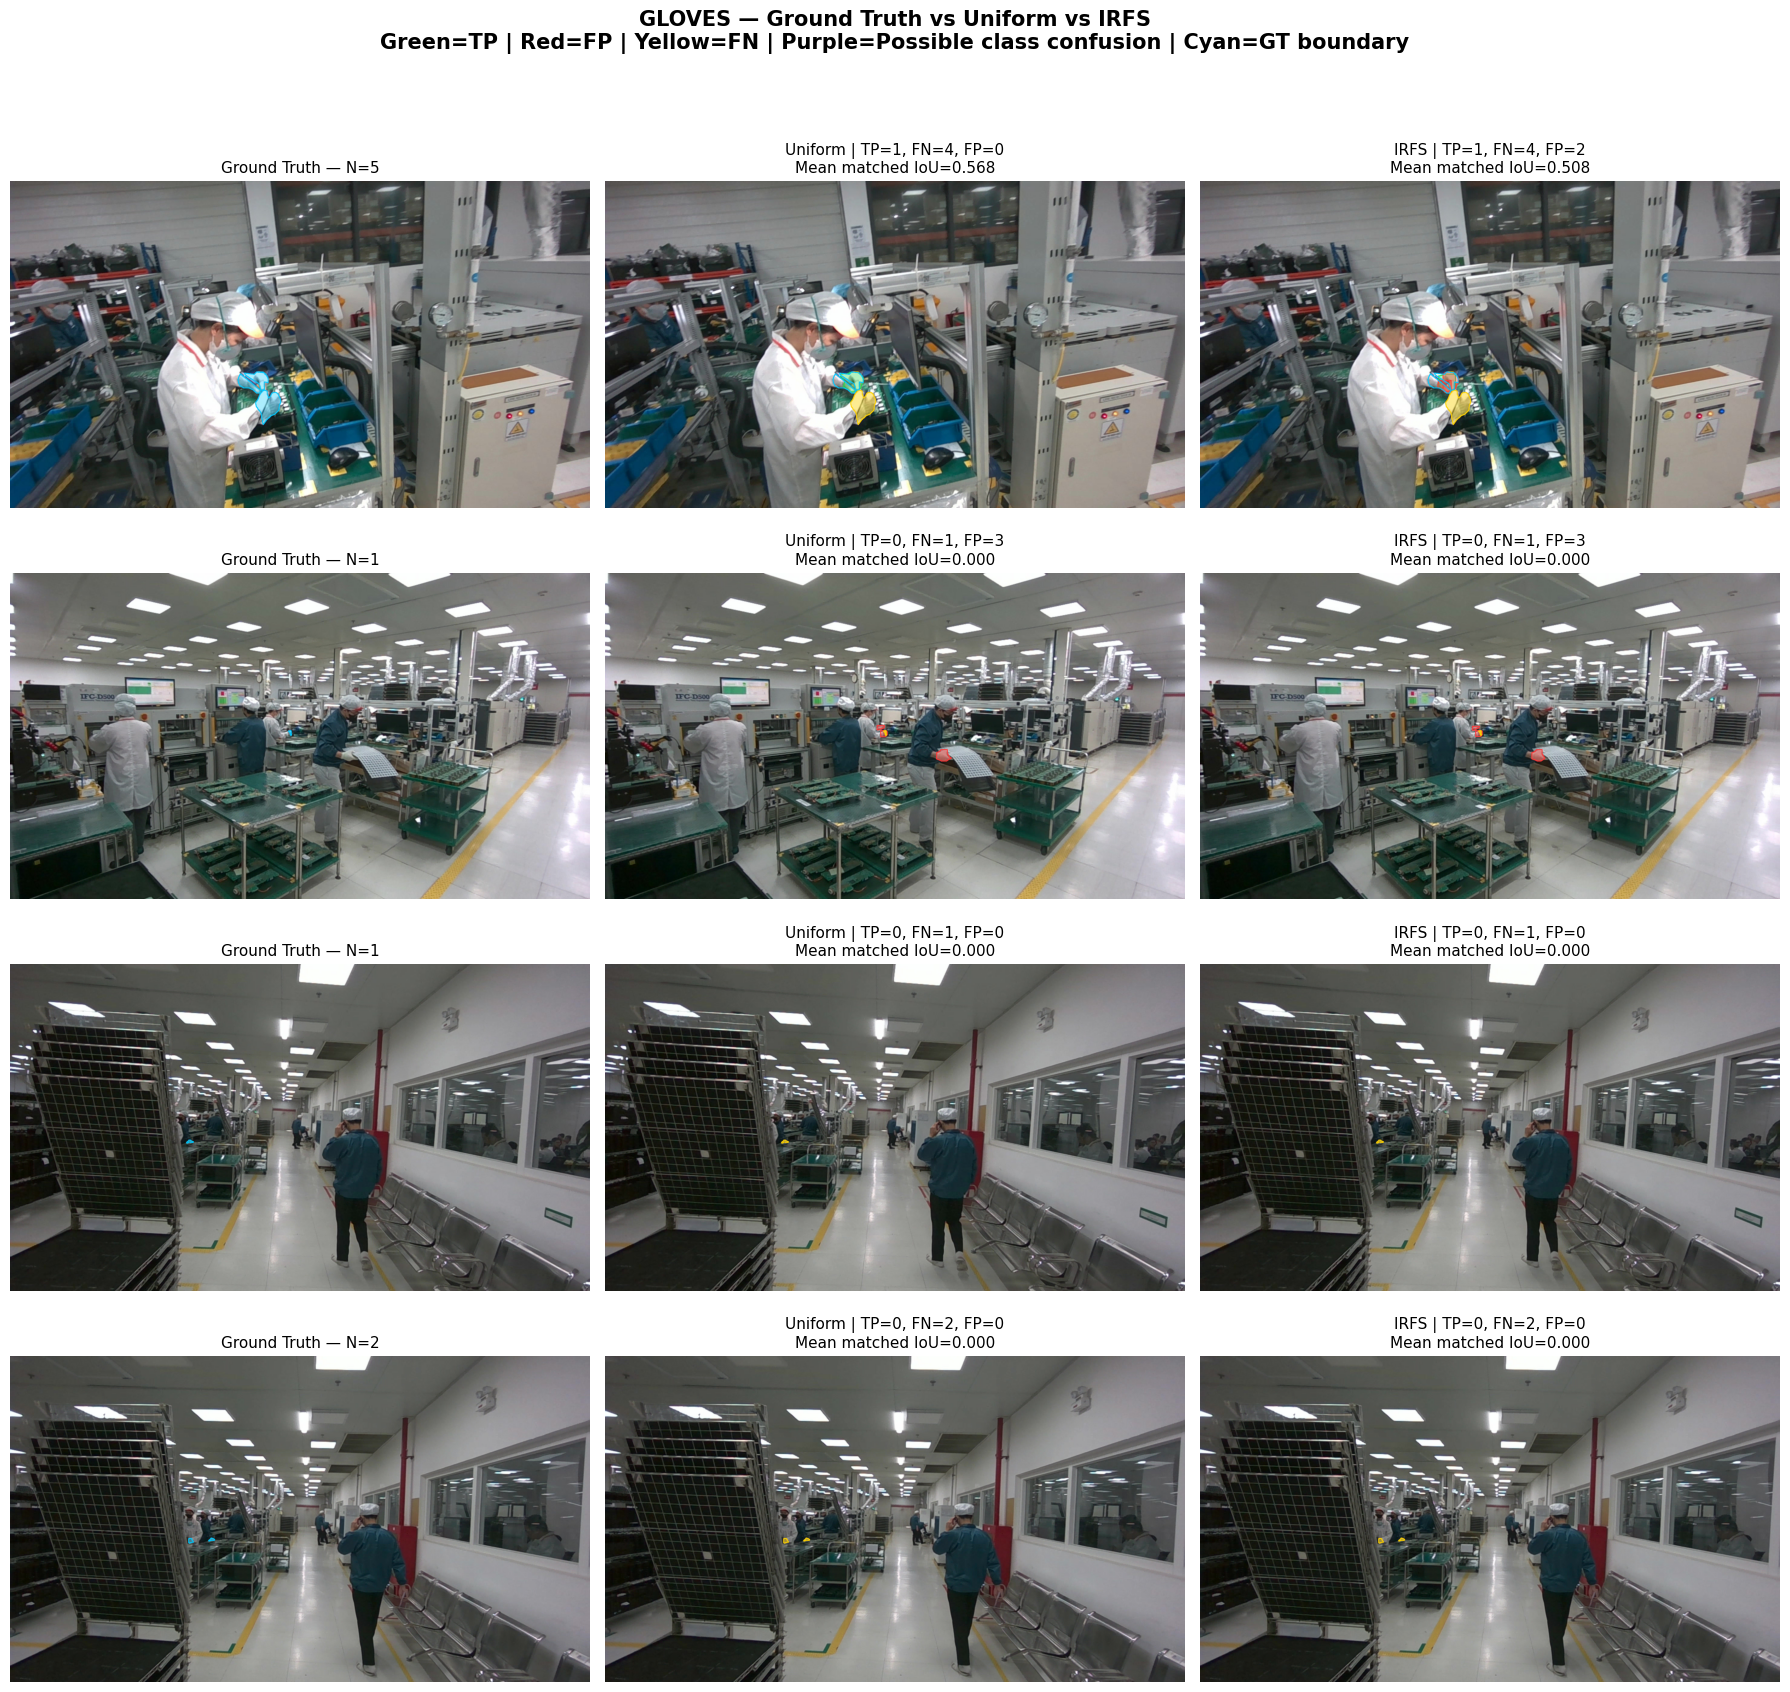

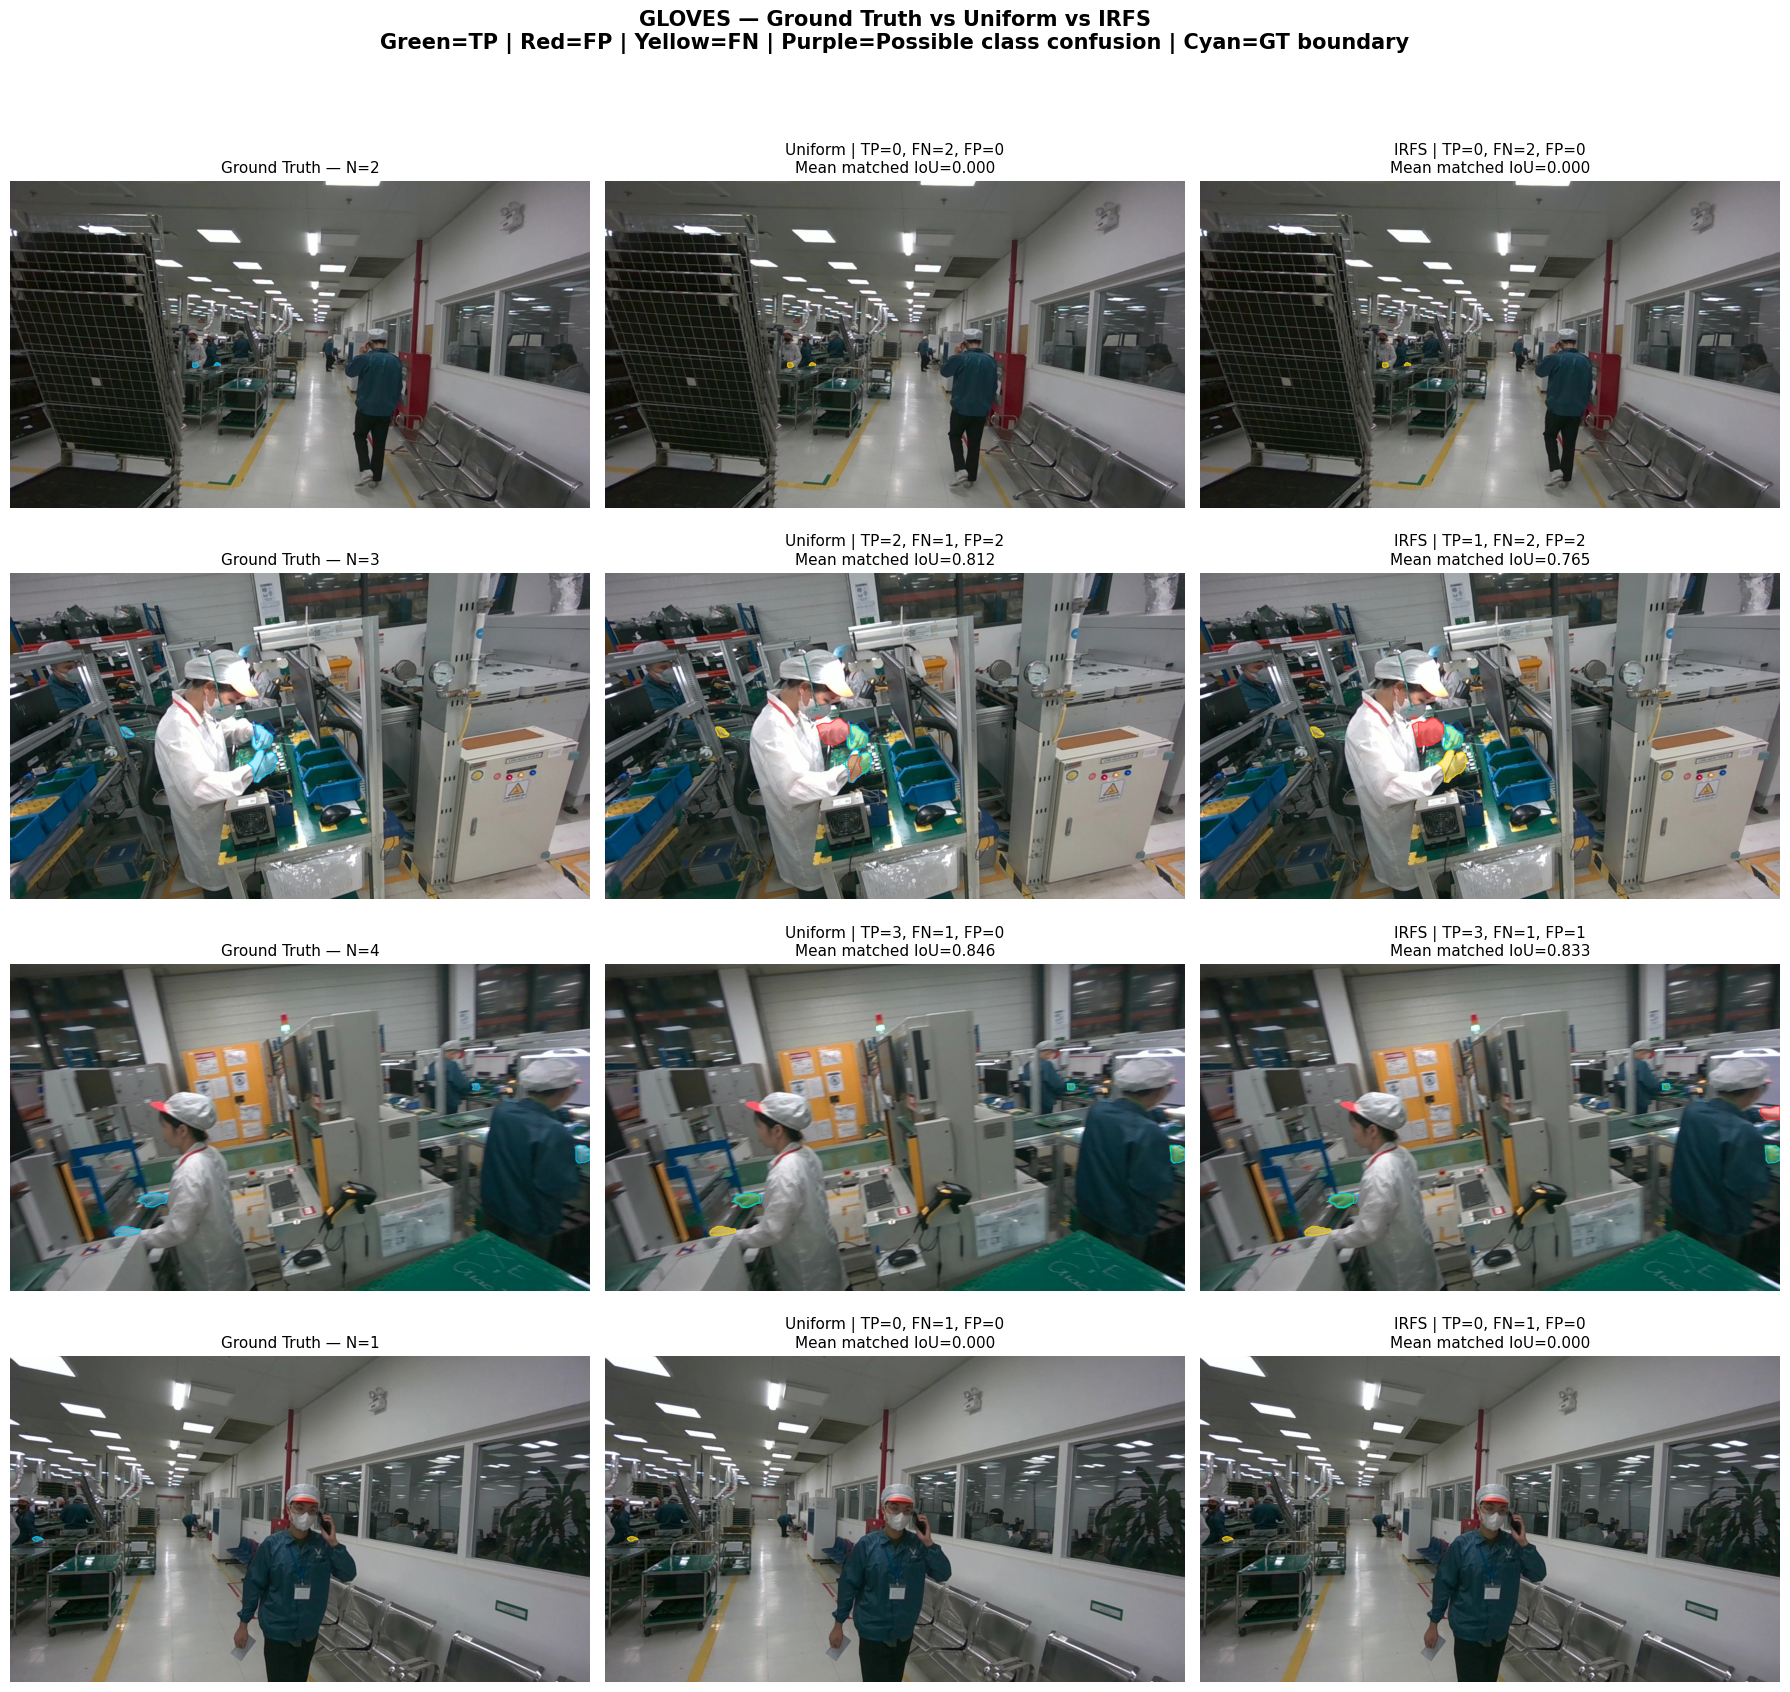

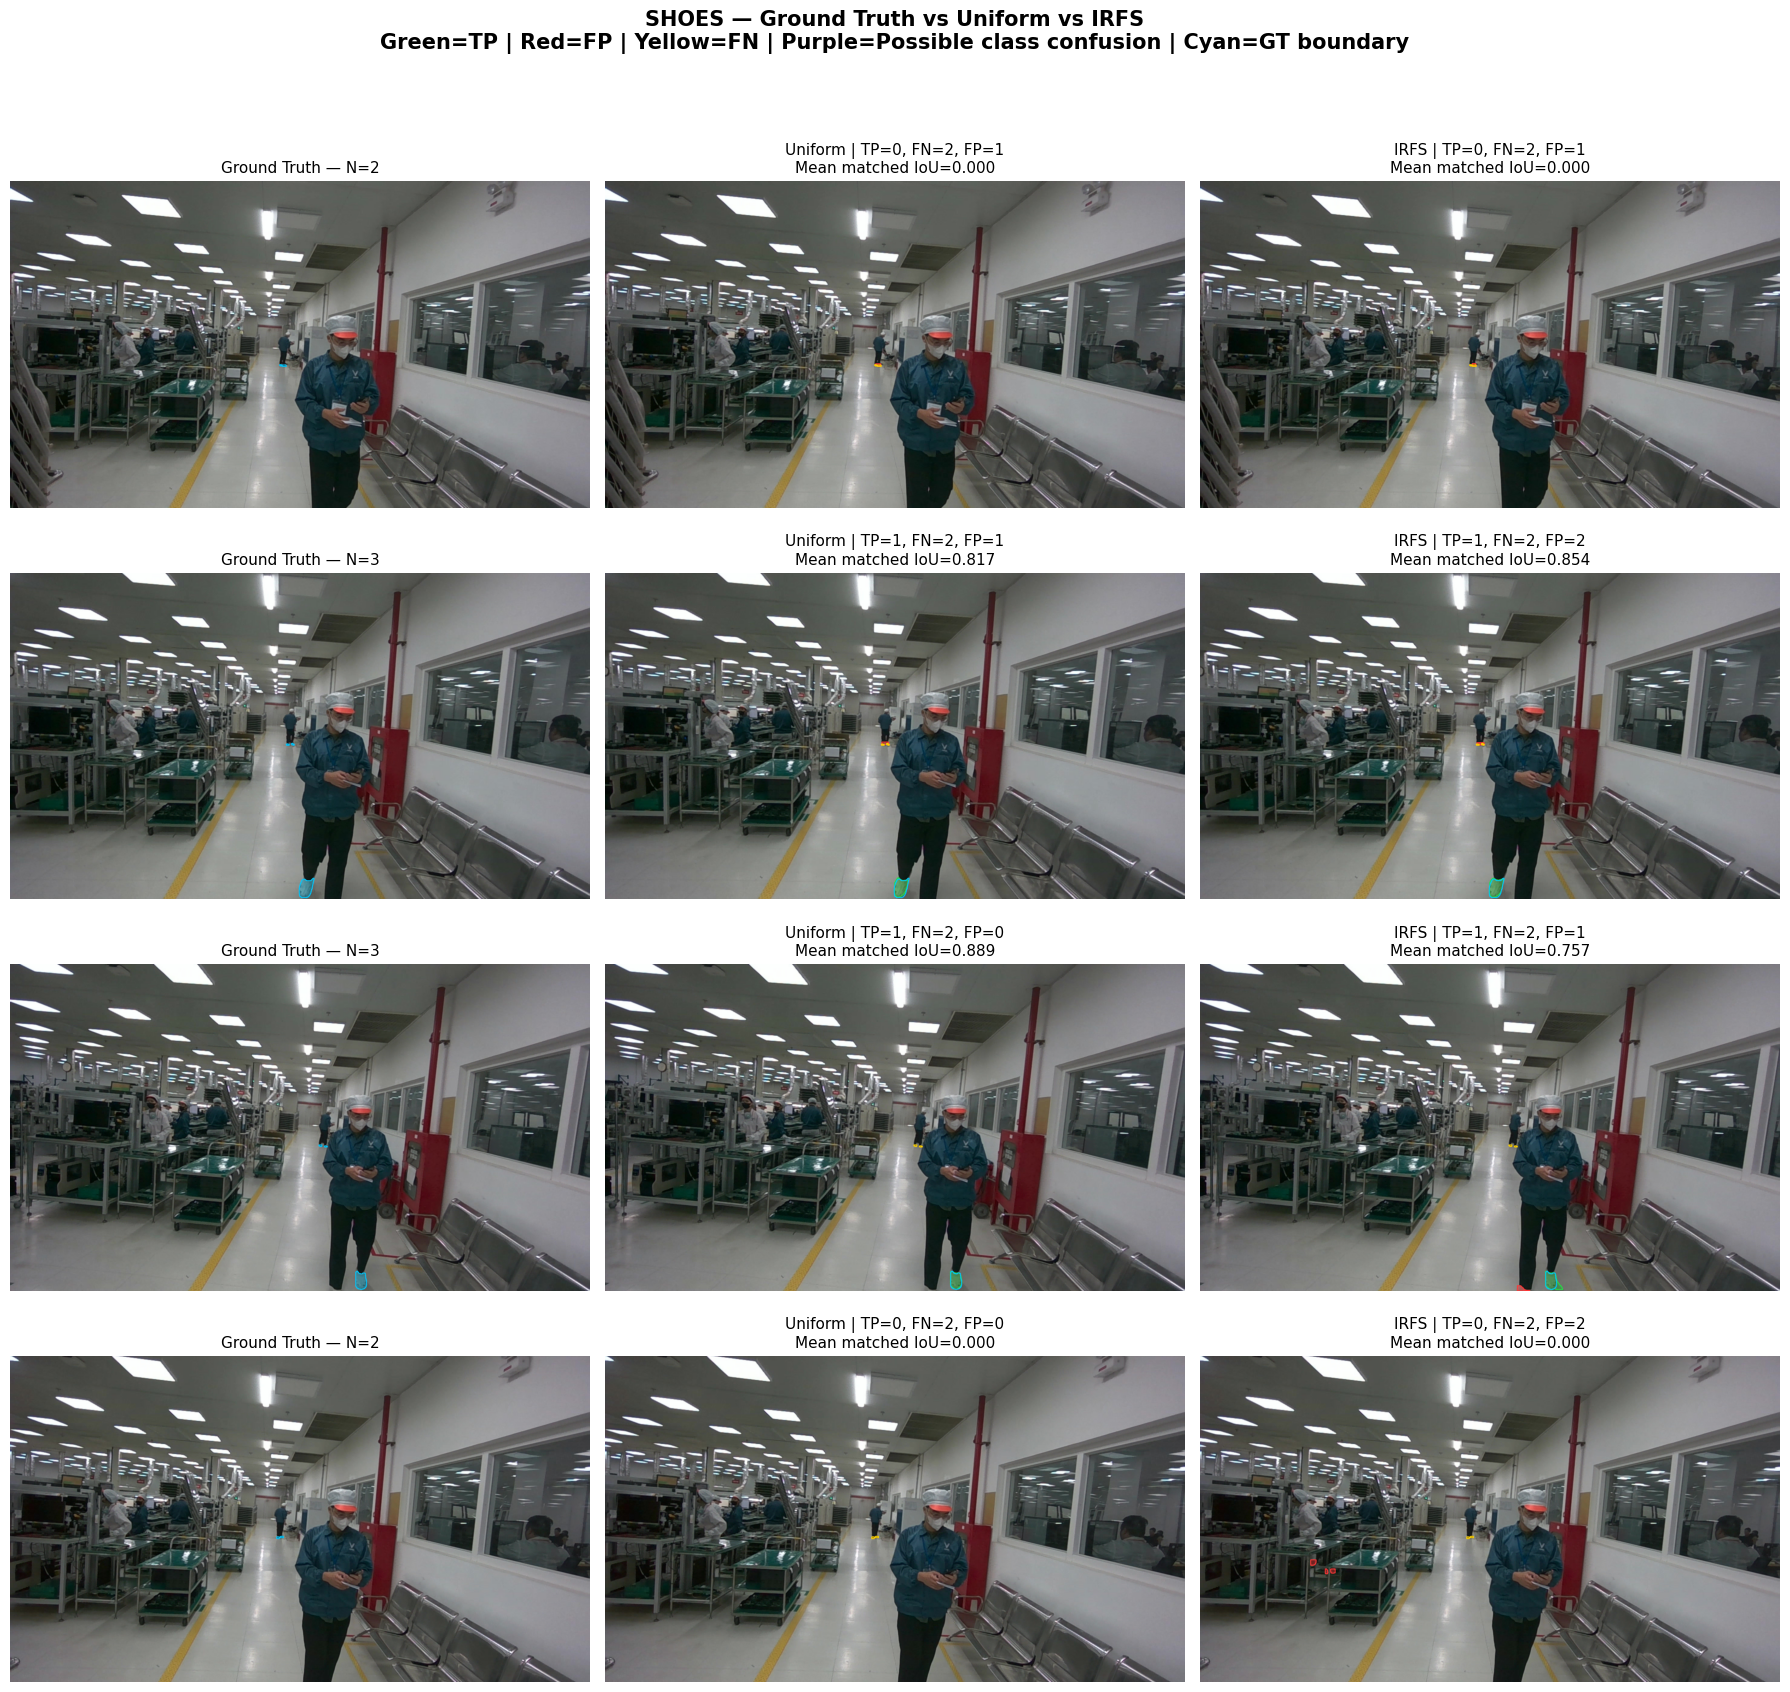

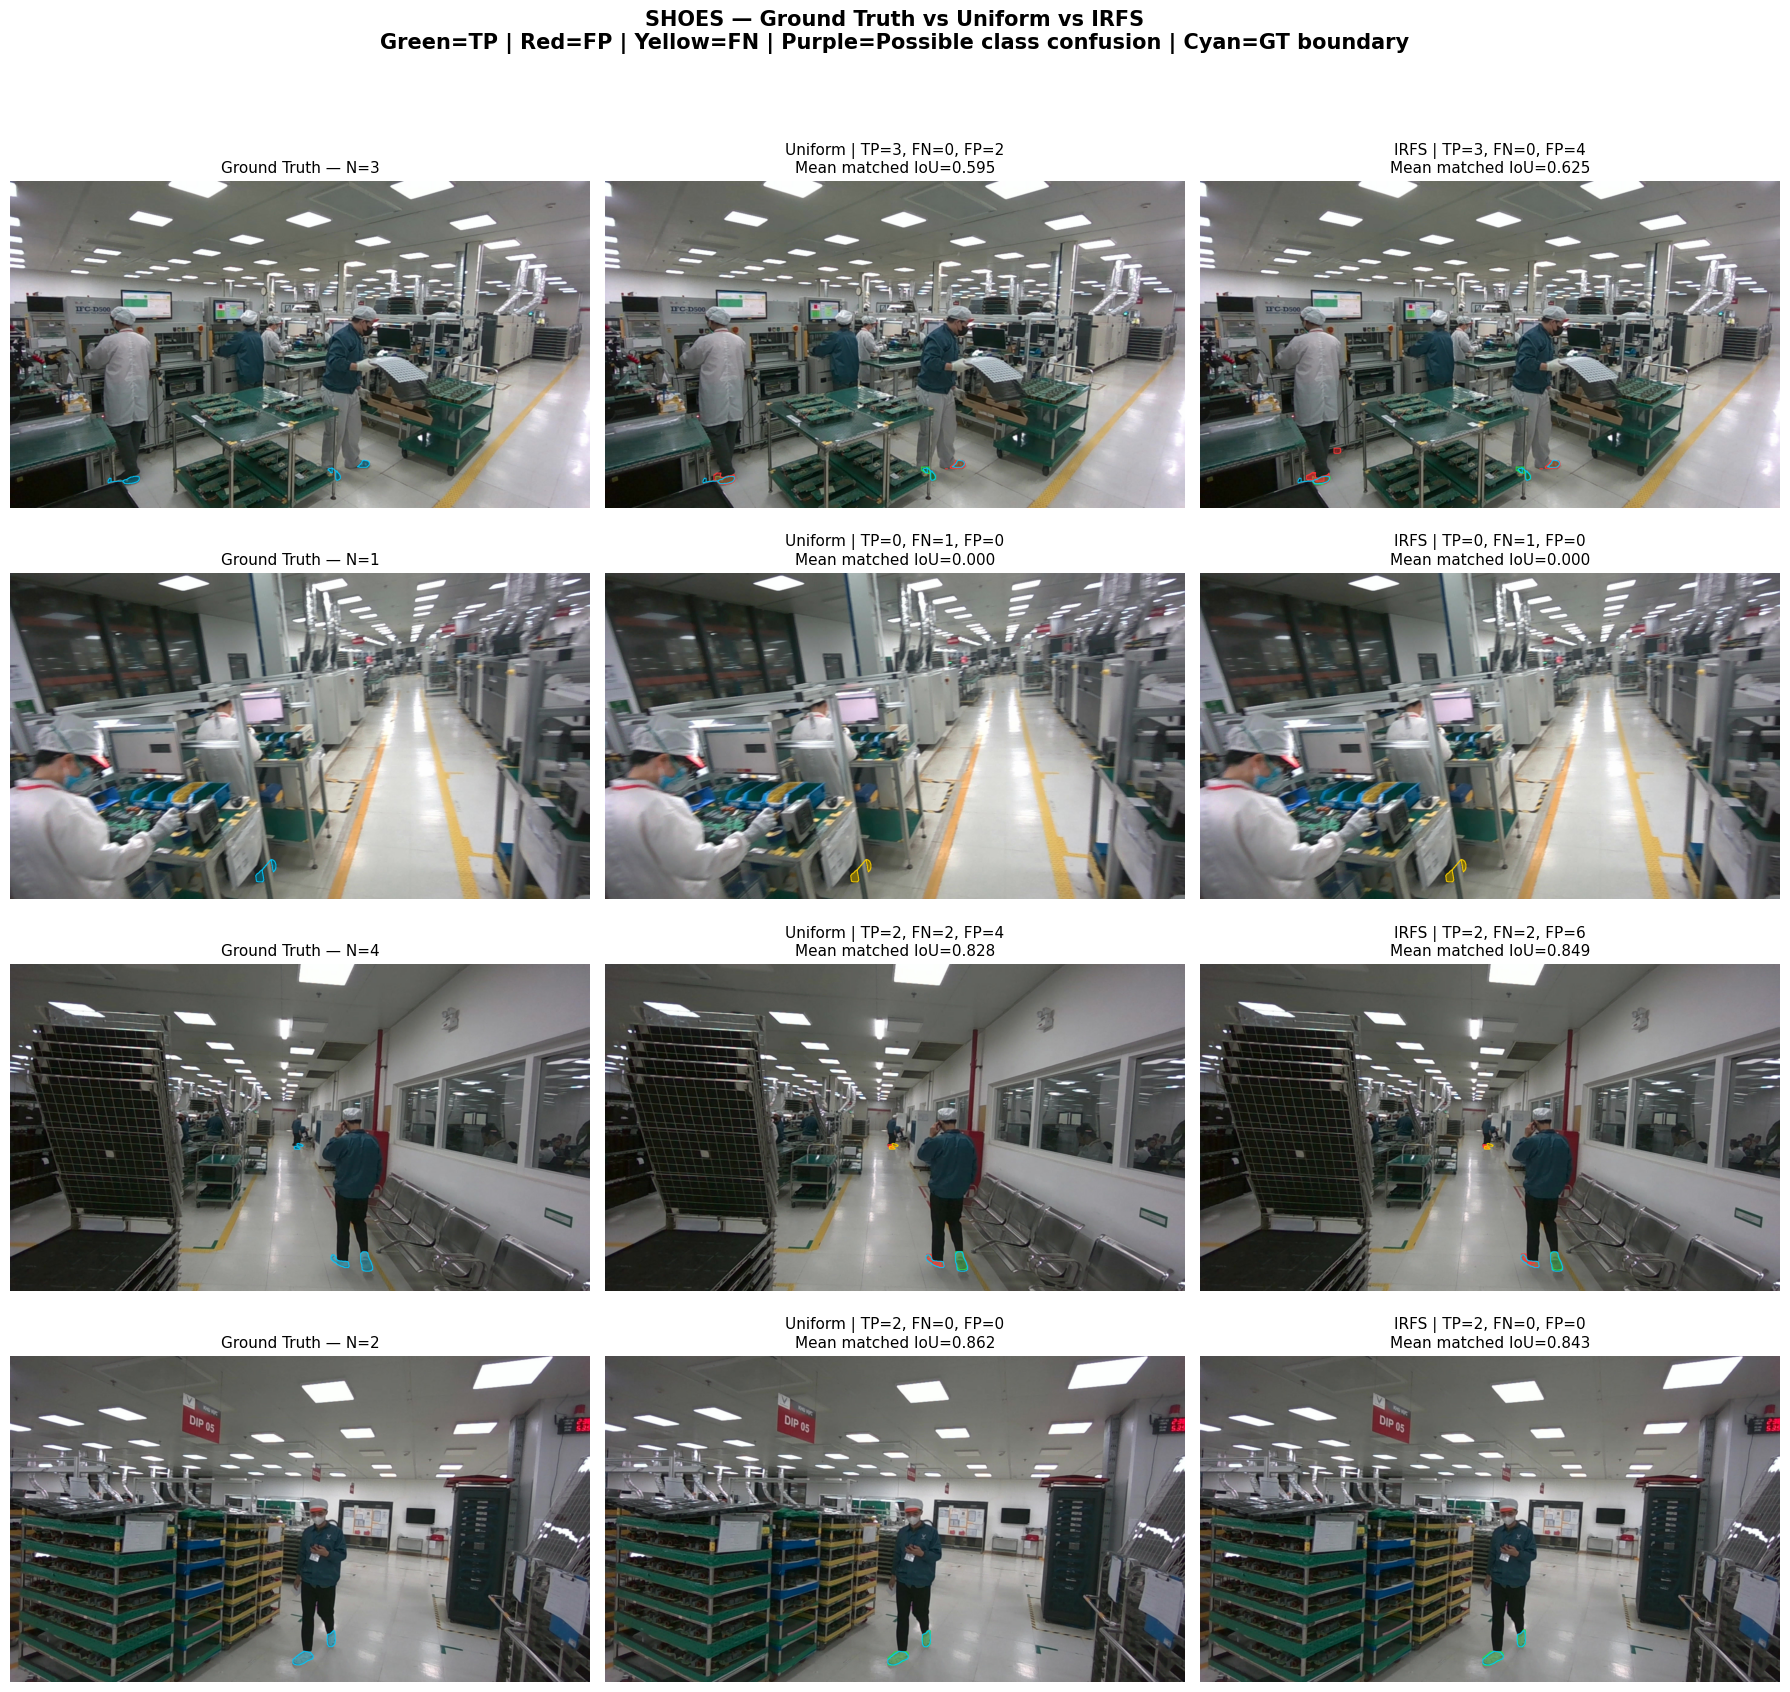


SELECTED SAMPLE ERROR SUMMARY


,class_name,model,images,GT_instances,pred_instances,TP,FN,FP,Recall_at_IoU50,Precision_at_IoU50,mean_matched_IoU,possible_class_confusion
0,gloves,IRFS,8,19,13,5,14,8,0.2632,0.3846,0.7544,0
1,gloves,Uniform,8,19,11,6,13,5,0.3158,0.5455,0.7884,0
2,shoes,IRFS,8,20,25,9,11,16,0.4500,0.3600,0.7635,0
3,shoes,Uniform,8,20,17,9,11,8,0.4500,0.5294,0.7635,0



PER-GROUND-TRUTH INSTANCE ANALYSIS


,image,class_name,model,GT_object_index,area_ratio,size_bucket,matched,best_target_class_IoU,possible_other_class_overlap,best_other_class_IoU
0,NhatTan__layout_20260908_142002__001430.jpg,gloves,Uniform,0,0.0027,small,False,0.0000,False,0.0000
1,NhatTan__layout_20260908_142002__001430.jpg,gloves,Uniform,1,0.0020,small,True,0.5681,False,0.0078
2,NhatTan__layout_20260908_142002__001430.jpg,gloves,Uniform,2,0.0000,small,False,0.0000,False,0.0000
3,NhatTan__layout_20260908_142002__001430.jpg,gloves,Uniform,3,0.0000,small,False,0.0000,False,0.0000
4,NhatTan__layout_20260908_142002__001430.jpg,gloves,Uniform,4,0.0000,small,False,0.0024,False,0.0000
5,NhatTan__layout_20260908_142002__001430.jpg,gloves,IRFS,0,0.0027,small,False,0.0000,False,0.0000
6,NhatTan__layout_20260908_142002__001430.jpg,gloves,IRFS,1,0.0020,small,True,0.5082,False,0.0062
7,NhatTan__layout_20260908_142002__001430.jpg,gloves,IRFS,2,0.0000,small,False,0.0000,False,0.0000
8,NhatTan__layout_20260908_142002__001430.jpg,gloves,IRFS,3,0.0000,small,False,0.0000,False,0.0000
9,NhatTan__layout_20260908_142002__001430.jpg,gloves,IRFS,4,0.0000,small,False,0.0032,False,0.0000



FALSE POSITIVE PREDICTIONS


,image,class_name,model,prediction_index,confidence,best_GT_IoU
0,NhatTan__layout_20260908_142002__001430.jpg,gloves,IRFS,0,0.6497,0.4755
1,NhatTan__layout_20260908_142002__001430.jpg,gloves,IRFS,2,0.3727,0.2365
2,QuocHung__screen_on_off_outdoor_pm_20260908_13...,gloves,Uniform,0,0.6997,0.0000
3,QuocHung__screen_on_off_outdoor_pm_20260908_13...,gloves,Uniform,1,0.6527,0.2167
4,QuocHung__screen_on_off_outdoor_pm_20260908_13...,gloves,Uniform,2,0.2733,0.0000
5,QuocHung__screen_on_off_outdoor_pm_20260908_13...,gloves,IRFS,0,0.7137,0.0000
6,QuocHung__screen_on_off_outdoor_pm_20260908_13...,gloves,IRFS,1,0.5963,0.2220
7,QuocHung__screen_on_off_outdoor_pm_20260908_13...,gloves,IRFS,2,0.2416,0.0000
8,NhatTan__layout_20260908_142002__001450.jpg,gloves,Uniform,2,0.2092,0.0031
9,NhatTan__layout_20260908_142002__001450.jpg,gloves,Uniform,3,0.1632,0.4866



OUTPUT FILES
Output folder: /content/drive/MyDrive/YOLO11_seg_expanded/research_experiments/error_analysis_gloves_shoes_v1/20261030_092749

Contact sheets:
/content/drive/MyDrive/YOLO11_seg_expanded/research_experiments/error_analysis_gloves_shoes_v1/20261030_092749/gloves_contact_sheet_page_1.png
/content/drive/MyDrive/YOLO11_seg_expanded/research_experiments/error_analysis_gloves_shoes_v1/20261030_092749/gloves_contact_sheet_page_2.png
/content/drive/MyDrive/YOLO11_seg_expanded/research_experiments/error_analysis_gloves_shoes_v1/20261030_092749/shoes_contact_sheet_page_1.png
/content/drive/MyDrive/YOLO11_seg_expanded/research_experiments/error_analysis_gloves_shoes_v1/20261030_092749/shoes_contact_sheet_page_2.png

CSV files:
/content/drive/MyDrive/YOLO11_seg_expanded/research_experiments/error_analysis_gloves_shoes_v1/20261030_092749/per_image_error_metrics.csv
/content/drive/MyDrive/YOLO11_seg_expanded/research_experiments/error_analysis_gloves_shoes_v1/20261030_092749/per_ground_

In [ ]:

# ============================================================
# CELL 37 — QUALITATIVE ERROR ANALYSIS
# Uniform (A) vs IRFS (C)
# Target classes: Gloves (1), Shoes (4)
# ============================================================

import os
import json
import cv2
import gc
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from datetime import datetime
from scipy.optimize import linear_sum_assignment
from ultralytics import YOLO
from IPython.display import display, Image as IPyImage

# ============================================================
# 1. CẤU HÌNH
# ============================================================

CLASS_INFO = {
    1: "gloves",
    4: "shoes",
}

CHECKPOINTS = {
    "Uniform": (
        PROJECT_DIR
        / "research_experiments"
        / "A_uniform"
        / "weights"
        / "best.pt"
    ),

    "IRFS": (
        PROJECT_DIR
        / "research_experiments"
        / "C_irfs_t030"
        / "weights"
        / "best.pt"
    ),
}

IMAGE_ROOT = (
    DATASET_BUILD_DIR
    / "images"
    / "val"
)

LABEL_ROOT = (
    DATASET_BUILD_DIR
    / "labels"
    / "val"
)

# Số ảnh cho mỗi lớp
N_SMALLEST = 4
N_RANDOM = 4
RANDOM_SEED = 2026

# Ngưỡng phân tích
PRED_CONF = 0.15
PRED_NMS_IOU = 0.70
MATCH_IOU = 0.50

# Dùng để chia kích thước đối tượng theo tỷ lệ diện tích mask
# Đây là ngưỡng heuristic phục vụ phân tích, không phải chuẩn COCO.
SMALL_AREA_RATIO = 0.01
MEDIUM_AREA_RATIO = 0.05

IMAGE_SIZE = 960
BATCH_SIZE = 4

# ============================================================
# 2. KIỂM TRA INPUT
# ============================================================

print("=" * 75)
print("QUALITATIVE ERROR ANALYSIS — GLOVES & SHOES")
print("=" * 75)

for model_name, checkpoint in CHECKPOINTS.items():
    if not checkpoint.exists():
        raise FileNotFoundError(
            f"Checkpoint not found: {checkpoint}"
        )
    print(f"[OK] {model_name}: {checkpoint}")

if not IMAGE_ROOT.exists():
    raise FileNotFoundError(IMAGE_ROOT)

if not LABEL_ROOT.exists():
    raise FileNotFoundError(LABEL_ROOT)

# Tạo thư mục output riêng, không ghi đè kết quả cũ.
OUTPUT_ROOT = (
    PROJECT_DIR
    / "research_experiments"
    / "error_analysis_gloves_shoes_v1"
)

timestamp = datetime.now().strftime("%Y%m%d_%H%M%S")

OUTPUT_DIR = OUTPUT_ROOT / timestamp
OUTPUT_DIR.mkdir(parents=True, exist_ok=False)

print(f"\nOutput directory: {OUTPUT_DIR}")

# ============================================================
# 3. TÌM ẢNH VALIDATION VÀ LABEL TƯƠNG ỨNG
# ============================================================

IMAGE_EXTENSIONS = {
    ".jpg", ".jpeg", ".png", ".bmp", ".webp"
}

image_paths = sorted([
    p for p in IMAGE_ROOT.rglob("*")
    if p.is_file()
    and p.suffix.lower() in IMAGE_EXTENSIONS
])

if len(image_paths) == 0:
    raise RuntimeError("No validation images found.")

def image_to_label_path(image_path):

    image_path = Path(image_path)

    image_str = str(image_path)

    image_token = os.sep + "images" + os.sep
    label_token = os.sep + "labels" + os.sep

    if image_token not in image_str:
        raise ValueError(
            f"Cannot map image to label: {image_path}"
        )

    label_str = image_str.replace(
        image_token,
        label_token,
        1
    )

    return Path(label_str).with_suffix(".txt")


print(f"Validation images found: {len(image_paths)}")

# ============================================================
# 4. ĐỌC POLYGON GROUND TRUTH
# ============================================================

def load_yolo_segmentation_polygons(label_path):

    polygons_by_class = {
        class_id: []
        for class_id in CLASS_INFO
    }

    skipped_rows = 0

    with open(label_path, "r", encoding="utf-8") as f:

        for line in f:

            parts = line.strip().split()

            if len(parts) < 7:
                skipped_rows += 1
                continue

            try:
                class_id = int(float(parts[0]))

                if class_id not in CLASS_INFO:
                    continue

                coords = np.asarray(
                    [float(v) for v in parts[1:]],
                    dtype=np.float32
                )

                if len(coords) < 6 or len(coords) % 2 != 0:
                    skipped_rows += 1
                    continue

                polygon = coords.reshape(-1, 2)

                if not np.isfinite(polygon).all():
                    skipped_rows += 1
                    continue

                polygon = np.clip(
                    polygon,
                    0.0,
                    1.0
                )

                polygons_by_class[class_id].append(
                    polygon
                )

            except Exception:
                skipped_rows += 1

    return polygons_by_class, skipped_rows


# Lưu polygon chuẩn hóa và diện tích tương đối.
# Chưa tạo full-resolution masks để tiết kiệm RAM.

annotations = {}

total_skipped_rows = 0

for image_path in image_paths:

    label_path = image_to_label_path(image_path)

    if not label_path.exists():
        raise FileNotFoundError(
            f"Missing label for image:\n{image_path}\n"
            f"Expected:\n{label_path}"
        )

    polygons_by_class, skipped = (
        load_yolo_segmentation_polygons(label_path)
    )

    total_skipped_rows += skipped

    annotations[str(image_path)] = {
        "polygons": polygons_by_class,
        "label_path": str(label_path),
    }

print(f"Parsed images: {len(annotations)}")
print(f"Skipped malformed rows: {total_skipped_rows}")

# ============================================================
# 5. CHỌN ẢNH: 4 NHỎ NHẤT + 4 NGẪU NHIÊN MỖI LỚP
# ============================================================

rng = np.random.default_rng(RANDOM_SEED)

selected_by_class = {}

selection_metadata = {}

for class_id, class_name in CLASS_INFO.items():

    candidates = []

    for image_path in image_paths:

        key = str(image_path)

        polygons = annotations[key]["polygons"][class_id]

        if len(polygons) == 0:
            continue

        areas = []

        for polygon in polygons:

            area = abs(
                cv2.contourArea(
                    polygon.astype(np.float32)
                )
            )

            if area > 0:
                areas.append(area)

        if len(areas) == 0:
            continue

        candidates.append({
            "path": key,
            "instance_count": len(polygons),
            "median_area_ratio": float(np.median(areas)),
            "min_area_ratio": float(np.min(areas)),
        })

    # Nhỏ đến lớn theo median area
    candidates = sorted(
        candidates,
        key=lambda x: x["median_area_ratio"]
    )

    if len(candidates) == 0:
        raise RuntimeError(
            f"No validation images contain class {class_name}"
        )

    # Chọn ảnh có đối tượng nhỏ
    smallest = candidates[:min(N_SMALLEST, len(candidates))]

    smallest_paths = {
        item["path"] for item in smallest
    }

    # Chọn ngẫu nhiên từ phần còn lại
    remaining = [
        item for item in candidates
        if item["path"] not in smallest_paths
    ]

    random_count = min(N_RANDOM, len(remaining))

    if random_count > 0:

        random_indices = rng.choice(
            len(remaining),
            size=random_count,
            replace=False
        )

        random_selected = [
            remaining[int(i)]
            for i in random_indices
        ]

    else:
        random_selected = []

    selected = []

    for item in smallest:

        item = dict(item)
        item["selection_reason"] = "smallest_objects"
        selected.append(item)

    for item in random_selected:

        item = dict(item)
        item["selection_reason"] = "random_reference"
        selected.append(item)

    selected_by_class[class_id] = selected

    for item in selected:
        selection_metadata[
            (item["path"], class_id)
        ] = item

    print("\n" + "-" * 65)
    print(
        f"{class_name.upper()}: "
        f"{len(candidates)} candidate images"
    )
    print(
        f"Selected: {len(selected)} "
        f"({len(smallest)} smallest + {len(random_selected)} random)"
    )

    for item in selected:

        print(
            f"  {Path(item['path']).name} | "
            f"Instances={item['instance_count']} | "
            f"Median area={item['median_area_ratio'] * 100:.3f}% | "
            f"{item['selection_reason']}"
        )

# Union: cùng một ảnh có thể được dùng cho cả hai class.
selected_image_paths = sorted({
    item["path"]
    for selected in selected_by_class.values()
    for item in selected
})

print("\n" + "=" * 75)
print(f"Unique images selected: {len(selected_image_paths)}")
print("=" * 75)

# ============================================================
# 6. TẠO GROUND TRUTH MASK
# ============================================================

def polygon_to_mask(polygon, height, width):

    points = np.round(
        polygon * np.array([width, height])
    ).astype(np.int32)

    points[:, 0] = np.clip(
        points[:, 0], 0, width - 1
    )

    points[:, 1] = np.clip(
        points[:, 1], 0, height - 1
    )

    mask = np.zeros(
        (height, width),
        dtype=np.uint8
    )

    cv2.fillPoly(
        mask,
        [points],
        1
    )

    return mask.astype(bool)


def get_ground_truth_masks(image_path, class_id):

    image = cv2.imread(image_path)

    if image is None:
        raise RuntimeError(
            f"Cannot read image: {image_path}"
        )

    height, width = image.shape[:2]

    polygons = (
        annotations[image_path]["polygons"][class_id]
    )

    masks = []

    for polygon in polygons:

        mask = polygon_to_mask(
            polygon,
            height,
            width
        )

        if mask.any():
            masks.append(mask)

    return image, masks

# ============================================================
# 7. CHẠY PREDICTION CHO A VÀ C
# ============================================================

# Chạy đúng cùng một danh sách ảnh cho cả hai checkpoint.
# Không giới hạn classes để có thể phát hiện dấu hiệu nhầm class.

predictions = {
    "Uniform": {},
    "IRFS": {},
}

for model_name, checkpoint in CHECKPOINTS.items():

    print("\n" + "=" * 75)
    print(f"PREDICTING WITH {model_name.upper()}")
    print("=" * 75)

    model = YOLO(str(checkpoint))

    results = model.predict(
        source=selected_image_paths,
        imgsz=IMAGE_SIZE,
        batch=BATCH_SIZE,
        conf=PRED_CONF,
        iou=PRED_NMS_IOU,
        max_det=300,
        device=0,
        retina_masks=True,
        save=False,
        verbose=False,
    )

    if len(results) != len(selected_image_paths):
        raise RuntimeError(
            f"Unexpected prediction result count: "
            f"{len(results)} vs {len(selected_image_paths)}"
        )

    for image_path, result in zip(
        selected_image_paths,
        results
    ):

        image_predictions = []

        if result.boxes is not None and result.masks is not None:

            pred_classes = (
                result.boxes.cls.detach()
                .cpu()
                .numpy()
                .astype(int)
            )

            pred_confidences = (
                result.boxes.conf.detach()
                .cpu()
                .numpy()
            )

            pred_masks = (
                result.masks.data.detach()
                .cpu()
                .numpy()
            )

            height, width = result.orig_shape

            for index in range(len(pred_classes)):

                pred_mask = pred_masks[index]

                if pred_mask.shape != (height, width):

                    pred_mask = cv2.resize(
                        pred_mask.astype(np.uint8),
                        (width, height),
                        interpolation=cv2.INTER_NEAREST
                    )

                pred_mask = pred_mask > 0.5

                if not pred_mask.any():
                    continue

                image_predictions.append({
                    "class_id": int(pred_classes[index]),
                    "confidence": float(
                        pred_confidences[index]
                    ),
                    "mask": pred_mask,
                })

        predictions[model_name][image_path] = (
            image_predictions
        )

    print(
        f"[OK] {model_name}: "
        f"{len(image_predictions)} predictions "
        f"on last image (not total)"
    )

    del model
    gc.collect()

    if torch.cuda.is_available():
        torch.cuda.empty_cache()

print("\nPrediction completed for both models.")

# ============================================================
# 8. MASK IoU VÀ MATCHING
# ============================================================

def calculate_mask_iou(mask_a, mask_b):

    intersection = np.logical_and(
        mask_a,
        mask_b
    ).sum()

    union = np.logical_or(
        mask_a,
        mask_b
    ).sum()

    if union == 0:
        return 0.0

    return float(intersection / union)


def match_instances(
    gt_masks,
    pred_items,
    threshold=MATCH_IOU
):

    n_gt = len(gt_masks)
    n_pred = len(pred_items)

    if n_gt == 0 or n_pred == 0:

        return {
            "matches": [],
            "unmatched_gt": list(range(n_gt)),
            "unmatched_pred": list(range(n_pred)),
            "iou_matrix": np.zeros(
                (n_gt, n_pred),
                dtype=np.float32
            ),
        }

    iou_matrix = np.zeros(
        (n_gt, n_pred),
        dtype=np.float32
    )

    for i, gt_mask in enumerate(gt_masks):

        for j, pred_item in enumerate(pred_items):

            iou_matrix[i, j] = calculate_mask_iou(
                gt_mask,
                pred_item["mask"]
            )

    # Ưu tiên tối đa số lượng match đạt threshold,
    # sau đó ưu tiên tổng IoU cao hơn.
    valid = (iou_matrix >= threshold).astype(float)

    score_matrix = (
        valid * 1000.0
        + iou_matrix
    )

    rows, cols = linear_sum_assignment(
        -score_matrix
    )

    matches = []

    matched_gt = set()
    matched_pred = set()

    for gt_index, pred_index in zip(rows, cols):

        iou = float(
            iou_matrix[gt_index, pred_index]
        )

        if iou >= threshold:

            matches.append({
                "gt_index": int(gt_index),
                "pred_index": int(pred_index),
                "iou": iou,
            })

            matched_gt.add(int(gt_index))
            matched_pred.add(int(pred_index))

    unmatched_gt = [
        i for i in range(n_gt)
        if i not in matched_gt
    ]

    unmatched_pred = [
        i for i in range(n_pred)
        if i not in matched_pred
    ]

    return {
        "matches": matches,
        "unmatched_gt": unmatched_gt,
        "unmatched_pred": unmatched_pred,
        "iou_matrix": iou_matrix,
    }

# ============================================================
# 9. OVERLAY VISUALIZATION
# ============================================================

COLOR_GT = (0, 200, 255)       # Cyan
COLOR_TP = (40, 220, 70)       # Green
COLOR_FP = (255, 55, 55)       # Red
COLOR_FN = (255, 210, 0)       # Yellow
COLOR_CONFUSION = (190, 80, 255)  # Purple


def paint_mask(
    image_rgb,
    mask,
    color,
    alpha=0.35
):

    mask = mask.astype(bool)

    if not mask.any():
        return

    color_array = np.asarray(
        color,
        dtype=np.float32
    )

    image_rgb[mask] = (
        image_rgb[mask].astype(np.float32)
        * (1.0 - alpha)
        + color_array * alpha
    ).clip(0, 255).astype(np.uint8)

    contour_input = (
        mask.astype(np.uint8) * 255
    )

    contours, _ = cv2.findContours(
        contour_input,
        cv2.RETR_EXTERNAL,
        cv2.CHAIN_APPROX_SIMPLE
    )

    cv2.drawContours(
        image_rgb,
        contours,
        -1,
        color,
        2
    )


def create_gt_panel(image_bgr, gt_masks):

    image_rgb = cv2.cvtColor(
        image_bgr,
        cv2.COLOR_BGR2RGB
    )

    image_rgb = image_rgb.copy()

    for mask in gt_masks:

        paint_mask(
            image_rgb,
            mask,
            COLOR_GT,
            alpha=0.32
        )

    return image_rgb


def create_prediction_panel(
    image_bgr,
    gt_masks,
    target_predictions,
    other_predictions,
    matching
):

    image_rgb = cv2.cvtColor(
        image_bgr,
        cv2.COLOR_BGR2RGB
    )

    image_rgb = image_rgb.copy()

    matched_pairs = matching["matches"]

    matched_gt = {
        item["gt_index"]: item
        for item in matched_pairs
    }

    matched_pred = {
        item["pred_index"]: item
        for item in matched_pairs
    }

    unmatched_gt = matching["unmatched_gt"]
    unmatched_pred = matching["unmatched_pred"]

    # 1. Predictions đúng (TP) — xanh lá
    for pred_index in matched_pred:

        paint_mask(
            image_rgb,
            target_predictions[pred_index]["mask"],
            COLOR_TP,
            alpha=0.35
        )

    # 2. Predictions thừa (FP) — đỏ
    for pred_index in unmatched_pred:

        paint_mask(
            image_rgb,
            target_predictions[pred_index]["mask"],
            COLOR_FP,
            alpha=0.40
        )

    # 3. Ground Truth bị bỏ sót (FN) — vàng
    # Nếu có prediction class khác overlap lớn thì dùng viền tím.
    confusion_gt = set()

    for gt_index in unmatched_gt:

        gt_mask = gt_masks[gt_index]

        max_other_iou = 0.0

        for other_pred in other_predictions:

            iou = calculate_mask_iou(
                gt_mask,
                other_pred["mask"]
            )

            max_other_iou = max(
                max_other_iou,
                iou
            )

        if max_other_iou >= MATCH_IOU:
            confusion_gt.add(gt_index)

        paint_mask(
            image_rgb,
            gt_mask,
            COLOR_FN,
            alpha=0.42
        )

        if gt_index in confusion_gt:

            contour_input = (
                gt_mask.astype(np.uint8) * 255
            )

            contours, _ = cv2.findContours(
                contour_input,
                cv2.RETR_EXTERNAL,
                cv2.CHAIN_APPROX_SIMPLE
            )

            cv2.drawContours(
                image_rgb,
                contours,
                -1,
                COLOR_CONFUSION,
                3
            )

    # 4. Viền GT cyan cho những instance đã match
    for gt_index in matched_gt:

        contour_input = (
            gt_masks[gt_index].astype(np.uint8) * 255
        )

        contours, _ = cv2.findContours(
            contour_input,
            cv2.RETR_EXTERNAL,
            cv2.CHAIN_APPROX_SIMPLE
        )

        cv2.drawContours(
            image_rgb,
            contours,
            -1,
            COLOR_GT,
            2
        )

    return image_rgb

# ============================================================
# 10. ĐÁNH GIÁ TỪNG ẢNH VÀ TỪNG LỚP
# ============================================================

sample_rows = []
object_rows = []
false_positive_rows = []

render_data = {}

for class_id, class_name in CLASS_INFO.items():

    for selection in selected_by_class[class_id]:

        image_path = selection["path"]

        image_bgr, gt_masks = get_ground_truth_masks(
            image_path,
            class_id
        )

        height, width = image_bgr.shape[:2]

        render_data[
            (image_path, class_id)
        ] = {
            "image_bgr": image_bgr,
            "gt_masks": gt_masks,
            "selection": selection,
        }

        for model_name in ["Uniform", "IRFS"]:

            all_pred_items = predictions[
                model_name
            ][image_path]

            target_predictions = [
                item for item in all_pred_items
                if item["class_id"] == class_id
            ]

            other_predictions = [
                item for item in all_pred_items
                if item["class_id"] != class_id
            ]

            matching = match_instances(
                gt_masks,
                target_predictions,
                threshold=MATCH_IOU
            )

            matches = matching["matches"]
            unmatched_gt = matching["unmatched_gt"]
            unmatched_pred = matching["unmatched_pred"]

            gt_matched = {
                item["gt_index"]: item
                for item in matches
            }

            # ------------------------------------------------
            # Mức độ nhầm class tiềm năng
            # ------------------------------------------------

            possible_confusion = 0

            for gt_index in unmatched_gt:

                gt_mask = gt_masks[gt_index]

                max_other_iou = max(
                    [
                        calculate_mask_iou(
                            gt_mask,
                            item["mask"]
                        )
                        for item in other_predictions
                    ],
                    default=0.0
                )

                if max_other_iou >= MATCH_IOU:
                    possible_confusion += 1

            # ------------------------------------------------
            # Tỷ lệ diện tích của từng GT mask
            # ------------------------------------------------

            gt_areas = [
                float(mask.sum() / (height * width))
                for mask in gt_masks
            ]

            small_count = sum(
                area <= SMALL_AREA_RATIO
                for area in gt_areas
            )

            medium_count = sum(
                SMALL_AREA_RATIO < area <= MEDIUM_AREA_RATIO
                for area in gt_areas
            )

            large_count = sum(
                area > MEDIUM_AREA_RATIO
                for area in gt_areas
            )

            matched_iou_sum = sum(
                item["iou"]
                for item in matches
            )

            mean_matched_iou = (
                matched_iou_sum / len(matches)
                if len(matches) > 0
                else np.nan
            )

            sample_rows.append({
                "image": Path(image_path).name,
                "image_path": image_path,
                "class_id": class_id,
                "class_name": class_name,
                "model": model_name,
                "selection_reason": (
                    selection["selection_reason"]
                ),
                "gt_instances": len(gt_masks),
                "pred_instances": len(target_predictions),
                "TP": len(matches),
                "FN": len(unmatched_gt),
                "FP": len(unmatched_pred),
                "mean_matched_IoU": mean_matched_iou,
                "matched_IoU_sum": matched_iou_sum,
                "possible_class_confusion": possible_confusion,
                "small_GT_instances": small_count,
                "medium_GT_instances": medium_count,
                "large_GT_instances": large_count,
            })

            # ------------------------------------------------
            # Phân tích từng GT instance
            # ------------------------------------------------

            iou_matrix = matching["iou_matrix"]

            for gt_index, gt_mask in enumerate(gt_masks):

                area_ratio = float(
                    gt_mask.sum() / (height * width)
                )

                if area_ratio <= SMALL_AREA_RATIO:
                    size_bucket = "small"
                elif area_ratio <= MEDIUM_AREA_RATIO:
                    size_bucket = "medium"
                else:
                    size_bucket = "large"

                best_target_iou = (
                    float(iou_matrix[gt_index].max())
                    if len(target_predictions) > 0
                    else 0.0
                )

                best_other_iou = max(
                    [
                        calculate_mask_iou(
                            gt_mask,
                            item["mask"]
                        )
                        for item in other_predictions
                    ],
                    default=0.0
                )

                matched = (
                    gt_index in gt_matched
                )

                object_rows.append({
                    "image": Path(image_path).name,
                    "class_name": class_name,
                    "model": model_name,
                    "GT_object_index": gt_index,
                    "area_ratio": area_ratio,
                    "size_bucket": size_bucket,
                    "matched": matched,
                    "best_target_class_IoU": best_target_iou,
                    "possible_other_class_overlap": (
                        best_other_iou >= MATCH_IOU
                    ),
                    "best_other_class_IoU": best_other_iou,
                })

            # ------------------------------------------------
            # Phân tích từng FP prediction
            # ------------------------------------------------

            for pred_index in unmatched_pred:

                pred_item = target_predictions[pred_index]

                best_gt_iou = (
                    float(iou_matrix[:, pred_index].max())
                    if len(gt_masks) > 0
                    else 0.0
                )

                false_positive_rows.append({
                    "image": Path(image_path).name,
                    "class_name": class_name,
                    "model": model_name,
                    "prediction_index": pred_index,
                    "confidence": pred_item["confidence"],
                    "best_GT_IoU": best_gt_iou,
                })

            render_data[
                (image_path, class_id)
            ][model_name] = {
                "target_predictions": target_predictions,
                "other_predictions": other_predictions,
                "matching": matching,
                "possible_confusion": possible_confusion,
            }

# ============================================================
# 11. TẠO DATAFRAME VÀ LƯU CSV
# ============================================================

sample_df = pd.DataFrame(sample_rows)
object_df = pd.DataFrame(object_rows)
false_positive_df = pd.DataFrame(false_positive_rows)

sample_df.to_csv(
    OUTPUT_DIR / "per_image_error_metrics.csv",
    index=False
)

object_df.to_csv(
    OUTPUT_DIR / "per_ground_truth_instance.csv",
    index=False
)

false_positive_df.to_csv(
    OUTPUT_DIR / "false_positive_predictions.csv",
    index=False
)

selection_rows = []

for class_id, selected in selected_by_class.items():

    for item in selected:

        selection_rows.append({
            "class_id": class_id,
            "class_name": CLASS_INFO[class_id],
            "image": Path(item["path"]).name,
            "image_path": item["path"],
            "selection_reason": item["selection_reason"],
            "GT_instances": item["instance_count"],
            "median_area_ratio": item["median_area_ratio"],
            "min_area_ratio": item["min_area_ratio"],
        })

selection_df = pd.DataFrame(selection_rows)

selection_df.to_csv(
    OUTPUT_DIR / "selected_images.csv",
    index=False
)

# ============================================================
# 12. TỔNG HỢP KẾT QUẢ TRÊN NHÓM ẢNH ĐÃ CHỌN
# ============================================================

summary_rows = []

for (class_name, model_name), group in (
    sample_df.groupby(["class_name", "model"])
):

    total_tp = int(group["TP"].sum())
    total_fn = int(group["FN"].sum())
    total_fp = int(group["FP"].sum())

    total_gt = int(group["gt_instances"].sum())

    total_matched_iou = float(
        group["matched_IoU_sum"].sum()
    )

    summary_rows.append({
        "class_name": class_name,
        "model": model_name,
        "images": len(group),
        "GT_instances": total_gt,
        "pred_instances": int(
            group["pred_instances"].sum()
        ),
        "TP": total_tp,
        "FN": total_fn,
        "FP": total_fp,
        "Recall_at_IoU50": (
            total_tp / total_gt
            if total_gt > 0
            else np.nan
        ),
        "Precision_at_IoU50": (
            total_tp / (total_tp + total_fp)
            if total_tp + total_fp > 0
            else np.nan
        ),
        "mean_matched_IoU": (
            total_matched_iou / total_tp
            if total_tp > 0
            else np.nan
        ),
        "possible_class_confusion": int(
            group["possible_class_confusion"].sum()
        ),
    })

summary_df = pd.DataFrame(summary_rows)

summary_df.to_csv(
    OUTPUT_DIR / "selected_sample_summary.csv",
    index=False
)

# ============================================================
# 13. VẼ CONTACT SHEET: GT / UNIFORM / IRFS
# ============================================================

def create_contact_sheet(
    class_id,
    selected_items,
    page_number
):

    class_name = CLASS_INFO[class_id]

    n_rows = len(selected_items)

    if n_rows == 0:
        return None

    fig, axes = plt.subplots(
        n_rows,
        3,
        figsize=(18, max(5, n_rows * 4.4)),
        squeeze=False
    )

    fig.suptitle(
        f"{class_name.upper()} — Ground Truth vs Uniform vs IRFS\n"
        f"Green=TP | Red=FP | Yellow=FN | "
        f"Purple=Possible class confusion | Cyan=GT boundary",
        fontsize=15,
        fontweight="bold"
    )

    for row, selection in enumerate(selected_items):

        image_path = selection["path"]

        data = render_data[
            (image_path, class_id)
        ]

        image_bgr = data["image_bgr"]
        gt_masks = data["gt_masks"]

        # --------------------------------------------
        # Ground Truth panel
        # --------------------------------------------

        gt_panel = create_gt_panel(
            image_bgr,
            gt_masks
        )

        axes[row, 0].imshow(gt_panel)

        axes[row, 0].set_title(
            f"Ground Truth — N={len(gt_masks)}",
            fontsize=11
        )

        # --------------------------------------------
        # Uniform and IRFS panels
        # --------------------------------------------

        for col, model_name in [
            (1, "Uniform"),
            (2, "IRFS"),
        ]:

            model_data = data[model_name]

            panel = create_prediction_panel(
                image_bgr,
                gt_masks,
                model_data["target_predictions"],
                model_data["other_predictions"],
                model_data["matching"],
            )

            matching = model_data["matching"]

            tp = len(matching["matches"])
            fn = len(matching["unmatched_gt"])
            fp = len(matching["unmatched_pred"])

            ious = [
                item["iou"]
                for item in matching["matches"]
            ]

            mean_iou = (
                np.mean(ious)
                if len(ious) > 0
                else 0.0
            )

            axes[row, col].imshow(panel)

            axes[row, col].set_title(
                f"{model_name} | TP={tp}, FN={fn}, FP={fp}\n"
                f"Mean matched IoU={mean_iou:.3f}",
                fontsize=11
            )

        reason = selection["selection_reason"]

        area_percent = (
            selection["median_area_ratio"] * 100
        )

        axes[row, 0].set_ylabel(
            f"{Path(image_path).name}\n"
            f"{reason}\n"
            f"Median GT area={area_percent:.3f}%",
            fontsize=9
        )

        for col in range(3):
            axes[row, col].axis("off")

    plt.tight_layout(
        rect=[0, 0, 1, 0.95]
    )

    output_path = (
        OUTPUT_DIR
        / f"{class_name}_contact_sheet_page_{page_number}.png"
    )

    fig.savefig(
        output_path,
        dpi=140,
        bbox_inches="tight"
    )

    plt.show()
    plt.close(fig)

    return output_path


contact_sheet_paths = []

for class_id, class_name in CLASS_INFO.items():

    selected = selected_by_class[class_id]

    # Tách thành các trang, tối đa 4 ảnh/trang
    page_size = 4

    for start in range(0, len(selected), page_size):

        page_number = start // page_size + 1

        page_items = selected[
            start:start + page_size
        ]

        path = create_contact_sheet(
            class_id,
            page_items,
            page_number
        )

        if path is not None:
            contact_sheet_paths.append(path)

# ============================================================
# 14. LƯU BẢN TỔNG KẾT JSON
# ============================================================

metadata = {
    "analysis": "Qualitative segmentation error analysis",
    "models": {
        name: str(path)
        for name, path in CHECKPOINTS.items()
    },
    "target_classes": CLASS_INFO,
    "selected_images": {
        CLASS_INFO[class_id]: [
            item["path"]
            for item in selected
        ]
        for class_id, selected in selected_by_class.items()
    },
    "settings": {
        "prediction_confidence": PRED_CONF,
        "prediction_nms_iou": PRED_NMS_IOU,
        "matching_mask_iou": MATCH_IOU,
        "image_size": IMAGE_SIZE,
        "small_area_ratio": SMALL_AREA_RATIO,
        "medium_area_ratio": MEDIUM_AREA_RATIO,
        "random_seed": RANDOM_SEED,
    },
    "notes": [
        "This is a selected-sample qualitative diagnostic, not official mAP.",
        "TP/FN/FP use one-to-one mask matching at the configured IoU threshold.",
        "Possible class confusion means a missed target GT overlaps a prediction of another class.",
        "Object size buckets are heuristic based on relative mask area."
    ],
}

with open(
    OUTPUT_DIR / "analysis_metadata.json",
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        metadata,
        f,
        indent=4,
        ensure_ascii=False
    )

# ============================================================
# 15. HIỂN THỊ BẢNG KẾT QUẢ
# ============================================================

print("\n" + "=" * 75)
print("SELECTED SAMPLE ERROR SUMMARY")
print("=" * 75)

display(
    summary_df.round(4)
)

print("\n" + "=" * 75)
print("PER-GROUND-TRUTH INSTANCE ANALYSIS")
print("=" * 75)

display(
    object_df.head(30).round(4)
)

print("\n" + "=" * 75)
print("FALSE POSITIVE PREDICTIONS")
print("=" * 75)

if len(false_positive_df) > 0:
    display(
        false_positive_df.head(30).round(4)
    )
else:
    print("No false-positive predictions found.")

print("\n" + "=" * 75)
print("OUTPUT FILES")
print("=" * 75)

print(f"Output folder: {OUTPUT_DIR}")

print("\nContact sheets:")

for path in contact_sheet_paths:
    print(path)

print("\nCSV files:")
print(OUTPUT_DIR / "per_image_error_metrics.csv")
print(OUTPUT_DIR / "per_ground_truth_instance.csv")
print(OUTPUT_DIR / "false_positive_predictions.csv")
print(OUTPUT_DIR / "selected_images.csv")
print(OUTPUT_DIR / "selected_sample_summary.csv")

print("\n[COMPLETED] Qualitative error analysis.")


CHECKING TRAINING HISTORY
[OK] A_Uniform: 20 epochs | /content/drive/MyDrive/YOLO11_seg_expanded/research_experiments/A_uniform/results.csv
Columns: ['epoch', 'time', 'train/box_loss', 'train/seg_loss', 'train/cls_loss', 'train/dfl_loss', 'train/sem_loss', 'metrics/precision(B)', 'metrics/recall(B)', 'metrics/mAP50(B)', 'metrics/mAP50-95(B)', 'metrics/precision(M)', 'metrics/recall(M)', 'metrics/mAP50(M)', 'metrics/mAP50-95(M)', 'val/box_loss', 'val/seg_loss', 'val/cls_loss', 'val/dfl_loss', 'val/sem_loss', 'lr/pg0', 'lr/pg1', 'lr/pg2']
---------------------------------------------------------------------------
[OK] B_RFS: 17 epochs | /content/drive/MyDrive/YOLO11_seg_expanded/research_experiments/B_rfs_t080/results.csv
Columns: ['epoch', 'time', 'train/box_loss', 'train/seg_loss', 'train/cls_loss', 'train/dfl_loss', 'train/sem_loss', 'metrics/precision(B)', 'metrics/recall(B)', 'metrics/mAP50(B)', 'metrics/mAP50-95(B)', 'metrics/precision(M)', 'metrics/recall(M)', 'metrics/mAP50(M)', 

,experiment,total_epochs,best_epoch,best_mask_mAP50_95,last_epoch,last_mask_mAP50_95,difference_best_to_last
0,A_Uniform,20,17,0.44780,21,0.43950,0.00830
1,B_RFS,17,16,0.44458,18,0.44211,0.00247
2,C_IRFS,17,13,0.44627,18,0.44112,0.00515


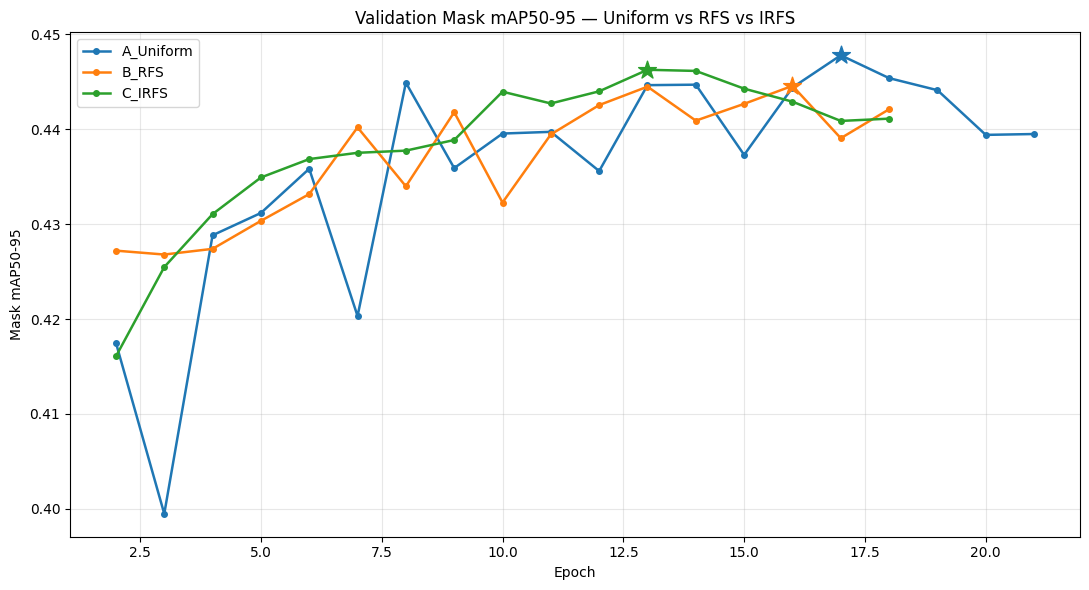


Training loss columns: ['train/box_loss', 'train/cls_loss', 'train/dfl_loss', 'train/seg_loss', 'train/sem_loss']


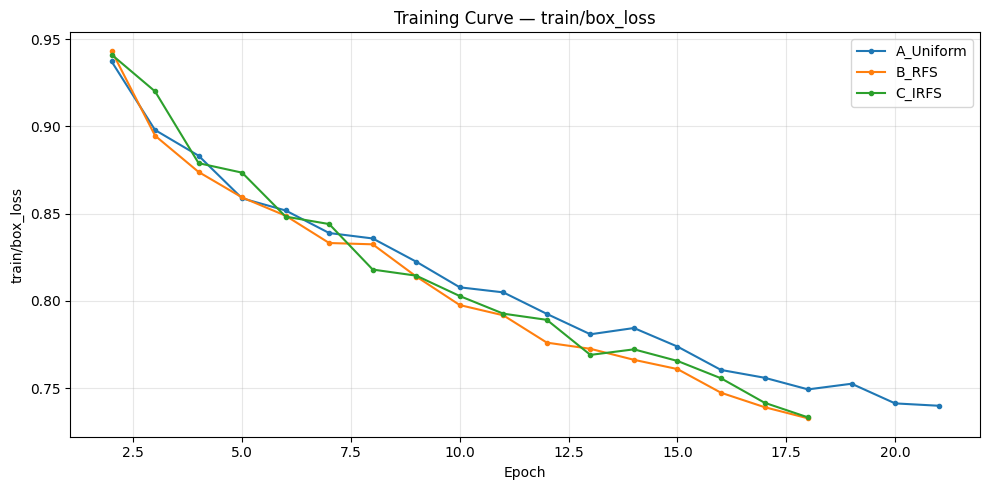

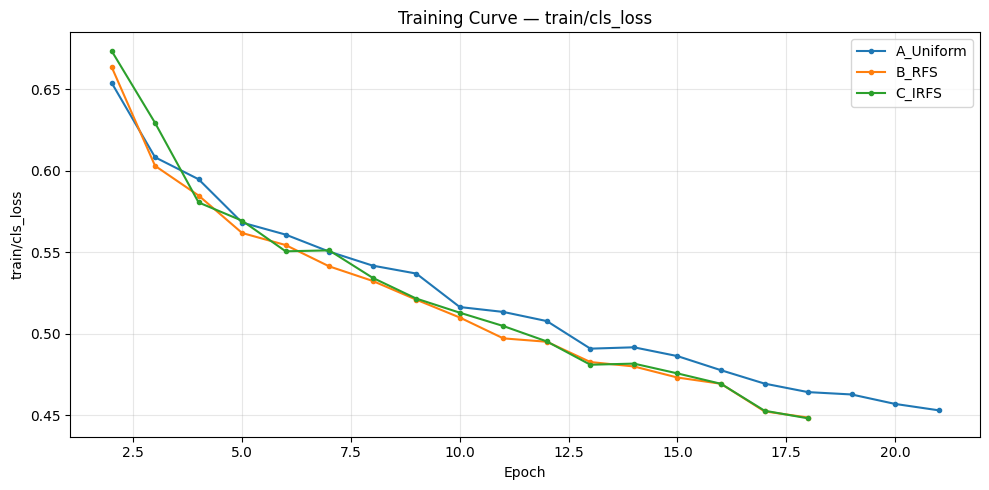

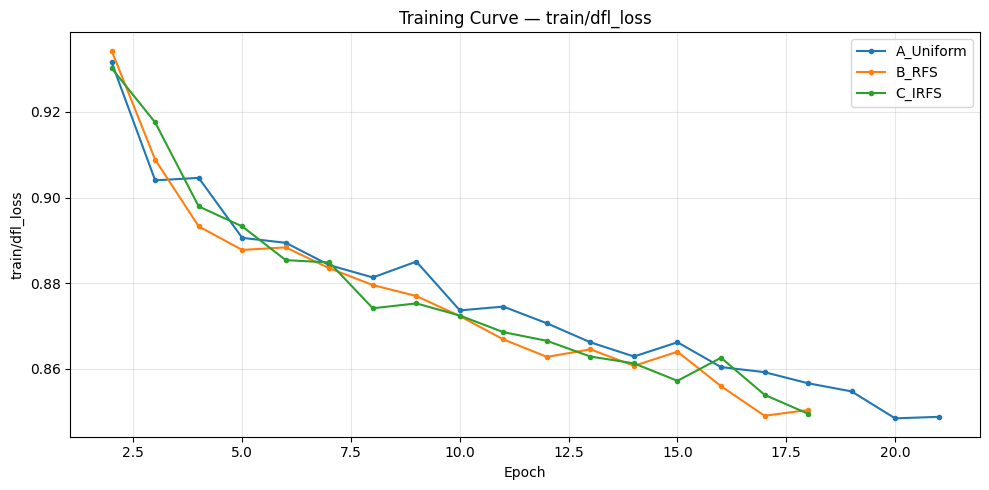

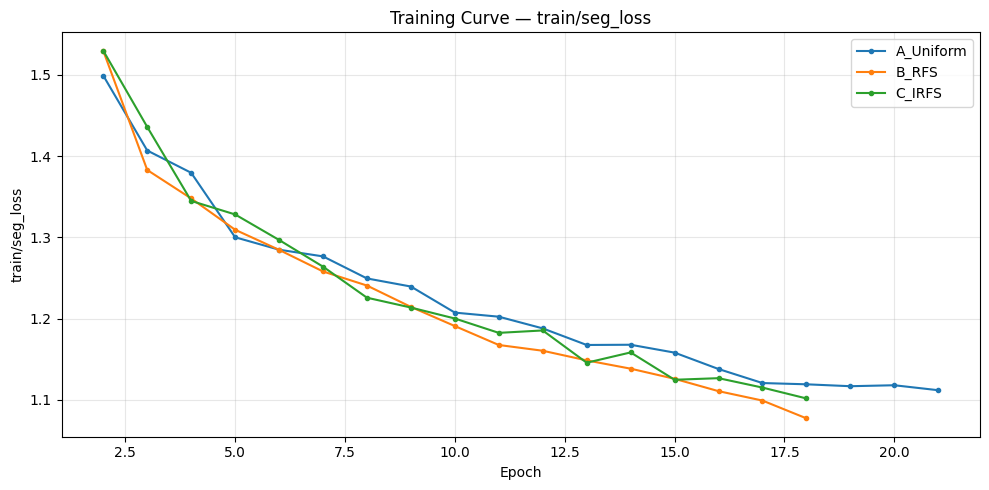

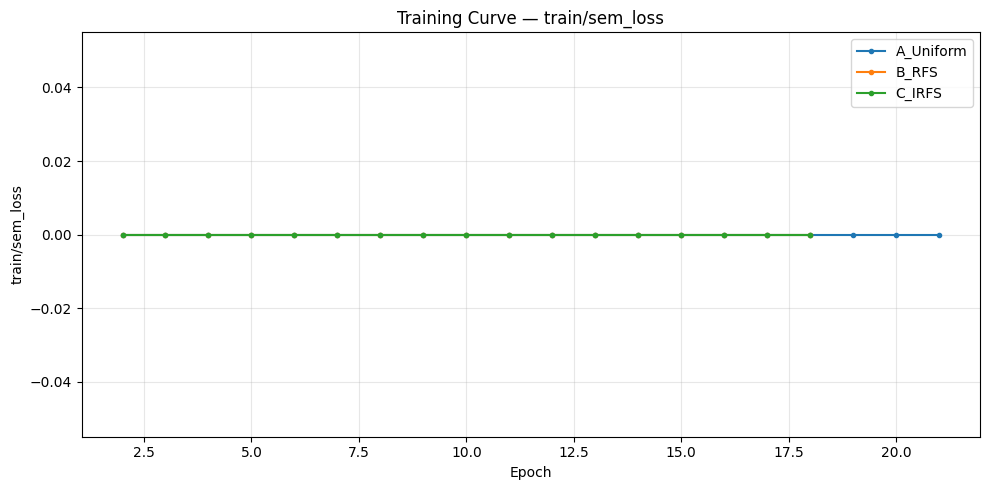


TRAINING CURVE ANALYSIS COMPLETED
Summary CSV: /content/drive/MyDrive/YOLO11_seg_expanded/research_experiments/training_curves_summary_abc.csv
mAP plot   : /content/drive/MyDrive/YOLO11_seg_expanded/research_experiments/training_curves_map50_95_abc.png


In [ ]:

# ============================================================
# CELL 38 — ANALYZE TRAINING CURVES OF A / B / C
# ============================================================

from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# 1. Đường dẫn results.csv
# ------------------------------------------------------------

RUNS = {
    "A_Uniform": RESEARCH_RUNS_DIR / "A_uniform",
    "B_RFS": RESEARCH_RUNS_DIR / "B_rfs_t080",
    "C_IRFS": RESEARCH_RUNS_DIR / "C_irfs_t030",
}

results = {}

print("=" * 75)
print("CHECKING TRAINING HISTORY")
print("=" * 75)

for name, run_dir in RUNS.items():

    csv_path = run_dir / "results.csv"

    if not csv_path.exists():
        raise FileNotFoundError(
            f"Missing results.csv for {name}:\n{csv_path}"
        )

    df = pd.read_csv(csv_path)

    # Ultralytics đôi khi có khoảng trắng trong tên cột
    df.columns = df.columns.str.strip()

    results[name] = df

    print(
        f"[OK] {name}: "
        f"{len(df)} epochs | {csv_path}"
    )

    print("Columns:", list(df.columns))
    print("-" * 75)

# ------------------------------------------------------------
# 2. Tìm cột Mask mAP50-95
# ------------------------------------------------------------

def find_mask_map_column(df):

    candidates = [
        col for col in df.columns
        if "map50-95" in col.lower()
    ]

    # Ưu tiên metric dành cho Mask (M)
    mask_candidates = [
        col for col in candidates
        if "(m)" in col.lower()
        or "mask" in col.lower()
        or "seg" in col.lower()
    ]

    if len(mask_candidates) > 0:
        return mask_candidates[0]

    # Nếu không tìm được, trả về None để tránh
    # vô tình dùng Box mAP thay cho Mask mAP.
    return None


metric_columns = {}

for name, df in results.items():

    col = find_mask_map_column(df)

    if col is None:
        print(f"[WARNING] Cannot identify Mask mAP column: {name}")
    else:
        metric_columns[name] = col
        print(f"{name}: Mask mAP column = {col}")

if len(metric_columns) != len(RUNS):
    raise RuntimeError(
        "Không tìm được Mask mAP50-95 cho cả ba experiment. "
        "Kiểm tra danh sách columns được in phía trên."
    )

# ------------------------------------------------------------
# 3. Thống kê epoch tốt nhất và epoch cuối
# ------------------------------------------------------------

summary_rows = []

for name, df in results.items():

    metric_col = metric_columns[name]

    valid_df = df.dropna(
        subset=[metric_col]
    ).copy()

    best_idx = valid_df[metric_col].idxmax()
    best_row = valid_df.loc[best_idx]
    last_row = valid_df.iloc[-1]

    epoch_col = (
        "epoch" if "epoch" in df.columns
        else None
    )

    best_epoch = (
        int(best_row[epoch_col]) + 1
        if epoch_col is not None
        else int(best_idx) + 1
    )

    last_epoch = (
        int(last_row[epoch_col]) + 1
        if epoch_col is not None
        else len(valid_df)
    )

    summary_rows.append({
        "experiment": name,
        "total_epochs": len(valid_df),
        "best_epoch": best_epoch,
        "best_mask_mAP50_95": float(
            best_row[metric_col]
        ),
        "last_epoch": last_epoch,
        "last_mask_mAP50_95": float(
            last_row[metric_col]
        ),
        "difference_best_to_last": float(
            best_row[metric_col] - last_row[metric_col]
        ),
    })

summary_df = pd.DataFrame(summary_rows)

print("\n" + "=" * 75)
print("BEST EPOCH VS LAST EPOCH")
print("=" * 75)

display(summary_df.round(5))

# ------------------------------------------------------------
# 4. Vẽ validation Mask mAP50-95
# ------------------------------------------------------------

plt.figure(figsize=(11, 6))

for name, df in results.items():

    metric_col = metric_columns[name]

    if "epoch" in df.columns:
        epochs = df["epoch"] + 1
    else:
        epochs = np.arange(1, len(df) + 1)

    plt.plot(
        epochs,
        df[metric_col],
        marker="o",
        markersize=4,
        linewidth=1.8,
        label=name,
    )

    best_idx = df[metric_col].idxmax()

    plt.scatter(
        [epochs.loc[best_idx]],
        [df.loc[best_idx, metric_col]],
        marker="*",
        s=180,
        zorder=5,
    )

plt.xlabel("Epoch")
plt.ylabel("Mask mAP50-95")
plt.title("Validation Mask mAP50-95 — Uniform vs RFS vs IRFS")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()

map_plot_path = (
    PROJECT_DIR
    / "research_experiments"
    / "training_curves_map50_95_abc.png"
)

plt.savefig(
    map_plot_path,
    dpi=160,
    bbox_inches="tight"
)

plt.show()

# ------------------------------------------------------------
# 5. Vẽ training loss
# ------------------------------------------------------------

common_loss_columns = set.intersection(
    *[
        {
            col for col in df.columns
            if col.startswith("train/")
            and "loss" in col.lower()
        }
        for df in results.values()
    ]
)

common_loss_columns = sorted(common_loss_columns)

print("\nTraining loss columns:", common_loss_columns)

for loss_col in common_loss_columns:

    plt.figure(figsize=(10, 5))

    for name, df in results.items():

        if "epoch" in df.columns:
            epochs = df["epoch"] + 1
        else:
            epochs = np.arange(1, len(df) + 1)

        plt.plot(
            epochs,
            df[loss_col],
            marker="o",
            markersize=3,
            linewidth=1.5,
            label=name,
        )

    plt.xlabel("Epoch")
    plt.ylabel(loss_col)
    plt.title(f"Training Curve — {loss_col}")
    plt.grid(True, alpha=0.3)
    plt.legend()
    plt.tight_layout()

    filename = (
        loss_col.replace("/", "_").replace(" ", "_")
        + ".png"
    )

    plt.savefig(
        PROJECT_DIR
        / "research_experiments"
        / filename,
        dpi=150,
        bbox_inches="tight"
    )

    plt.show()

# ------------------------------------------------------------
# 6. Lưu bảng thống kê
# ------------------------------------------------------------

summary_path = (
    PROJECT_DIR
    / "research_experiments"
    / "training_curves_summary_abc.csv"
)

summary_df.to_csv(
    summary_path,
    index=False
)

print("\n" + "=" * 75)
print("TRAINING CURVE ANALYSIS COMPLETED")
print("=" * 75)

print(f"Summary CSV: {summary_path}")
print(f"mAP plot   : {map_plot_path}")


In [ ]:

# ============================================================
# CELL 39 — HIGH-RESOLUTION FINE-TUNING ABLATION
#
# D0: IRFS continued training at 960
# D1: IRFS continued training at 1152
#
# Same initialization, sampler, batch, LR, seed, epochs.
# Only imgsz changes.
# ============================================================

from pathlib import Path
import gc
import json
import torch
from ultralytics import YOLO

# ------------------------------------------------------------
# 1. Initial checkpoint: best IRFS model
# ------------------------------------------------------------

START_CHECKPOINT = (
    RESEARCH_RUNS_DIR
    / "C_irfs_t030"
    / "weights"
    / "best.pt"
)

if not START_CHECKPOINT.exists():
    raise FileNotFoundError(
        f"IRFS checkpoint not found:\n{START_CHECKPOINT}"
    )

DATA_YAML = DATASET_BUILD_DIR / "data.yaml"

if not DATA_YAML.exists():
    raise FileNotFoundError(DATA_YAML)

# ------------------------------------------------------------
# 2. Verify custom IRFS trainer
# ------------------------------------------------------------

required_objects = [
    "IRFSResearchTrainer",
    "FixedLengthRepeatSampler",
    "calculate_repeat_factors_from_cache",
]

missing = [
    name for name in required_objects
    if name not in globals()
]

if missing:
    raise RuntimeError(
        f"Missing definitions: {missing}. "
        "Run the relevant cells defining the IRFS trainer first."
    )

# ------------------------------------------------------------
# 3. Experimental configurations
# ------------------------------------------------------------

EXPERIMENTS_D = [
    {
        "name": "D0_IRFS_960_control",
        "imgsz": 960,
    },
    {
        "name": "D1_IRFS_1152_highres",
        "imgsz": 1152,
    },
]

COMMON_ARGS_D = {
    "data": str(DATA_YAML),

    "epochs": 10,
    "batch": 2,
    "workers": 2,
    "device": 0,

    "optimizer": "AdamW",
    "lr0": 0.0001,
    "lrf": 0.1,
    "momentum": 0.937,
    "weight_decay": 0.0005,

    "cos_lr": True,
    "warmup_epochs": 2,

    "mask_ratio": 4,
    "overlap_mask": True,

    "mosaic": 1.0,
    "close_mosaic": 2,
    "copy_paste": 0,
    "mixup": 0,

    "amp": True,
    "cache": False,

    "seed": 42,
    "deterministic": True,

    "save": True,
    "save_period": 5,
    "plots": True,
    "val": True,

    "resume": False,
    "patience": 11,
    "verbose": True,
}

# ------------------------------------------------------------
# 4. Output directory
# ------------------------------------------------------------

OUTPUT_PROJECT = RESEARCH_RUNS_DIR

# Check that output directories do not already exist.
for experiment in EXPERIMENTS_D:

    output_dir = OUTPUT_PROJECT / experiment["name"]

    if output_dir.exists():

        best_path = output_dir / "weights" / "best.pt"
        last_path = output_dir / "weights" / "last.pt"

        if best_path.exists() and last_path.exists():
            print(
                f"[SKIP] Already completed: {experiment['name']}"
            )
        else:
            raise FileExistsError(
                f"Incomplete or existing experiment directory:\n"
                f"{output_dir}\n"
                "Inspect it before restarting. Do not overwrite it."
            )

# ------------------------------------------------------------
# 5. Save experiment design
# ------------------------------------------------------------

metadata = {
    "study": "High-resolution fine-tuning ablation",
    "initial_checkpoint": str(START_CHECKPOINT),
    "data_yaml": str(DATA_YAML),
    "sampling": "IRFS",
    "sampling_threshold": 0.30,
    "common_training_arguments": COMMON_ARGS_D,
    "experiments": EXPERIMENTS_D,
    "expected_samples_per_epoch": 1064,
    "expected_exposures_per_experiment": 10640,
    "notes": [
        "D0 and D1 start independently from the same IRFS checkpoint.",
        "Only input resolution differs between D0 and D1.",
        "Both experiments use batch size 2.",
        "Optimizer is initialized anew from the checkpoint.",
        "This is continued fine-tuning, not optimizer-state resume."
    ]
}

metadata_path = (
    OUTPUT_PROJECT / "D_high_resolution_experiment_design.json"
)

with open(metadata_path, "w", encoding="utf-8") as f:
    json.dump(metadata, f, indent=4, ensure_ascii=False)

# ------------------------------------------------------------
# 6. Run both experiments
# ------------------------------------------------------------

for experiment in EXPERIMENTS_D:

    name = experiment["name"]
    imgsz = experiment["imgsz"]

    output_dir = OUTPUT_PROJECT / name

    best_checkpoint = (
        output_dir / "weights" / "best.pt"
    )

    last_checkpoint = (
        output_dir / "weights" / "last.pt"
    )

    # Skip an experiment if both checkpoints already exist.
    if best_checkpoint.exists() and last_checkpoint.exists():

        print(f"\n[SKIP] {name} already completed.")
        continue

    print("\n" + "=" * 75)
    print(f"STARTING: {name}")
    print("=" * 75)

    print(f"Initial checkpoint : {START_CHECKPOINT}")
    print(f"Sampling           : IRFS, threshold 0.30")
    print(f"Image size         : {imgsz}")
    print(f"Batch              : {COMMON_ARGS_D['batch']}")
    print(f"Epochs             : {COMMON_ARGS_D['epochs']}")
    print(f"Learning rate      : {COMMON_ARGS_D['lr0']}")
    print(f"Expected exposures : 10,640")
    print(f"Output             : {output_dir}")

    # Load the same original C checkpoint for each branch.
    model = YOLO(str(START_CHECKPOINT))

    train_args = dict(COMMON_ARGS_D)

    train_args.update({
        "imgsz": imgsz,
        "project": str(OUTPUT_PROJECT),
        "name": name,
        "exist_ok": False,
    })

    # Custom IRFS trainer maintains the same repeat-factor sampling.
    model.train(
        trainer=IRFSResearchTrainer,
        **train_args,
    )

    # --------------------------------------------------------
    # Verify output
    # --------------------------------------------------------

    if not best_checkpoint.exists():
        raise RuntimeError(
            f"Training did not produce best.pt:\n{best_checkpoint}"
        )

    if not last_checkpoint.exists():
        raise RuntimeError(
            f"Training did not produce last.pt:\n{last_checkpoint}"
        )

    print(f"\n[COMPLETED] {name}")
    print(f"Best: {best_checkpoint}")
    print(f"Last: {last_checkpoint}")

    del model
    gc.collect()

    if torch.cuda.is_available():
        torch.cuda.empty_cache()

# ------------------------------------------------------------
# 7. Final verification
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("HIGH-RESOLUTION ABLATION — OUTPUT VERIFICATION")
print("=" * 75)

for experiment in EXPERIMENTS_D:

    name = experiment["name"]

    best_path = (
        OUTPUT_PROJECT
        / name
        / "weights"
        / "best.pt"
    )

    last_path = (
        OUTPUT_PROJECT
        / name
        / "weights"
        / "last.pt"
    )

    print(
        f"{name}: "
        f"best={'OK' if best_path.exists() else 'MISSING'}, "
        f"last={'OK' if last_path.exists() else 'MISSING'}"
    )

print(f"\nExperiment design: {metadata_path}")
print("\n[CELL 39 FINISHED]")



STARTING: D0_IRFS_960_control
Initial checkpoint : /content/drive/MyDrive/YOLO11_seg_expanded/research_experiments/C_irfs_t030/weights/best.pt
Sampling           : IRFS, threshold 0.30
Image size         : 960
Batch              : 2
Epochs             : 10
Learning rate      : 0.0001
Expected exposures : 10,640
Output             : /content/drive/MyDrive/YOLO11_seg_expanded/research_experiments/D0_IRFS_960_control
Ultralytics 8.4.193 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=2, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=2, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0, copy_paste_mode=flip, cos_lr=True, cutmix=0.0, data=/content/yolo11_seg_expanded_dataset_v1/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=Fal

In [ ]:

# ============================================================
# CELL 40 — CROSS-RESOLUTION EVALUATION
#
# Compare:
# C  : Original IRFS checkpoint, trained at 960
# D0 : Continued IRFS, trained at 960
# D1 : Continued IRFS, trained at 1152
#
# Evaluate every checkpoint at both 960 and 1152.
# ============================================================

from pathlib import Path
import json
import gc
import numpy as np
import pandas as pd
import torch
from ultralytics import YOLO

# ------------------------------------------------------------
# 1. Checkpoints
# ------------------------------------------------------------

CHECKPOINTS_D = {
    "C_IRFS_original": {
        "path": (
            RESEARCH_RUNS_DIR
            / "C_irfs_t030"
            / "weights"
            / "best.pt"
        ),
        "train_imgsz": 960,
    },

    "D0_IRFS_960": {
        "path": (
            RESEARCH_RUNS_DIR
            / "D0_IRFS_960_control"
            / "weights"
            / "best.pt"
        ),
        "train_imgsz": 960,
    },

    "D1_IRFS_1152": {
        "path": (
            RESEARCH_RUNS_DIR
            / "D1_IRFS_1152_highres"
            / "weights"
            / "best.pt"
        ),
        "train_imgsz": 1152,
    },
}

EVAL_SIZES = [960, 1152]

DATASETS_D = {
    "Combined_268": DATASET_BUILD_DIR / "data.yaml",
    "Old_119": OLD_VAL_YAML,
    "New_149": NEW_VAL_YAML,
}

# ------------------------------------------------------------
# 2. Check all files
# ------------------------------------------------------------

print("=" * 75)
print("CHECKING CHECKPOINTS")
print("=" * 75)

for name, config in CHECKPOINTS_D.items():

    path = config["path"]

    print(f"[{'OK' if path.exists() else 'MISSING'}] {name}: {path}")

    if not path.exists():
        raise FileNotFoundError(path)

for name, path in DATASETS_D.items():

    print(f"[{'OK' if path.exists() else 'MISSING'}] {name}: {path}")

    if not path.exists():
        raise FileNotFoundError(path)

# ------------------------------------------------------------
# 3. Output directory
# ------------------------------------------------------------

OUTPUT_DIR_D = (
    PROJECT_DIR
    / "research_experiments"
    / "D_cross_resolution_evaluation_v1"
)

if OUTPUT_DIR_D.exists():
    raise FileExistsError(
        f"Output directory already exists:\n{OUTPUT_DIR_D}\n"
        "Không ghi đè kết quả cũ."
    )

OUTPUT_DIR_D.mkdir(
    parents=True,
    exist_ok=False
)

# ------------------------------------------------------------
# 4. Identical evaluation settings
# ------------------------------------------------------------

EVAL_ARGS_D = {
    "batch": 2,
    "device": 0,
    "workers": 2,
    "conf": 0.001,
    "iou": 0.7,
    "max_det": 300,
    "rect": True,
    "plots": False,
    "verbose": False,
}

# ------------------------------------------------------------
# 5. Storage
# ------------------------------------------------------------

overall_rows = []
class_rows = []

# ------------------------------------------------------------
# 6. Cross-resolution evaluation
# ------------------------------------------------------------

total_runs = (
    len(CHECKPOINTS_D)
    * len(EVAL_SIZES)
    * len(DATASETS_D)
)

run_counter = 0

for checkpoint_name, checkpoint_config in CHECKPOINTS_D.items():

    checkpoint_path = checkpoint_config["path"]
    train_imgsz = checkpoint_config["train_imgsz"]

    print("\n" + "=" * 75)
    print(f"CHECKPOINT: {checkpoint_name}")
    print(f"Training resolution: {train_imgsz}")
    print("=" * 75)

    model = YOLO(str(checkpoint_path))

    for eval_imgsz in EVAL_SIZES:

        for dataset_name, dataset_yaml in DATASETS_D.items():

            run_counter += 1

            run_name = (
                f"{checkpoint_name}_"
                f"{dataset_name}_"
                f"eval{eval_imgsz}"
            )

            print("\n" + "-" * 75)
            print(
                f"RUN {run_counter}/{total_runs}: {run_name}"
            )
            print("-" * 75)

            metrics = model.val(
                data=str(dataset_yaml),
                imgsz=eval_imgsz,
                project=str(OUTPUT_DIR_D),
                name=run_name,
                exist_ok=False,
                **EVAL_ARGS_D,
            )

            # --------------------------------------------
            # Overall mask metrics
            # --------------------------------------------

            seg = metrics.seg

            speed = metrics.speed

            overall_rows.append({
                "checkpoint": checkpoint_name,
                "train_imgsz": train_imgsz,
                "eval_imgsz": eval_imgsz,
                "dataset": dataset_name,
                "precision": float(seg.mp),
                "recall": float(seg.mr),
                "mAP50": float(seg.map50),
                "mAP75": float(seg.map75),
                "mAP50-95": float(seg.map),
                "inference_ms": float(
                    speed.get("inference", np.nan)
                ),
            })

            # --------------------------------------------
            # Per-class mask AP50-95
            # --------------------------------------------

            class_maps = np.asarray(
                seg.maps
            ).reshape(-1)

            model_names = model.names

            for class_id, class_ap in enumerate(class_maps):

                if isinstance(model_names, dict):
                    class_name = model_names.get(
                        class_id,
                        str(class_id)
                    )
                else:
                    class_name = model_names[class_id]

                class_rows.append({
                    "checkpoint": checkpoint_name,
                    "train_imgsz": train_imgsz,
                    "eval_imgsz": eval_imgsz,
                    "dataset": dataset_name,
                    "class_id": class_id,
                    "class_name": class_name,
                    "mask_AP50-95": float(class_ap),
                })

            print(
                f"Mask mAP50-95: {seg.map:.4f}"
            )

    del model
    gc.collect()

    if torch.cuda.is_available():
        torch.cuda.empty_cache()

# ------------------------------------------------------------
# 7. Build DataFrames
# ------------------------------------------------------------

overall_df = pd.DataFrame(overall_rows)
class_df = pd.DataFrame(class_rows)

# ------------------------------------------------------------
# 8. Extract Combined results
# ------------------------------------------------------------

combined_df = overall_df[
    overall_df["dataset"] == "Combined_268"
].copy()

combined_df = combined_df.sort_values(
    ["eval_imgsz", "checkpoint"]
).reset_index(drop=True)

# ------------------------------------------------------------
# 9. Comparison D1 vs D0 at same evaluation resolution
# ------------------------------------------------------------

comparison_rows = []

for eval_size in EVAL_SIZES:

    subset = combined_df[
        combined_df["eval_imgsz"] == eval_size
    ].set_index("checkpoint")

    for metric in [
        "precision",
        "recall",
        "mAP50",
        "mAP75",
        "mAP50-95",
    ]:

        c_val = subset.loc[
            "C_IRFS_original", metric
        ]

        d0_val = subset.loc[
            "D0_IRFS_960", metric
        ]

        d1_val = subset.loc[
            "D1_IRFS_1152", metric
        ]

        comparison_rows.append({
            "eval_imgsz": eval_size,
            "metric": metric,
            "C_original": c_val,
            "D0_960": d0_val,
            "D1_1152": d1_val,
            "D0_minus_C": d0_val - c_val,
            "D1_minus_D0": d1_val - d0_val,
        })

comparison_df = pd.DataFrame(comparison_rows)

# ------------------------------------------------------------
# 10. Per-class comparison on Combined_268
# ------------------------------------------------------------

class_combined = class_df[
    class_df["dataset"] == "Combined_268"
].copy()

class_pivot = class_combined.pivot(
    index=["eval_imgsz", "class_name"],
    columns="checkpoint",
    values="mask_AP50-95",
).reset_index()

class_pivot["D0_minus_C"] = (
    class_pivot["D0_IRFS_960"]
    - class_pivot["C_IRFS_original"]
)

class_pivot["D1_minus_D0"] = (
    class_pivot["D1_IRFS_1152"]
    - class_pivot["D0_IRFS_960"]
)

# ------------------------------------------------------------
# 11. Save CSVs
# ------------------------------------------------------------

overall_df.to_csv(
    OUTPUT_DIR_D / "cross_resolution_overall.csv",
    index=False
)

class_df.to_csv(
    OUTPUT_DIR_D / "cross_resolution_per_class.csv",
    index=False
)

comparison_df.to_csv(
    OUTPUT_DIR_D / "cross_resolution_comparison.csv",
    index=False
)

class_pivot.to_csv(
    OUTPUT_DIR_D / "cross_resolution_class_comparison.csv",
    index=False
)

# ------------------------------------------------------------
# 12. Save JSON
# ------------------------------------------------------------

json_data = {
    "checkpoints": {
        name: {
            "path": str(config["path"]),
            "training_imgsz": config["train_imgsz"],
        }
        for name, config in CHECKPOINTS_D.items()
    },
    "evaluation_imgsz": EVAL_SIZES,
    "evaluation_args": EVAL_ARGS_D,
    "datasets": {
        name: str(path)
        for name, path in DATASETS_D.items()
    },
    "overall_results": overall_rows,
    "per_class_results": class_rows,
}

with open(
    OUTPUT_DIR_D / "cross_resolution_results.json",
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        json_data,
        f,
        indent=4,
        ensure_ascii=False
    )

# ------------------------------------------------------------
# 13. Display
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("1. COMBINED_268 — ALL CROSS-RESOLUTION RESULTS")
print("=" * 75)

display(
    combined_df.round(5)
)

print("\n" + "=" * 75)
print("2. COMPARISON D0 vs D1 AT THE SAME EVALUATION RESOLUTION")
print("=" * 75)

display(
    comparison_df.round(5)
)

print("\n" + "=" * 75)
print("3. PER-CLASS MASK AP50-95")
print("=" * 75)

display(
    class_pivot.round(5)
)

print("\n" + "=" * 75)
print("4. ALL VALIDATION SPLITS")
print("=" * 75)

display(
    overall_df.round(5)
)

print("\n" + "=" * 75)
print("CROSS-RESOLUTION EVALUATION COMPLETED")
print("=" * 75)

print(f"Output: {OUTPUT_DIR_D}")
print("Training started: NO")


CHECKING CHECKPOINTS
[OK] C_IRFS_original: /content/drive/MyDrive/YOLO11_seg_expanded/research_experiments/C_irfs_t030/weights/best.pt
[OK] D0_IRFS_960: /content/drive/MyDrive/YOLO11_seg_expanded/research_experiments/D0_IRFS_960_control/weights/best.pt
[OK] D1_IRFS_1152: /content/drive/MyDrive/YOLO11_seg_expanded/research_experiments/D1_IRFS_1152_highres/weights/best.pt
[OK] Combined_268: /content/yolo11_seg_expanded_dataset_v1/data.yaml
[OK] Old_119: /content/yolo11_seg_expanded_dataset_v1/old_validation.yaml
[OK] New_149: /content/yolo11_seg_expanded_dataset_v1/new_validation.yaml

CHECKPOINT: C_IRFS_original
Training resolution: 960

---------------------------------------------------------------------------
RUN 1/18: C_IRFS_original_Combined_268_eval960
---------------------------------------------------------------------------
Ultralytics 8.4.193 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11s-seg summary (fused): 113 layers, 10,069,138 parameters, 0 gradie

,checkpoint,train_imgsz,eval_imgsz,dataset,precision,recall,mAP50,mAP75,mAP50-95,inference_ms
0,C_IRFS_original,960,960,Combined_268,0.83735,0.64251,0.72053,0.43916,0.43780,27.84451
1,D0_IRFS_960,960,960,Combined_268,0.79252,0.65510,0.70929,0.43017,0.43389,22.92843
2,D1_IRFS_1152,1152,960,Combined_268,0.80632,0.66638,0.71094,0.44170,0.43712,23.25199
3,C_IRFS_original,960,1152,Combined_268,0.80662,0.68269,0.74011,0.47409,0.46356,39.06206
4,D0_IRFS_960,960,1152,Combined_268,0.80501,0.66282,0.73001,0.46947,0.46194,36.53874
5,D1_IRFS_1152,1152,1152,Combined_268,0.80443,0.68368,0.73419,0.46758,0.46155,36.90200



2. COMPARISON D0 vs D1 AT THE SAME EVALUATION RESOLUTION


,eval_imgsz,metric,C_original,D0_960,D1_1152,D0_minus_C,D1_minus_D0
0,960,precision,0.83735,0.79252,0.80632,-0.04483,0.01380
1,960,recall,0.64251,0.65510,0.66638,0.01259,0.01129
2,960,mAP50,0.72053,0.70929,0.71094,-0.01125,0.00166
3,960,mAP75,0.43916,0.43017,0.44170,-0.00899,0.01154
4,960,mAP50-95,0.43780,0.43389,0.43712,-0.00391,0.00323
5,1152,precision,0.80662,0.80501,0.80443,-0.00161,-0.00057
6,1152,recall,0.68269,0.66282,0.68368,-0.01988,0.02086
7,1152,mAP50,0.74011,0.73001,0.73419,-0.01010,0.00418
8,1152,mAP75,0.47409,0.46947,0.46758,-0.00462,-0.00189
9,1152,mAP50-95,0.46356,0.46194,0.46155,-0.00163,-0.00039



3. PER-CLASS MASK AP50-95


checkpoint,eval_imgsz,class_name,C_IRFS_original,D0_IRFS_960,D1_IRFS_1152,D0_minus_C,D1_minus_D0
0,960,gloves,0.28579,0.28222,0.29874,-0.00358,0.01652
1,960,hat,0.58220,0.57642,0.57789,-0.00578,0.00147
2,960,long-sleeved shirt,0.64633,0.64006,0.63895,-0.00627,-0.00112
3,960,mask,0.41554,0.42146,0.41546,0.00592,-0.00600
4,960,pants,0.49407,0.47243,0.47428,-0.02163,0.00184
5,960,shoes,0.20285,0.21074,0.21739,0.00788,0.00666
6,1152,gloves,0.30299,0.30395,0.30825,0.00096,0.00430
7,1152,hat,0.60852,0.60765,0.60045,-0.00086,-0.00720
8,1152,long-sleeved shirt,0.65447,0.65758,0.65831,0.00311,0.00073
9,1152,mask,0.45721,0.45810,0.44863,0.00089,-0.00947



4. ALL VALIDATION SPLITS


,checkpoint,train_imgsz,eval_imgsz,dataset,precision,recall,mAP50,mAP75,mAP50-95,inference_ms
0,C_IRFS_original,960,960,Combined_268,0.83735,0.64251,0.72053,0.43916,0.43780,27.84451
1,C_IRFS_original,960,960,Old_119,0.82847,0.63461,0.72427,0.42649,0.42437,24.13221
2,C_IRFS_original,960,960,New_149,0.82120,0.66183,0.69771,0.44027,0.44042,23.90412
3,C_IRFS_original,960,1152,Combined_268,0.80662,0.68269,0.74011,0.47409,0.46356,39.06206
4,C_IRFS_original,960,1152,Old_119,0.80865,0.65623,0.73156,0.46315,0.44492,38.04361
5,C_IRFS_original,960,1152,New_149,0.84017,0.68223,0.73557,0.46788,0.46991,36.98498
6,D0_IRFS_960,960,960,Combined_268,0.79252,0.65510,0.70929,0.43017,0.43389,22.92843
7,D0_IRFS_960,960,960,Old_119,0.81928,0.63028,0.71567,0.41554,0.42180,22.77655
8,D0_IRFS_960,960,960,New_149,0.82968,0.65074,0.68626,0.42966,0.43513,22.62971
9,D0_IRFS_960,960,1152,Combined_268,0.80501,0.66282,0.73001,0.46947,0.46194,36.53874



CROSS-RESOLUTION EVALUATION COMPLETED
Output: /content/drive/MyDrive/YOLO11_seg_expanded/research_experiments/D_cross_resolution_evaluation_v1
Training started: NO


In [ ]:

# ============================================================
# CELL 41 — EXPERIMENT E: INFERENCE RESOLUTION OPTIMIZATION
#
# Checkpoint: C_IRFS_original
# Resolutions: 960 / 1152 / 1280
# Repetitions: 2
# Training: NO
# ============================================================

from pathlib import Path
import json
import gc
import time
import numpy as np
import pandas as pd
import torch

from ultralytics import YOLO

# ------------------------------------------------------------
# 1. CHECKPOINT
# ------------------------------------------------------------

CHECKPOINT_E = (
    RESEARCH_RUNS_DIR
    / "C_irfs_t030"
    / "weights"
    / "best.pt"
)

DATA_YAML_E = DATASET_BUILD_DIR / "data.yaml"

if not CHECKPOINT_E.exists():
    raise FileNotFoundError(CHECKPOINT_E)

if not DATA_YAML_E.exists():
    raise FileNotFoundError(DATA_YAML_E)

print("=" * 75)
print("EXPERIMENT E — INFERENCE RESOLUTION OPTIMIZATION")
print("=" * 75)

print(f"Checkpoint: {CHECKPOINT_E}")
print(f"Dataset   : {DATA_YAML_E}")

# ------------------------------------------------------------
# 2. CONFIGURATION
# ------------------------------------------------------------

EVAL_SIZES = [960, 1152, 1280]

N_REPEATS = 2

EVAL_ARGS_E = {
    "data": str(DATA_YAML_E),
    "batch": 2,
    "device": 0,
    "workers": 2,

    "conf": 0.001,
    "iou": 0.7,
    "max_det": 300,

    # Giữ giống Cell 40
    "rect": True,

    "plots": False,
    "verbose": False,
}

# ------------------------------------------------------------
# 3. OUTPUT DIRECTORY
# ------------------------------------------------------------

OUTPUT_DIR_E = (
    PROJECT_DIR
    / "research_experiments"
    / "E_inference_resolution_optimization_v1"
)

if OUTPUT_DIR_E.exists():
    raise FileExistsError(
        f"Output directory already exists:\n"
        f"{OUTPUT_DIR_E}\n"
        "Không ghi đè kết quả cũ. "
        "Hãy đổi tên OUTPUT_DIR_E nếu muốn chạy lại."
    )

OUTPUT_DIR_E.mkdir(
    parents=True,
    exist_ok=False
)

# ------------------------------------------------------------
# 4. LOAD MODEL
# ------------------------------------------------------------

model = YOLO(str(CHECKPOINT_E))

if model.task != "segment":
    raise RuntimeError(
        f"Expected segmentation model, got: {model.task}"
    )

print("\nModel loaded successfully.")
print("Model names:", model.names)

# ------------------------------------------------------------
# 5. EVALUATE EACH RESOLUTION
# ------------------------------------------------------------

overall_rows = []
class_rows = []

total_runs = len(EVAL_SIZES) * N_REPEATS
run_counter = 0

for imgsz in EVAL_SIZES:

    print("\n" + "=" * 75)
    print(f"INFERENCE RESOLUTION: {imgsz}")
    print("=" * 75)

    for repeat in range(1, N_REPEATS + 1):

        run_counter += 1

        run_name = (
            f"imgsz_{imgsz}_repeat_{repeat}"
        )

        print(
            f"\nRun {run_counter}/{total_runs}: "
            f"{run_name}"
        )

        if torch.cuda.is_available():
            torch.cuda.empty_cache()

        start_time = time.perf_counter()

        metrics = model.val(
            imgsz=imgsz,
            project=str(OUTPUT_DIR_E),
            name=run_name,
            exist_ok=False,
            **EVAL_ARGS_E,
        )

        wall_time = time.perf_counter() - start_time

        # --------------------------------------------
        # Overall segmentation metrics
        # --------------------------------------------

        seg = metrics.seg
        speed = metrics.speed

        preprocess_ms = float(
            speed.get("preprocess", np.nan)
        )

        inference_ms = float(
            speed.get("inference", np.nan)
        )

        postprocess_ms = float(
            speed.get("postprocess", np.nan)
        )

        pipeline_ms = (
            preprocess_ms
            + inference_ms
            + postprocess_ms
        )

        overall_rows.append({
            "imgsz": imgsz,
            "repeat": repeat,

            "precision": float(seg.mp),
            "recall": float(seg.mr),
            "mAP50": float(seg.map50),
            "mAP75": float(seg.map75),
            "mAP50-95": float(seg.map),

            "preprocess_ms": preprocess_ms,
            "inference_ms": inference_ms,
            "postprocess_ms": postprocess_ms,

            "pipeline_ms": pipeline_ms,

            "inference_FPS": (
                1000.0 / inference_ms
                if inference_ms > 0
                else np.nan
            ),

            "pipeline_FPS": (
                1000.0 / pipeline_ms
                if pipeline_ms > 0
                else np.nan
            ),

            "wall_time_seconds": wall_time,
        })

        # --------------------------------------------
        # Per-class Mask AP50-95
        # --------------------------------------------

        class_maps = np.asarray(
            seg.maps
        ).reshape(-1)

        model_names = model.names

        for class_id, class_ap in enumerate(class_maps):

            if isinstance(model_names, dict):
                class_name = model_names.get(
                    class_id,
                    str(class_id)
                )
            else:
                class_name = model_names[class_id]

            class_rows.append({
                "imgsz": imgsz,
                "repeat": repeat,
                "class_id": class_id,
                "class_name": class_name,
                "mask_AP50-95": float(class_ap),
            })

        print(
            f"Mask mAP50-95: {seg.map:.5f} | "
            f"Inference: {inference_ms:.2f} ms/image | "
            f"Pipeline: {pipeline_ms:.2f} ms/image"
        )

        del metrics
        gc.collect()

        if torch.cuda.is_available():
            torch.cuda.empty_cache()

# ------------------------------------------------------------
# 6. BUILD DATAFRAMES
# ------------------------------------------------------------

overall_df = pd.DataFrame(overall_rows)
class_df = pd.DataFrame(class_rows)

# ------------------------------------------------------------
# 7. AGGREGATE RESULTS
# ------------------------------------------------------------

summary_df = (
    overall_df
    .groupby("imgsz")
    .agg({
        "precision": "mean",
        "recall": "mean",
        "mAP50": "mean",
        "mAP75": "mean",
        "mAP50-95": "mean",

        "preprocess_ms": "median",
        "inference_ms": "median",
        "postprocess_ms": "median",
        "pipeline_ms": "median",

        "inference_FPS": "median",
        "pipeline_FPS": "median",
        "wall_time_seconds": "median",
    })
    .reset_index()
)

# --------------------------------------------
# 7.1 Per-class average
# --------------------------------------------

class_summary_df = (
    class_df
    .groupby(["imgsz", "class_name"])["mask_AP50-95"]
    .mean()
    .reset_index()
)

class_pivot_df = class_summary_df.pivot(
    index="class_name",
    columns="imgsz",
    values="mask_AP50-95",
)

class_pivot_df = class_pivot_df.reindex([
    "hat",
    "gloves",
    "mask",
    "pants",
    "shoes",
    "long-sleeved shirt",
])

class_pivot_df.columns = [
    f"AP50-95_{int(col)}"
    for col in class_pivot_df.columns
]

class_pivot_df = class_pivot_df.reset_index()

# ------------------------------------------------------------
# 8. DELTA ANALYSIS VS 960
# ------------------------------------------------------------

baseline = summary_df[
    summary_df["imgsz"] == 960
]

if len(baseline) != 1:
    raise RuntimeError(
        "Cannot identify 960 baseline."
    )

baseline_map = float(
    baseline.iloc[0]["mAP50-95"]
)

baseline_pipeline_fps = float(
    baseline.iloc[0]["pipeline_FPS"]
)

summary_df["mAP50-95_delta"] = (
    summary_df["mAP50-95"] - baseline_map
)

summary_df["mAP50-95_relative_change_pct"] = (
    summary_df["mAP50-95_delta"]
    / baseline_map
    * 100
)

summary_df["pipeline_FPS_relative_change_pct"] = (
    (
        summary_df["pipeline_FPS"]
        / baseline_pipeline_fps
    ) - 1
) * 100

# ------------------------------------------------------------
# 9. SAVE RESULTS
# ------------------------------------------------------------

overall_df.to_csv(
    OUTPUT_DIR_E / "individual_evaluation_runs.csv",
    index=False
)

class_df.to_csv(
    OUTPUT_DIR_E / "individual_per_class_results.csv",
    index=False
)

summary_df.to_csv(
    OUTPUT_DIR_E / "resolution_summary.csv",
    index=False
)

class_pivot_df.to_csv(
    OUTPUT_DIR_E / "per_class_resolution_comparison.csv",
    index=False
)

result_json = {
    "experiment": "Inference Resolution Optimization",
    "checkpoint": str(CHECKPOINT_E),
    "dataset": str(DATA_YAML_E),
    "evaluation_sizes": EVAL_SIZES,
    "repeats": N_REPEATS,
    "evaluation_configuration": EVAL_ARGS_E,

    "individual_runs": overall_rows,
    "per_class_results": class_rows,

    "summary": summary_df.to_dict(
        orient="records"
    ),
}

with open(
    OUTPUT_DIR_E / "inference_resolution_results.json",
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        result_json,
        f,
        indent=4,
        ensure_ascii=False
    )

# ------------------------------------------------------------
# 10. DISPLAY RESULTS
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("1. RESOLUTION SUMMARY")
print("=" * 75)

display(
    summary_df.round(5)
)

print("\n" + "=" * 75)
print("2. PER-CLASS MASK AP50-95")
print("=" * 75)

display(
    class_pivot_df.round(5)
)

print("\n" + "=" * 75)
print("3. INDIVIDUAL RUNS")
print("=" * 75)

display(
    overall_df.round(5)
)

# ------------------------------------------------------------
# 11. RECOMMENDATION BY SIMPLE ACCURACY/SPEED VIEW
# ------------------------------------------------------------

best_accuracy_row = summary_df.loc[
    summary_df["mAP50-95"].idxmax()
]

best_speed_row = summary_df.loc[
    summary_df["pipeline_FPS"].idxmax()
]

print("\n" + "=" * 75)
print("BENCHMARK CONCLUSION")
print("=" * 75)

print(
    f"Highest mAP50-95: imgsz={int(best_accuracy_row['imgsz'])}, "
    f"mAP50-95={best_accuracy_row['mAP50-95']:.5f}"
)

print(
    f"Highest pipeline FPS: imgsz={int(best_speed_row['imgsz'])}, "
    f"FPS={best_speed_row['pipeline_FPS']:.2f}"
)

print(f"\nOutput directory: {OUTPUT_DIR_E}")

print("\nTraining started: NO")
print("[COMPLETED] Experiment E")


EXPERIMENT E — INFERENCE RESOLUTION OPTIMIZATION
Checkpoint: /content/drive/MyDrive/YOLO11_seg_expanded/research_experiments/C_irfs_t030/weights/best.pt
Dataset   : /content/yolo11_seg_expanded_dataset_v1/data.yaml

Model loaded successfully.
Model names: {0: 'hat', 1: 'gloves', 2: 'mask', 3: 'pants', 4: 'shoes', 5: 'long-sleeved shirt'}

INFERENCE RESOLUTION: 960

Run 1/6: imgsz_960_repeat_1
Ultralytics 8.4.193 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11s-seg summary (fused): 113 layers, 10,069,138 parameters, 0 gradients, 32.9 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2857.5±618.2 MB/s, size: 328.3 KB)
val: Scanning /content/yolo11_seg_expanded_dataset_v1/labels/val/new/job67/batch_012... 268 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 268/268 678.1it/s 0.4s
val: New cache created: /content/yolo11_seg_expanded_dataset_v1/labels/val/new/job67/batch_012.cache
                 Class     Images  Instances      Box(P          R      mAP50 

,imgsz,precision,recall,mAP50,mAP75,mAP50-95,preprocess_ms,inference_ms,postprocess_ms,pipeline_ms,inference_FPS,pipeline_FPS,wall_time_seconds,mAP50-95_delta,mAP50-95_relative_change_pct,pipeline_FPS_relative_change_pct
0,960,0.83735,0.64251,0.72053,0.43916,0.43780,2.55155,24.58104,3.88763,31.02022,40.69249,32.27385,12.94021,0.00000,0.00000,0.00000
1,1152,0.80662,0.68269,0.74011,0.47409,0.46356,1.95032,38.18835,2.55149,42.69016,26.18898,23.42573,14.03866,0.02577,5.88569,-27.41575
2,1280,0.82089,0.66962,0.73660,0.48721,0.47342,2.32487,42.68806,2.65719,47.67013,23.42802,20.97829,15.51050,0.03562,8.13598,-34.99911



2. PER-CLASS MASK AP50-95


,class_name,AP50-95_960,AP50-95_1152,AP50-95_1280
0,hat,0.58220,0.60852,0.63604
1,gloves,0.28579,0.30299,0.30232
2,mask,0.41554,0.45721,0.47233
3,pants,0.49407,0.51111,0.51631
4,shoes,0.20285,0.24709,0.26050
5,long-sleeved shirt,0.64633,0.65447,0.65298



3. INDIVIDUAL RUNS


,imgsz,repeat,precision,recall,mAP50,mAP75,mAP50-95,preprocess_ms,inference_ms,postprocess_ms,pipeline_ms,inference_FPS,pipeline_FPS,wall_time_seconds
0,960,1,0.83735,0.64251,0.72053,0.43916,0.43780,2.77973,24.98015,4.30801,32.06790,40.03178,31.18384,13.82821
1,960,2,0.83735,0.64251,0.72053,0.43916,0.43780,2.32338,24.18192,3.46725,29.97255,41.35320,33.36387,12.05220
2,1152,1,0.80662,0.68269,0.74011,0.47409,0.46356,1.89434,38.59550,2.49681,42.98665,25.90975,23.26303,14.10773
3,1152,2,0.80662,0.68269,0.74011,0.47409,0.46356,2.00630,37.78119,2.60617,42.39367,26.46820,23.58843,13.96959
4,1280,1,0.82089,0.66962,0.73660,0.48721,0.47342,2.23739,43.10811,2.61736,47.96286,23.19749,20.84947,15.58006
5,1280,2,0.82089,0.66962,0.73660,0.48721,0.47342,2.41235,42.26802,2.69702,47.37739,23.65855,21.10711,15.44094



BENCHMARK CONCLUSION
Highest mAP50-95: imgsz=1280, mAP50-95=0.47342
Highest pipeline FPS: imgsz=960, FPS=32.27

Output directory: /content/drive/MyDrive/YOLO11_seg_expanded/research_experiments/E_inference_resolution_optimization_v1

Training started: NO
[COMPLETED] Experiment E


In [ ]:

# ============================================================
# FIX — MOUNT GOOGLE DRIVE AND LOCATE PROJECT
# ============================================================

from google.colab import drive
from pathlib import Path
import os

# 1. Mount Google Drive
drive.mount("/content/drive")

# 2. Kiểm tra MyDrive
MYDRIVE = Path("/content/drive/MyDrive")

if not MYDRIVE.exists():
    raise RuntimeError(
        "Google Drive chưa được mount đúng cách."
    )

print("=" * 70)
print("GOOGLE DRIVE CONNECTED")
print("=" * 70)

# 3. Tìm thư mục dự án tại vị trí quen thuộc
EXPECTED_PROJECT = (
    MYDRIVE / "YOLO11_seg_expanded"
)

if EXPECTED_PROJECT.exists():

    PROJECT_DIR = EXPECTED_PROJECT

    print("[OK] Found project at expected location.")

else:

    # Tìm thư mục cùng tên nếu dự án nằm trong thư mục con.
    print("[INFO] Searching for project folder...")

    candidates = []

    for current_root, dirs, files in os.walk(MYDRIVE):

        current_path = Path(current_root)

        # Không tìm sâu quá 4 cấp.
        depth = len(current_path.relative_to(MYDRIVE).parts)

        if depth >= 4:
            dirs[:] = []

        # Bỏ qua thư mục ẩn và thùng rác.
        dirs[:] = [
            d for d in dirs
            if not d.startswith(".")
        ]

        if current_path.name == "YOLO11_seg_expanded":

            candidates.append(current_path)

            # Không cần tìm bên trong dự án.
            dirs[:] = []

    if len(candidates) == 1:

        PROJECT_DIR = candidates[0]

        print(f"[OK] Found project: {PROJECT_DIR}")

    elif len(candidates) > 1:

        print("[WARNING] Multiple project folders found:")

        for candidate in candidates:
            print(candidate)

        raise RuntimeError(
            "Có nhiều thư mục trùng tên. "
            "Cần xác định đúng thư mục dự án."
        )

    else:

        print("\nAvailable folders in MyDrive:")

        for item in sorted(MYDRIVE.iterdir()):
            if item.is_dir():
                print(" -", item.name)

        raise FileNotFoundError(
            "Không tìm thấy YOLO11_seg_expanded. "
            "Kiểm tra tài khoản Google Drive hoặc vị trí lưu dự án."
        )

# 4. Kiểm tra các thành phần quan trọng
print("\n" + "=" * 70)
print("VERIFYING PROJECT CONTENT")
print("=" * 70)

required_paths = {
    "prepared_dataset_v1": PROJECT_DIR / "prepared_dataset_v1",
    "raw_zips": PROJECT_DIR / "raw_zips",
    "models": PROJECT_DIR / "models",
    "research_experiments": PROJECT_DIR / "research_experiments",
}

for name, path in required_paths.items():

    print(
        f"[{'OK' if path.exists() else 'MISSING'}] "
        f"{name}: {path}"
    )

# 5. Kiểm tra checkpoint quan trọng
important_checkpoints = [
    PROJECT_DIR / "models" / "finetune_best.pt",

    PROJECT_DIR / "research_experiments"
    / "C_irfs_t030" / "weights" / "best.pt",

    PROJECT_DIR / "research_experiments"
    / "D1_IRFS_1152_highres" / "weights" / "best.pt",
]

print("\nCHECKPOINT VERIFICATION:")

for path in important_checkpoints:

    print(
        f"[{'OK' if path.exists() else 'MISSING'}] "
        f"{path.name}"
    )

print("\nPROJECT_DIR =", PROJECT_DIR)
print("\n[READY] Google Drive and project verification completed.")


Mounted at /content/drive
GOOGLE DRIVE CONNECTED
[OK] Found project at expected location.

VERIFYING PROJECT CONTENT
[OK] prepared_dataset_v1: /content/drive/MyDrive/YOLO11_seg_expanded/prepared_dataset_v1
[OK] raw_zips: /content/drive/MyDrive/YOLO11_seg_expanded/raw_zips
[OK] models: /content/drive/MyDrive/YOLO11_seg_expanded/models
[OK] research_experiments: /content/drive/MyDrive/YOLO11_seg_expanded/research_experiments

CHECKPOINT VERIFICATION:
[OK] finetune_best.pt
[OK] best.pt
[OK] best.pt

PROJECT_DIR = /content/drive/MyDrive/YOLO11_seg_expanded

[READY] Google Drive and project verification completed.


In [ ]:

# ============================================================
# CELL 42 — PACKAGE COMPLETE YOLO11-SEG PROJECT FOR KAGGLE
#
# Source:
# Google Colab + Google Drive
#
# Destination:
# YOLO11_seg_expanded_Kaggle_Bundle_*.zip
#
# Includes:
# - Complete prepared dataset
# - Four original annotation ZIPs
# - Original model checkpoints
# - A/B/C/D0/D1 experiment checkpoints and logs
# - Evaluation results and error analysis
# - Complete Colab source-cell history as .ipynb
# - Environment metadata
# - Kaggle migration instructions
# ============================================================

import os
import sys
import json
import shutil
import hashlib
import zipfile
import platform
import subprocess

from pathlib import Path
from datetime import datetime

# ============================================================
# 1. PROJECT PATHS
# ============================================================

PROJECT_DIR = Path(
    "/content/drive/MyDrive/YOLO11_seg_expanded"
)

PREPARED_DATASET_DIR = (
    PROJECT_DIR / "prepared_dataset_v1"
)

RAW_ZIPS_DIR = (
    PROJECT_DIR / "raw_zips"
)

MODELS_DIR = (
    PROJECT_DIR / "models"
)

RESEARCH_DIR = (
    PROJECT_DIR / "research_experiments"
)

TIMESTAMP = datetime.now().strftime(
    "%Y%m%d_%H%M%S"
)

BUNDLE_NAME = "YOLO11_seg_expanded"

# Stage outside the original project directory.
STAGING_PARENT = Path("/content")

STAGING_DIR = (
    STAGING_PARENT
    / f"{BUNDLE_NAME}_kaggle_bundle"
)

# Archive is saved in MyDrive, outside PROJECT_DIR.
OUTPUT_ARCHIVE = (
    PROJECT_DIR.parent
    / f"YOLO11_seg_expanded_Kaggle_Bundle_{TIMESTAMP}.zip"
)

# ============================================================
# 2. VALIDATE SOURCE DIRECTORIES
# ============================================================

print("=" * 75)
print("STEP 1 — VALIDATING PROJECT")
print("=" * 75)

required_directories = {
    "PROJECT_DIR": PROJECT_DIR,
    "PREPARED_DATASET_DIR": PREPARED_DATASET_DIR,
    "RAW_ZIPS_DIR": RAW_ZIPS_DIR,
    "MODELS_DIR": MODELS_DIR,
    "RESEARCH_DIR": RESEARCH_DIR,
}

for name, path in required_directories.items():

    status = path.exists()

    print(
        f"[{'OK' if status else 'MISSING'}] "
        f"{name}: {path}"
    )

    if not status:
        raise FileNotFoundError(path)

raw_zip_files = sorted(
    RAW_ZIPS_DIR.glob("*.zip")
)

print(
    f"\nOriginal ZIP files found: "
    f"{len(raw_zip_files)}"
)

for path in raw_zip_files:
    print(f"  - {path.name}")

if len(raw_zip_files) < 4:
    print(
        "\n[WARNING] Expected four raw ZIP files. "
        "Check raw_zips before continuing."
    )

# ============================================================
# 3. VALIDATE DATASET CONTENT
# ============================================================

print("\n" + "=" * 75)
print("STEP 2 — VALIDATING PREPARED DATASET")
print("=" * 75)

IMAGE_EXTENSIONS = {
    ".jpg", ".jpeg", ".png", ".bmp", ".webp"
}

def count_images(folder):

    folder = Path(folder)

    if not folder.exists():
        return 0

    return sum(
        1
        for p in folder.rglob("*")
        if p.is_file()
        and p.suffix.lower() in IMAGE_EXTENSIONS
    )


def count_labels(folder):

    folder = Path(folder)

    if not folder.exists():
        return 0

    return sum(
        1
        for p in folder.rglob("*.txt")
        if p.is_file()
    )


dataset_counts = {}

for split in ["train", "val"]:

    image_dir = (
        PREPARED_DATASET_DIR
        / "images"
        / split
    )

    label_dir = (
        PREPARED_DATASET_DIR
        / "labels"
        / split
    )

    image_count = count_images(image_dir)
    label_count = count_labels(label_dir)

    dataset_counts[split] = {
        "images": image_count,
        "labels": label_count,
    }

    print(
        f"{split.upper():5s}: "
        f"{image_count} images | "
        f"{label_count} labels"
    )

    if image_count != label_count:
        raise RuntimeError(
            f"Image/label count mismatch in {split}: "
            f"{image_count} vs {label_count}"
        )

if dataset_counts["train"]["images"] != 924:
    raise RuntimeError(
        "Unexpected train image count. "
        "Expected 924."
    )

if dataset_counts["val"]["images"] != 268:
    raise RuntimeError(
        "Unexpected validation image count. "
        "Expected 268."
    )

# Check old/new validation subdirectories.
for split in ["old", "new"]:

    image_dir = (
        PREPARED_DATASET_DIR
        / "images"
        / "val"
        / split
    )

    label_dir = (
        PREPARED_DATASET_DIR
        / "labels"
        / "val"
        / split
    )

    n_images = count_images(image_dir)
    n_labels = count_labels(label_dir)

    print(
        f"  Validation {split}: "
        f"{n_images} images / {n_labels} labels"
    )

    if n_images != n_labels:
        raise RuntimeError(
            f"Validation {split} image/label mismatch."
        )

# ============================================================
# 4. INITIALIZE STAGING DIRECTORY
# ============================================================

print("\n" + "=" * 75)
print("STEP 3 — CREATING BUNDLE STRUCTURE")
print("=" * 75)

if STAGING_DIR.exists():

    print(
        f"Removing previous temporary staging folder:\n"
        f"{STAGING_DIR}"
    )

    shutil.rmtree(STAGING_DIR)

STAGING_DIR.mkdir(
    parents=True,
    exist_ok=True
)

# ============================================================
# 5. HELPER: COPY DIRECTORIES SAFELY
# ============================================================

def copy_directory(
    source,
    destination,
    filter_training_artifacts=False
):

    source = Path(source)
    destination = Path(destination)

    if not source.exists():
        print(f"[SKIP] Missing directory: {source}")
        return False

    destination.parent.mkdir(
        parents=True,
        exist_ok=True
    )

    ignore_function = None

    if filter_training_artifacts:

        def ignore_function(directory, names):

            directory = Path(directory)
            ignored = []

            for name in names:

                item = directory / name

                relative_path = item.relative_to(source)

                # Remove Python/cache artifacts.
                if name in {
                    "__pycache__",
                    ".ipynb_checkpoints",
                }:
                    ignored.append(name)
                    continue

                if item.is_file():

                    if name.endswith(".cache"):
                        ignored.append(name)
                        continue

                    if name.startswith(
                        "events.out.tfevents"
                    ):
                        ignored.append(name)
                        continue

                    if (
                        "weights" in relative_path.parts
                        and item.suffix == ".pt"
                        and name not in {
                            "best.pt",
                            "last.pt",
                        }
                    ):
                        ignored.append(name)
                        continue

            return ignored

    shutil.copytree(
        source,
        destination,
        ignore=ignore_function,
        dirs_exist_ok=True,
    )

    file_count = sum(
        1
        for p in destination.rglob("*")
        if p.is_file()
    )

    print(
        f"[COPIED] {source.name}: "
        f"{file_count} files"
    )

    return True


def copy_file(source, destination):

    source = Path(source)
    destination = Path(destination)

    if not source.exists():
        print(f"[SKIP] Missing file: {source}")
        return False

    destination.parent.mkdir(
        parents=True,
        exist_ok=True
    )

    shutil.copy2(
        source,
        destination
    )

    print(f"[COPIED] {source.name}")

    return True

# ============================================================
# 6. COPY PREPARED DATASET
# ============================================================

print("\n" + "=" * 75)
print("STEP 4 — COPYING DATASET")
print("=" * 75)

BUNDLE_DATASET_DIR = (
    STAGING_DIR / "dataset"
)

copy_directory(
    PREPARED_DATASET_DIR,
    BUNDLE_DATASET_DIR,
    filter_training_artifacts=True,
)

# Preserve original Colab YAML for reference.
original_yaml = BUNDLE_DATASET_DIR / "data.yaml"

if original_yaml.exists():

    shutil.copy2(
        original_yaml,
        BUNDLE_DATASET_DIR / "colab_original_data.yaml"
    )

# Create portable Kaggle YAML files.
# The expected extraction directory is:
# /kaggle/working/YOLO11_seg_expanded

KAGGLE_DATASET_PATH = (
    "/kaggle/working/YOLO11_seg_expanded/dataset"
)

KAGGLE_DATA_YAML = f"""\
path: {KAGGLE_DATASET_PATH}
train: images/train
val: images/val

names:
  0: hat
  1: gloves
  2: mask
  3: pants
  4: shoes
  5: "long-sleeved shirt"
"""

KAGGLE_OLD_VAL_YAML = f"""\
path: {KAGGLE_DATASET_PATH}
val: images/val/old

names:
  0: hat
  1: gloves
  2: mask
  3: pants
  4: shoes
  5: "long-sleeved shirt"
"""

KAGGLE_NEW_VAL_YAML = f"""\
path: {KAGGLE_DATASET_PATH}
val: images/val/new

names:
  0: hat
  1: gloves
  2: mask
  3: pants
  4: shoes
  5: "long-sleeved shirt"
"""

(BUNDLE_DATASET_DIR / "data.yaml").write_text(
    KAGGLE_DATA_YAML,
    encoding="utf-8"
)

(BUNDLE_DATASET_DIR / "old_validation.yaml").write_text(
    KAGGLE_OLD_VAL_YAML,
    encoding="utf-8"
)

(BUNDLE_DATASET_DIR / "new_validation.yaml").write_text(
    KAGGLE_NEW_VAL_YAML,
    encoding="utf-8"
)

print("\n[OK] Kaggle YAML files generated.")

# ============================================================
# 7. COPY ORIGINAL CHECKPOINTS
# ============================================================

print("\n" + "=" * 75)
print("STEP 5 — COPYING ORIGINAL CHECKPOINTS")
print("=" * 75)

BUNDLE_MODELS_DIR = (
    STAGING_DIR / "models"
)

BUNDLE_MODELS_DIR.mkdir(
    parents=True,
    exist_ok=True
)

original_model_names = [
    "baseline_best.pt",
    "finetune_best.pt",
    "finetune_last.pt",
]

for model_name in original_model_names:

    copy_file(
        MODELS_DIR / model_name,
        BUNDLE_MODELS_DIR / model_name
    )

# Preserve previous dataset README if available.
copy_file(
    MODELS_DIR / "previous_dataset" / "README.md",
    BUNDLE_MODELS_DIR / "previous_dataset_README.md"
)

# ============================================================
# 8. COPY ALL RESEARCH EXPERIMENTS
# ============================================================

print("\n" + "=" * 75)
print("STEP 6 — COPYING RESEARCH EXPERIMENTS")
print("=" * 75)

copy_directory(
    RESEARCH_DIR,
    STAGING_DIR / "research_experiments",
    filter_training_artifacts=True,
)

# ============================================================
# 9. COPY OTHER PROJECT ARTIFACTS
# ============================================================

print("\n" + "=" * 75)
print("STEP 7 — COPYING SUPPORTING ARTIFACTS")
print("=" * 75)

copy_directory(
    PROJECT_DIR / "experiments",
    STAGING_DIR / "experiments",
    filter_training_artifacts=True,
)

copy_directory(
    PROJECT_DIR / "baseline_evaluation_v1",
    STAGING_DIR / "baseline_evaluation_v1",
    filter_training_artifacts=True,
)

copy_directory(
    PROJECT_DIR / "training_runs",
    STAGING_DIR / "training_runs",
    filter_training_artifacts=True,
)

# ============================================================
# 10. COPY ORIGINAL DATA ZIP FILES
# ============================================================

print("\n" + "=" * 75)
print("STEP 8 — COPYING RAW SOURCE ZIPS")
print("=" * 75)

copy_directory(
    RAW_ZIPS_DIR,
    STAGING_DIR / "raw_zips",
)

# ============================================================
# 11. EXPORT CURRENT COLAB NOTEBOOK SOURCE HISTORY
# ============================================================

print("\n" + "=" * 75)
print("STEP 9 — EXPORTING COLAB SOURCE HISTORY")
print("=" * 75)

history_notebook_path = (
    STAGING_DIR / "colab_session_history.ipynb"
)

history_cells = []

try:

    ip = get_ipython()

    history = ip.user_ns.get("In", [])

    for index, source in enumerate(history):

        if not isinstance(source, str):
            continue

        if not source.strip():
            continue

        history_cells.append({
            "cell_type": "code",
            "execution_count": None,
            "metadata": {
                "colab_source_history_index": index,
            },
            "outputs": [],
            "source": source.splitlines(
                keepends=True
            ),
        })

except Exception as error:

    print(
        "[WARNING] Could not export complete IPython history:",
        str(error)
    )

history_notebook = {
    "cells": history_cells,

    "metadata": {
        "kernelspec": {
            "display_name": "Python 3",
            "language": "python",
            "name": "python3",
        },
        "language_info": {
            "name": "python",
        },
        "colab": {
            "name": "colab_session_history.ipynb",
        },
    },

    "nbformat": 4,
    "nbformat_minor": 5,
}

with open(
    history_notebook_path,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        history_notebook,
        f,
        ensure_ascii=False,
        indent=2
    )

print(
    f"[OK] Exported {len(history_cells)} source cells."
)

# ============================================================
# 12. EXPORT RESEARCH CONFIGURATIONS
# ============================================================

def to_json_safe(value):

    if isinstance(value, Path):
        return str(value)

    if isinstance(value, type):
        return value.__name__

    if isinstance(value, dict):

        return {
            str(k): to_json_safe(v)
            for k, v in value.items()
        }

    if isinstance(value, (list, tuple)):
        return [
            to_json_safe(v)
            for v in value
        ]

    if isinstance(
        value,
        (str, int, float, bool)
    ) or value is None:
        return value

    return repr(value)


research_state = {}

for variable_name in [
    "COMMON_TRAIN_ARGS",
    "RESEARCH_EXPERIMENTS",
    "EVAL_ARGS_ABC",
    "EVAL_ARGS_ABCD",
    "EVAL_ARGS_D",
    "EVAL_ARGS_E",
]:

    if variable_name in globals():

        research_state[variable_name] = (
            to_json_safe(
                globals()[variable_name]
            )
        )

research_state_path = (
    STAGING_DIR / "research_state.json"
)

with open(
    research_state_path,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        research_state,
        f,
        ensure_ascii=False,
        indent=4
    )

print("[OK] Research configuration exported.")

# ============================================================
# 13. ENVIRONMENT INFORMATION
# ============================================================

print("\n" + "=" * 75)
print("STEP 10 — EXPORTING ENVIRONMENT INFORMATION")
print("=" * 75)

environment = {
    "platform": platform.platform(),
    "python_version": sys.version,
    "python_executable": sys.executable,
    "torch_version": None,
    "torch_cuda_version": None,
    "ultralytics_version": None,
    "numpy_version": None,
    "opencv_version": None,
    "gpu_available": False,
    "gpu_devices": [],
    "project_root": str(PROJECT_DIR),
}

try:

    import torch

    environment["torch_version"] = torch.__version__
    environment["torch_cuda_version"] = torch.version.cuda
    environment["gpu_available"] = torch.cuda.is_available()

    if torch.cuda.is_available():

        for device_index in range(
            torch.cuda.device_count()
        ):

            environment["gpu_devices"].append({
                "index": device_index,
                "name": torch.cuda.get_device_name(device_index),
                "memory_total_GB": round(
                    torch.cuda.get_device_properties(
                        device_index
                    ).total_memory / (1024 ** 3),
                    2
                ),
            })

except Exception as error:

    environment["torch_error"] = str(error)

try:

    import ultralytics

    environment["ultralytics_version"] = (
        ultralytics.__version__
    )

except Exception as error:

    environment["ultralytics_error"] = str(error)

try:

    import numpy as np

    environment["numpy_version"] = np.__version__

except Exception:
    pass

try:

    import cv2

    environment["opencv_version"] = cv2.__version__

except Exception:
    pass

with open(
    STAGING_DIR / "colab_environment.json",
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        environment,
        f,
        indent=4,
        ensure_ascii=False
    )

print(
    json.dumps(
        environment,
        indent=2,
        ensure_ascii=False
    )
)

# ============================================================
# 14. CREATE KAGGLE IMPORT GUIDE
# ============================================================

README = r"""
# YOLO11-seg PPE Project — Kaggle Migration Bundle

## 1. Project contents

This bundle contains:

- Prepared dataset: 924 training images and 268 validation images.
- Original data ZIP files: job54, job62, job67, job68.
- Original model checkpoints.
- Research checkpoints:
  - A_uniform
  - B_rfs_t080
  - C_irfs_t030
  - D0_IRFS_960_control
  - D1_IRFS_1152_highres
- Evaluation results, plots, CSV and JSON files.
- Error analysis for Gloves and Shoes.
- Inference resolution benchmark.
- Colab session source history notebook.
- Research configuration and environment metadata.

## 2. Upload to Kaggle

1. Download this ZIP archive from Google Drive.
2. Create a new Kaggle Dataset.
3. Upload the ZIP archive as a dataset.
4. Create a Kaggle Notebook.
5. Attach the uploaded dataset to the notebook.
6. Enable GPU in Notebook Settings.

## 3. Extract the bundle in Kaggle

Run this cell in Kaggle:

```python
from pathlib import Path
import zipfile

archives = list(
    Path("/kaggle/input").rglob(
        "YOLO11_seg_expanded_Kaggle_Bundle_*.zip"
    )
)

if not archives:
    raise FileNotFoundError(
        "Migration ZIP not found under /kaggle/input"
    )

archive = archives[0]

with zipfile.ZipFile(archive, "r") as z:
    z.extractall("/kaggle/working")

PROJECT_DIR = Path(
    "/kaggle/working/YOLO11_seg_expanded"
)

DATASET_BUILD_DIR = PROJECT_DIR / "dataset"

RESEARCH_RUNS_DIR = (
    PROJECT_DIR / "research_experiments"
)

print("Project:", PROJECT_DIR)
print("Dataset:", DATASET_BUILD_DIR)
print("Research:", RESEARCH_RUNS_DIR)

assert (DATASET_BUILD_DIR / "data.yaml").exists()
assert (PROJECT_DIR / "models" / "finetune_best.pt").exists()
assert (
    RESEARCH_RUNS_DIR
    / "C_irfs_t030"
    / "weights"
    / "best.pt"
).exists()
```

## 4. Environment setup

The Colab environment was recorded in `colab_environment.json`.

The original Colab environment used:

- Ultralytics 8.4.193
- PyTorch 2.11.0+cu130
- Python 3.13.16
- NVIDIA Tesla T4

Kaggle may use different CUDA/PyTorch versions.

Check the Kaggle environment first:

```python
import torch
import ultralytics

print("PyTorch:", torch.__version__)
print("CUDA:", torch.version.cuda)
print("Ultralytics:", ultralytics.__version__)
print("GPU:", torch.cuda.get_device_name(0))
```

If Ultralytics is missing, install the recorded version:

```python
%pip install -q ultralytics==8.4.193
```

Do not reinstall PyTorch blindly. Use the PyTorch/CUDA version supplied by Kaggle unless a compatibility problem requires a deliberate change.

## 5. Important project paths

```python
PROJECT_DIR = Path("/kaggle/working/YOLO11_seg_expanded")

DATASET_BUILD_DIR = PROJECT_DIR / "dataset"

RESEARCH_RUNS_DIR = PROJECT_DIR / "research_experiments"

INITIAL_CHECKPOINT = (
    PROJECT_DIR / "models" / "finetune_best.pt"
)

IRFS_CHECKPOINT = (
    RESEARCH_RUNS_DIR
    / "C_irfs_t030"
    / "weights"
    / "best.pt"
)

D1_CHECKPOINT = (
    RESEARCH_RUNS_DIR
    / "D1_IRFS_1152_highres"
    / "weights"
    / "best.pt"
)
```

Dataset YAML files:

- `dataset/data.yaml`
- `dataset/old_validation.yaml`
- `dataset/new_validation.yaml`

All paths in these Kaggle YAML files point to the extracted project directory.

## 6. Restore custom sampler code

Open `colab_session_history.ipynb`.

The notebook contains the Colab source-cell history, including custom definitions for:

- FixedLengthRepeatSampler
- RepeatFactorSegmentationTrainer
- RFSSegmentationTrainer
- IRFSResearchTrainer
- calculate_repeat_factors_from_cache
- run_research_experiment

Use the source history to restore the relevant custom classes and functions.

Important: Colab-specific Google Drive mounting cells must not be used unchanged in Kaggle.

After extracting, initialize the paths using Section 5 and execute the relevant code-definition cells.

## 7. Current experimental checkpoints

| Experiment | Checkpoint |
|---|---|
| Original | models/finetune_best.pt |
| A — Uniform | research_experiments/A_uniform/weights/best.pt |
| B — RFS | research_experiments/B_rfs_t080/weights/best.pt |
| C — IRFS | research_experiments/C_irfs_t030/weights/best.pt |
| D0 — IRFS 960 | research_experiments/D0_IRFS_960_control/weights/best.pt |
| D1 — IRFS 1152 | research_experiments/D1_IRFS_1152_highres/weights/best.pt |

## 8. Important training notes

- All experiments use the fixed class mapping:
  0 hat
  1 gloves
  2 mask
  3 pants
  4 shoes
  5 long-sleeved shirt

- The prepared dataset contains 924 train images and 268 validation images.
- Nine exact duplicate polygon rows were removed by Ultralytics during dataset cache validation. Original TXT files were not modified.
- Best/last checkpoints were saved with optimizer state stripped.
- Starting a new training session from these checkpoints initializes a new optimizer. It is not an exact optimizer-state resume.
- Keep the original checkpoints unchanged.
- Save new Kaggle experiment outputs under `/kaggle/working`.
- Kaggle `/kaggle/input` is read-only.

## 9. Reproducibility

This is a migration of the existing project state, not a guarantee that Colab and Kaggle will produce bit-identical results.

Differences in GPU hardware, CUDA, PyTorch, Ultralytics, and numerical kernels can affect training and inference results.

Use the same seed and training configuration where possible, and record the Kaggle environment for every new experiment.
"""

(STAGING_DIR / "KAGGLE_MIGRATION_GUIDE.md").write_text(
    README,
    encoding="utf-8"
)

print("[OK] Kaggle migration guide created.")

# ============================================================
# 15. BUILD FILE MANIFEST WITH SHA256
# ============================================================

print("\n" + "=" * 75)
print("STEP 11 — CREATING SHA256 MANIFEST")
print("=" * 75)

def sha256_file(path):

    digest = hashlib.sha256()

    with open(path, "rb") as f:

        while True:

            chunk = f.read(1024 * 1024)

            if not chunk:
                break

            digest.update(chunk)

    return digest.hexdigest()


manifest_entries = []

all_files = sorted([
    p
    for p in STAGING_DIR.rglob("*")
    if p.is_file()
    and p.name != "transfer_manifest.json"
])

for index, path in enumerate(all_files, start=1):

    relative_path = path.relative_to(STAGING_DIR)

    file_size = path.stat().st_size

    digest = sha256_file(path)

    manifest_entries.append({
        "path": str(relative_path),
        "size_bytes": file_size,
        "sha256": digest,
    })

    if index % 100 == 0:
        print(
            f"Hashed {index}/{len(all_files)} files..."
        )

manifest = {
    "bundle_name": BUNDLE_NAME,
    "created_at": datetime.now().isoformat(),
    "file_count": len(manifest_entries),
    "dataset_counts": dataset_counts,
    "files": manifest_entries,
}

with open(
    STAGING_DIR / "transfer_manifest.json",
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        manifest,
        f,
        indent=4,
        ensure_ascii=False
    )

print(
    f"[OK] Manifest generated for "
    f"{len(manifest_entries)} files."
)

# ============================================================
# 16. CALCULATE STAGING SIZE
# ============================================================

print("\n" + "=" * 75)
print("STEP 12 — CALCULATING BUNDLE SIZE")
print("=" * 75)

total_bytes = sum(
    p.stat().st_size
    for p in STAGING_DIR.rglob("*")
    if p.is_file()
)

print(
    f"Uncompressed size: "
    f"{total_bytes / (1024 ** 3):.2f} GB"
)

print(
    f"Total files: "
    f"{sum(1 for p in STAGING_DIR.rglob('*') if p.is_file())}"
)

# ============================================================
# 17. CREATE ZIP ARCHIVE
# ============================================================

print("\n" + "=" * 75)
print("STEP 13 — CREATING FINAL KAGGLE ZIP")
print("=" * 75)

if OUTPUT_ARCHIVE.exists():
    raise FileExistsError(OUTPUT_ARCHIVE)

# Already compressed file types: store without recompression.
STORE_EXTENSIONS = {
    ".zip",
    ".jpg",
    ".jpeg",
    ".png",
    ".webp",
    ".pt",
    ".mp4",
    ".avi",
}

file_list = sorted([
    p
    for p in STAGING_DIR.rglob("*")
    if p.is_file()
])

with zipfile.ZipFile(
    OUTPUT_ARCHIVE,
    mode="w",
    allowZip64=True,
) as archive:

    for index, path in enumerate(file_list, start=1):

        relative_path = path.relative_to(STAGING_DIR)

        archive_path = (
            Path(BUNDLE_NAME) / relative_path
        )

        if path.suffix.lower() in STORE_EXTENSIONS:

            compression = zipfile.ZIP_STORED

        else:

            compression = zipfile.ZIP_DEFLATED

        archive.write(
            path,
            arcname=str(archive_path),
            compress_type=compression,
            compresslevel=1,
        )

        if index % 100 == 0:

            print(
                f"Archived {index}/{len(file_list)} files..."
            )

# ============================================================
# 18. VERIFY ARCHIVE
# ============================================================

print("\n" + "=" * 75)
print("STEP 14 — VERIFYING FINAL ARCHIVE")
print("=" * 75)

with zipfile.ZipFile(
    OUTPUT_ARCHIVE,
    "r"
) as archive:

    bad_file = archive.testzip()

    if bad_file is not None:
        raise RuntimeError(
            f"Archive verification failed: {bad_file}"
        )

    archive_file_count = len(archive.namelist())

archive_size = OUTPUT_ARCHIVE.stat().st_size
archive_sha256 = sha256_file(OUTPUT_ARCHIVE)

print("[OK] ZIP integrity verified.")
print(f"Files in archive: {archive_file_count}")
print(
    f"Archive size: "
    f"{archive_size / (1024 ** 3):.2f} GB"
)
print(f"SHA256: {archive_sha256}")

# ============================================================
# 19. FINAL SUMMARY
# ============================================================

print("\n" + "=" * 75)
print("KAGGLE MIGRATION BUNDLE COMPLETED")
print("=" * 75)

print("\nOUTPUT ARCHIVE:")
print(OUTPUT_ARCHIVE)

print("\nDATASET:")
print("  Train: 924 images / 924 labels")
print("  Val  : 268 images / 268 labels")

print("\nCHECKPOINTS:")
print("  Original")
print("  A — Uniform")
print("  B — RFS")
print("  C — IRFS")
print("  D0 — IRFS 960")
print("  D1 — IRFS 1152")

print("\nRESEARCH ARTIFACTS:")
print("  Training results")
print("  Validation comparisons")
print("  Cross-resolution evaluation")
print("  Inference resolution benchmark")
print("  Gloves/Shoes error analysis")
print("  Training configuration")
print("  SHA256 file manifest")

print("\nNOTEBOOK:")
print("  colab_session_history.ipynb")

print("\nGUIDE:")
print("  KAGGLE_MIGRATION_GUIDE.md")

print("\n" + "=" * 75)
print("NEXT ACTION:")
print("Download the ZIP from Google Drive and upload it")
print("as a Kaggle Dataset, then attach it to a Kaggle Notebook.")
print("=" * 75)


STEP 1 — VALIDATING PROJECT
[OK] PROJECT_DIR: /content/drive/MyDrive/YOLO11_seg_expanded
[OK] PREPARED_DATASET_DIR: /content/drive/MyDrive/YOLO11_seg_expanded/prepared_dataset_v1
[OK] RAW_ZIPS_DIR: /content/drive/MyDrive/YOLO11_seg_expanded/raw_zips
[OK] MODELS_DIR: /content/drive/MyDrive/YOLO11_seg_expanded/models
[OK] RESEARCH_DIR: /content/drive/MyDrive/YOLO11_seg_expanded/research_experiments

Original ZIP files found: 4
  - job54.zip
  - job62.zip
  - job67.zip
  - job68.zip

STEP 2 — VALIDATING PREPARED DATASET
TRAIN: 924 images | 924 labels
VAL  : 268 images | 268 labels
  Validation old: 119 images / 119 labels
  Validation new: 149 images / 149 labels

STEP 3 — CREATING BUNDLE STRUCTURE

STEP 4 — COPYING DATASET
[COPIED] prepared_dataset_v1: 2386 files

[OK] Kaggle YAML files generated.

STEP 5 — COPYING ORIGINAL CHECKPOINTS
[COPIED] baseline_best.pt
[COPIED] finetune_best.pt
[COPIED] finetune_last.pt
[SKIP] Missing file: /content/drive/MyDrive/YOLO11_seg_expanded/models/previ